In [1]:
import pandas as pd
import os
from pathlib import Path

# CSV files are inside the Tick Analysis folder
DATA_DIR = Path("Tick Analysis")

files = [
    "Appointment.csv",
    "Clinics.csv",
    "Consultation.csv",
    "Patients.csv",
    "Reminder.csv",
    "Transaction.csv"
]

print("Current folder:")
print(Path.cwd())

print("\nDataset folder:")
print((Path.cwd() / DATA_DIR).resolve())

print("\nDATASET FILES")
print("=" * 60)

for file in files:
    path = DATA_DIR / file

    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)
        size_gb = path.stat().st_size / (1024 ** 3)

        if size_gb >= 1:
            print(f"{file:<22} {size_gb:.2f} GB")
        else:
            print(f"{file:<22} {size_mb:.2f} MB")
    else:
        print(f"{file:<22} NOT FOUND")

Current folder:
/Users/sreelakshmi/Desktop/RMIT_final/project

Dataset folder:
/Users/sreelakshmi/Desktop/RMIT_final/project/Tick Analysis

DATASET FILES
Appointment.csv        256.17 MB
Clinics.csv            0.00 MB
Consultation.csv       257.00 MB
Patients.csv           183.52 MB
Reminder.csv           6.58 GB
Transaction.csv        6.77 GB


In [2]:
# CELL 2 — Inspect column names only
# This does NOT load the full datasets

print("COLUMN STRUCTURE")
print("=" * 80)

all_columns = {}

for file in files:
    path = DATA_DIR / file

    try:
        header = pd.read_csv(path, nrows=0)

        all_columns[file] = header.columns.tolist()

        print(f"\n{'=' * 80}")
        print(f"{file}")
        print(f"Number of columns: {len(header.columns)}")
        print("-" * 80)

        for i, column in enumerate(header.columns, start=1):
            print(f"{i:>2}. {column}")

    except Exception as e:
        print(f"\nERROR reading {file}: {e}")

COLUMN STRUCTURE

Appointment.csv
Number of columns: 10
--------------------------------------------------------------------------------
 1. AppointmentKey
 2. ClientKey
 3. PatientKey
 4. Clinic
 5. Clinic.1
 6. AppointmentDate
 7. AppointmentDateTime
 8. AppointmentTypeName
 9. AppointmentDurationDecimal
10. StatusName

Clinics.csv
Number of columns: 4
--------------------------------------------------------------------------------
 1. ClinicID
 2. SuburbName
 3. StateCode
 4. CountryCode

Consultation.csv
Number of columns: 13
--------------------------------------------------------------------------------
 1. ConsultationKey
 2. ClientKey
 3. PatientKey
 4. ClinicID
 5. ConsultingVetUserID
 6. ConsultationDate
 7. ConsultationDateTime
 8. ItemServiceFeeName
 9. ItemServiceQty
10. TotalSalePriceAmt
11. TotalTaxAmt
12. ConsultationWeightDecimal
13. ConsultationTemperatureDecimal

Patients.csv
Number of columns: 11
----------------------------------------------------------------------

In [3]:
# CELL 3 — Preview 5 rows from each dataset
# Safe for large files because only 5 rows are read

samples = {}

for file in files:
    path = DATA_DIR / file

    try:
        sample = pd.read_csv(
            path,
            nrows=5,
            low_memory=False
        )

        samples[file] = sample

        print("\n" + "=" * 100)
        print(file)
        print("=" * 100)

        display(sample)

    except Exception as e:
        print(f"\nERROR reading {file}: {e}")


Appointment.csv


,AppointmentKey,ClientKey,PatientKey,Clinic,Clinic.1,AppointmentDate,AppointmentDateTime,AppointmentTypeName,AppointmentDurationDecimal,StatusName
0,90D2C0BCF4F997B6D525C724C5ACF80C9E28FF4CAB497D...,41DBE2408BEFB062CA590A685409D20904205FAA040303...,41DBE2408BEFB062CA590A685409D20904205FAA040303...,Clinic_27,27,28/09/2021,30:00.0,Consultation,15,Scheduled
1,1D61E33F719B159A7D623F0B9A2B61DD8FFCF70BE931D7...,EDE01F8638A9D4336F8CAB535F99058BEF75B98C7C3718...,D61A613B08E57F4BB937E7ADE073AEE686BA7FA4EDA4E7...,Clinic_29,29,28/09/2021,30:00.0,1. Consultation - General,120,Scheduled
2,56B0E5580C90BBA5E40F8ADBB97092F9E8DF953C34BC28...,B0BAF6488603978D6BADA8256EAEAA911920D018913AF1...,ECEEF9802410C352F2E6EDA2A5EA0FC96C87CCEBC73484...,Clinic_29,29,28/09/2021,30:00.0,1. Consultation - General,15,Scheduled
3,5A6A9B30CDCD15B73CF01EE307DC25366A8412DCF2D19F...,126B308F0380D3D0B854FFAAF4290211668BC1371D728F...,5A0F52D0ABA6F5401A7E9AE66534A3E44A8E4B4420EDE3...,Clinic_29,29,28/09/2021,30:00.0,1. Consultation - General,15,Scheduled
4,8A1C1E8F795252B4A6A7A46F5D4C2DE23815C26DEE1617...,90D42CAC94B22FCEDDE73F8E59EEBFB0C49646AA99057C...,FC9DB2BD11B2AEBC18E11CD5DB4971833BA098F9CCA136...,Clinic_29,29,28/09/2021,30:00.0,1. Consultation - General,15,Scheduled



Clinics.csv


,ClinicID,SuburbName,StateCode,CountryCode
0,8,D******** B**,QLD,AU
1,15,A******** H******,QLD,AU
2,17,R****** P*****,QLD,AU
3,18,S**********,QLD,AU
4,21,G********,QLD,AU



Consultation.csv


...

,PatientKey,ClientKey,SpeciesName,BreedName,BirthDate,GenderName,WeightDecimal,Desexed,Deactivated,AliveAndActive,ClinicID
0,8EEB616833276C38ADFE3ECA9A9802972C8A5A143F1249...,7DFE195742FE3C777EE65D63916847CC5D8315E36957E5...,Canine,Miniature Dachshund,3/07/2021,Male,6.9,1,0,1,106
1,8EEB616833276C38ADFE3ECA9A9802972C8A5A143F1249...,7DFE195742FE3C777EE65D63916847CC5D8315E36957E5...,Canine,Miniature Dachshund,3/07/2021,Male,6.9,1,0,1,105
2,8EEB616833276C38ADFE3ECA9A9802972C8A5A143F1249...,7DFE195742FE3C777EE65D63916847CC5D8315E36957E5...,Canine,Miniature Dachshund,3/07/2021,Male,6.9,1,0,1,104
3,8EEB616833276C38ADFE3ECA9A9802972C8A5A143F1249...,7DFE195742FE3C777EE65D63916847CC5D8315E36957E5...,Canine,Miniature Dachshund,3/07/2021,Male,6.9,1,0,1,102
4,8EEB616833276C38ADFE3ECA9A9802972C8A5A143F1249...,7DFE195742FE3C777EE65D63916847CC5D8315E36957E5...,Canine,Miniature Dachshund,3/07/2021,Male,6.9,1,0,1,101



Reminder.csv


,4332F61BC10E7DE512E1A6A4915F843A8C8C8BA8046EEBC5E5230F7FBA6C7333,8A5336C3B70F62D6563F35F3CF63F116E8884E1254338750CE466BB58AEF11DE,2021-09-07,NULL,NULL.1,NULL.2,NULL.3,NULL.4,0,0.1,0.2
0,52D2B44E112890614D53530F5E2A9149FA70844E6B4642...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-07,NaN,NaN,NaN,NaN,NaN,0,0,0
1,9D71E42A9B63241577A714B8AF31E8F663516DB5654D1B...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-01,NaN,NaN,NaN,NaN,NaN,0,0,0
2,5F1FBEB224087DAF182F10A8C592528EB0B6B9F4C86CB0...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-01,NaN,NaN,NaN,NaN,NaN,0,0,0
3,547B7EE6F27D6C64AB457B206202B719417A9DF671924E...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-06,NaN,NaN,NaN,NaN,NaN,0,0,0
4,FDB13E927308443D7CFE5CA86063C3E34112A13DA7D882...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-06,NaN,NaN,NaN,NaN,NaN,0,0,0



Transaction.csv


,9B25E69B06B13A0C4B64F0254F601FEA1E037FAB15689061F488C29798A58F7F,578E25C3274DFDCBD8714BC5D57E82E670949EA78567DED48CA40EB25E6C766B,369FB087100577300CA6FA94A1425FE28F7D6BD5213BE458C9CBE826AF0AA4BF,Clinic 254,2021-09-28,Uncategorized,Consultation,-70.900000,-6.445500
0,3104A256D34226BE65088D89A4586ACE57FC162A0A93DB...,AFCC25C94341989DF5A52B8E1146AEF8536506274933D4...,CAF6BE9D6E4FEF79A35607A912A540B193E4FEF67CB994...,Clinic 254,2021-09-28,Uncategorized,Consultation,173.65,15.7865
1,BD9C9A8DEBBE88FE1466A0A8E1BCD8AC87F5B61A5A2811...,758F4D167A5A61C6511F58FF6363C6745BB2D3F4EED8D7...,8A2C06CD3D877C8441C8F85F3F38A84DA59A67BDFF5685...,Clinic 254,2021-09-28,Uncategorized,Consultation,136.75,12.4318
2,1E0AE4196FDE60B1095D31235C2D738388939AE6EBEF45...,C97E2DD0F333DED21B466AAEFF7B0B03F5B610E0599C4A...,3F27CD40D85F3FF04AF5C6361188466B4091231EA0A28D...,Clinic 254,2021-09-28,Uncategorized,Consultation,413.25,37.5682
3,8FA7500BD357F6B745F174DA2108F476723AF36AAEF224...,6E65E4A01AAF86E66473B34E0A19EE5A9C6B8BFC938D07...,607EEB281EF469AF7070FA3E03842DD59F431C767D548F...,Clinic 254,2021-09-28,Uncategorized,Consultation,273.25,24.8409
4,C3800625A049EFA55C3F29BF613F6A0F5EECEDD93CF723...,4933FC1180BB03F258E4D3EDA23EFAF87DA70E8C0C6BED...,272F1F8E74DA0D17A1640F5D007E81521268E0803A87C8...,Clinic 254,2021-09-28,Uncategorized,Consultation,14.15,1.2864


In [4]:
# CELL 4 — Clinic coverage + date ranges
# Large CSVs are processed in chunks to protect memory

import pandas as pd
from pathlib import Path

# ----------------------------------------------------------
# 1. CLINIC COVERAGE
# ----------------------------------------------------------

clinics = pd.read_csv(DATA_DIR / "Clinics.csv")

print("=" * 80)
print("CLINIC COVERAGE")
print("=" * 80)

print("Rows in Clinics.csv:", len(clinics))
print("Unique Clinic IDs:", clinics["ClinicID"].nunique())

print("\nCOUNTRY DISTRIBUTION")
print(clinics["CountryCode"].value_counts(dropna=False))

print("\nSTATE DISTRIBUTION")
print(clinics["StateCode"].value_counts(dropna=False))

print("\nCLINICS BY STATE")
display(
    clinics.groupby("StateCode", dropna=False)
           .size()
           .reset_index(name="Number_of_Clinics")
           .sort_values("Number_of_Clinics", ascending=False)
)


# ----------------------------------------------------------
# 2. FUNCTION FOR LARGE FILE DATE RANGES
# ----------------------------------------------------------

def get_date_range(file, date_column, chunksize=500_000):
    
    path = DATA_DIR / file
    
    min_date = None
    max_date = None
    total_rows = 0
    
    print(f"\nScanning {file}...")
    
    for chunk in pd.read_csv(
        path,
        usecols=[date_column],
        chunksize=chunksize,
        low_memory=False
    ):
        
        total_rows += len(chunk)
        
        dates = pd.to_datetime(
            chunk[date_column],
            errors="coerce",
            dayfirst=True
        )
        
        chunk_min = dates.min()
        chunk_max = dates.max()
        
        if pd.notna(chunk_min):
            if min_date is None or chunk_min < min_date:
                min_date = chunk_min
        
        if pd.notna(chunk_max):
            if max_date is None or chunk_max > max_date:
                max_date = chunk_max
    
    return {
        "File": file,
        "Rows": total_rows,
        "Start_Date": min_date,
        "End_Date": max_date
    }


# ----------------------------------------------------------
# 3. DATE RANGES
# ----------------------------------------------------------

results = []

results.append(
    get_date_range(
        "Appointment.csv",
        "AppointmentDate"
    )
)

results.append(
    get_date_range(
        "Consultation.csv",
        "ConsultationDate"
    )
)

date_summary = pd.DataFrame(results)

print("\n" + "=" * 80)
print("DATE RANGE SUMMARY")
print("=" * 80)

display(date_summary)

CLINIC COVERAGE
Rows in Clinics.csv: 48
Unique Clinic IDs: 48

COUNTRY DISTRIBUTION
CountryCode
AU    48
Name: count, dtype: int64

STATE DISTRIBUTION
StateCode
QLD    48
Name: count, dtype: int64

CLINICS BY STATE


,StateCode,Number_of_Clinics
0,QLD,48



Scanning Appointment.csv...

Scanning Consultation.csv...

DATE RANGE SUMMARY


,File,Rows,Start_Date,End_Date
0,Appointment.csv,1048575,2021-09-28,2024-05-28
1,Consultation.csv,1048575,2021-10-01,2023-10-31


In [5]:
# CELL 6 — Check whether Appointment and Consultation
# appear chronologically ordered / truncated

def inspect_date_order(file, date_col):
    
    path = DATA_DIR / file
    
    print("\n" + "=" * 80)
    print(file)
    print("=" * 80)
    
    # First 10 rows
    first = pd.read_csv(
        path,
        usecols=[date_col],
        nrows=10
    )
    
    # Last chunk
    last_chunk = None
    
    for chunk in pd.read_csv(
        path,
        usecols=[date_col],
        chunksize=100_000
    ):
        last_chunk = chunk
    
    print("\nFIRST 10 DATES:")
    print(first[date_col].to_string(index=False))
    
    print("\nLAST 10 DATES:")
    print(last_chunk[date_col].tail(10).to_string(index=False))
    
    dates = pd.to_datetime(
        last_chunk[date_col],
        errors="coerce",
        dayfirst=True
    )
    
    print("\nLast chunk date range:")
    print("Min:", dates.min())
    print("Max:", dates.max())


inspect_date_order(
    "Appointment.csv",
    "AppointmentDate"
)

inspect_date_order(
    "Consultation.csv",
    "ConsultationDate"
)


Appointment.csv

FIRST 10 DATES:
28/09/2021
28/09/2021
28/09/2021
28/09/2021
28/09/2021
28/09/2021
28/09/2021
28/09/2021
28/09/2021
28/09/2021

LAST 10 DATES:
28/05/2024
28/05/2024
28/05/2024
28/05/2024
28/05/2024
28/05/2024
28/05/2024
28/05/2024
28/05/2024
28/05/2024

Last chunk date range:
Min: 2024-04-20 00:00:00
Max: 2024-05-28 00:00:00

Consultation.csv

FIRST 10 DATES:
1/10/2021
1/10/2021
1/10/2021
1/10/2021
1/10/2021
1/10/2021
1/10/2021
1/10/2021
1/10/2021
1/10/2021

LAST 10 DATES:
27/10/2023
27/10/2023
27/10/2023
27/10/2023
27/10/2023
27/10/2023
27/10/2023
27/10/2023
27/10/2023
27/10/2023

Last chunk date range:
Min: 2023-09-14 00:00:00
Max: 2023-10-31 00:00:00


In [6]:
# CELL 7 — Compare clinic IDs across datasets

import pandas as pd


clinics = pd.read_csv(DATA_DIR / "Clinics.csv")

master_clinics = set(
    pd.to_numeric(
        clinics["ClinicID"],
        errors="coerce"
    ).dropna().astype(int)
)

print("Clinics.csv unique clinics:", len(master_clinics))


# -------------------------------------------------------
# Appointment clinics
# -------------------------------------------------------

appointment_clinics = set()

for chunk in pd.read_csv(
    DATA_DIR / "Appointment.csv",
    usecols=["Clinic.1"],
    chunksize=250_000,
    low_memory=False
):
    ids = pd.to_numeric(
        chunk["Clinic.1"],
        errors="coerce"
    ).dropna().astype(int)

    appointment_clinics.update(ids.unique())


# -------------------------------------------------------
# Consultation clinics
# -------------------------------------------------------

consultation_clinics = set()

for chunk in pd.read_csv(
    DATA_DIR / "Consultation.csv",
    usecols=["ClinicID"],
    chunksize=250_000,
    low_memory=False
):
    ids = pd.to_numeric(
        chunk["ClinicID"],
        errors="coerce"
    ).dropna().astype(int)

    consultation_clinics.update(ids.unique())


# -------------------------------------------------------
# Results
# -------------------------------------------------------

print("\nAppointment unique clinics:",
      len(appointment_clinics))

print("Consultation unique clinics:",
      len(consultation_clinics))

print("\nAppointment clinics present in Clinics.csv:",
      len(appointment_clinics & master_clinics))

print("Consultation clinics present in Clinics.csv:",
      len(consultation_clinics & master_clinics))


print("\nAppointment IDs missing from Clinics.csv:")
print(sorted(appointment_clinics - master_clinics))

print("\nConsultation IDs missing from Clinics.csv:")
print(sorted(consultation_clinics - master_clinics))


print("\nClinics.csv IDs not appearing in Appointment:")
print(sorted(master_clinics - appointment_clinics))

print("\nClinics.csv IDs not appearing in Consultation:")
print(sorted(master_clinics - consultation_clinics))

Clinics.csv unique clinics: 48

Appointment unique clinics: 21
Consultation unique clinics: 23

Appointment clinics present in Clinics.csv: 2
Consultation clinics present in Clinics.csv: 23

Appointment IDs missing from Clinics.csv:
[np.int64(1), np.int64(5), np.int64(6), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(16), np.int64(24), np.int64(25), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(36), np.int64(43), np.int64(44)]

Consultation IDs missing from Clinics.csv:
[]

Clinics.csv IDs not appearing in Appointment:
[8, 18, 21, 22, 91, 96, 99, 101, 102, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 116, 127, 130, 131, 135, 136, 138, 154, 176, 182, 184, 228, 232, 233, 241, 263, 265, 269, 271, 283, 296, 329, 338, 357, 358, 359, 373]

Clinics.csv IDs not appearing in Consultation:
[15, 17, 18, 91, 110, 111, 113, 116, 127, 135, 182, 184, 228, 232, 233, 263, 265, 269, 271, 283, 296, 357, 358, 359, 373]


In [7]:
# CELL 8 — Search Appointment and Consultation
# for tick-related records

tick_terms = [
    "tick",
    "paralysis tick",
    "tick paralysis",
    "tick prevention",
    "tick treatment"
]


def search_tick_values(file, column):
    
    matches = {}
    total_matches = 0
    
    print("\n" + "=" * 80)
    print(f"{file} — {column}")
    print("=" * 80)
    
    for chunk in pd.read_csv(
        DATA_DIR / file,
        usecols=[column],
        chunksize=250_000,
        low_memory=False
    ):
        
        text = chunk[column].fillna("").astype(str)
        
        mask = text.str.contains(
            "tick",
            case=False,
            regex=False
        )
        
        found = text[mask]
        total_matches += len(found)
        
        for value, count in found.value_counts().items():
            matches[value] = matches.get(value, 0) + count
    
    print("Total rows containing 'tick':", total_matches)
    
    if matches:
        result = (
            pd.DataFrame(
                matches.items(),
                columns=["Value", "Count"]
            )
            .sort_values("Count", ascending=False)
            .reset_index(drop=True)
        )
        
        display(result.head(100))
        
    else:
        print("No tick-related values found.")


search_tick_values(
    "Appointment.csv",
    "AppointmentTypeName"
)

search_tick_values(
    "Consultation.csv",
    "ItemServiceFeeName"
)


Appointment.csv — AppointmentTypeName
Total rows containing 'tick': 0
No tick-related values found.

Consultation.csv — ItemServiceFeeName
Total rows containing 'tick': 111


,Value,Count
0,TIck Clip - Cat (Outpatient),20
1,Tick Clip 0-9.9kg (Outpatient),16
2,Sedation/Anaesthesia For Tick Clip (Cat),16
3,TIck Clip - Cat (Inpatient),13
4,Tick Clip 10-29.9kg (Inpatient),13
5,Sedation/Anaesthesia for Tick Clip (Cat),11
6,Tick Clip 0-9.9kg (Inpatient),11
7,Tick Clip 10-29.9kg (Outpatient),5
8,Tick Clip 30kg + (Inpatient),2
9,Tick Clip Double Coat Surcharge,2


In [8]:
# CELL 9 — Search Transaction.csv for "tick"
# File has NO header row.
# Processes the 6.77 GB file safely in chunks.

import pandas as pd
import time

transaction_path = DATA_DIR / "Transaction.csv"

CHUNK_SIZE = 250_000

tick_counts_col5 = {}
tick_counts_col6 = {}

total_rows = 0
total_tick_rows = 0

tick_samples = []

start_time = time.time()

print("Scanning Transaction.csv for tick-related records...")
print("=" * 80)

for chunk_number, chunk in enumerate(
    pd.read_csv(
        transaction_path,
        header=None,
        chunksize=CHUNK_SIZE,
        low_memory=False
    ),
    start=1
):

    total_rows += len(chunk)

    # Transaction appears to contain 9 columns: 0–8.
    # Columns 5 and 6 are text/category-like fields
    # based on the sample we inspected.

    col5 = chunk[5].fillna("").astype(str)
    col6 = chunk[6].fillna("").astype(str)

    mask = (
        col5.str.contains("tick", case=False, regex=False)
        |
        col6.str.contains("tick", case=False, regex=False)
    )

    matches = chunk.loc[mask]

    total_tick_rows += len(matches)

    # Save a small sample only
    if len(matches) > 0 and len(tick_samples) < 100:
        remaining = 100 - len(tick_samples)

        tick_samples.extend(
            matches.head(remaining).values.tolist()
        )

    # Count matching values in column 5
    for value, count in col5[
        col5.str.contains("tick", case=False, regex=False)
    ].value_counts().items():

        tick_counts_col5[value] = (
            tick_counts_col5.get(value, 0) + count
        )

    # Count matching values in column 6
    for value, count in col6[
        col6.str.contains("tick", case=False, regex=False)
    ].value_counts().items():

        tick_counts_col6[value] = (
            tick_counts_col6.get(value, 0) + count
        )

    if chunk_number % 10 == 0:
        print(
            f"Chunks processed: {chunk_number} | "
            f"Rows scanned: {total_rows:,} | "
            f"Tick rows: {total_tick_rows:,}"
        )


elapsed = time.time() - start_time

print("\n" + "=" * 80)
print("SCAN COMPLETE")
print("=" * 80)

print(f"Rows scanned: {total_rows:,}")
print(f"Rows containing 'tick': {total_tick_rows:,}")
print(f"Time: {elapsed / 60:.2f} minutes")

Scanning Transaction.csv for tick-related records...
Chunks processed: 10 | Rows scanned: 2,500,000 | Tick rows: 0
Chunks processed: 20 | Rows scanned: 5,000,000 | Tick rows: 0
Chunks processed: 30 | Rows scanned: 7,500,000 | Tick rows: 0
Chunks processed: 40 | Rows scanned: 10,000,000 | Tick rows: 0
Chunks processed: 50 | Rows scanned: 12,500,000 | Tick rows: 0
Chunks processed: 60 | Rows scanned: 15,000,000 | Tick rows: 7,608
Chunks processed: 70 | Rows scanned: 17,500,000 | Tick rows: 15,981
Chunks processed: 80 | Rows scanned: 20,000,000 | Tick rows: 15,981
Chunks processed: 90 | Rows scanned: 22,500,000 | Tick rows: 15,981
Chunks processed: 100 | Rows scanned: 25,000,000 | Tick rows: 16,222
Chunks processed: 110 | Rows scanned: 27,500,000 | Tick rows: 16,222

SCAN COMPLETE
Rows scanned: 27,542,870
Rows containing 'tick': 16,222
Time: 0.80 minutes


In [9]:
clinics = pd.read_csv(DATA_DIR / "Clinics.csv")

print("Shape:", clinics.shape)

display(clinics.head())

print("\nData types:")
print(clinics.dtypes)

print("\nMissing values:")
print(clinics.isna().sum())

print("\nDuplicate rows:")
print(clinics.duplicated().sum())

print("\nDuplicate Clinic IDs:")
print(clinics["ClinicID"].duplicated().sum())

Shape: (48, 4)


,ClinicID,SuburbName,StateCode,CountryCode
0,8,D******** B**,QLD,AU
1,15,A******** H******,QLD,AU
2,17,R****** P*****,QLD,AU
3,18,S**********,QLD,AU
4,21,G********,QLD,AU



Data types:
ClinicID        int64
SuburbName     object
StateCode      object
CountryCode    object
dtype: object

Missing values:
ClinicID       0
SuburbName     0
StateCode      0
CountryCode    0
dtype: int64

Duplicate rows:
0

Duplicate Clinic IDs:
0


In [10]:
from pathlib import Path
import pandas as pd
import os

DATA_DIR = Path("Tick Analysis")

files = [
    "Appointment.csv",
    "Clinics.csv",
    "Consultation.csv",
    "Patients.csv",
    "Reminder.csv",
    "Transaction.csv"
]

print("DATASET FILE CHECK\n")

for filename in files:
    path = DATA_DIR / filename

    if path.exists():
        size_gb = path.stat().st_size / (1024 ** 3)

        print(f"{filename}")
        print(f"  Exists: YES")
        print(f"  Size: {size_gb:.3f} GB")
    else:
        print(f"{filename}")
        print("  Exists: NO")

    print("-" * 50)

DATASET FILE CHECK

Appointment.csv
  Exists: YES
  Size: 0.250 GB
--------------------------------------------------
Clinics.csv
  Exists: YES
  Size: 0.000 GB
--------------------------------------------------
Consultation.csv
  Exists: YES
  Size: 0.251 GB
--------------------------------------------------
Patients.csv
  Exists: YES
  Size: 0.179 GB
--------------------------------------------------
Reminder.csv
  Exists: YES
  Size: 6.581 GB
--------------------------------------------------
Transaction.csv
  Exists: YES
  Size: 6.766 GB
--------------------------------------------------


In [11]:
from pathlib import Path

DATA_DIR = Path("Tick Analysis")

for filename in ["Reminder.csv", "Transaction.csv"]:
    path = DATA_DIR / filename

    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)

    # Read only the first 5 raw lines
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for i in range(5):
            line = f.readline().strip()
            print(f"LINE {i + 1}:")
            print(line)
            print()


Reminder.csv
LINE 1:
﻿4332F61BC10E7DE512E1A6A4915F843A8C8C8BA8046EEBC5E5230F7FBA6C7333,8A5336C3B70F62D6563F35F3CF63F116E8884E1254338750CE466BB58AEF11DE,2021-09-07,NULL,NULL,NULL,NULL,NULL,0,0,0

LINE 2:
52D2B44E112890614D53530F5E2A9149FA70844E6B464276F95FBDE22E748CC9,8A5336C3B70F62D6563F35F3CF63F116E8884E1254338750CE466BB58AEF11DE,2021-09-07,NULL,NULL,NULL,NULL,NULL,0,0,0

LINE 3:
9D71E42A9B63241577A714B8AF31E8F663516DB5654D1B3F779C68DCD243F7F0,8A5336C3B70F62D6563F35F3CF63F116E8884E1254338750CE466BB58AEF11DE,2021-09-01,NULL,NULL,NULL,NULL,NULL,0,0,0

LINE 4:
5F1FBEB224087DAF182F10A8C592528EB0B6B9F4C86CB0DD506B600479E839CB,8A5336C3B70F62D6563F35F3CF63F116E8884E1254338750CE466BB58AEF11DE,2021-09-01,NULL,NULL,NULL,NULL,NULL,0,0,0

LINE 5:
547B7EE6F27D6C64AB457B206202B719417A9DF671924E4203CD3A5593BE3578,8A5336C3B70F62D6563F35F3CF63F116E8884E1254338750CE466BB58AEF11DE,2021-09-06,NULL,NULL,NULL,NULL,NULL,0,0,0


Transaction.csv
LINE 1:
﻿9B25E69B06B13A0C4B64F0254F601FEA1E037FAB15689061F488C2

In [12]:
import pandas as pd
import numpy as np
from pathlib import Path

TRENDS_DIR = Path("")

basket1 = pd.read_csv(TRENDS_DIR / "Basket_1.csv", skiprows=2)
basket2 = pd.read_csv(TRENDS_DIR / "Basket_2.csv", skiprows=2)
basket3 = pd.read_csv(TRENDS_DIR / "Basket_3.csv", skiprows=2)

print("Basket 1 shape:", basket1.shape)
print("Basket 2 shape:", basket2.shape)
print("Basket 3 shape:", basket3.shape)

print("\nBasket 1 columns:")
print(basket1.columns.tolist())

print("\nBasket 2 columns:")
print(basket2.columns.tolist())

print("\nBasket 3 columns:")
print(basket3.columns.tolist())

print("\nBasket 1:")
display(basket1.head())

print("\nBasket 2:")
display(basket2.head())

print("\nBasket 3:")
display(basket3.head())

Basket 1 shape: (81, 6)
Basket 2 shape: (81, 6)
Basket 3 shape: (81, 6)

Basket 1 columns:
['2020-01-01', '45', '2', '3', '3.1', '2.1']

Basket 2 columns:
['2020-01-01', '45', '2', '0', '0.1', '1']

Basket 3 columns:
['2020-01-01', '45', '8', '6', '0', '1']

Basket 1:


,2020-01-01,45,2,3,3.1,2.1
0,2020-02-01,44,1,2,2,1
1,2020-03-01,47,1,1,1,1
2,2020-04-01,53,1,1,1,1
3,2020-05-01,49,1,1,1,1
4,2020-06-01,49,2,2,1,1



Basket 2:


,2020-01-01,45,2,0,0.1,1
0,2020-02-01,44,2,0,1,1
1,2020-03-01,46,1,0,0,1
2,2020-04-01,53,2,0,0,0
3,2020-05-01,49,2,0,0,1
4,2020-06-01,49,1,0,0,1



Basket 3:


,2020-01-01,45,8,6,0,1
0,2020-02-01,44,9,7,0,1
1,2020-03-01,46,9,7,0,1
2,2020-04-01,53,10,8,0,1
3,2020-05-01,49,8,6,0,0
4,2020-06-01,49,8,6,0,1


In [13]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("Tick Analysis")

reminder_check = pd.read_csv(
    DATA_DIR / "Reminder.csv",
    header=None,
    nrows=5,
    encoding="utf-8-sig"
)

print("Number of columns:", reminder_check.shape[1])
display(reminder_check)

Number of columns: 11


,0,1,2,3,4,5,6,7,8,9,10
0,4332F61BC10E7DE512E1A6A4915F843A8C8C8BA8046EEB...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-07,NaN,NaN,NaN,NaN,NaN,0,0,0
1,52D2B44E112890614D53530F5E2A9149FA70844E6B4642...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-07,NaN,NaN,NaN,NaN,NaN,0,0,0
2,9D71E42A9B63241577A714B8AF31E8F663516DB5654D1B...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-01,NaN,NaN,NaN,NaN,NaN,0,0,0
3,5F1FBEB224087DAF182F10A8C592528EB0B6B9F4C86CB0...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-01,NaN,NaN,NaN,NaN,NaN,0,0,0
4,547B7EE6F27D6C64AB457B206202B719417A9DF671924E...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-06,NaN,NaN,NaN,NaN,NaN,0,0,0


In [14]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("Tick Analysis")

transaction_cols = [
    "TransactionKey",
    "ClientKey",
    "PatientKey",
    "ClinicID",
    "TransactionDate",
    "CategoryName",
    "TransactionTypeName",
    "TransactionAmt",
    "TransactionTaxAmt"
]

# Load only a sample first
transactions_sample = pd.read_csv(
    DATA_DIR / "Transaction.csv",
    header=None,
    names=transaction_cols,
    nrows=100_000,
    encoding="utf-8-sig"
)

print("Sample shape:", transactions_sample.shape)
print("\nData types:")
print(transactions_sample.dtypes)

display(transactions_sample.head(10))

Sample shape: (100000, 9)

Data types:
TransactionKey          object
ClientKey               object
PatientKey              object
ClinicID                object
TransactionDate         object
CategoryName            object
TransactionTypeName     object
TransactionAmt         float64
TransactionTaxAmt      float64
dtype: object


,TransactionKey,ClientKey,PatientKey,ClinicID,TransactionDate,CategoryName,TransactionTypeName,TransactionAmt,TransactionTaxAmt
0,9B25E69B06B13A0C4B64F0254F601FEA1E037FAB156890...,578E25C3274DFDCBD8714BC5D57E82E670949EA78567DE...,369FB087100577300CA6FA94A1425FE28F7D6BD5213BE4...,Clinic 254,2021-09-28,Uncategorized,Consultation,-70.90,-6.4455
1,3104A256D34226BE65088D89A4586ACE57FC162A0A93DB...,AFCC25C94341989DF5A52B8E1146AEF8536506274933D4...,CAF6BE9D6E4FEF79A35607A912A540B193E4FEF67CB994...,Clinic 254,2021-09-28,Uncategorized,Consultation,173.65,15.7865
2,BD9C9A8DEBBE88FE1466A0A8E1BCD8AC87F5B61A5A2811...,758F4D167A5A61C6511F58FF6363C6745BB2D3F4EED8D7...,8A2C06CD3D877C8441C8F85F3F38A84DA59A67BDFF5685...,Clinic 254,2021-09-28,Uncategorized,Consultation,136.75,12.4318
3,1E0AE4196FDE60B1095D31235C2D738388939AE6EBEF45...,C97E2DD0F333DED21B466AAEFF7B0B03F5B610E0599C4A...,3F27CD40D85F3FF04AF5C6361188466B4091231EA0A28D...,Clinic 254,2021-09-28,Uncategorized,Consultation,413.25,37.5682
4,8FA7500BD357F6B745F174DA2108F476723AF36AAEF224...,6E65E4A01AAF86E66473B34E0A19EE5A9C6B8BFC938D07...,607EEB281EF469AF7070FA3E03842DD59F431C767D548F...,Clinic 254,2021-09-28,Uncategorized,Consultation,273.25,24.8409
5,C3800625A049EFA55C3F29BF613F6A0F5EECEDD93CF723...,4933FC1180BB03F258E4D3EDA23EFAF87DA70E8C0C6BED...,272F1F8E74DA0D17A1640F5D007E81521268E0803A87C8...,Clinic 254,2021-09-28,Uncategorized,Consultation,14.15,1.2864
6,6F9CC499D463177A81D1EC7BB01AE56A57CCDBA8F81918...,16BE10197C18C01A01A5909182AFC5E460713B691B8973...,C75D3EF7C34CB1D866CF5339BD9511F007B11306CEF71C...,Clinic 254,2021-09-28,Uncategorized,Dog Day Care,634.45,57.6772
7,4C418F96FADE566274E691A0B0379D58BF17F1C351EBA9...,DF6CD574229744479561A2DE0361A0888DE3A6093AA21A...,9BB6EFC4E68FC9492355A28CC3AA17F88F2811ABF2E531...,Clinic 254,2021-09-28,Uncategorized,Consultation,0.00,0.0000
8,D56B955C9512C81A2C3DBA0419B0ADAAE761971DAF959F...,C993B1325CD83B8DB075BDBBCBDC6DA3B864F0AF212610...,41DBE2408BEFB062CA590A685409D20904205FAA040303...,Clinic 254,2021-09-28,Uncategorized,Payment - Credit Card,0.00,0.0000
9,23DC90B99B4B506B2A86CF72B46B5FD1DD4B060EBBE7DB...,A43EC9F4DB8DABC8C987D378357D7D8D6290D4F125BDAD...,B82B005F390ACB02D8A36BC661EDF75918D2092399D718...,Clinic 254,2021-09-28,Uncategorized,Consultation,37.85,3.4409


In [15]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("Tick Analysis")
reminder_path = DATA_DIR / "Reminder.csv"

# Read the first few RAW lines exactly as they appear
with open(reminder_path, "r", encoding="utf-8-sig") as f:
    for i in range(5):
        print(f"ROW {i+1}:")
        print(repr(f.readline()))
        print()

ROW 1:
'4332F61BC10E7DE512E1A6A4915F843A8C8C8BA8046EEBC5E5230F7FBA6C7333,8A5336C3B70F62D6563F35F3CF63F116E8884E1254338750CE466BB58AEF11DE,2021-09-07,NULL,NULL,NULL,NULL,NULL,0,0,0\n'

ROW 2:
'52D2B44E112890614D53530F5E2A9149FA70844E6B464276F95FBDE22E748CC9,8A5336C3B70F62D6563F35F3CF63F116E8884E1254338750CE466BB58AEF11DE,2021-09-07,NULL,NULL,NULL,NULL,NULL,0,0,0\n'

ROW 3:
'9D71E42A9B63241577A714B8AF31E8F663516DB5654D1B3F779C68DCD243F7F0,8A5336C3B70F62D6563F35F3CF63F116E8884E1254338750CE466BB58AEF11DE,2021-09-01,NULL,NULL,NULL,NULL,NULL,0,0,0\n'

ROW 4:
'5F1FBEB224087DAF182F10A8C592528EB0B6B9F4C86CB0DD506B600479E839CB,8A5336C3B70F62D6563F35F3CF63F116E8884E1254338750CE466BB58AEF11DE,2021-09-01,NULL,NULL,NULL,NULL,NULL,0,0,0\n'

ROW 5:
'547B7EE6F27D6C64AB457B206202B719417A9DF671924E4203CD3A5593BE3578,8A5336C3B70F62D6563F35F3CF63F116E8884E1254338750CE466BB58AEF11DE,2021-09-06,NULL,NULL,NULL,NULL,NULL,0,0,0\n'



In [16]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("Tick Analysis")

temp_cols = [
    "Column_1", "Column_2", "Column_3", "Column_4",
    "Column_5", "Column_6", "Column_7", "Column_8",
    "Column_9", "Column_10", "Column_11"
]

reminder_sample = pd.read_csv(
    DATA_DIR / "Reminder.csv",
    header=None,
    names=temp_cols,
    nrows=1000,
    encoding="utf-8-sig",
    na_values=["NULL"]
)

print("Shape:", reminder_sample.shape)
display(reminder_sample.head(20))

Shape: (1000, 11)


,Column_1,Column_2,Column_3,Column_4,Column_5,Column_6,Column_7,Column_8,Column_9,Column_10,Column_11
0,4332F61BC10E7DE512E1A6A4915F843A8C8C8BA8046EEB...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-07,NaN,NaN,NaN,NaN,NaN,0,0,0
1,52D2B44E112890614D53530F5E2A9149FA70844E6B4642...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-07,NaN,NaN,NaN,NaN,NaN,0,0,0
2,9D71E42A9B63241577A714B8AF31E8F663516DB5654D1B...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-01,NaN,NaN,NaN,NaN,NaN,0,0,0
3,5F1FBEB224087DAF182F10A8C592528EB0B6B9F4C86CB0...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-01,NaN,NaN,NaN,NaN,NaN,0,0,0
4,547B7EE6F27D6C64AB457B206202B719417A9DF671924E...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-06,NaN,NaN,NaN,NaN,NaN,0,0,0
5,FDB13E927308443D7CFE5CA86063C3E34112A13DA7D882...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-06,NaN,NaN,NaN,NaN,NaN,0,0,0
6,D67A4BDDB292CE69377D3EEFA7CF866125A0B5F32783A6...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-03,NaN,NaN,NaN,NaN,NaN,0,0,0
7,AFB00086D41AC1A9B898D8445C54BD480E375F5F4B8D0E...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-03,NaN,NaN,NaN,NaN,NaN,0,0,0
8,13D46420D78091CDF68BF6775EA54CDECC300026F05A56...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-15,NaN,NaN,NaN,NaN,NaN,0,0,0
9,C212CBBCD5BA94649C512FF50BB8A9F9D41AE68A16149C...,8A5336C3B70F62D6563F35F3CF63F116E8884E12543387...,2021-09-15,NaN,NaN,NaN,NaN,NaN,0,0,0


In [17]:
print("BASKET 1 COLUMNS:")
print(basket1.columns.tolist())

print("\nBASKET 2 COLUMNS:")
print(basket2.columns.tolist())

print("\nBASKET 3 COLUMNS:")
print(basket3.columns.tolist())

print("\nBASKET 1 FIRST ROWS:")
display(basket1.head())

print("\nBASKET 2 FIRST ROWS:")
display(basket2.head())

print("\nBASKET 3 FIRST ROWS:")
display(basket3.head())

BASKET 1 COLUMNS:
['2020-01-01', '45', '2', '3', '3.1', '2.1']

BASKET 2 COLUMNS:
['2020-01-01', '45', '2', '0', '0.1', '1']

BASKET 3 COLUMNS:
['2020-01-01', '45', '8', '6', '0', '1']

BASKET 1 FIRST ROWS:


,2020-01-01,45,2,3,3.1,2.1
0,2020-02-01,44,1,2,2,1
1,2020-03-01,47,1,1,1,1
2,2020-04-01,53,1,1,1,1
3,2020-05-01,49,1,1,1,1
4,2020-06-01,49,2,2,1,1



BASKET 2 FIRST ROWS:


,2020-01-01,45,2,0,0.1,1
0,2020-02-01,44,2,0,1,1
1,2020-03-01,46,1,0,0,1
2,2020-04-01,53,2,0,0,0
3,2020-05-01,49,2,0,0,1
4,2020-06-01,49,1,0,0,1



BASKET 3 FIRST ROWS:


,2020-01-01,45,8,6,0,1
0,2020-02-01,44,9,7,0,1
1,2020-03-01,46,9,7,0,1
2,2020-04-01,53,10,8,0,1
3,2020-05-01,49,8,6,0,0
4,2020-06-01,49,8,6,0,1


In [18]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/Users/sreelakshmi/Desktop/RMIT_final/project")

# ---------------------------------------------------------
# COLUMN NAMES
# ---------------------------------------------------------

basket1_cols = [
    "Month",
    "tick",
    "tick_bite",
    "tick_paralysis",
    "paralysis_tick",
    "tick_symptoms"
]

basket2_cols = [
    "Month",
    "tick",
    "tick_treatment",
    "tick_removal",
    "tick_prevention",
    "tick_on_dog"
]

basket3_cols = [
    "Month",
    "tick",
    "nexgard",
    "nexgard_spectra",
    "nexgard_tick",
    "nexgard_for_dogs"
]

# ---------------------------------------------------------
# LOAD
# IMPORTANT: header=None because these exports have no header row
# ---------------------------------------------------------

basket1 = pd.read_csv(
    PROJECT_DIR / "Basket_1.csv",
    header=None,
    names=basket1_cols
)

basket2 = pd.read_csv(
    PROJECT_DIR / "Basket_2.csv",
    header=None,
    names=basket2_cols
)

basket3 = pd.read_csv(
    PROJECT_DIR / "Basket_3.csv",
    header=None,
    names=basket3_cols
)

# ---------------------------------------------------------
# CONVERT DATE
# ---------------------------------------------------------

for df in [basket1, basket2, basket3]:
    df["Month"] = pd.to_datetime(df["Month"], errors="coerce")
    df.dropna(subset=["Month"], inplace=True)

# Keep intended study period
basket1 = basket1[
    (basket1["Month"] >= "2020-01-01") &
    (basket1["Month"] <= "2026-10-01")
].copy()

basket2 = basket2[
    (basket2["Month"] >= "2020-01-01") &
    (basket2["Month"] <= "2026-10-01")
].copy()

basket3 = basket3[
    (basket3["Month"] >= "2020-01-01") &
    (basket3["Month"] <= "2026-10-01")
].copy()

# ---------------------------------------------------------
# CHECK
# ---------------------------------------------------------

for name, df in {
    "Basket 1": basket1,
    "Basket 2": basket2,
    "Basket 3": basket3
}.items():

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("Shape:", df.shape)
    print("Start:", df["Month"].min())
    print("End:", df["Month"].max())
    print("Duplicate months:", df["Month"].duplicated().sum())
    print("Columns:", df.columns.tolist())

    display(df.head(3))


Basket 1
Shape: (82, 6)
Start: 2020-01-01 00:00:00
End: 2026-10-01 00:00:00
Duplicate months: 0
Columns: ['Month', 'tick', 'tick_bite', 'tick_paralysis', 'paralysis_tick', 'tick_symptoms']


/var/folders/_w/whgh5msd3m51z0f722vzc5140000gn/T/ipykernel_27594/2105955180.py:67: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Month"] = pd.to_datetime(df["Month"], errors="coerce")
/var/folders/_w/whgh5msd3m51z0f722vzc5140000gn/T/ipykernel_27594/2105955180.py:67: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Month"] = pd.to_datetime(df["Month"], errors="coerce")
/var/folders/_w/whgh5msd3m51z0f722vzc5140000gn/T/ipykernel_27594/2105955180.py:67: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Month"] = pd.to_datetime(df["Month"], errors="coerce")


,Month,tick,tick_bite,tick_paralysis,paralysis_tick,tick_symptoms
2,2020-01-01,45,2,3,3,2
3,2020-02-01,44,1,2,2,1
4,2020-03-01,47,1,1,1,1



Basket 2
Shape: (82, 6)
Start: 2020-01-01 00:00:00
End: 2026-10-01 00:00:00
Duplicate months: 0
Columns: ['Month', 'tick', 'tick_treatment', 'tick_removal', 'tick_prevention', 'tick_on_dog']


,Month,tick,tick_treatment,tick_removal,tick_prevention,tick_on_dog
2,2020-01-01,45,2,0,0,1
3,2020-02-01,44,2,0,1,1
4,2020-03-01,46,1,0,0,1



Basket 3
Shape: (82, 6)
Start: 2020-01-01 00:00:00
End: 2026-10-01 00:00:00
Duplicate months: 0
Columns: ['Month', 'tick', 'nexgard', 'nexgard_spectra', 'nexgard_tick', 'nexgard_for_dogs']


,Month,tick,nexgard,nexgard_spectra,nexgard_tick,nexgard_for_dogs
2,2020-01-01,45,8,6,0,1
3,2020-02-01,44,9,7,0,1
4,2020-03-01,46,9,7,0,1


In [19]:
# ---------------------------------------------------------
# FIX GOOGLE TRENDS VALUES TO NUMERIC
# ---------------------------------------------------------

for df in [basket1, basket2, basket3]:
    
    for col in df.columns:
        if col != "Month":
            
            # Google Trends sometimes represents very small values as <1
            df[col] = (
                df[col]
                .astype(str)
                .str.strip()
                .replace("<1", "0.5")
            )
            
            df[col] = pd.to_numeric(
                df[col],
                errors="coerce"
            )

# Check data types
print("Basket 1:")
print(basket1.dtypes)

print("\nBasket 2:")
print(basket2.dtypes)

print("\nBasket 3:")
print(basket3.dtypes)

Basket 1:
Month             datetime64[ns]
tick                       int64
tick_bite                  int64
tick_paralysis             int64
paralysis_tick             int64
tick_symptoms              int64
dtype: object

Basket 2:
Month              datetime64[ns]
tick                        int64
tick_treatment              int64
tick_removal                int64
tick_prevention             int64
tick_on_dog                 int64
dtype: object

Basket 3:
Month               datetime64[ns]
tick                         int64
nexgard                      int64
nexgard_spectra              int64
nexgard_tick                 int64
nexgard_for_dogs             int64
dtype: object


In [20]:
# ---------------------------------------------------------
# RECREATE ANCHOR TABLE + CALCULATE SCALE FACTORS
# ---------------------------------------------------------

anchor_compare = (
    basket1[["Month", "tick"]]
    .rename(columns={"tick": "tick_b1"})
    .merge(
        basket2[["Month", "tick"]]
        .rename(columns={"tick": "tick_b2"}),
        on="Month"
    )
    .merge(
        basket3[["Month", "tick"]]
        .rename(columns={"tick": "tick_b3"}),
        on="Month"
    )
)

# Correlations
print("Anchor correlations:")
display(
    anchor_compare[
        ["tick_b1", "tick_b2", "tick_b3"]
    ].corr().round(4)
)

# Scale Basket 2 and Basket 3 relative to Basket 1
valid_b2 = (
    (anchor_compare["tick_b1"] > 0) &
    (anchor_compare["tick_b2"] > 0)
)

valid_b3 = (
    (anchor_compare["tick_b1"] > 0) &
    (anchor_compare["tick_b3"] > 0)
)

scale_b2 = np.median(
    anchor_compare.loc[valid_b2, "tick_b1"] /
    anchor_compare.loc[valid_b2, "tick_b2"]
)

scale_b3 = np.median(
    anchor_compare.loc[valid_b3, "tick_b1"] /
    anchor_compare.loc[valid_b3, "tick_b3"]
)

print("\nScale factors:")
print(f"Basket 1: 1.0000 (reference)")
print(f"Basket 2: {scale_b2:.4f}")
print(f"Basket 3: {scale_b3:.4f}")

Anchor correlations:


,tick_b1,tick_b2,tick_b3
tick_b1,1.0000,0.9986,0.9986
tick_b2,0.9986,1.0000,1.0000
tick_b3,0.9986,1.0000,1.0000



Scale factors:
Basket 1: 1.0000 (reference)
Basket 2: 1.0000
Basket 3: 1.0000


In [21]:
# =========================================================
# BUILD COMBINED TICK-RELATED GOOGLE SEARCH INDEX
# =========================================================

# Merge all non-anchor search terms.
# We retain only ONE copy of the common "tick" anchor.

trends = (
    basket1
    .merge(
        basket2.drop(columns="tick"),
        on="Month",
        how="inner"
    )
    .merge(
        basket3.drop(columns="tick"),
        on="Month",
        how="inner"
    )
)

# All Google Trends terms included in the analysis
search_terms = [
    "tick",
    "tick_bite",
    "tick_paralysis",
    "paralysis_tick",
    "tick_symptoms",
    "tick_treatment",
    "tick_removal",
    "tick_prevention",
    "tick_on_dog",
    "nexgard",
    "nexgard_spectra",
    "nexgard_tick",
    "nexgard_for_dogs"
]

# ---------------------------------------------------------
# Standardise each term separately
# ---------------------------------------------------------
# This prevents the broad term "tick" from dominating simply
# because its Google Trends values are much larger.

for col in search_terms:
    mean = trends[col].mean()
    std = trends[col].std()

    if std > 0:
        trends[f"{col}_z"] = (trends[col] - mean) / std
    else:
        trends[f"{col}_z"] = 0

z_cols = [f"{col}_z" for col in search_terms]

# Mean standardised search activity
trends["Search_Index_Z"] = trends[z_cols].mean(axis=1)

# ---------------------------------------------------------
# Rescale composite index to 0–100 for interpretation
# ---------------------------------------------------------

min_z = trends["Search_Index_Z"].min()
max_z = trends["Search_Index_Z"].max()

trends["Tick_Search_Index"] = (
    (trends["Search_Index_Z"] - min_z) /
    (max_z - min_z)
) * 100

# Calendar variables
trends["Year"] = trends["Month"].dt.year
trends["Month_Num"] = trends["Month"].dt.month
trends["Month_Name"] = trends["Month"].dt.strftime("%b")

print("Rows:", len(trends))
print("Period:", trends["Month"].min(), "to", trends["Month"].max())

display(
    trends[
        ["Month", "tick", "Tick_Search_Index"]
    ].tail(15).round(2)
)

Rows: 82
Period: 2020-01-01 00:00:00 to 2026-10-01 00:00:00


,Month,tick,Tick_Search_Index
67,2025-08-01,56,57.62
68,2025-09-01,72,91.52
69,2025-10-01,69,84.63
70,2025-11-01,62,57.21
71,2025-12-01,51,41.09
72,2026-01-01,50,25.91
73,2026-02-01,49,19.74
74,2026-03-01,50,24.26
75,2026-04-01,57,40.22
76,2026-05-01,59,43.67


In [22]:
# =========================================================
# HISTORICAL SEASONAL SEARCH PATTERN
# =========================================================

# Use complete historical years only.
# 2026 is excluded because October is the latest month available.

historical = trends[
    trends["Year"].between(2020, 2025)
].copy()

seasonal_search = (
    historical
    .groupby(["Month_Num", "Month_Name"])
    .agg(
        Mean_Search_Index=("Tick_Search_Index", "mean"),
        Median_Search_Index=("Tick_Search_Index", "median")
    )
    .reset_index()
    .sort_values("Month_Num")
)

display(
    seasonal_search[
        ["Month_Name", "Mean_Search_Index", "Median_Search_Index"]
    ].round(2)
)

,Month_Name,Mean_Search_Index,Median_Search_Index
0,Jan,29.05,29.23
1,Feb,18.70,18.65
2,Mar,14.65,18.54
3,Apr,15.66,15.00
4,May,11.85,14.20
5,Jun,19.63,19.76
6,Jul,28.79,30.19
7,Aug,49.00,52.05
8,Sep,73.17,77.44
9,Oct,77.14,80.99


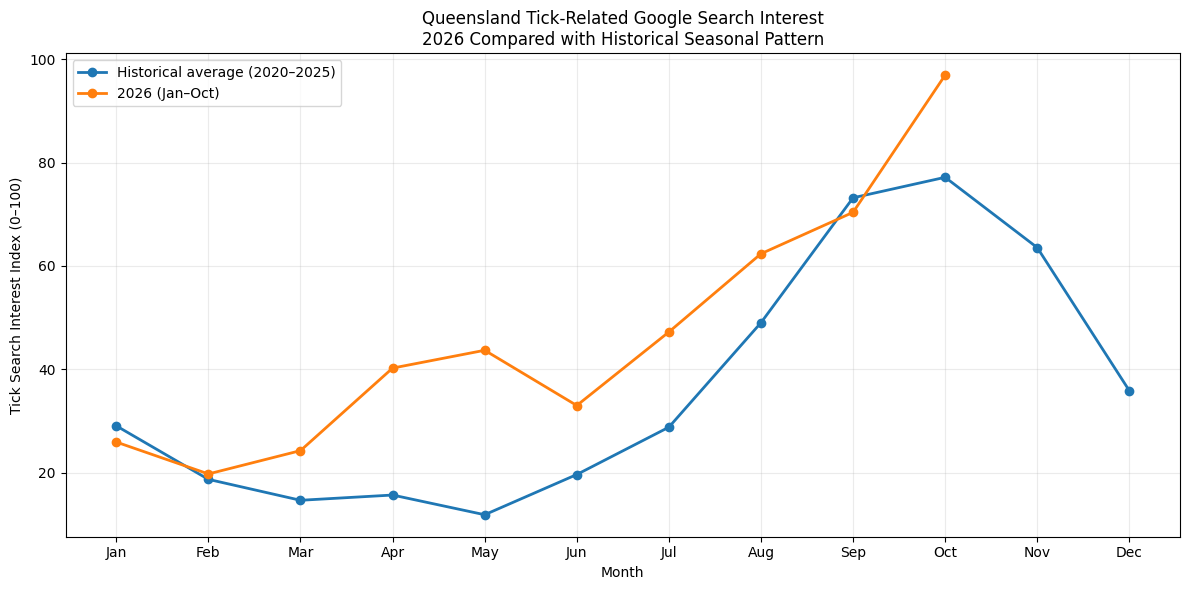

In [23]:
# =========================================================
# HISTORICAL SEASONAL AVERAGE vs 2026 SEARCH PATTERN
# =========================================================

# Historical baseline: complete years 2020–2025
historical = trends[
    trends["Year"].between(2020, 2025)
].copy()

seasonal_search = (
    historical
    .groupby(["Month_Num", "Month_Name"])
    .agg(
        Historical_Avg=("Tick_Search_Index", "mean")
    )
    .reset_index()
    .sort_values("Month_Num")
)

# 2026 actual values (Jan–Oct available)
search_2026_plot = (
    trends[trends["Year"] == 2026]
    [["Month_Num", "Month_Name", "Tick_Search_Index"]]
    .sort_values("Month_Num")
)

# ---------------------------------------------------------
# PLOT
# ---------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    seasonal_search["Month_Num"],
    seasonal_search["Historical_Avg"],
    marker="o",
    linewidth=2,
    label="Historical average (2020–2025)"
)

plt.plot(
    search_2026_plot["Month_Num"],
    search_2026_plot["Tick_Search_Index"],
    marker="o",
    linewidth=2,
    label="2026 (Jan–Oct)"
)

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.title(
    "Queensland Tick-Related Google Search Interest\n"
    "2026 Compared with Historical Seasonal Pattern"
)

plt.xlabel("Month")
plt.ylabel("Tick Search Interest Index (0–100)")

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [24]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(
    "/Users/sreelakshmi/Desktop/RMIT_final/project/Tick Analysis"
)

CONSULTATION_FILE = DATA_DIR / "Consultation.csv"

# Load Consultation.csv
consultations = pd.read_csv(
    CONSULTATION_FILE,
    low_memory=False
)

print("Shape:", consultations.shape)

print("\nColumns:")
for i, col in enumerate(consultations.columns, 1):
    print(f"{i}. {col}")

print("\nFirst 5 rows:")
display(consultations.head())

print("\nConsultation date range:")
consultations["ConsultationDate"] = pd.to_datetime(
    consultations["ConsultationDate"],
    errors="coerce"
)

print("Start:", consultations["ConsultationDate"].min())
print("End:", consultations["ConsultationDate"].max())

print("\nUnique clinics:")
print(consultations["ClinicID"].nunique())

print("\nUnique ConsultationKey:")
print(consultations["ConsultationKey"].nunique())

Shape: (1048575, 13)

Columns:
1. ConsultationKey
2. ClientKey
3. PatientKey
4. ClinicID
5. ConsultingVetUserID
6. ConsultationDate
7. ConsultationDateTime
8. ItemServiceFeeName
9. ItemServiceQty
10. TotalSalePriceAmt
11. TotalTaxAmt
12. ConsultationWeightDecimal
13. ConsultationTemperatureDecimal

First 5 rows:


,ConsultationKey,ClientKey,PatientKey,ClinicID,ConsultingVetUserID,ConsultationDate,ConsultationDateTime,ItemServiceFeeName,ItemServiceQty,TotalSalePriceAmt,TotalTaxAmt,ConsultationWeightDecimal,ConsultationTemperatureDecimal
0,A726C982F0D077B2DBDA21FA915EF54B4E6C503BC9BEC1...,8EF77BC3887680F6917A161EB3792678B7EBB0E4416661...,ADC1F5AB2D9E79C2639910D798B2D79711774839FEC019...,8,-1,1/10/2021,NaN,Standard Fee,1.0,69.0,6.2727,NaN,NaN
1,37BDEB8EE25F1103F14F312F351F32BE25CBB908F2E9F9...,8EF77BC3887680F6917A161EB3792678B7EBB0E4416661...,ADC1F5AB2D9E79C2639910D798B2D79711774839FEC019...,8,-1,1/10/2021,NaN,Standard Fee,1.0,23.9,2.1727,NaN,NaN
2,9914B7E657C41B48039E8F87F2453BAF4E0F6750190834...,8EF77BC3887680F6917A161EB3792678B7EBB0E4416661...,ADC1F5AB2D9E79C2639910D798B2D79711774839FEC019...,8,-1,1/10/2021,NaN,Standard Fee,1.0,14.8,1.3454,NaN,NaN
3,1F0BE8BD616A94C4F33374337396824196BEFDC2975192...,8EF77BC3887680F6917A161EB3792678B7EBB0E4416661...,ADC1F5AB2D9E79C2639910D798B2D79711774839FEC019...,8,-1,1/10/2021,NaN,Standard Fee,1.0,28.4,2.5818,NaN,NaN
4,08BDFDE5077878933F768190667CDD82D33D4B60C9C193...,451A620D7E78358820C75A198D9918FBBE0990F54889F0...,C1DAF900C859D66C039B3C8ACB12A65239EBC6A99D4051...,8,-1,1/10/2021,NaN,1st Animal,1.0,99.0,9.0000,NaN,NaN



Consultation date range:
Start: 2021-01-10 00:00:00
End: 2023-12-10 00:00:00

Unique clinics:
23

Unique ConsultationKey:
1048575


In [25]:
# =========================================================
# FIX CONSULTATION DATES + AUDIT TICK-RELATED SERVICES
# =========================================================

# Re-read the original date column correctly for Australian DD/MM/YYYY format
consultations["ConsultationDate"] = pd.to_datetime(
    consultations["ConsultationDate"].astype(str),
    dayfirst=True,
    errors="coerce"
)

print("Corrected consultation period:")
print("Start:", consultations["ConsultationDate"].min())
print("End:  ", consultations["ConsultationDate"].max())

print("\nMissing consultation dates:")
print(consultations["ConsultationDate"].isna().sum())


# ---------------------------------------------------------
# Find ItemServiceFeeName values containing "tick"
# ---------------------------------------------------------

tick_service_mask = (
    consultations["ItemServiceFeeName"]
    .fillna("")
    .astype(str)
    .str.contains(r"\btick\b", case=False, regex=True)
)

tick_service_rows = consultations.loc[
    tick_service_mask
].copy()

print("\nRows with 'tick' in ItemServiceFeeName:")
print(len(tick_service_rows))

print("\nUnique ConsultationKeys:")
print(tick_service_rows["ConsultationKey"].nunique())

print("\nClinics represented:")
print(tick_service_rows["ClinicID"].nunique())

print("\nTick-related ItemServiceFeeName values:")

tick_service_summary = (
    tick_service_rows
    .groupby("ItemServiceFeeName")
    .agg(
        Rows=("ConsultationKey", "size"),
        Unique_Consultations=("ConsultationKey", "nunique")
    )
    .reset_index()
    .sort_values("Unique_Consultations", ascending=False)
)

display(tick_service_summary)

Corrected consultation period:
Start: 2021-10-01 00:00:00
End:   2023-10-12 00:00:00

Missing consultation dates:
631916

Rows with 'tick' in ItemServiceFeeName:
111

Unique ConsultationKeys:
111

Clinics represented:
2

Tick-related ItemServiceFeeName values:


,ItemServiceFeeName,Rows,Unique_Consultations
3,TIck Clip - Cat (Outpatient),20,20
0,Sedation/Anaesthesia For Tick Clip (Cat),16,16
5,Tick Clip 0-9.9kg (Outpatient),16,16
2,TIck Clip - Cat (Inpatient),13,13
6,Tick Clip 10-29.9kg (Inpatient),13,13
1,Sedation/Anaesthesia for Tick Clip (Cat),11,11
4,Tick Clip 0-9.9kg (Inpatient),11,11
7,Tick Clip 10-29.9kg (Outpatient),5,5
8,Tick Clip 30kg + (Inpatient),2,2
10,Tick Clip Double Coat Surcharge,2,2


In [26]:
# =========================================================
# FIND EXISTING CONSULTATION PATTERN DATAFRAME
# =========================================================

keywords = [
    "tick",
    "weekly",
    "consult",
    "seq",
    "ridge",
    "model"
]

for name, obj in list(globals().items()):

    if isinstance(obj, pd.DataFrame):

        name_lower = name.lower()

        if any(k in name_lower for k in keywords):

            print("\n" + "=" * 70)
            print("DATAFRAME:", name)
            print("Shape:", obj.shape)
            print("Columns:")
            print(obj.columns.tolist())


DATAFRAME: consultations
Shape: (1048575, 13)
Columns:
['ConsultationKey', 'ClientKey', 'PatientKey', 'ClinicID', 'ConsultingVetUserID', 'ConsultationDate', 'ConsultationDateTime', 'ItemServiceFeeName', 'ItemServiceQty', 'TotalSalePriceAmt', 'TotalTaxAmt', 'ConsultationWeightDecimal', 'ConsultationTemperatureDecimal']

DATAFRAME: tick_service_rows
Shape: (111, 13)
Columns:
['ConsultationKey', 'ClientKey', 'PatientKey', 'ClinicID', 'ConsultingVetUserID', 'ConsultationDate', 'ConsultationDateTime', 'ItemServiceFeeName', 'ItemServiceQty', 'TotalSalePriceAmt', 'TotalTaxAmt', 'ConsultationWeightDecimal', 'ConsultationTemperatureDecimal']

DATAFRAME: tick_service_summary
Shape: (12, 3)
Columns:
['ItemServiceFeeName', 'Rows', 'Unique_Consultations']


In [27]:
# =========================================================
# RELOAD CONSULTATION.CSV WITH CORRECT AUSTRALIAN DATES
# =========================================================

from pathlib import Path
import pandas as pd

CONSULTATION_FILE = Path(
    "/Users/sreelakshmi/Desktop/RMIT_final/project/Tick Analysis/Consultation.csv"
)

consultations = pd.read_csv(
    CONSULTATION_FILE,
    low_memory=False
)

# Parse directly from the ORIGINAL strings as DD/MM/YYYY
consultations["ConsultationDate"] = pd.to_datetime(
    consultations["ConsultationDate"],
    format="%d/%m/%Y",
    errors="coerce"
)

print("Rows:", len(consultations))
print("Valid dates:", consultations["ConsultationDate"].notna().sum())
print("Missing dates:", consultations["ConsultationDate"].isna().sum())

print("\nDate range:")
print("Start:", consultations["ConsultationDate"].min())
print("End:  ", consultations["ConsultationDate"].max())

print("\nClinics:", consultations["ClinicID"].nunique())
print("Unique consultations:", consultations["ConsultationKey"].nunique())

Rows: 1048575
Valid dates: 1048575
Missing dates: 0

Date range:
Start: 2021-10-01 00:00:00
End:   2023-10-31 00:00:00

Clinics: 23
Unique consultations: 1048575


In [28]:
from pathlib import Path
import pandas as pd

FREE_TEXT_FILE = Path(
    "/Users/sreelakshmi/Desktop/RMIT_final/project/cleaned/consultations_freetext.csv"
)

# Read only a few rows to inspect columns
sample = pd.read_csv(
    FREE_TEXT_FILE,
    nrows=5,
    low_memory=False
)

print("Columns:")
for i, col in enumerate(sample.columns, 1):
    print(f"{i}. {col}")

display(sample.head())

Columns:
1. ConsultationKey
2. ClinicPseudonym
3. ConsultationDate
4. ExaminationTextString
5. SummaryString
6. SpecialInstructionString
7. PossibleNameMatch_ClientFirstName
8. PossibleNameMatch_ClientLastName
9. PossibleNameMatch_PatientName


,ConsultationKey,ClinicPseudonym,ConsultationDate,ExaminationTextString,SummaryString,SpecialInstructionString,PossibleNameMatch_ClientFirstName,PossibleNameMatch_ClientLastName,PossibleNameMatch_PatientName
0,9A763DD0D42112D82E510D667E5F4A5F1E6FA1A3F2B42C...,Clinic_01,2023-07-27,Reason: Admit For BGC Fed 1 cup dry food at 6...,NaN,NaN,0,0,0
1,854150406CECBEE128992D93EF0FB60DBE7407E6A98AE1...,Clinic_01,2023-07-27,Reason: Admit For BGC Fed 1 cup dry food at 6...,NaN,NaN,0,0,0
2,AF349A69219EA3A30DC4785DF88BB03F8B8B9607C05C8F...,Clinic_01,2023-07-27,Reason: Admit For BGC Fed 1 cup dry food at 6...,NaN,NaN,0,0,0
3,046230348560935F217B0BAE398CEFCEA7DB38EA0A8B84...,Clinic_01,2023-07-27,Reason: Castrate PABT: all WNL No audible hea...,NaN,NaN,0,0,0
4,01D67E1A0AF6ABC7889D7610D984B2179C49EFC6A56161...,Clinic_01,2023-07-27,Reason: Castrate PABT: all WNL No audible hea...,NaN,NaN,0,0,0


In [29]:
# =========================================================
# CHECK DATE RANGE — consultations_freetext.csv
# Memory-safe for the 4.31 GB file
# =========================================================

import pandas as pd
from pathlib import Path

FREE_TEXT_FILE = Path(
    "/Users/sreelakshmi/Desktop/RMIT_final/project/cleaned/consultations_freetext.csv"
)

min_date = None
max_date = None
total_rows = 0
valid_dates = 0
missing_dates = 0

for chunk in pd.read_csv(
    FREE_TEXT_FILE,
    usecols=["ConsultationDate"],
    chunksize=500_000,
    low_memory=False
):
    
    dates = pd.to_datetime(
        chunk["ConsultationDate"],
        errors="coerce"
    )
    
    total_rows += len(chunk)
    valid_dates += dates.notna().sum()
    missing_dates += dates.isna().sum()
    
    chunk_min = dates.min()
    chunk_max = dates.max()
    
    if pd.notna(chunk_min):
        min_date = chunk_min if min_date is None else min(min_date, chunk_min)
        
    if pd.notna(chunk_max):
        max_date = chunk_max if max_date is None else max(max_date, chunk_max)


print("=" * 55)
print("CONSULTATIONS FREETEXT — DATE AUDIT")
print("=" * 55)

print(f"Total rows:    {total_rows:,}")
print(f"Valid dates:   {valid_dates:,}")
print(f"Missing dates: {missing_dates:,}")

print("\nDate range:")
print("Start:", min_date)
print("End:  ", max_date)

if min_date is not None and max_date is not None:
    print(
        "\nApproximate coverage:",
        round((max_date - min_date).days / 365.25, 2),
        "years"
    )

CONSULTATIONS FREETEXT — DATE AUDIT
Total rows:    6,748,676
Valid dates:   6,748,676
Missing dates: 0

Date range:
Start: 2023-07-27 00:00:00
End:   2026-08-26 00:00:00

Approximate coverage: 3.08 years


In [30]:
from pathlib import Path
import pandas as pd

TICK_FILE = Path(
    "/Users/sreelakshmi/Desktop/RMIT_final/project/Tick Data.csv"
)

print("File exists:", TICK_FILE.exists())

if TICK_FILE.exists():
    print(
        "File size:",
        round(TICK_FILE.stat().st_size / (1024**3), 2),
        "GB"
    )

    sample = pd.read_csv(
        TICK_FILE,
        nrows=5,
        low_memory=False
    )

    print("\nColumns:")
    for i, col in enumerate(sample.columns, 1):
        print(f"{i}. {col}")

    print("\nFirst 5 rows:")
    display(sample)

File exists: True
File size: 0.0 GB

Columns:
1. Tick_Category
2. StateCode
3. ClinicID
4. ConsultationNoCode
5. ConsultDate
6. Year
7. Month
8. PatientID
9. ClientID
10. Tick_Items
11. Items
12. Prevention_Sold
13. Patient_Tick_Visits
14. Repeat_Patient

First 5 rows:


,Tick_Category,StateCode,ClinicID,ConsultationNoCode,ConsultDate,Year,Month,PatientID,ClientID,Tick_Items,Items,Prevention_Sold,Patient_Tick_Visits,Repeat_Patient
0,1 - Treated (tick treatment billed),QLD,154,582003,3/01/2020,2020,1,2172015,1433451,Tick Anti Serum Inj - North Coast,Bravecto Spot On Blue 20-40kg | Fluids I.V | M...,1,1,0
1,2 - Tick clip/removal,QLD,22,1003552,3/01/2020,2020,1,359870,281225,Tick Clip 0-9.9kg (Inpatient),Tick Clip 0-9.9kg (Inpatient) | Nexgard Dog Ch...,1,2,1
2,1 - Treated (tick treatment billed),QLD,154,582358,7/01/2020,2020,1,2174421,1429902,Tick Anti Serum Inj - North Coast | Discharge ...,Hospital - Large Dog | Xray Plate - All Sizes ...,1,1,0
3,1 - Treated (tick treatment billed),QLD,154,582421,8/01/2020,2020,1,2174682,1436692,Discharge Instructions - Tick | Tick Anti Ser...,Bravecto Plus 2 PK Cat Spot On Blue 2.8-6.25kg...,1,1,0
4,1 - Treated (tick treatment billed),QLD,154,583131,15/01/2020,2020,1,2175999,1437674,Tick Anti Serum Inj - North Coast,Bravecto Spot On Orange 4.5-10kg | Oxygen Ther...,1,1,0


In [31]:
# =========================================================
# TICK DATA — COVERAGE AUDIT
# =========================================================

import pandas as pd

tick_data = pd.read_csv(
    TICK_FILE,
    low_memory=False
)

# Australian date format
tick_data["ConsultDate"] = pd.to_datetime(
    tick_data["ConsultDate"],
    dayfirst=True,
    errors="coerce"
)

print("=" * 55)
print("TICK DATA COVERAGE")
print("=" * 55)

print(f"Rows: {len(tick_data):,}")
print(f"Valid dates: {tick_data['ConsultDate'].notna().sum():,}")
print(f"Missing dates: {tick_data['ConsultDate'].isna().sum():,}")

print("\nDate range:")
print("Start:", tick_data["ConsultDate"].min())
print("End:  ", tick_data["ConsultDate"].max())

print("\nYears available:")
print(sorted(tick_data["ConsultDate"].dropna().dt.year.unique()))

print("\nNumber of clinics:")
print(tick_data["ClinicID"].nunique())

print("\nStates:")
print(tick_data["StateCode"].value_counts(dropna=False))

print("\nTick categories:")
display(
    tick_data["Tick_Category"]
    .value_counts(dropna=False)
    .rename_axis("Tick_Category")
    .reset_index(name="Consultations")
)

TICK DATA COVERAGE
Rows: 1,672
Valid dates: 1,672
Missing dates: 0

Date range:
Start: 2020-01-03 00:00:00
End:   2026-09-24 00:00:00

Years available:
[np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]

Number of clinics:
29

States:
StateCode
QLD    1672
Name: count, dtype: int64

Tick categories:


,Tick_Category,Consultations
0,1 - Treated (tick treatment billed),1529
1,2 - Tick clip/removal,143


In [32]:
# =========================================================
# TICK DATA — COVERAGE AUDIT
# =========================================================

import pandas as pd

tick_data = pd.read_csv(
    TICK_FILE,
    low_memory=False
)

# Australian date format
tick_data["ConsultDate"] = pd.to_datetime(
    tick_data["ConsultDate"],
    dayfirst=True,
    errors="coerce"
)

print("=" * 55)
print("TICK DATA COVERAGE")
print("=" * 55)

print(f"Rows: {len(tick_data):,}")
print(f"Valid dates: {tick_data['ConsultDate'].notna().sum():,}")
print(f"Missing dates: {tick_data['ConsultDate'].isna().sum():,}")

print("\nDate range:")
print("Start:", tick_data["ConsultDate"].min())
print("End:  ", tick_data["ConsultDate"].max())

print("\nYears available:")
print(sorted(tick_data["ConsultDate"].dropna().dt.year.unique()))

print("\nNumber of clinics:")
print(tick_data["ClinicID"].nunique())

print("\nStates:")
print(tick_data["StateCode"].value_counts(dropna=False))

print("\nTick categories:")
display(
    tick_data["Tick_Category"]
    .value_counts(dropna=False)
    .rename_axis("Tick_Category")
    .reset_index(name="Consultations")
)

TICK DATA COVERAGE
Rows: 1,672
Valid dates: 1,672
Missing dates: 0

Date range:
Start: 2020-01-03 00:00:00
End:   2026-09-24 00:00:00

Years available:
[np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]

Number of clinics:
29

States:
StateCode
QLD    1672
Name: count, dtype: int64

Tick categories:


,Tick_Category,Consultations
0,1 - Treated (tick treatment billed),1529
1,2 - Tick clip/removal,143


In [33]:
# =========================================================
# CHECK FREETEXT DATE RANGE
# =========================================================

from pathlib import Path
import pandas as pd

FREETEXT_FILE = Path(
    "/Users/sreelakshmi/Desktop/RMIT_final/project/cleaned/consultations_freetext.csv"
)

min_date = None
max_date = None
total_rows = 0

for chunk in pd.read_csv(
    FREETEXT_FILE,
    usecols=["ConsultationDate"],
    chunksize=500_000,
    low_memory=False
):

    dates = pd.to_datetime(
        chunk["ConsultationDate"],
        errors="coerce"
    )

    total_rows += len(chunk)

    cmin = dates.min()
    cmax = dates.max()

    if pd.notna(cmin):
        min_date = cmin if min_date is None else min(min_date, cmin)

    if pd.notna(cmax):
        max_date = cmax if max_date is None else max(max_date, cmax)

print(f"Rows: {total_rows:,}")
print("Start:", min_date)
print("End:  ", max_date)

if min_date is not None and max_date is not None:
    print(
        "Coverage:",
        round((max_date - min_date).days / 365.25, 2),
        "years"
    )

Rows: 6,748,676
Start: 2023-07-27 00:00:00
End:   2026-08-26 00:00:00
Coverage: 3.08 years


In [34]:
# =========================================================
# CHECK ConsultationKey OVERLAP
# Consultation.csv vs consultations_freetext.csv
# =========================================================

from pathlib import Path
import pandas as pd

CONSULTATION_FILE = Path(
    "/Users/sreelakshmi/Desktop/RMIT_final/project/Tick Analysis/Consultation.csv"
)

FREETEXT_FILE = Path(
    "/Users/sreelakshmi/Desktop/RMIT_final/project/cleaned/consultations_freetext.csv"
)

# Get keys from Consultation.csv
consult_keys = set(
    pd.read_csv(
        CONSULTATION_FILE,
        usecols=["ConsultationKey"],
        low_memory=False
    )["ConsultationKey"]
    .dropna()
    .astype(str)
)

print(f"Consultation.csv unique keys: {len(consult_keys):,}")

# Scan free-text file
freetext_rows = 0
matched_rows = 0
freetext_unique_keys = set()
matched_keys = set()

for chunk in pd.read_csv(
    FREETEXT_FILE,
    usecols=["ConsultationKey"],
    chunksize=500_000,
    low_memory=False
):
    keys = chunk["ConsultationKey"].dropna().astype(str)

    freetext_rows += len(chunk)
    freetext_unique_keys.update(keys)

    matches = keys[keys.isin(consult_keys)]
    matched_rows += len(matches)
    matched_keys.update(matches)

print("\n" + "=" * 55)
print("KEY OVERLAP")
print("=" * 55)

print(f"Free-text rows:              {freetext_rows:,}")
print(f"Free-text unique keys:       {len(freetext_unique_keys):,}")
print(f"Matched rows:                {matched_rows:,}")
print(f"Matched unique keys:         {len(matched_keys):,}")

print(
    f"\n% Consultation.csv keys matched: "
    f"{len(matched_keys) / len(consult_keys) * 100:.2f}%"
)

print(
    f"% Free-text unique keys matched: "
    f"{len(matched_keys) / len(freetext_unique_keys) * 100:.2f}%"
)

Consultation.csv unique keys: 1,048,575

KEY OVERLAP
Free-text rows:              6,748,676
Free-text unique keys:       6,139,791
Matched rows:                155,355
Matched unique keys:         152,256

% Consultation.csv keys matched: 14.52%
% Free-text unique keys matched: 2.48%


In [35]:
# =========================================================
# GOOGLE TRENDS vs TICK CONSULTATION ANALYSIS
# STEP 1 — LOAD COMBINED ~5-YEAR DATA
# =========================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

PROJECT_DIR = Path(
    "/Users/sreelakshmi/Desktop/RMIT_final/project"
)

COMBINED_FILE = (
    PROJECT_DIR / "consultations_5year_combined.csv"
)

print("File exists:", COMBINED_FILE.exists())

# We need these fields for the analysis
usecols = [
    "ConsultationKey",
    "ClinicID",
    "ClinicPseudonym",
    "ConsultationDate",
    "ItemServiceFeeName",
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString",
    "DataSource"
]

consult = pd.read_csv(
    COMBINED_FILE,
    usecols=usecols,
    low_memory=False
)

consult["ConsultationDate"] = pd.to_datetime(
    consult["ConsultationDate"],
    errors="coerce"
)

print("\nRows:", f"{len(consult):,}")
print(
    "Date range:",
    consult["ConsultationDate"].min(),
    "to",
    consult["ConsultationDate"].max()
)
print(
    "Unique consultations:",
    f"{consult['ConsultationKey'].nunique():,}"
)

print("\nRows by source:")
print(consult["DataSource"].value_counts())

File exists: True

Rows: 7,641,896
Date range: 2021-10-01 00:00:00 to 2026-08-26 00:00:00
Unique consultations: 7,036,110

Rows by source:
DataSource
consultations_freetext.csv    6593321
Consultation.csv              1048575
Name: count, dtype: int64


In [36]:
print(consult.columns.tolist())

['ConsultationKey', 'ClinicID', 'ClinicPseudonym', 'ConsultationDate', 'ItemServiceFeeName', 'ExaminationTextString', 'SummaryString', 'SpecialInstructionString', 'DataSource']


In [37]:
# ============================================================
# MONTHLY TICK CONSULTATION SERIES
# FREETEXT SOURCE ONLY
# ============================================================

import pandas as pd

# Make sure date is datetime
consult["ConsultationDate"] = pd.to_datetime(
    consult["ConsultationDate"],
    errors="coerce"
)

# ------------------------------------------------------------
# 1. Keep only freetext source FIRST
# ------------------------------------------------------------

analysis_data = consult.loc[
    consult["DataSource"].eq("consultations_freetext.csv"),
    [
        "ConsultationKey",
        "ConsultationDate",
        "ItemServiceFeeName",
        "ExaminationTextString",
        "SummaryString",
        "SpecialInstructionString"
    ]
].copy()

print("Freetext rows:", len(analysis_data))

# ------------------------------------------------------------
# 2. Create Tick_Related only for these rows
# ------------------------------------------------------------

tick_pattern = (
    r"paralysis tick|tick paralysis|tick bite|tick bites|"
    r"tick attached|attached tick|tick removal|remove tick|"
    r"removed tick|tick clip|tick search|tick toxicosis|"
    r"tick toxicity|tick infestation|ticks attached"
)

text_cols = [
    "ItemServiceFeeName",
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString"
]

analysis_data["Tick_Related"] = False

for col in text_cols:
    analysis_data["Tick_Related"] |= (
        analysis_data[col]
        .fillna("")
        .str.contains(
            tick_pattern,
            case=False,
            regex=True
        )
    )

print(
    "Tick-related rows:",
    analysis_data["Tick_Related"].sum()
)

# ------------------------------------------------------------
# 3. Create Month
# ------------------------------------------------------------

analysis_data["Month"] = (
    analysis_data["ConsultationDate"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# ------------------------------------------------------------
# 4. Total UNIQUE consultations per month
# ------------------------------------------------------------

monthly_total = (
    analysis_data
    .groupby("Month")["ConsultationKey"]
    .nunique()
    .reset_index(name="Total_Consultations")
)

# ------------------------------------------------------------
# 5. Tick-related UNIQUE consultations per month
# ------------------------------------------------------------

monthly_tick = (
    analysis_data.loc[analysis_data["Tick_Related"]]
    .groupby("Month")["ConsultationKey"]
    .nunique()
    .reset_index(name="Tick_Consultations")
)

# ------------------------------------------------------------
# 6. Merge
# ------------------------------------------------------------

monthly_consult = monthly_total.merge(
    monthly_tick,
    on="Month",
    how="left"
)

monthly_consult["Tick_Consultations"] = (
    monthly_consult["Tick_Consultations"]
    .fillna(0)
    .astype(int)
)

# ------------------------------------------------------------
# 7. Rate per 1,000
# ------------------------------------------------------------

monthly_consult["Tick_per_1000"] = (
    monthly_consult["Tick_Consultations"]
    / monthly_consult["Total_Consultations"]
    * 1000
)

print("\nAnalysis period:",
      monthly_consult["Month"].min(),
      "to",
      monthly_consult["Month"].max())

print("Number of months:", len(monthly_consult))

display(monthly_consult)

Freetext rows: 6593321
Tick-related rows: 28424

Analysis period: 2023-07-01 00:00:00 to 2026-08-01 00:00:00
Number of months: 38


,Month,Total_Consultations,Tick_Consultations,Tick_per_1000
0,2023-07-01,16056,44,2.740409
1,2023-08-01,114824,360,3.135233
2,2023-09-01,109180,923,8.453929
3,2023-10-01,117283,726,6.190155
4,2023-11-01,161045,1201,7.457543
5,2023-12-01,146492,962,6.566912
6,2024-01-01,167261,499,2.983361
7,2024-02-01,162191,359,2.213440
8,2024-03-01,152675,268,1.755363
9,2024-04-01,158510,229,1.444704


In [38]:
# =========================================================
# GOOGLE TRENDS vs CONSULTATION DEMAND
# COMPLETE COMPARABLE MONTHS ONLY
# Aug 2023 - Jul 2026
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Make sure Month is datetime in both datasets
# ---------------------------------------------------------

monthly_consult["Month"] = pd.to_datetime(
    monthly_consult["Month"]
).dt.to_period("M").dt.to_timestamp()

trends["Month"] = pd.to_datetime(
    trends["Month"]
).dt.to_period("M").dt.to_timestamp()


# ---------------------------------------------------------
# 2. Keep complete consultation months
# ---------------------------------------------------------

consult_complete = monthly_consult[
    (monthly_consult["Month"] >= "2023-08-01") &
    (monthly_consult["Month"] <= "2026-07-01")
].copy()


# ---------------------------------------------------------
# 3. Merge with existing Google Trends index
# ---------------------------------------------------------

comparison = (
    consult_complete[
        [
            "Month",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_per_1000"
        ]
    ]
    .merge(
        trends[
            [
                "Month",
                "Tick_Search_Index"
            ]
        ],
        on="Month",
        how="inner"
    )
    .sort_values("Month")
    .reset_index(drop=True)
)


print("=" * 65)
print("GOOGLE TRENDS vs TICK CONSULTATION DATA")
print("=" * 65)

print(
    "Period:",
    comparison["Month"].min().date(),
    "to",
    comparison["Month"].max().date()
)

print("Months:", len(comparison))

print("\nLast 15 months:")
display(comparison.tail(15).round(2))

GOOGLE TRENDS vs TICK CONSULTATION DATA
Period: 2023-08-01 to 2026-07-01
Months: 36

Last 15 months:


,Month,Total_Consultations,Tick_Consultations,Tick_per_1000,Tick_Search_Index
21,2025-05-01,173908,435,2.50,17.70
22,2025-06-01,161613,499,3.09,32.07
23,2025-07-01,183122,716,3.91,48.08
24,2025-08-01,174077,1696,9.74,57.62
25,2025-09-01,184417,2430,13.18,91.52
26,2025-10-01,178849,1824,10.20,84.63
27,2025-11-01,167133,1669,9.99,57.21
28,2025-12-01,201078,882,4.39,41.09
29,2026-01-01,337836,758,2.24,25.91
30,2026-02-01,314087,433,1.38,19.74


In [39]:
# =========================================================
# GOOGLE SEARCH vs CONSULTATION LEAD-LAG ANALYSIS
# =========================================================

lag_results = []

for lag in range(-2, 3):

    temp = pd.DataFrame({
        "Google_Search": comparison["Tick_Search_Index"],
        "Consultation": comparison["Tick_per_1000"].shift(-lag)
    }).dropna()

    lag_results.append({
        "Lag_Months": lag,
        "Pearson": temp["Google_Search"].corr(
            temp["Consultation"],
            method="pearson"
        ),
        "Spearman": temp["Google_Search"].corr(
            temp["Consultation"],
            method="spearman"
        ),
        "N": len(temp)
    })


lag_results = pd.DataFrame(lag_results)

lag_results["Meaning"] = lag_results["Lag_Months"].map({
    -2: "Consultations lead Google by 2 months",
    -1: "Consultations lead Google by 1 month",
     0: "Same month",
     1: "Google leads consultations by 1 month",
     2: "Google leads consultations by 2 months"
})

display(lag_results.round(3))

,Lag_Months,Pearson,Spearman,N,Meaning
0,-2,0.297,0.332,34,Consultations lead Google by 2 months
1,-1,0.684,0.699,35,Consultations lead Google by 1 month
2,0,0.834,0.823,36,Same month
3,1,0.698,0.722,35,Google leads consultations by 1 month
4,2,0.382,0.466,34,Google leads consultations by 2 months


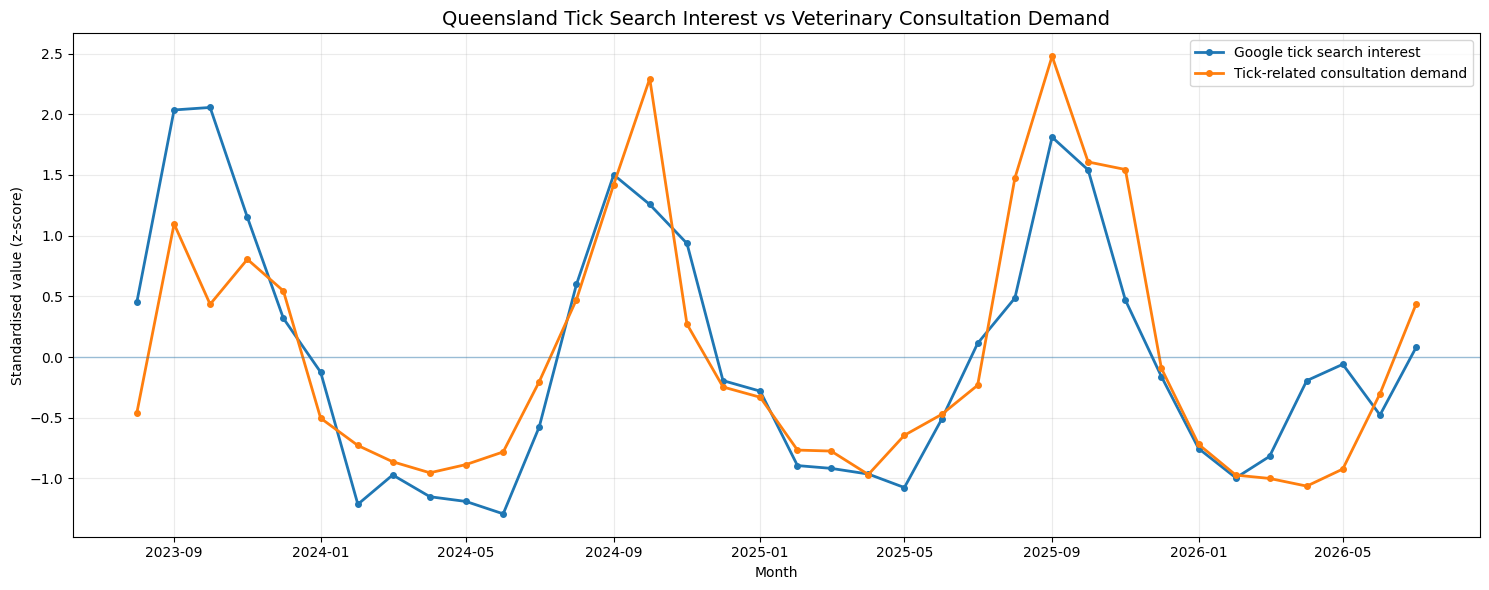

In [40]:
# =========================================================
# VISUAL 1
# GOOGLE SEARCH INTEREST vs TICK CONSULTATION DEMAND
# =========================================================

import matplotlib.pyplot as plt

# Standardise both variables
comparison["Google_Z"] = (
    comparison["Tick_Search_Index"]
    - comparison["Tick_Search_Index"].mean()
) / comparison["Tick_Search_Index"].std()

comparison["Consultation_Z"] = (
    comparison["Tick_per_1000"]
    - comparison["Tick_per_1000"].mean()
) / comparison["Tick_per_1000"].std()


plt.figure(figsize=(15, 6))

plt.plot(
    comparison["Month"],
    comparison["Google_Z"],
    marker="o",
    markersize=4,
    linewidth=2,
    label="Google tick search interest"
)

plt.plot(
    comparison["Month"],
    comparison["Consultation_Z"],
    marker="o",
    markersize=4,
    linewidth=2,
    label="Tick-related consultation demand"
)

plt.axhline(0, linewidth=1, alpha=0.4)

plt.title(
    "Queensland Tick Search Interest vs Veterinary Consultation Demand",
    fontsize=14
)

plt.xlabel("Month")
plt.ylabel("Standardised value (z-score)")

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

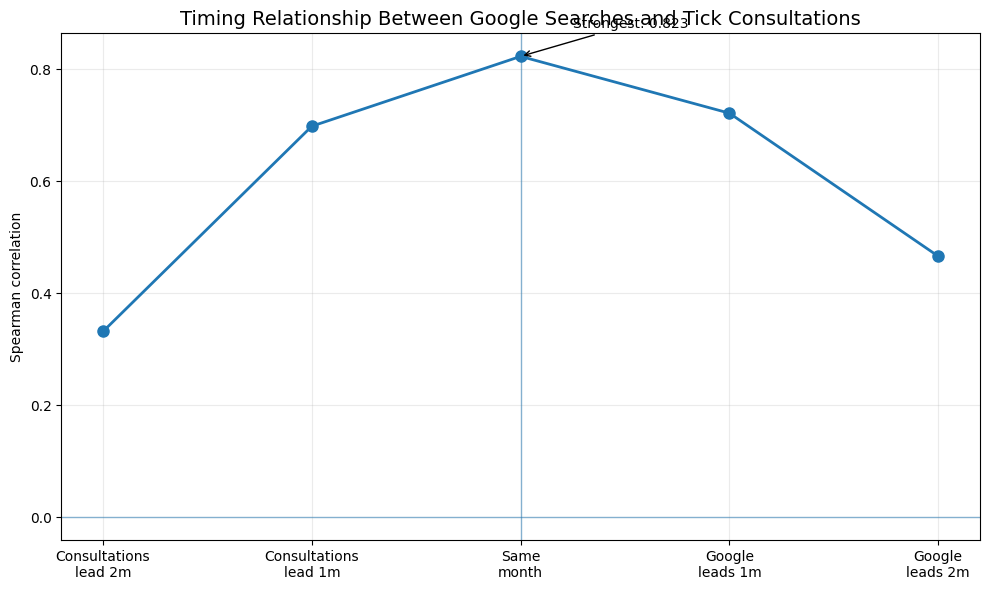

In [41]:
# =========================================================
# VISUAL 2
# GOOGLE TRENDS LEAD-LAG CORRELATION
# =========================================================

plt.figure(figsize=(10, 6))

plt.plot(
    lag_results["Lag_Months"],
    lag_results["Spearman"],
    marker="o",
    markersize=8,
    linewidth=2
)

plt.axvline(0, linewidth=1, alpha=0.5)
plt.axhline(0, linewidth=1, alpha=0.5)

plt.xticks(
    [-2, -1, 0, 1, 2],
    [
        "Consultations\nlead 2m",
        "Consultations\nlead 1m",
        "Same\nmonth",
        "Google\nleads 1m",
        "Google\nleads 2m"
    ]
)

plt.ylabel("Spearman correlation")

plt.title(
    "Timing Relationship Between Google Searches and Tick Consultations",
    fontsize=14
)

plt.grid(alpha=0.25)

# Mark strongest correlation
best_idx = lag_results["Spearman"].idxmax()

best_x = lag_results.loc[best_idx, "Lag_Months"]
best_y = lag_results.loc[best_idx, "Spearman"]

plt.annotate(
    f"Strongest: {best_y:.3f}",
    xy=(best_x, best_y),
    xytext=(best_x + 0.25, best_y + 0.05),
    arrowprops=dict(arrowstyle="->")
)

plt.tight_layout()
plt.show()

GOOGLE TRENDS vs TICK-RELATED VETERINARY CONSULTATION DEMAND

Comparison period: August 2023 to July 2026
Complete comparable months: 36

1. HISTORICAL GOOGLE SEARCH SEASONALITY (2020-2025)


,Month,Mean_Search_Index,Median_Search_Index
0,Jan,29.05,29.23
1,Feb,18.70,18.65
2,Mar,14.65,18.54
3,Apr,15.66,15.00
4,May,11.85,14.20
5,Jun,19.63,19.76
6,Jul,28.79,30.19
7,Aug,49.00,52.05
8,Sep,73.17,77.44
9,Oct,77.14,80.99



2. VETERINARY CONSULTATION SEASONALITY


,Month,Mean_Tick_per_1000,Median_Tick_per_1000
0,Jan,2.93,2.98
1,Feb,1.89,2.08
2,Mar,1.70,1.76
3,Apr,1.30,1.40
4,May,1.91,1.68
5,Jun,2.93,3.09
6,Jul,4.70,4.01
7,Aug,6.40,6.32
8,Sep,10.40,9.56
9,Oct,9.64,10.20



3. RAW LEAD-LAG RELATIONSHIP


,Lag_Months,Pearson,Spearman,N,Meaning
0,-2,0.297,0.332,34,Consultations lead Google by 2 months
1,-1,0.684,0.699,35,Consultations lead Google by 1 month
2,0,0.834,0.823,36,Same month
3,1,0.698,0.722,35,Google leads consultations by 1 month
4,2,0.382,0.466,34,Google leads consultations by 2 months



4. SEASONALITY-ADJUSTED LEAD-LAG RELATIONSHIP


,Lag_Months,Pearson_Adjusted,Spearman_Adjusted,N,Meaning
0,-2,-0.502,-0.581,34,Consultations lead Google by 2 months
1,-1,-0.123,-0.111,35,Consultations lead Google by 1 month
2,0,-0.138,-0.014,36,Same month
3,1,0.122,0.195,35,Google leads consultations by 1 month
4,2,0.526,0.660,34,Google leads consultations by 2 months


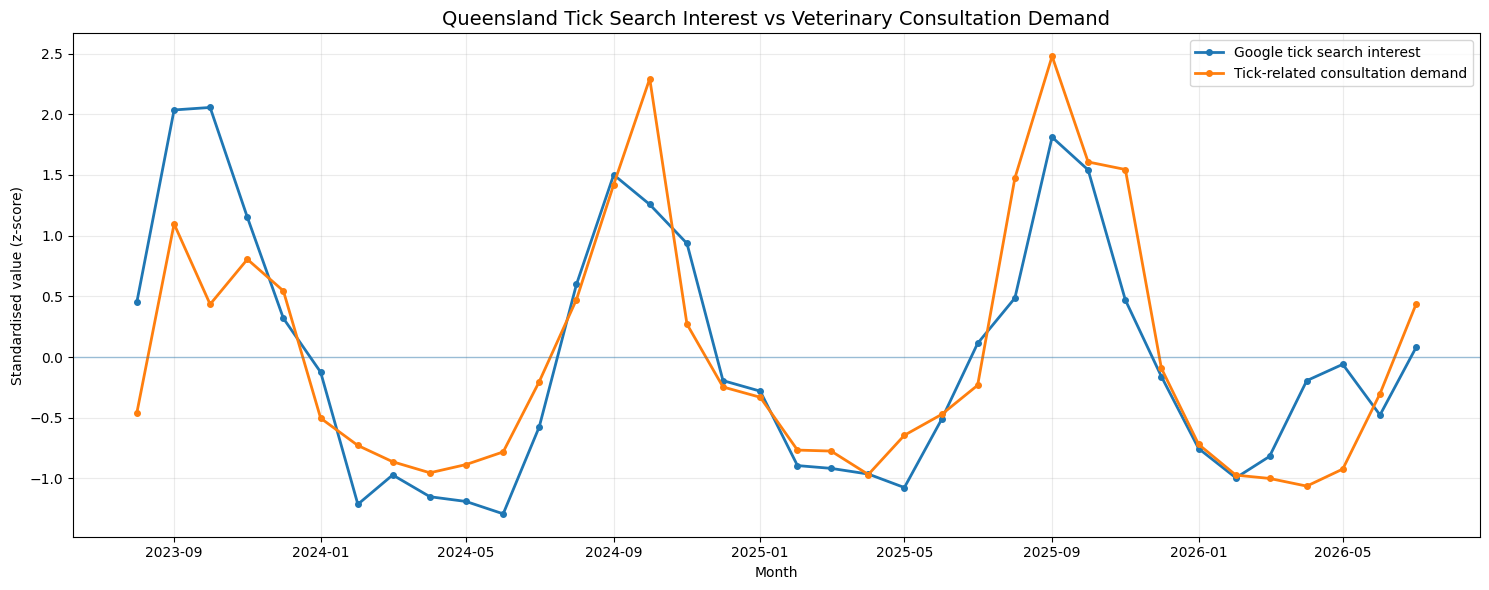

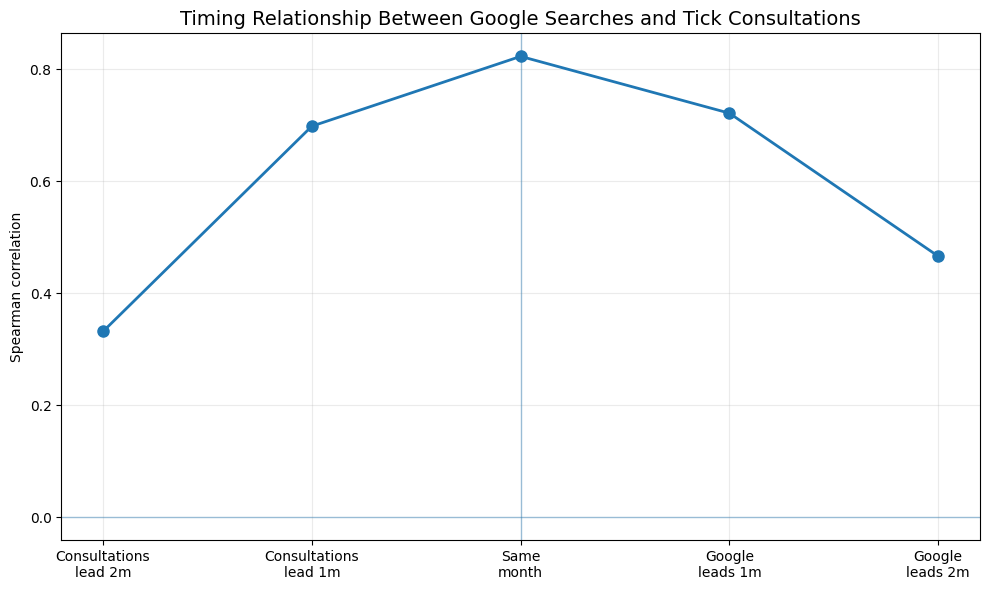

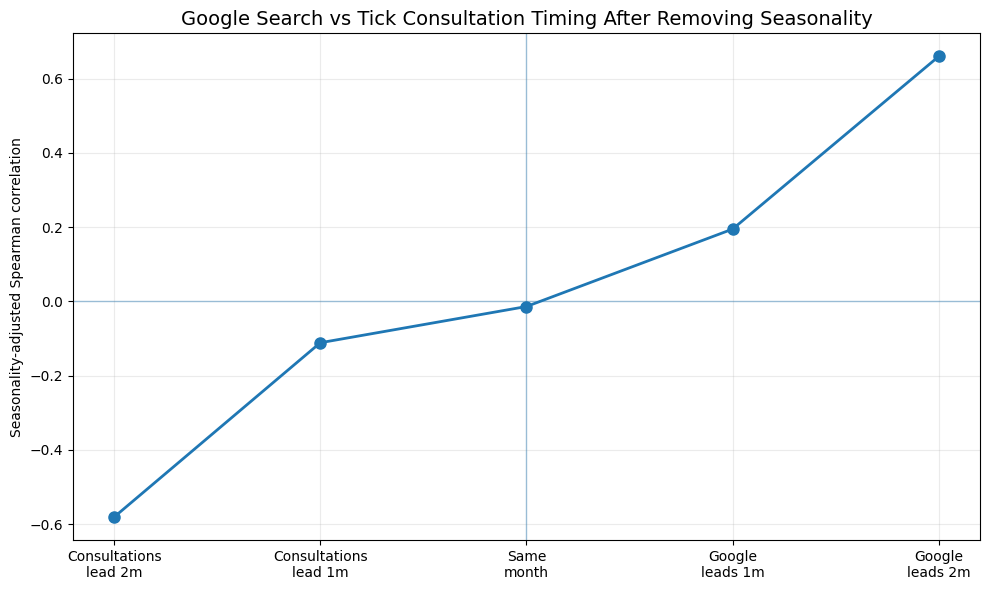


FINAL INTERPRETATION

Historical Google Trends data (2020-2025) show that
Queensland tick-related search activity follows a clear
seasonal pattern. Search interest generally begins increasing
during winter and early spring, becomes strongly elevated
during August-September, and reaches its highest average level
around Oct.

Veterinary tick-related consultation demand shows a similar
seasonal pattern, with increased demand during the same broad
spring tick season. The highest average consultation rate in
the comparable 2023-2026 period occurred around
Sep.

The raw lead-lag analysis found that the strongest relationship
was:

    Same month
    Spearman rho = 0.823

The seasonality-adjusted analysis found that the strongest
remaining relationship was:

    Google leads consultations by 2 months
    Adjusted Spearman rho = 0.660

DIRECT ANSWER TO SUPERVISOR

Based on the raw monthly comparison, Google tick-related
searches rise primarily ALONGSIDE veterinary consultation
demand.

The st

In [42]:
# ============================================================
# FINAL GOOGLE TRENDS vs TICK CONSULTATION ANALYSIS
#
# Research question:
# When do tick-related Google searches increase in Queensland,
# and do searches rise before, alongside, or after veterinary
# tick-related consultation demand?
#
# Required existing DataFrames:
#   trends
#       Month
#       Tick_Search_Index
#
#   monthly_consult
#       Month
#       Total_Consultations
#       Tick_Consultations
#       Tick_per_1000
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. PREPARE DATA
# ============================================================

trends = trends.copy()
monthly_consult = monthly_consult.copy()

trends["Month"] = (
    pd.to_datetime(trends["Month"])
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_consult["Month"] = (
    pd.to_datetime(monthly_consult["Month"])
    .dt.to_period("M")
    .dt.to_timestamp()
)


# Use only complete comparable consultation months.
# July 2023 is partial.
# August 2026 is incomplete/unusable in consultation data.

consult_complete = monthly_consult[
    (monthly_consult["Month"] >= "2023-08-01") &
    (monthly_consult["Month"] <= "2026-07-01")
].copy()


comparison = (
    consult_complete[
        [
            "Month",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_per_1000"
        ]
    ]
    .merge(
        trends[
            [
                "Month",
                "Tick_Search_Index"
            ]
        ],
        on="Month",
        how="inner"
    )
    .sort_values("Month")
    .reset_index(drop=True)
)


print("=" * 75)
print("GOOGLE TRENDS vs TICK-RELATED VETERINARY CONSULTATION DEMAND")
print("=" * 75)

print(
    f"\nComparison period: "
    f"{comparison['Month'].min().strftime('%B %Y')} to "
    f"{comparison['Month'].max().strftime('%B %Y')}"
)

print(f"Complete comparable months: {len(comparison)}")


# ============================================================
# 2. WHEN DO GOOGLE SEARCHES NORMALLY INCREASE?
# ============================================================

# Use complete historical years 2020-2025.
# Do not include partial 2026 in historical seasonal baseline.

historical_trends = trends[
    trends["Month"].dt.year.between(2020, 2025)
].copy()

historical_trends["Calendar_Month"] = (
    historical_trends["Month"].dt.month
)

historical_seasonality = (
    historical_trends
    .groupby("Calendar_Month")
    .agg(
        Mean_Search_Index=("Tick_Search_Index", "mean"),
        Median_Search_Index=("Tick_Search_Index", "median")
    )
    .reset_index()
)

month_names = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
    5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
    9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}

historical_seasonality["Month"] = (
    historical_seasonality["Calendar_Month"]
    .map(month_names)
)


print("\n" + "=" * 75)
print("1. HISTORICAL GOOGLE SEARCH SEASONALITY (2020-2025)")
print("=" * 75)

display(
    historical_seasonality[
        ["Month", "Mean_Search_Index", "Median_Search_Index"]
    ].round(2)
)


# Identify historical peak month

google_peak_row = historical_seasonality.loc[
    historical_seasonality["Mean_Search_Index"].idxmax()
]

google_peak_month = google_peak_row["Month"]
google_peak_value = google_peak_row["Mean_Search_Index"]


# ============================================================
# 3. WHEN DOES CONSULTATION DEMAND NORMALLY INCREASE?
# ============================================================

comparison["Calendar_Month"] = comparison["Month"].dt.month

consult_seasonality = (
    comparison
    .groupby("Calendar_Month")
    .agg(
        Mean_Tick_per_1000=("Tick_per_1000", "mean"),
        Median_Tick_per_1000=("Tick_per_1000", "median")
    )
    .reset_index()
)

consult_seasonality["Month"] = (
    consult_seasonality["Calendar_Month"]
    .map(month_names)
)


print("\n" + "=" * 75)
print("2. VETERINARY CONSULTATION SEASONALITY")
print("=" * 75)

display(
    consult_seasonality[
        ["Month", "Mean_Tick_per_1000", "Median_Tick_per_1000"]
    ].round(2)
)


consult_peak_row = consult_seasonality.loc[
    consult_seasonality["Mean_Tick_per_1000"].idxmax()
]

consult_peak_month = consult_peak_row["Month"]
consult_peak_value = consult_peak_row["Mean_Tick_per_1000"]


# ============================================================
# 4. RAW LEAD-LAG ANALYSIS
#
# Negative lag:
# consultations lead Google
#
# 0:
# searches and consultations occur alongside each other
#
# Positive lag:
# Google leads consultations
# ============================================================

raw_results = []

for lag in range(-2, 3):

    temp = pd.DataFrame({
        "Google":
            comparison["Tick_Search_Index"],

        "Consultation":
            comparison["Tick_per_1000"].shift(-lag)
    }).dropna()

    raw_results.append({
        "Lag_Months": lag,

        "Pearson":
            temp["Google"].corr(
                temp["Consultation"],
                method="pearson"
            ),

        "Spearman":
            temp["Google"].corr(
                temp["Consultation"],
                method="spearman"
            ),

        "N": len(temp)
    })


raw_results = pd.DataFrame(raw_results)

meaning_map = {
    -2: "Consultations lead Google by 2 months",
    -1: "Consultations lead Google by 1 month",
     0: "Same month",
     1: "Google leads consultations by 1 month",
     2: "Google leads consultations by 2 months"
}

raw_results["Meaning"] = (
    raw_results["Lag_Months"].map(meaning_map)
)


print("\n" + "=" * 75)
print("3. RAW LEAD-LAG RELATIONSHIP")
print("=" * 75)

display(raw_results.round(3))


# ============================================================
# 5. REMOVE NORMAL ANNUAL SEASONALITY
#
# This asks:
# If Google searches are unusually high/low for that month,
# are consultations also unusually high/low?
# ============================================================

comparison["Google_Seasonal_Mean"] = (
    comparison
    .groupby("Calendar_Month")["Tick_Search_Index"]
    .transform("mean")
)

comparison["Consultation_Seasonal_Mean"] = (
    comparison
    .groupby("Calendar_Month")["Tick_per_1000"]
    .transform("mean")
)


comparison["Google_Anomaly"] = (
    comparison["Tick_Search_Index"]
    - comparison["Google_Seasonal_Mean"]
)

comparison["Consultation_Anomaly"] = (
    comparison["Tick_per_1000"]
    - comparison["Consultation_Seasonal_Mean"]
)


# ============================================================
# 6. SEASONALITY-ADJUSTED LEAD-LAG ANALYSIS
# ============================================================

adjusted_results = []

for lag in range(-2, 3):

    temp = pd.DataFrame({
        "Google":
            comparison["Google_Anomaly"],

        "Consultation":
            comparison["Consultation_Anomaly"].shift(-lag)
    }).dropna()

    adjusted_results.append({
        "Lag_Months": lag,

        "Pearson_Adjusted":
            temp["Google"].corr(
                temp["Consultation"],
                method="pearson"
            ),

        "Spearman_Adjusted":
            temp["Google"].corr(
                temp["Consultation"],
                method="spearman"
            ),

        "N": len(temp)
    })


adjusted_results = pd.DataFrame(adjusted_results)

adjusted_results["Meaning"] = (
    adjusted_results["Lag_Months"].map(meaning_map)
)


print("\n" + "=" * 75)
print("4. SEASONALITY-ADJUSTED LEAD-LAG RELATIONSHIP")
print("=" * 75)

display(adjusted_results.round(3))


# ============================================================
# 7. IDENTIFY STRONGEST RAW RELATIONSHIP
# ============================================================

best_raw_idx = raw_results["Spearman"].abs().idxmax()

best_raw = raw_results.loc[best_raw_idx]

best_raw_lag = int(best_raw["Lag_Months"])
best_raw_rho = best_raw["Spearman"]
best_raw_meaning = best_raw["Meaning"]


# ============================================================
# 8. IDENTIFY STRONGEST ADJUSTED RELATIONSHIP
# ============================================================

best_adj_idx = (
    adjusted_results["Spearman_Adjusted"]
    .abs()
    .idxmax()
)

best_adj = adjusted_results.loc[best_adj_idx]

best_adj_lag = int(best_adj["Lag_Months"])
best_adj_rho = best_adj["Spearman_Adjusted"]
best_adj_meaning = best_adj["Meaning"]


# ============================================================
# 9. STANDARDISE SERIES FOR VISUAL COMPARISON
# ============================================================

comparison["Google_Z"] = (
    comparison["Tick_Search_Index"]
    - comparison["Tick_Search_Index"].mean()
) / comparison["Tick_Search_Index"].std()

comparison["Consultation_Z"] = (
    comparison["Tick_per_1000"]
    - comparison["Tick_per_1000"].mean()
) / comparison["Tick_per_1000"].std()


# ============================================================
# 10. VISUAL 1:
# GOOGLE SEARCH vs CONSULTATION DEMAND
# ============================================================

plt.figure(figsize=(15, 6))

plt.plot(
    comparison["Month"],
    comparison["Google_Z"],
    marker="o",
    markersize=4,
    linewidth=2,
    label="Google tick search interest"
)

plt.plot(
    comparison["Month"],
    comparison["Consultation_Z"],
    marker="o",
    markersize=4,
    linewidth=2,
    label="Tick-related consultation demand"
)

plt.axhline(
    0,
    linewidth=1,
    alpha=0.4
)

plt.title(
    "Queensland Tick Search Interest vs Veterinary Consultation Demand",
    fontsize=14
)

plt.xlabel("Month")
plt.ylabel("Standardised value (z-score)")

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# 11. VISUAL 2:
# RAW LEAD-LAG CORRELATION
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    raw_results["Lag_Months"],
    raw_results["Spearman"],
    marker="o",
    markersize=8,
    linewidth=2
)

plt.axvline(
    0,
    linewidth=1,
    alpha=0.4
)

plt.axhline(
    0,
    linewidth=1,
    alpha=0.4
)

plt.xticks(
    [-2, -1, 0, 1, 2],
    [
        "Consultations\nlead 2m",
        "Consultations\nlead 1m",
        "Same\nmonth",
        "Google\nleads 1m",
        "Google\nleads 2m"
    ]
)

plt.ylabel("Spearman correlation")

plt.title(
    "Timing Relationship Between Google Searches and Tick Consultations",
    fontsize=14
)

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# 12. VISUAL 3:
# SEASONALITY-ADJUSTED LEAD-LAG CORRELATION
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    adjusted_results["Lag_Months"],
    adjusted_results["Spearman_Adjusted"],
    marker="o",
    markersize=8,
    linewidth=2
)

plt.axvline(
    0,
    linewidth=1,
    alpha=0.4
)

plt.axhline(
    0,
    linewidth=1,
    alpha=0.4
)

plt.xticks(
    [-2, -1, 0, 1, 2],
    [
        "Consultations\nlead 2m",
        "Consultations\nlead 1m",
        "Same\nmonth",
        "Google\nleads 1m",
        "Google\nleads 2m"
    ]
)

plt.ylabel("Seasonality-adjusted Spearman correlation")

plt.title(
    "Google Search vs Tick Consultation Timing After Removing Seasonality",
    fontsize=14
)

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# 13. AUTOMATIC INTERPRETATION
# ============================================================

print("\n" + "=" * 75)
print("FINAL INTERPRETATION")
print("=" * 75)

print(
    f"""
Historical Google Trends data (2020-2025) show that
Queensland tick-related search activity follows a clear
seasonal pattern. Search interest generally begins increasing
during winter and early spring, becomes strongly elevated
during August-September, and reaches its highest average level
around {google_peak_month}.

Veterinary tick-related consultation demand shows a similar
seasonal pattern, with increased demand during the same broad
spring tick season. The highest average consultation rate in
the comparable 2023-2026 period occurred around
{consult_peak_month}.

The raw lead-lag analysis found that the strongest relationship
was:

    {best_raw_meaning}
    Spearman rho = {best_raw_rho:.3f}

The seasonality-adjusted analysis found that the strongest
remaining relationship was:

    {best_adj_meaning}
    Adjusted Spearman rho = {best_adj_rho:.3f}
"""
)


# ============================================================
# 14. DIRECT ANSWER: BEFORE, ALONGSIDE OR AFTER?
# ============================================================

if best_raw_lag == 0:
    raw_answer = "ALONGSIDE"
elif best_raw_lag > 0:
    raw_answer = "BEFORE"
else:
    raw_answer = "AFTER"


print("=" * 75)
print("DIRECT ANSWER TO SUPERVISOR")
print("=" * 75)

print(
    f"""
Based on the raw monthly comparison, Google tick-related
searches rise primarily {raw_answer} veterinary consultation
demand.

The strongest raw association occurs at:
{best_raw_meaning} (Spearman rho = {best_raw_rho:.3f}).

The seasonality-adjusted result should be used to determine
whether Google Trends provides an independent early-warning
signal beyond the normal annual tick season.
"""
)

In [43]:
# ============================================================
# EXTENDED TEMPERATURE ANALYSIS — STEP 1
# Inspect available clinic/weather data
# ============================================================

import pandas as pd
import numpy as np
import os

print("=" * 70)
print("EXTENDED SEQ TEMPERATURE ANALYSIS")
print("=" * 70)

# Objects we would ideally reuse from the old analysis
objects_to_check = [
    "clinic_temperature_results",
    "seq_weekly",
    "eligible_clinics",
    "weather_weekly",
    "clinic_weather",
    "clinic_weather_weekly",
    "weather_data",
    "clinic_locations"
]

print("\nObjects currently available:\n")

for obj in objects_to_check:
    if obj in globals():
        x = globals()[obj]

        if hasattr(x, "shape"):
            print(f"✓ {obj:<30} shape = {x.shape}")
        else:
            print(f"✓ {obj:<30} available")
    else:
        print(f"✗ {obj:<30} not available")


# ------------------------------------------------------------
# Show existing temperature result if still loaded
# ------------------------------------------------------------

if "clinic_temperature_results" in globals():

    print("\nExisting clinic temperature result:")
    display(clinic_temperature_results.head())

    print("\nColumns:")
    print(clinic_temperature_results.columns.tolist())


# ------------------------------------------------------------
# Check project folders for weather files
# ------------------------------------------------------------

project_root = "/Users/sreelakshmi/Desktop/RMIT_final/project"

print("\n" + "=" * 70)
print("POSSIBLE WEATHER FILES")
print("=" * 70)

weather_files = []

for root, dirs, files in os.walk(project_root):

    # avoid printing enormous irrelevant folders if any
    for file in files:

        name = file.lower()

        if any(term in name for term in [
            "weather",
            "silo",
            "temperature",
            "rainfall",
            "humidity",
            "climate"
        ]):
            weather_files.append(
                os.path.join(root, file)
            )

for path in weather_files:
    print(path)

print("\nNumber of possible weather files:", len(weather_files))

EXTENDED SEQ TEMPERATURE ANALYSIS

Objects currently available:

✗ clinic_temperature_results     not available
✗ seq_weekly                     not available
✗ eligible_clinics               not available
✗ weather_weekly                 not available
✗ clinic_weather                 not available
✗ clinic_weather_weekly          not available
✗ weather_data                   not available
✗ clinic_locations               not available

POSSIBLE WEATHER FILES
/Users/sreelakshmi/Desktop/RMIT_final/project/weather_44clinics_daily.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/temperature_lag_heatmap_19clinics.png
/Users/sreelakshmi/Desktop/RMIT_final/project/temperature_correlation_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/weekly_vetiq_weather_44clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/weekly_vetiq_weather_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/temperature_lag_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/weather_4

In [44]:
# ============================================================
# CHECK AVAILABLE CLINIC / LOCATION DATAFRAMES
# ============================================================

import pandas as pd

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        cols = [str(c) for c in obj.columns]

        if any(
            keyword.lower() in " ".join(cols).lower()
            for keyword in [
                "clinic",
                "suburb",
                "latitude",
                "longitude",
                "postcode"
            ]
        ):
            print("\n", "=" * 60)
            print(name, ":", obj.shape)
            print("Columns:")
            print(cols)


header : (0, 9)
Columns:
['9B25E69B06B13A0C4B64F0254F601FEA1E037FAB15689061F488C29798A58F7F', '578E25C3274DFDCBD8714BC5D57E82E670949EA78567DED48CA40EB25E6C766B', '369FB087100577300CA6FA94A1425FE28F7D6BD5213BE458C9CBE826AF0AA4BF', 'Clinic 254', '2021-09-28', 'Uncategorized', 'Consultation', '-70.900000', '-6.445500']

sample : (5, 14)
Columns:
['Tick_Category', 'StateCode', 'ClinicID', 'ConsultationNoCode', 'ConsultDate', 'Year', 'Month', 'PatientID', 'ClientID', 'Tick_Items', 'Items', 'Prevention_Sold', 'Patient_Tick_Visits', 'Repeat_Patient']

clinics : (48, 4)
Columns:
['ClinicID', 'SuburbName', 'StateCode', 'CountryCode']

transactions_sample : (100000, 9)
Columns:
['TransactionKey', 'ClientKey', 'PatientKey', 'ClinicID', 'TransactionDate', 'CategoryName', 'TransactionTypeName', 'TransactionAmt', 'TransactionTaxAmt']

consultations : (1048575, 13)
Columns:
['ConsultationKey', 'ClientKey', 'PatientKey', 'ClinicID', 'ConsultingVetUserID', 'ConsultationDate', 'ConsultationDateTime', '

In [45]:
# ============================================================
# CHECK NEW CLINICS AGAINST ORIGINAL WEATHER-ANALYSIS CLINICS
# ============================================================

import pandas as pd

new_clinics = pd.read_csv(
    "/Users/sreelakshmi/Desktop/RMIT_final/project/Tick Analysis/Clinics.csv"
)

new_clinics["ClinicID"] = pd.to_numeric(
    new_clinics["ClinicID"],
    errors="coerce"
)

# Original 22 clinics from Week 8
old_analysis_ids = [
    1, 3, 4, 5, 6, 7,
    12, 13, 14, 15, 16, 17, 18, 19,
    27, 28, 30, 31,
    47, 54, 58, 59
]

overlap_clinics = new_clinics[
    new_clinics["ClinicID"].isin(old_analysis_ids)
].copy()

print("=" * 60)
print("NEW CLINICS vs ORIGINAL WEATHER CLINICS")
print("=" * 60)

print("New QLD clinics:", new_clinics["ClinicID"].nunique())
print("Original analysis clinics:", len(old_analysis_ids))
print("Clinics present in both:", overlap_clinics["ClinicID"].nunique())

print("\nMatching clinics:")
display(
    overlap_clinics[
        ["ClinicID", "SuburbName", "StateCode"]
    ].sort_values("ClinicID")
)

missing = sorted(
    set(old_analysis_ids) -
    set(overlap_clinics["ClinicID"].dropna().astype(int))
)

print("\nOriginal clinics not present in new Clinics.csv:")
print(missing)

NEW CLINICS vs ORIGINAL WEATHER CLINICS
New QLD clinics: 48
Original analysis clinics: 22
Clinics present in both: 3

Matching clinics:


,ClinicID,SuburbName,StateCode
1,15,A******** H******,QLD
2,17,R****** P*****,QLD
3,18,S**********,QLD



Original clinics not present in new Clinics.csv:
[1, 3, 4, 5, 6, 7, 12, 13, 14, 16, 19, 27, 28, 30, 31, 47, 54, 58, 59]


In [46]:
# ============================================================
# CHECK WHICH NEW CLINICS HAVE CONSULTATION DATA
# ============================================================

import pandas as pd

# Clinic IDs in new Clinics.csv
new_ids = set(
    new_clinics["ClinicID"]
    .dropna()
    .astype(int)
)

# Clinic IDs in Consultation.csv
consult_ids = set(
    pd.to_numeric(
        consultations["ClinicID"],
        errors="coerce"
    )
    .dropna()
    .astype(int)
)

print("=" * 60)
print("NEW CLINIC COVERAGE")
print("=" * 60)

print("Clinics in new Clinics.csv:", len(new_ids))
print("Clinics in Consultation.csv:", len(consult_ids))
print("Clinics appearing in both:", len(new_ids & consult_ids))

print("\nClinic IDs appearing in both:")
print(sorted(new_ids & consult_ids))

print("\nClinics in Consultation.csv but NOT Clinics.csv:")
print(sorted(consult_ids - new_ids))

print("\nClinics in Clinics.csv but NOT Consultation.csv:")
print(sorted(new_ids - consult_ids))

NEW CLINIC COVERAGE
Clinics in new Clinics.csv: 48
Clinics in Consultation.csv: 23
Clinics appearing in both: 23

Clinic IDs appearing in both:
[8, 21, 22, 96, 99, 101, 102, 104, 105, 106, 107, 108, 109, 112, 130, 131, 136, 138, 154, 176, 241, 329, 338]

Clinics in Consultation.csv but NOT Clinics.csv:
[]

Clinics in Clinics.csv but NOT Consultation.csv:
[15, 17, 18, 91, 110, 111, 113, 116, 127, 135, 182, 184, 228, 232, 233, 263, 265, 269, 271, 283, 296, 357, 358, 359, 373]


In [47]:
from pathlib import Path

# Search inside your project for clinic CSV files
project = Path("/Users/sreelakshmi/Desktop/RMIT_final/project")

clinic_files = [
    p for p in project.rglob("*.csv")
    if "clinic" in p.name.lower()
]

print("Clinic-related CSV files found:\n")

for p in clinic_files:
    print(p)

Clinic-related CSV files found:

/Users/sreelakshmi/Desktop/RMIT_final/project/weather_44clinics_daily.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/temperature_correlation_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/vetiq_monthly_44clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/weekly_vetiq_weather_44clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/seq_19clinics_correlation_comparison.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/weekly_vetiq_weather_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/temperature_lag_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/weather_44clinics_weekly.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/google_trends_vetiq_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/weather_daily_24clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/tick_clinic_monthly_preliminary.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/weather_weekly_24clinics.csv
/Users/sreelakshmi/Deskt

In [48]:
# ============================================================
# INSPECT EXISTING CLINIC → WEATHER MAPPING
# ============================================================

import pandas as pd

mapping_path = (
    "/Users/sreelakshmi/Desktop/RMIT_final/project/"
    "clinic_weather_mapping.csv"
)

clinic_weather_mapping = pd.read_csv(mapping_path)

print("=" * 65)
print("CLINIC WEATHER MAPPING")
print("=" * 65)

print("\nShape:")
print(clinic_weather_mapping.shape)

print("\nColumns:")
print(clinic_weather_mapping.columns.tolist())

print("\nFirst 10 rows:")
display(clinic_weather_mapping.head(10))

print("\nMissing values:")
print(clinic_weather_mapping.isna().sum())

print("\nUnique values:")
for col in clinic_weather_mapping.columns:
    print(f"{col}: {clinic_weather_mapping[col].nunique(dropna=True)}")

CLINIC WEATHER MAPPING

Shape:
(62, 6)

Columns:
['ClinicPseudonym', 'Postcode', 'Suburb', 'WeatherLocationID', 'latitude', 'longitude']

First 10 rows:


,ClinicPseudonym,Postcode,Suburb,WeatherLocationID,latitude,longitude
0,Clinic_01,4508,Deception Bay,Weather_01,-27.181203,153.013716
1,Clinic_02,4703,Yeppoon,Weather_02,-23.074563,150.894331
2,Clinic_03,4300,Augustine Heights,Weather_03,-27.682273,152.884999
3,Clinic_04,4301,Redbank Plains,Weather_04,-27.629394,152.858086
4,Clinic_05,4300,Springfield,Weather_03,-27.682273,152.884999
5,Clinic_06,4124,Greenbank,Weather_05,-27.701681,152.967761
6,Clinic_07,4280,North MacLean,Weather_06,-27.816090,153.048563
7,Clinic_08,4350,Harristown,Weather_07,-27.576308,151.852689
8,Clinic_09,4076,Darra,Weather_08,-27.584561,152.921067
9,Clinic_10,4223,Currumbin Waters,Weather_09,-28.190760,153.415088



Missing values:
ClinicPseudonym      0
Postcode             0
Suburb               0
WeatherLocationID    0
latitude             0
longitude            0
dtype: int64

Unique values:
ClinicPseudonym: 62
Postcode: 48
Suburb: 58
WeatherLocationID: 49
latitude: 49
longitude: 49


In [49]:
# ============================================================
# INSPECT OLD CLINIC LOOKUP + NEW CLINIC LOOKUP
# ============================================================

import pandas as pd

old_path = (
    "/Users/sreelakshmi/Desktop/RMIT_final/project/"
    "cleaned/clinics_01.csv"
)

new_path = (
    "/Users/sreelakshmi/Desktop/RMIT_final/project/"
    "Tick Analysis/Clinics.csv"
)

old_clinics = pd.read_csv(old_path)
new_clinics = pd.read_csv(new_path)

print("=" * 65)
print("OLD clinics_01.csv")
print("=" * 65)

print("Shape:", old_clinics.shape)
print("Columns:", old_clinics.columns.tolist())

display(old_clinics.head(10))

print("\n" + "=" * 65)
print("NEW Clinics.csv")
print("=" * 65)

print("Shape:", new_clinics.shape)
print("Columns:", new_clinics.columns.tolist())

display(new_clinics.head(10))

OLD clinics_01.csv
Shape: (61, 6)
Columns: ['Clinic_01', '4508', 'Deception Bay', 'QLD', 'AU', 'RXWorks']


,Clinic_01,4508,Deception Bay,QLD,AU,RXWorks
0,Clinic_02,4703,Yeppoon,QLD,AU,RXWorks
1,Clinic_03,4300,Augustine Heights,QLD,AU,Ascend
2,Clinic_04,4301,Redbank Plains,QLD,AU,Ascend
3,Clinic_05,4300,Springfield,QLD,AU,Ascend
4,Clinic_06,4124,Greenbank,QLD,AU,Ascend
5,Clinic_07,4280,North MacLean,QLD,AU,Ascend
6,Clinic_08,4350,Harristown,QLD,AU,Petbooqz
7,Clinic_09,4076,Darra,QLD,AU,Petbooqz
8,Clinic_10,4223,Currumbin Waters,QLD,AU,RXWorks
9,Clinic_11,4112,Kuraby,QLD,AU,RXWorks



NEW Clinics.csv
Shape: (48, 4)
Columns: ['ClinicID', 'SuburbName', 'StateCode', 'CountryCode']


,ClinicID,SuburbName,StateCode,CountryCode
0,8,D******** B**,QLD,AU
1,15,A******** H******,QLD,AU
2,17,R****** P*****,QLD,AU
3,18,S**********,QLD,AU
4,21,G********,QLD,AU
5,22,N**** M******,QLD,AU
6,91,H*********,QLD,AU
7,96,C******** W*****,QLD,AU
8,99,K*****,QLD,AU
9,101,B*****,QLD,AU


In [50]:

# Use the existing ClinicID from the combined dataset
# Do not overwrite it using ClinicPseudonym

consult["ClinicID"] = pd.to_numeric(
    consult["ClinicID"],
    errors="coerce"
).astype("Int64")

print("Missing Clinic IDs:", consult["ClinicID"].isna().sum())

display(
    consult[["ClinicID", "ClinicPseudonym"]].head(10)
)


Missing Clinic IDs: 0


,ClinicID,ClinicPseudonym
0,8,Clinic_08
1,8,Clinic_08
2,8,Clinic_08
3,8,Clinic_08
4,8,Clinic_08
5,8,Clinic_08
6,8,Clinic_08
7,8,Clinic_08
8,8,Clinic_08
9,8,Clinic_08


In [51]:
# ============================================================
# VALIDATE ClinicPseudonym -> ClinicID MAPPING
# ============================================================

check = consult.loc[
    consult["ClinicPseudonym"].notna(),
    ["ClinicPseudonym", "ClinicID"]
].drop_duplicates().copy()

check["Expected_ClinicID"] = pd.to_numeric(
    check["ClinicPseudonym"]
    .str.replace("Clinic_", "", regex=False),
    errors="coerce"
).astype("Int64")

check["Match"] = (
    check["ClinicID"] == check["Expected_ClinicID"]
)

print("Unique pseudonyms:", check["ClinicPseudonym"].nunique())
print("Unique ClinicIDs:", check["ClinicID"].nunique())
print("Correct mappings:", check["Match"].sum())
print("Incorrect mappings:", (~check["Match"]).sum())

if (~check["Match"]).any():
    print("\nMismatches:")
    display(check.loc[~check["Match"]])
else:
    print("\n✓ All ClinicPseudonyms correctly correspond to ClinicID.")

Unique pseudonyms: 78
Unique ClinicIDs: 78
Correct mappings: 78
Incorrect mappings: 0

✓ All ClinicPseudonyms correctly correspond to ClinicID.


In [52]:
# ============================================================
# WEATHER ANALYSIS — STEP 1
# PREPARE CLINIC -> WEATHER LOCATION MAPPING
# ============================================================

import pandas as pd

weather_map_path = (
    "/Users/sreelakshmi/Desktop/RMIT_final/project/"
    "clinic_weather_mapping.csv"
)

weather_map = pd.read_csv(weather_map_path)

# Convert ClinicPseudonym -> ClinicID
weather_map["ClinicID"] = pd.to_numeric(
    weather_map["ClinicPseudonym"]
    .str.replace("Clinic_", "", regex=False)
    .str.strip(),
    errors="coerce"
).astype("Int64")

print("Rows:", len(weather_map))
print("Unique ClinicIDs:", weather_map["ClinicID"].nunique())
print("Unique weather locations:", weather_map["WeatherLocationID"].nunique())

print("\nMissing values:")
print(
    weather_map[
        ["ClinicID", "latitude", "longitude"]
    ].isna().sum()
)

display(
    weather_map[
        [
            "ClinicID",
            "ClinicPseudonym",
            "Suburb",
            "WeatherLocationID",
            "latitude",
            "longitude"
        ]
    ].head(20)
)

Rows: 62
Unique ClinicIDs: 62
Unique weather locations: 49

Missing values:
ClinicID     0
latitude     0
longitude    0
dtype: int64


,ClinicID,ClinicPseudonym,Suburb,WeatherLocationID,latitude,longitude
0,1,Clinic_01,Deception Bay,Weather_01,-27.181203,153.013716
1,2,Clinic_02,Yeppoon,Weather_02,-23.074563,150.894331
2,3,Clinic_03,Augustine Heights,Weather_03,-27.682273,152.884999
3,4,Clinic_04,Redbank Plains,Weather_04,-27.629394,152.858086
4,5,Clinic_05,Springfield,Weather_03,-27.682273,152.884999
5,6,Clinic_06,Greenbank,Weather_05,-27.701681,152.967761
6,7,Clinic_07,North MacLean,Weather_06,-27.816090,153.048563
7,8,Clinic_08,Harristown,Weather_07,-27.576308,151.852689
8,9,Clinic_09,Darra,Weather_08,-27.584561,152.921067
9,10,Clinic_10,Currumbin Waters,Weather_09,-28.190760,153.415088


In [53]:
# ============================================================
# WEATHER ANALYSIS — STEP 1
# PREPARE CLINIC -> WEATHER LOCATION MAPPING
# ============================================================

import pandas as pd

weather_map_path = (
    "/Users/sreelakshmi/Desktop/RMIT_final/project/"
    "clinic_weather_mapping.csv"
)

weather_map = pd.read_csv(weather_map_path)

# Convert ClinicPseudonym -> ClinicID
weather_map["ClinicID"] = pd.to_numeric(
    weather_map["ClinicPseudonym"]
    .str.replace("Clinic_", "", regex=False)
    .str.strip(),
    errors="coerce"
).astype("Int64")

print("Rows:", len(weather_map))
print("Unique ClinicIDs:", weather_map["ClinicID"].nunique())
print("Unique weather locations:", weather_map["WeatherLocationID"].nunique())

print("\nMissing values:")
print(
    weather_map[
        ["ClinicID", "latitude", "longitude"]
    ].isna().sum()
)

display(
    weather_map[
        [
            "ClinicID",
            "ClinicPseudonym",
            "Suburb",
            "WeatherLocationID",
            "latitude",
            "longitude"
        ]
    ].head(20)
)

Rows: 62
Unique ClinicIDs: 62
Unique weather locations: 49

Missing values:
ClinicID     0
latitude     0
longitude    0
dtype: int64


,ClinicID,ClinicPseudonym,Suburb,WeatherLocationID,latitude,longitude
0,1,Clinic_01,Deception Bay,Weather_01,-27.181203,153.013716
1,2,Clinic_02,Yeppoon,Weather_02,-23.074563,150.894331
2,3,Clinic_03,Augustine Heights,Weather_03,-27.682273,152.884999
3,4,Clinic_04,Redbank Plains,Weather_04,-27.629394,152.858086
4,5,Clinic_05,Springfield,Weather_03,-27.682273,152.884999
5,6,Clinic_06,Greenbank,Weather_05,-27.701681,152.967761
6,7,Clinic_07,North MacLean,Weather_06,-27.816090,153.048563
7,8,Clinic_08,Harristown,Weather_07,-27.576308,151.852689
8,9,Clinic_09,Darra,Weather_08,-27.584561,152.921067
9,10,Clinic_10,Currumbin Waters,Weather_09,-28.190760,153.415088


In [54]:
# ============================================================
# WEATHER STEP 2
# COMPARE NEW CLINICS WITH EXISTING WEATHER MAPPING
# ============================================================

import pandas as pd

project = "/Users/sreelakshmi/Desktop/RMIT_final/project"

# New clinic file
new_clinics = pd.read_csv(
    f"{project}/Tick Analysis/Clinics.csv"
)

new_clinics["ClinicID"] = pd.to_numeric(
    new_clinics["ClinicID"],
    errors="coerce"
).astype("Int64")

# IDs
new_ids = set(new_clinics["ClinicID"].dropna())
weather_ids = set(weather_map["ClinicID"].dropna())

matched_ids = new_ids & weather_ids
missing_ids = new_ids - weather_ids

print("New clinics:", len(new_ids))
print("Existing weather-mapped clinics:", len(weather_ids))

print("\nNew clinics WITH existing weather coordinates:",
      len(matched_ids))

print("New clinics WITHOUT existing weather coordinates:",
      len(missing_ids))

print("\nMatched ClinicIDs:")
print(sorted(matched_ids))

print("\nClinicIDs needing new weather mapping:")
print(sorted(missing_ids))

New clinics: 48
Existing weather-mapped clinics: 62

New clinics WITH existing weather coordinates: 6
New clinics WITHOUT existing weather coordinates: 42

Matched ClinicIDs:
[np.int64(8), np.int64(15), np.int64(17), np.int64(18), np.int64(21), np.int64(22)]

ClinicIDs needing new weather mapping:
[np.int64(91), np.int64(96), np.int64(99), np.int64(101), np.int64(102), np.int64(104), np.int64(105), np.int64(106), np.int64(107), np.int64(108), np.int64(109), np.int64(110), np.int64(111), np.int64(112), np.int64(113), np.int64(116), np.int64(127), np.int64(130), np.int64(131), np.int64(135), np.int64(136), np.int64(138), np.int64(154), np.int64(176), np.int64(182), np.int64(184), np.int64(228), np.int64(232), np.int64(233), np.int64(241), np.int64(263), np.int64(265), np.int64(269), np.int64(271), np.int64(283), np.int64(296), np.int64(329), np.int64(338), np.int64(357), np.int64(358), np.int64(359), np.int64(373)]


In [55]:
# ============================================================
# WEATHER STEP 3
# WHICH NEW CLINICS ACTUALLY OCCUR IN CONSULTATION DATA?
# ============================================================

# ClinicIDs present in new Clinics.csv
new_ids = set(
    new_clinics["ClinicID"]
    .dropna()
    .astype(int)
)

# ClinicIDs present in combined consultation data
consult_ids = set(
    pd.to_numeric(
        consult["ClinicID"],
        errors="coerce"
    )
    .dropna()
    .astype(int)
)

# New clinics actually represented in consultation data
analysis_ids = new_ids & consult_ids

print("Clinics in new Clinics.csv:", len(new_ids))
print("Clinics in combined consultation data:", len(consult_ids))

print(
    "\nNew clinics represented in consultation data:",
    len(analysis_ids)
)

print("\nClinicIDs:")
print(sorted(analysis_ids))

# Check weather coverage for those clinics
analysis_with_weather = analysis_ids & weather_ids
analysis_without_weather = analysis_ids - weather_ids

print(
    "\nAlready have weather coordinates:",
    len(analysis_with_weather)
)

print(
    "Need weather coordinates:",
    len(analysis_without_weather)
)

print("\nClinicIDs needing coordinates:")
print(sorted(analysis_without_weather))

Clinics in new Clinics.csv: 48
Clinics in combined consultation data: 78

New clinics represented in consultation data: 26

ClinicIDs:
[8, 15, 17, 18, 21, 22, 96, 99, 101, 102, 104, 105, 106, 107, 108, 109, 112, 130, 131, 136, 138, 154, 176, 241, 329, 338]

Already have weather coordinates: 6
Need weather coordinates: 20

ClinicIDs needing coordinates:
[96, 99, 101, 102, 104, 105, 106, 107, 108, 109, 112, 130, 131, 136, 138, 154, 176, 241, 329, 338]


In [56]:
# ============================================================
# WEATHER STEP 3 — MASTER CLINIC TABLE
# New Clinics + Old Clinics + Existing Weather Mapping
# ============================================================

import pandas as pd

project = "/Users/sreelakshmi/Desktop/RMIT_final/project"

# ------------------------------------------------------------
# 1. OLD CLINICS
# ------------------------------------------------------------

old_clinics = pd.read_csv(
    f"{project}/cleaned/clinics_01.csv",
    header=None,
    names=[
        "ClinicPseudonym",
        "Postcode",
        "Suburb",
        "StateCode",
        "CountryCode",
        "System"
    ]
)

old_clinics["ClinicID"] = pd.to_numeric(
    old_clinics["ClinicPseudonym"]
    .str.replace("Clinic_", "", regex=False),
    errors="coerce"
).astype("Int64")


# ------------------------------------------------------------
# 2. NEW CLINICS
# ------------------------------------------------------------

new_clinics = pd.read_csv(
    f"{project}/Tick Analysis/Clinics.csv"
)

new_clinics["ClinicID"] = pd.to_numeric(
    new_clinics["ClinicID"],
    errors="coerce"
).astype("Int64")


# ------------------------------------------------------------
# 3. EXISTING WEATHER MAPPING
# ------------------------------------------------------------

weather_map = pd.read_csv(
    f"{project}/clinic_weather_mapping.csv"
)

weather_map["ClinicID"] = pd.to_numeric(
    weather_map["ClinicPseudonym"]
    .str.replace("Clinic_", "", regex=False),
    errors="coerce"
).astype("Int64")


# ------------------------------------------------------------
# 4. MERGE
# ------------------------------------------------------------

master_clinics = (
    new_clinics
    .merge(
        old_clinics[
            [
                "ClinicID",
                "ClinicPseudonym",
                "Postcode",
                "Suburb",
                "System"
            ]
        ],
        on="ClinicID",
        how="left"
    )
    .merge(
        weather_map[
            [
                "ClinicID",
                "WeatherLocationID",
                "latitude",
                "longitude"
            ]
        ],
        on="ClinicID",
        how="left"
    )
)


# ------------------------------------------------------------
# 5. ONLY CLINICS PRESENT IN COMBINED CONSULTATION DATA
# ------------------------------------------------------------

consult_ids = set(
    pd.to_numeric(
        consult["ClinicID"],
        errors="coerce"
    )
    .dropna()
    .astype(int)
)

master_analysis_clinics = (
    master_clinics[
        master_clinics["ClinicID"].isin(consult_ids)
    ]
    .copy()
    .sort_values("ClinicID")
)


# ------------------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------------------

print("Analysis clinics:", len(master_analysis_clinics))

print(
    "With existing coordinates:",
    master_analysis_clinics["latitude"].notna().sum()
)

print(
    "Without coordinates:",
    master_analysis_clinics["latitude"].isna().sum()
)

display(
    master_analysis_clinics[
        [
            "ClinicID",
            "ClinicPseudonym",
            "SuburbName",
            "Suburb",
            "Postcode",
            "WeatherLocationID",
            "latitude",
            "longitude"
        ]
    ]
)

Analysis clinics: 26
With existing coordinates: 6
Without coordinates: 20


,ClinicID,ClinicPseudonym,SuburbName,Suburb,Postcode,WeatherLocationID,latitude,longitude
0,8,Clinic_08,D******** B**,Harristown,4350.0,Weather_07,-27.576308,151.852689
1,15,Clinic_15,A******** H******,Miami,4220.0,Weather_13,-28.084952,153.434406
2,17,Clinic_17,R****** P*****,Flagstone,4280.0,Weather_15,-27.810402,152.948421
3,18,Clinic_18,S**********,Loganholme,4129.0,Weather_16,-27.681519,153.186817
4,21,Clinic_21,G********,Labrador,4215.0,Weather_18,-27.967134,153.397952
5,22,Clinic_22,N**** M******,Darra,4076.0,Weather_08,-27.584561,152.921067
7,96,NaN,C******** W*****,NaN,NaN,NaN,NaN,NaN
8,99,NaN,K*****,NaN,NaN,NaN,NaN,NaN
9,101,NaN,B*****,NaN,NaN,NaN,NaN,NaN
10,102,NaN,A*******,NaN,NaN,NaN,NaN,NaN


In [57]:
print("Columns:")
print(new_clinics.columns.tolist())

print("\nShape:", new_clinics.shape)

print("\nMissing values:")
print(new_clinics.isna().sum())

print("\nState distribution:")
print(new_clinics["StateCode"].value_counts(dropna=False))

print("\nCountry distribution:")
print(new_clinics["CountryCode"].value_counts(dropna=False))

display(
    new_clinics.sort_values("ClinicID")
)

Columns:
['ClinicID', 'SuburbName', 'StateCode', 'CountryCode']

Shape: (48, 4)

Missing values:
ClinicID       0
SuburbName     0
StateCode      0
CountryCode    0
dtype: int64

State distribution:
StateCode
QLD    48
Name: count, dtype: int64

Country distribution:
CountryCode
AU    48
Name: count, dtype: int64


,ClinicID,SuburbName,StateCode,CountryCode
0,8,D******** B**,QLD,AU
1,15,A******** H******,QLD,AU
2,17,R****** P*****,QLD,AU
3,18,S**********,QLD,AU
4,21,G********,QLD,AU
5,22,N**** M******,QLD,AU
6,91,H*********,QLD,AU
7,96,C******** W*****,QLD,AU
8,99,K*****,QLD,AU
9,101,B*****,QLD,AU


In [58]:
# ============================================================
# WEATHER — MATCH NEW MASKED SUBURBS TO OLD ACTUAL SUBURBS
# ============================================================

def mask_suburb(text):
    if pd.isna(text):
        return None

    return " ".join(
        word[0] + ("*" * (len(word) - 1))
        for word in str(text).strip().split()
    )


# Create the equivalent mask for each OLD actual suburb
old_locations = old_clinics[
    [
        "ClinicPseudonym",
        "Suburb",
        "Postcode",
        "StateCode",
        "CountryCode"
    ]
].copy()

old_locations["MaskedSuburb"] = (
    old_locations["Suburb"]
    .apply(mask_suburb)
)


# Add existing coordinates using OLD ClinicPseudonym
old_locations = old_locations.merge(
    weather_map[
        [
            "ClinicPseudonym",
            "WeatherLocationID",
            "latitude",
            "longitude"
        ]
    ],
    on="ClinicPseudonym",
    how="left"
)


# Match NEW masked suburb to OLD generated mask
clinic_location_matches = new_clinics.merge(
    old_locations,
    left_on=[
        "SuburbName",
        "StateCode",
        "CountryCode"
    ],
    right_on=[
        "MaskedSuburb",
        "StateCode",
        "CountryCode"
    ],
    how="left"
)


# Number of possible matches for each new ClinicID
match_counts = (
    clinic_location_matches
    .groupby("ClinicID")["Suburb"]
    .count()
    .reset_index(name="PossibleMatches")
)

clinic_location_matches = clinic_location_matches.merge(
    match_counts,
    on="ClinicID",
    how="left"
)


print(
    "Unique matches:",
    (match_counts["PossibleMatches"] == 1).sum()
)

print(
    "Ambiguous matches:",
    (match_counts["PossibleMatches"] > 1).sum()
)

print(
    "No matches:",
    (match_counts["PossibleMatches"] == 0).sum()
)


display(
    clinic_location_matches[
        [
            "ClinicID",
            "SuburbName",
            "Suburb",
            "Postcode",
            "WeatherLocationID",
            "latitude",
            "longitude",
            "PossibleMatches"
        ]
    ].sort_values(
        ["ClinicID", "Suburb"]
    )
)

Unique matches: 33
Ambiguous matches: 14
No matches: 1


,ClinicID,SuburbName,Suburb,Postcode,WeatherLocationID,latitude,longitude,PossibleMatches
0,8,D******** B**,Deception Bay,4508.0,Weather_01,-27.181203,153.013716,1
1,15,A******** H******,Augustine Heights,4300.0,Weather_03,-27.682273,152.884999,1
2,17,R****** P*****,Redbank Plains,4301.0,Weather_04,-27.629394,152.858086,1
3,18,S**********,Springfield,4300.0,Weather_03,-27.682273,152.884999,1
4,21,G********,Greenbank,4124.0,Weather_05,-27.701681,152.967761,2
...,...,...,...,...,...,...,...,...
62,357,B******,Beckett,4053.0,Weather_48,-27.399573,152.987250,3
61,357,B******,Buderim,4556.0,Weather_40,-26.700379,153.049784,3
63,358,E*** T********,East Toowoomba,4350.0,Weather_07,-27.576308,151.852689,1
64,359,C*** H***,Camp Hill,4152.0,Weather_49,-27.501349,153.096812,1


In [59]:
# ============================================================
# WEATHER — CHECK MATCH QUALITY FOR 26 ANALYSIS CLINICS ONLY
# ============================================================

relevant_matches = clinic_location_matches[
    clinic_location_matches["ClinicID"].isin(analysis_ids)
].copy()

# One row per ClinicID showing number of possible matches
relevant_summary = (
    relevant_matches[
        ["ClinicID", "SuburbName", "PossibleMatches"]
    ]
    .drop_duplicates()
    .sort_values("ClinicID")
)

print("Analysis clinics:", len(relevant_summary))

print(
    "Unique matches:",
    (relevant_summary["PossibleMatches"] == 1).sum()
)

print(
    "Ambiguous matches:",
    (relevant_summary["PossibleMatches"] > 1).sum()
)

print(
    "No matches:",
    (relevant_summary["PossibleMatches"] == 0).sum()
)

print("\n--- AMBIGUOUS / UNMATCHED ANALYSIS CLINICS ---")

display(
    relevant_matches.loc[
        relevant_matches["PossibleMatches"] != 1,
        [
            "ClinicID",
            "SuburbName",
            "Suburb",
            "Postcode",
            "WeatherLocationID",
            "latitude",
            "longitude",
            "PossibleMatches"
        ]
    ].sort_values(["ClinicID", "Suburb"])
)

Analysis clinics: 26
Unique matches: 20
Ambiguous matches: 6
No matches: 0

--- AMBIGUOUS / UNMATCHED ANALYSIS CLINICS ---


,ClinicID,SuburbName,Suburb,Postcode,WeatherLocationID,latitude,longitude,PossibleMatches
4,21,G********,Greenbank,4124.0,Weather_05,-27.701681,152.967761,2
5,21,G********,Greenbank,4124.0,Weather_05,-27.701681,152.967761,2
12,102,A*******,Ashgrove,4060.0,Weather_12,-27.445107,152.985176,2
13,102,A*******,Atherton,4883.0,Weather_34,-17.333270,145.476659,2
16,106,H*********,Harristown,4350.0,Weather_07,-27.576308,151.852689,2
17,106,H*********,Helensvale,4212.0,Weather_14,-27.869823,153.360694,2
23,112,D****,Darra,4076.0,Weather_08,-27.584561,152.921067,2
24,112,D****,Darra,4076.0,Weather_08,-27.584561,152.921067,2
32,131,M*********,Molendinar,4214.0,Weather_19,-27.967005,153.365576,3
33,131,M*********,Morayfield,4506.0,Weather_23,-27.128401,152.936289,3


In [60]:
# ============================================================
# WEATHER — REMOVE DUPLICATE LOCATION MATCHES
# ============================================================

# Keep only our 26 analysis clinics
resolved_candidates = relevant_matches[
    [
        "ClinicID",
        "SuburbName",
        "Suburb",
        "Postcode",
        "WeatherLocationID",
        "latitude",
        "longitude"
    ]
].copy()

# Remove duplicate matches pointing to same actual location
resolved_candidates = (
    resolved_candidates
    .drop_duplicates(
        subset=[
            "ClinicID",
            "WeatherLocationID",
            "latitude",
            "longitude"
        ]
    )
)

# Recalculate number of REAL location possibilities
real_match_counts = (
    resolved_candidates
    .groupby("ClinicID")
    .size()
    .reset_index(name="RealLocationMatches")
)

resolved_candidates = resolved_candidates.merge(
    real_match_counts,
    on="ClinicID",
    how="left"
)

print(
    "Unique location matches:",
    (real_match_counts["RealLocationMatches"] == 1).sum()
)

print(
    "Still genuinely ambiguous:",
    (real_match_counts["RealLocationMatches"] > 1).sum()
)

print("\nGenuinely ambiguous clinics:")

display(
    resolved_candidates.loc[
        resolved_candidates["RealLocationMatches"] > 1
    ].sort_values(["ClinicID", "Suburb"])
)

Unique location matches: 23
Still genuinely ambiguous: 3

Genuinely ambiguous clinics:


,ClinicID,SuburbName,Suburb,Postcode,WeatherLocationID,latitude,longitude,RealLocationMatches
9,102,A*******,Ashgrove,4060.0,Weather_12,-27.445107,152.985176,2
10,102,A*******,Atherton,4883.0,Weather_34,-17.333270,145.476659,2
13,106,H*********,Harristown,4350.0,Weather_07,-27.576308,151.852689,2
14,106,H*********,Helensvale,4212.0,Weather_14,-27.869823,153.360694,2
20,131,M*********,Molendinar,4214.0,Weather_19,-27.967005,153.365576,2
21,131,M*********,Morayfield,4506.0,Weather_23,-27.128401,152.936289,2


In [61]:
# ============================================================
# WEATHER — FINAL RESOLVED LOCATION MAPPING
# ============================================================

# Start with clinics having exactly one real location
final_weather_clinics = (
    resolved_candidates[
        resolved_candidates["RealLocationMatches"] == 1
    ]
    .copy()
)

# Resolve Clinic 102 using SEQ eligibility:
# Ashgrove is the SEQ candidate; Atherton is outside SEQ.
clinic_102 = (
    resolved_candidates[
        (resolved_candidates["ClinicID"] == 102) &
        (resolved_candidates["Suburb"] == "Ashgrove")
    ]
    .copy()
)

final_weather_clinics = pd.concat(
    [final_weather_clinics, clinic_102],
    ignore_index=True
)

final_weather_clinics = (
    final_weather_clinics
    .drop_duplicates("ClinicID")
    .sort_values("ClinicID")
)

print("Clinics with resolved weather locations:",
      final_weather_clinics["ClinicID"].nunique())

print("\nExcluded because location remains ambiguous:")
print([106, 131])

display(
    final_weather_clinics[
        [
            "ClinicID",
            "SuburbName",
            "Suburb",
            "Postcode",
            "WeatherLocationID",
            "latitude",
            "longitude"
        ]
    ]
)

Clinics with resolved weather locations: 24

Excluded because location remains ambiguous:
[106, 131]


,ClinicID,SuburbName,Suburb,Postcode,WeatherLocationID,latitude,longitude
0,8,D******** B**,Deception Bay,4508.0,Weather_01,-27.181203,153.013716
1,15,A******** H******,Augustine Heights,4300.0,Weather_03,-27.682273,152.884999
2,17,R****** P*****,Redbank Plains,4301.0,Weather_04,-27.629394,152.858086
3,18,S**********,Springfield,4300.0,Weather_03,-27.682273,152.884999
4,21,G********,Greenbank,4124.0,Weather_05,-27.701681,152.967761
5,22,N**** M******,North MacLean,4280.0,Weather_06,-27.816090,153.048563
6,96,C******** W*****,Currumbin Waters,4223.0,Weather_09,-28.190760,153.415088
7,99,K*****,Kuraby,4112.0,Weather_10,-27.611129,153.087839
8,101,B*****,Bardon,4065.0,Weather_11,-27.462504,152.975992
23,102,A*******,Ashgrove,4060.0,Weather_12,-27.445107,152.985176


In [62]:
# ============================================================
# WEATHER STEP 4 — FINAL SEQ CLINIC COHORT
# ============================================================

# Known resolved locations outside South-East Queensland
non_seq_clinics = [154, 176]

seq_weather_clinics = (
    final_weather_clinics[
        ~final_weather_clinics["ClinicID"].isin(non_seq_clinics)
    ]
    .copy()
    .sort_values("ClinicID")
    .reset_index(drop=True)
)

print("Resolved clinics before SEQ filter:",
      final_weather_clinics["ClinicID"].nunique())

print("Removed non-SEQ clinics:",
      non_seq_clinics)

print("Final resolved SEQ clinics:",
      seq_weather_clinics["ClinicID"].nunique())

print("Unique weather locations:",
      seq_weather_clinics["WeatherLocationID"].nunique())

display(
    seq_weather_clinics[
        [
            "ClinicID",
            "Suburb",
            "Postcode",
            "WeatherLocationID",
            "latitude",
            "longitude"
        ]
    ]
)

Resolved clinics before SEQ filter: 24
Removed non-SEQ clinics: [154, 176]
Final resolved SEQ clinics: 22
Unique weather locations: 19


,ClinicID,Suburb,Postcode,WeatherLocationID,latitude,longitude
0,8,Deception Bay,4508.0,Weather_01,-27.181203,153.013716
1,15,Augustine Heights,4300.0,Weather_03,-27.682273,152.884999
2,17,Redbank Plains,4301.0,Weather_04,-27.629394,152.858086
3,18,Springfield,4300.0,Weather_03,-27.682273,152.884999
4,21,Greenbank,4124.0,Weather_05,-27.701681,152.967761
5,22,North MacLean,4280.0,Weather_06,-27.816090,153.048563
6,96,Currumbin Waters,4223.0,Weather_09,-28.190760,153.415088
7,99,Kuraby,4112.0,Weather_10,-27.611129,153.087839
8,101,Bardon,4065.0,Weather_11,-27.462504,152.975992
9,102,Ashgrove,4060.0,Weather_12,-27.445107,152.985176


In [63]:
# Initialise weather collection
all_weather = []

# Check whether existing weather data is available
if "seq_local_weather_extended" in globals():
    all_weather = [
        group.copy()
        for _, group in seq_local_weather_extended.groupby(
            "WeatherLocationID"
        )
    ]

print("Weather datasets available:", len(all_weather))
print(
    "Weather locations:",
    sorted(
        df["WeatherLocationID"].iloc[0]
        for df in all_weather
        if not df.empty
    )
)

Weather datasets available: 0
Weather locations: []


In [64]:
weather_variables = [
    "weather_locations",
    "clinic_weather_mapping",
    "weekly_weather_extended",
    "seq_local_weather_extended",
    "clinic_weekly_weather",
    "weather14_weekly",
    "all_weather"
]

for name in weather_variables:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: AVAILABLE", getattr(obj, "shape", ""))
    else:
        print(f"{name}: NOT DEFINED")

weather_locations: NOT DEFINED
clinic_weather_mapping: AVAILABLE (62, 6)
weekly_weather_extended: NOT DEFINED
seq_local_weather_extended: NOT DEFINED
clinic_weekly_weather: NOT DEFINED
weather14_weekly: NOT DEFINED
all_weather: AVAILABLE 


In [65]:
# Date range for extended historical weather data

START_DATE = "2021-09-15"
END_DATE = "2026-08-26"

print("Weather start date:", START_DATE)
print("Weather end date:", END_DATE)

Weather start date: 2021-09-15
Weather end date: 2026-08-26


In [66]:
# Recreate unique weather locations from existing mapping

weather_locations = (
    clinic_weather_mapping[
        ["WeatherLocationID", "latitude", "longitude"]
    ]
    .dropna()
    .drop_duplicates(subset=["WeatherLocationID"])
    .reset_index(drop=True)
)

print("Weather locations:", len(weather_locations))
display(weather_locations.head())

# Check existing downloaded weather data
print("\nDataFrames in all_weather:", len(all_weather))

downloaded_ids = set()

for df in all_weather:
    if not df.empty:
        downloaded_ids.update(
            df["WeatherLocationID"].dropna().unique()
        )

missing_locations = weather_locations[
    ~weather_locations["WeatherLocationID"].isin(downloaded_ids)
].copy()

print("Already downloaded:", len(downloaded_ids))
print("Still to download:", len(missing_locations))

Weather locations: 49


,WeatherLocationID,latitude,longitude
0,Weather_01,-27.181203,153.013716
1,Weather_02,-23.074563,150.894331
2,Weather_03,-27.682273,152.884999
3,Weather_04,-27.629394,152.858086
4,Weather_05,-27.701681,152.967761



DataFrames in all_weather: 0
Already downloaded: 0
Still to download: 49


In [67]:
import requests
import time

OPEN_METEO_URL = "https://archive-api.open-meteo.com/v1/archive"

print("Open-Meteo API:", OPEN_METEO_URL)
print("Start date:", START_DATE)
print("End date:", END_DATE)

Open-Meteo API: https://archive-api.open-meteo.com/v1/archive
Start date: 2021-09-15
End date: 2026-08-26


In [68]:
import os

print("Current directory:", os.getcwd())

for name in ["Weather_01", "Weather_22", "Weather_23"]:
    matches = [
        os.path.join(root, filename)
        for root, _, files in os.walk(".")
        for filename in files
        if name.lower() in filename.lower()
        and filename.lower().endswith((".csv", ".parquet"))
    ]
    print(name, ":", matches[:5])

Current directory: /Users/sreelakshmi/Desktop/RMIT_final/project
Weather_01 : []
Weather_22 : []
Weather_23 : []


In [69]:
# Check weather-related variables currently in memory

weather_vars = [
    name for name in globals()
    if "weather" in name.lower()
    or "download" in name.lower()
    or "result" in name.lower()
]

for name in weather_vars:
    obj = globals()[name]
    try:
        print(name, "| Type:", type(obj).__name__,
              "| Length:", len(obj))
    except (TypeError, ValueError):
        print(name, "| Type:", type(obj).__name__)

results | Type: list | Length: 2
lag_results | Type: DataFrame | Length: 5
raw_results | Type: DataFrame | Length: 5
adjusted_results | Type: DataFrame | Length: 5
weather_files | Type: list | Length: 33
clinic_weather_mapping | Type: DataFrame | Length: 62
weather_map_path | Type: str | Length: 72
weather_map | Type: DataFrame | Length: 62
weather_ids | Type: set | Length: 62
analysis_with_weather | Type: set | Length: 6
analysis_without_weather | Type: set | Length: 20
final_weather_clinics | Type: DataFrame | Length: 24
seq_weather_clinics | Type: DataFrame | Length: 22
all_weather | Type: list | Length: 0
weather_variables | Type: list | Length: 7
weather_locations | Type: DataFrame | Length: 49
downloaded_ids | Type: set | Length: 0


In [70]:
# ============================================================
# WEATHER STEP 5B — RESUME FAILED OPEN-METEO DOWNLOAD
# ============================================================

import time
import pandas as pd
import requests


# ------------------------------------------------------------
# 1. FIND LOCATIONS ALREADY DOWNLOADED
# ------------------------------------------------------------

downloaded_ids = set()

for df in all_weather:
    if not df.empty:
        downloaded_ids.add(df["WeatherLocationID"].iloc[0])

missing_locations = weather_locations[
    ~weather_locations["WeatherLocationID"].isin(downloaded_ids)
].copy()

print("Already downloaded:", len(downloaded_ids))
print("Still to download:", len(missing_locations))

print("\nMissing locations:")
print(missing_locations["WeatherLocationID"].tolist())


# ------------------------------------------------------------
# 2. DOWNLOAD ONLY MISSING LOCATIONS
# ------------------------------------------------------------

for i, row in missing_locations.iterrows():

    location_id = row["WeatherLocationID"]
    lat = row["latitude"]
    lon = row["longitude"]

    print(f"\nDownloading {location_id} ({lat:.4f}, {lon:.4f})")

    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": START_DATE,
        "end_date": END_DATE,
        "daily": [
            "temperature_2m_mean",
            "precipitation_sum"
        ],
        "hourly": [
            "relative_humidity_2m"
        ],
        "timezone": "Australia/Brisbane"
    }

    # Retry up to 5 times
    success = False

    for attempt in range(5):

        response = requests.get(
            OPEN_METEO_URL,
            params=params,
            timeout=60
        )

        if response.status_code == 200:
            success = True
            break

        elif response.status_code == 429:
            wait_time = 30 * (attempt + 1)

            print(
                f"Rate limited. Waiting {wait_time} seconds..."
            )

            time.sleep(wait_time)

        else:
            response.raise_for_status()


    if not success:
        print(f"Could not download {location_id}.")
        continue


    data = response.json()


    # Daily temperature + rainfall
    daily = pd.DataFrame({
        "Date": pd.to_datetime(data["daily"]["time"]),
        "AvgTemp_C": data["daily"]["temperature_2m_mean"],
        "Rainfall_mm": data["daily"]["precipitation_sum"]
    })


    # Hourly humidity
    hourly = pd.DataFrame({
        "DateTime": pd.to_datetime(data["hourly"]["time"]),
        "Humidity_pct": data["hourly"]["relative_humidity_2m"]
    })

    hourly["Date"] = hourly["DateTime"].dt.normalize()

    daily_humidity = (
        hourly
        .groupby("Date", as_index=False)["Humidity_pct"]
        .mean()
    )


    # Combine
    location_weather = daily.merge(
        daily_humidity,
        on="Date",
        how="left"
    )

    location_weather["WeatherLocationID"] = location_id
    location_weather["latitude"] = lat
    location_weather["longitude"] = lon

    all_weather.append(location_weather)

    print(f"Completed {location_id}")

    # Larger pause between successful requests
    time.sleep(10)


# ------------------------------------------------------------
# 3. COMBINE EVERYTHING DOWNLOADED
# ------------------------------------------------------------

seq_local_weather_extended = pd.concat(
    all_weather,
    ignore_index=True
)


# ------------------------------------------------------------
# 4. FINAL CHECK
# ------------------------------------------------------------

print("\n==============================")
print("DOWNLOAD SUMMARY")
print("==============================")

print(
    "Weather locations:",
    seq_local_weather_extended["WeatherLocationID"].nunique()
)

print(
    "Rows:",
    len(seq_local_weather_extended)
)

print(
    "Period:",
    seq_local_weather_extended["Date"].min().date(),
    "to",
    seq_local_weather_extended["Date"].max().date()
)

print("\nMissing weather values:")

print(
    seq_local_weather_extended[
        ["AvgTemp_C", "Rainfall_mm", "Humidity_pct"]
    ].isna().sum()
)

Already downloaded: 0
Still to download: 49

Missing locations:
['Weather_01', 'Weather_02', 'Weather_03', 'Weather_04', 'Weather_05', 'Weather_06', 'Weather_07', 'Weather_08', 'Weather_09', 'Weather_10', 'Weather_11', 'Weather_12', 'Weather_13', 'Weather_14', 'Weather_15', 'Weather_16', 'Weather_17', 'Weather_18', 'Weather_19', 'Weather_20', 'Weather_21', 'Weather_22', 'Weather_23', 'Weather_24', 'Weather_25', 'Weather_26', 'Weather_27', 'Weather_28', 'Weather_29', 'Weather_30', 'Weather_31', 'Weather_32', 'Weather_33', 'Weather_34', 'Weather_35', 'Weather_36', 'Weather_37', 'Weather_38', 'Weather_39', 'Weather_40', 'Weather_41', 'Weather_42', 'Weather_43', 'Weather_44', 'Weather_45', 'Weather_46', 'Weather_47', 'Weather_48', 'Weather_49']

Completed Weather_01

Completed Weather_02

Completed Weather_03

Completed Weather_04

Completed Weather_05

Completed Weather_06

Completed Weather_07

Completed Weather_08

Completed Weather_09

Completed Weather_10

Completed Weather_11

Comple

In [71]:

# ============================================================
# WEATHER STEP 6 — AGGREGATE DAILY WEATHER TO WEEKLY W-SUN
# ============================================================

seq_local_weather_extended["Date"] = pd.to_datetime(
    seq_local_weather_extended["Date"]
)

weekly_weather_extended = (
    seq_local_weather_extended
    .set_index("Date")
    .groupby("WeatherLocationID")
    .resample("W-SUN")
    .agg({
        "AvgTemp_C": "mean",
        "Rainfall_mm": "sum",
        "Humidity_pct": "mean"
    })
    .reset_index()
    .rename(columns={"Date": "Week_End"})
)

# Check result
print("Rows:", len(weekly_weather_extended))

print(
    "Weather locations:",
    weekly_weather_extended["WeatherLocationID"].nunique()
)

print(
    "Period:",
    weekly_weather_extended["Week_End"].min().date(),
    "to",
    weekly_weather_extended["Week_End"].max().date()
)

print("\nMissing values:")
print(
    weekly_weather_extended[
        ["AvgTemp_C", "Rainfall_mm", "Humidity_pct"]
    ].isna().sum()
)

print("\nWeeks per weather location:")
print(
    weekly_weather_extended
    .groupby("WeatherLocationID")["Week_End"]
    .nunique()
    .describe()
)

display(weekly_weather_extended.head(10))


Rows: 12691
Weather locations: 49
Period: 2021-09-19 to 2026-08-30

Missing values:
AvgTemp_C       0
Rainfall_mm     0
Humidity_pct    0
dtype: int64

Weeks per weather location:
count     49.0
mean     259.0
std        0.0
min      259.0
25%      259.0
50%      259.0
75%      259.0
max      259.0
Name: Week_End, dtype: float64


,WeatherLocationID,Week_End,AvgTemp_C,Rainfall_mm,Humidity_pct
0,Weather_01,2021-09-19,17.860000,0.3,66.000000
1,Weather_01,2021-09-26,18.785714,1.0,61.392857
2,Weather_01,2021-10-03,19.385714,23.4,68.839286
3,Weather_01,2021-10-10,21.342857,2.2,62.083333
4,Weather_01,2021-10-17,20.828571,38.6,69.982143
5,Weather_01,2021-10-24,21.671429,13.4,78.071429
6,Weather_01,2021-10-31,22.800000,21.0,79.690476
7,Weather_01,2021-11-07,21.028571,11.7,68.255952
8,Weather_01,2021-11-14,22.985714,73.7,76.904762
9,Weather_01,2021-11-21,22.200000,4.1,65.559524


In [72]:
# ============================================================
# WEATHER STEP 7 — MAP WEEKLY WEATHER BACK TO 22 SEQ CLINICS
# ============================================================

clinic_weekly_weather = (
    seq_weather_clinics[
        [
            "ClinicID",
            "Suburb",
            "Postcode",
            "WeatherLocationID"
        ]
    ]
    .merge(
        weekly_weather_extended,
        on="WeatherLocationID",
        how="left"
    )
)

# ------------------------------------------------------------
# CHECK RESULT
# ------------------------------------------------------------

print("Rows:", len(clinic_weekly_weather))

print(
    "Clinics:",
    clinic_weekly_weather["ClinicID"].nunique()
)

print(
    "Weather locations:",
    clinic_weekly_weather["WeatherLocationID"].nunique()
)

print(
    "Period:",
    clinic_weekly_weather["Week_End"].min().date(),
    "to",
    clinic_weekly_weather["Week_End"].max().date()
)

print("\nMissing weather values:")
print(
    clinic_weekly_weather[
        ["AvgTemp_C", "Rainfall_mm", "Humidity_pct"]
    ].isna().sum()
)

print("\nWeeks per clinic:")
print(
    clinic_weekly_weather
    .groupby("ClinicID")["Week_End"]
    .nunique()
    .describe()
)

display(
    clinic_weekly_weather[
        [
            "ClinicID",
            "Suburb",
            "WeatherLocationID",
            "Week_End",
            "AvgTemp_C",
            "Rainfall_mm",
            "Humidity_pct"
        ]
    ].head(10)
)

Rows: 5698
Clinics: 22
Weather locations: 19
Period: 2021-09-19 to 2026-08-30

Missing weather values:
AvgTemp_C       0
Rainfall_mm     0
Humidity_pct    0
dtype: int64

Weeks per clinic:
count     22.0
mean     259.0
std        0.0
min      259.0
25%      259.0
50%      259.0
75%      259.0
max      259.0
Name: Week_End, dtype: float64


,ClinicID,Suburb,WeatherLocationID,Week_End,AvgTemp_C,Rainfall_mm,Humidity_pct
0,8,Deception Bay,Weather_01,2021-09-19,17.860000,0.3,66.000000
1,8,Deception Bay,Weather_01,2021-09-26,18.785714,1.0,61.392857
2,8,Deception Bay,Weather_01,2021-10-03,19.385714,23.4,68.839286
3,8,Deception Bay,Weather_01,2021-10-10,21.342857,2.2,62.083333
4,8,Deception Bay,Weather_01,2021-10-17,20.828571,38.6,69.982143
5,8,Deception Bay,Weather_01,2021-10-24,21.671429,13.4,78.071429
6,8,Deception Bay,Weather_01,2021-10-31,22.800000,21.0,79.690476
7,8,Deception Bay,Weather_01,2021-11-07,21.028571,11.7,68.255952
8,8,Deception Bay,Weather_01,2021-11-14,22.985714,73.7,76.904762
9,8,Deception Bay,Weather_01,2021-11-21,22.200000,4.1,65.559524


In [73]:
# ============================================================
# STEP 8 — CHECK FIVE-YEAR CONSULTATION DATA BEFORE WEEKLY BUILD
# ============================================================

print("Combined consultation columns:")
print(consult.columns.tolist())

print("\nShape:", consult.shape)

print("\nDate range:")
print(
    consult["ConsultationDate"].min(),
    "to",
    consult["ConsultationDate"].max()
)

print("\nUnique ClinicIDs:")
print(consult["ClinicID"].nunique())

print("\nRows by data source:")
print(consult["DataSource"].value_counts(dropna=False))

print("\nOur 22 weather clinics present in consultation data:")

weather_clinic_ids = set(
    seq_weather_clinics["ClinicID"].astype(int)
)

consult_clinic_ids = set(
    pd.to_numeric(
        consult["ClinicID"],
        errors="coerce"
    ).dropna().astype(int)
)

present = sorted(weather_clinic_ids & consult_clinic_ids)
missing = sorted(weather_clinic_ids - consult_clinic_ids)

print("Present:", len(present), present)
print("Missing:", len(missing), missing)

Combined consultation columns:
['ConsultationKey', 'ClinicID', 'ClinicPseudonym', 'ConsultationDate', 'ItemServiceFeeName', 'ExaminationTextString', 'SummaryString', 'SpecialInstructionString', 'DataSource']

Shape: (7641896, 9)

Date range:
2021-10-01 00:00:00 to 2026-08-26 00:00:00

Unique ClinicIDs:
78

Rows by data source:
DataSource
consultations_freetext.csv    6593321
Consultation.csv              1048575
Name: count, dtype: int64

Our 22 weather clinics present in consultation data:
Present: 22 [8, 15, 17, 18, 21, 22, 96, 99, 101, 102, 104, 105, 107, 108, 109, 112, 130, 136, 138, 241, 329, 338]
Missing: 0 []


In [74]:
# ============================================================
# STEP 9 — CHECK SOURCE COVERAGE FOR THE 22 SEQ CLINICS
# ============================================================

seq_consult = consult[
    consult["ClinicID"].isin(present)
].copy()

seq_consult["ConsultationDate"] = pd.to_datetime(
    seq_consult["ConsultationDate"]
)

source_coverage = (
    seq_consult
    .groupby("DataSource")
    .agg(
        Start_Date=("ConsultationDate", "min"),
        End_Date=("ConsultationDate", "max"),
        Rows=("ConsultationKey", "size"),
        Unique_Consultations=("ConsultationKey", "nunique"),
        Clinics=("ClinicID", "nunique")
    )
    .reset_index()
)

print("SOURCE COVERAGE — 22 SEQ CLINICS")
display(source_coverage)


# Year × source coverage
seq_consult["Year"] = seq_consult["ConsultationDate"].dt.year

year_source = (
    seq_consult
    .groupby(["Year", "DataSource"])
    .agg(
        Rows=("ConsultationKey", "size"),
        Unique_Consultations=("ConsultationKey", "nunique"),
        Clinics=("ClinicID", "nunique")
    )
    .reset_index()
)

print("\nYEAR × SOURCE")
display(year_source)

SOURCE COVERAGE — 22 SEQ CLINICS


,DataSource,Start_Date,End_Date,Rows,Unique_Consultations,Clinics
0,Consultation.csv,2021-10-01,2023-10-31,768020,768020,19
1,consultations_freetext.csv,2023-07-27,2026-07-25,429120,429120,6



YEAR × SOURCE


,Year,DataSource,Rows,Unique_Consultations,Clinics
0,2021,Consultation.csv,92155,92155,16
1,2022,Consultation.csv,365240,365240,17
2,2023,Consultation.csv,310625,310625,19
3,2023,consultations_freetext.csv,40208,40208,5
4,2024,consultations_freetext.csv,134571,134571,5
5,2025,consultations_freetext.csv,162112,162112,6
6,2026,consultations_freetext.csv,92229,92229,6


In [75]:
# ============================================================
# STEP 10 — CLINIC × YEAR CONSULTATION COVERAGE
# ============================================================

clinic_year_coverage = (
    seq_consult
    .groupby(["ClinicID", "Year", "DataSource"])
    .agg(
        Consultations=("ConsultationKey", "nunique"),
        Start_Date=("ConsultationDate", "min"),
        End_Date=("ConsultationDate", "max")
    )
    .reset_index()
)

# Pivot to make the year coverage easy to inspect
coverage_pivot = (
    clinic_year_coverage
    .pivot_table(
        index="ClinicID",
        columns="Year",
        values="Consultations",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)

# Ensure all relevant years exist
for year in [2021, 2022, 2023, 2024, 2025, 2026]:
    if year not in coverage_pivot.columns:
        coverage_pivot[year] = 0

coverage_pivot = coverage_pivot[
    ["ClinicID", 2021, 2022, 2023, 2024, 2025, 2026]
]

print("CLINIC × YEAR CONSULTATION COVERAGE")
display(coverage_pivot)

print("\nClinics with consultations in each year:")

for year in [2021, 2022, 2023, 2024, 2025, 2026]:
    print(
        year,
        (coverage_pivot[year] > 0).sum()
    )

# Specifically check the years Mike asked us to compare
coverage_pivot["Has_2023_2025"] = (
    (coverage_pivot[2023] > 0) &
    (coverage_pivot[2024] > 0) &
    (coverage_pivot[2025] > 0)
)

print(
    "\nClinics represented in 2023, 2024 and 2025:",
    coverage_pivot["Has_2023_2025"].sum()
)

print(
    coverage_pivot.loc[
        coverage_pivot["Has_2023_2025"],
        "ClinicID"
    ].tolist()
)

CLINIC × YEAR CONSULTATION COVERAGE


Year,ClinicID,2021,2022,2023,2024,2025,2026
0,8,8545,33769,39029,25275,23805,7810
1,15,0,0,9502,35182,32551,17603
2,17,0,0,8602,30146,26877,14759
3,18,0,0,10924,43914,44788,20788
4,21,5856,22257,18914,0,19299,15565
5,22,3000,12553,11387,54,14792,15704
6,96,0,3,4,0,0,0
7,99,4117,15447,10828,0,0,0
8,101,3486,13404,10857,0,0,0
9,102,7769,29749,22118,0,0,0



Clinics with consultations in each year:
2021 16
2022 17
2023 22
2024 5
2025 6
2026 6

Clinics represented in 2023, 2024 and 2025: 5
[8, 15, 17, 18, 22]


In [76]:

import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if any(
            "clinic" in str(col).lower()
            or "week" in str(col).lower()
            for col in obj.columns
        ):
            print(f"\n{name}: {obj.shape}")
            print(obj.columns.tolist())



header: (0, 9)
['9B25E69B06B13A0C4B64F0254F601FEA1E037FAB15689061F488C29798A58F7F', '578E25C3274DFDCBD8714BC5D57E82E670949EA78567DED48CA40EB25E6C766B', '369FB087100577300CA6FA94A1425FE28F7D6BD5213BE458C9CBE826AF0AA4BF', 'Clinic 254', '2021-09-28', 'Uncategorized', 'Consultation', '-70.900000', '-6.445500']

sample: (5, 14)
['Tick_Category', 'StateCode', 'ClinicID', 'ConsultationNoCode', 'ConsultDate', 'Year', 'Month', 'PatientID', 'ClientID', 'Tick_Items', 'Items', 'Prevention_Sold', 'Patient_Tick_Visits', 'Repeat_Patient']

clinics: (48, 4)
['ClinicID', 'SuburbName', 'StateCode', 'CountryCode']

master_clinics: (48, 11)
['ClinicID', 'SuburbName', 'StateCode', 'CountryCode', 'ClinicPseudonym', 'Postcode', 'Suburb', 'System', 'WeatherLocationID', 'latitude', 'longitude']

transactions_sample: (100000, 9)
['TransactionKey', 'ClientKey', 'PatientKey', 'ClinicID', 'TransactionDate', 'CategoryName', 'TransactionTypeName', 'TransactionAmt', 'TransactionTaxAmt']

consultations: (1048575, 13)

In [77]:

import pandas as pd
import numpy as np

# Use the existing combined consultation dataset
coverage_source = consult.copy()

coverage_source["ConsultationDate"] = pd.to_datetime(
    coverage_source["ConsultationDate"],
    errors="coerce"
)

coverage_source = coverage_source.dropna(
    subset=["ClinicID", "ConsultationDate"]
).copy()

# Align each consultation to its week
coverage_source["Week_End"] = (
    coverage_source["ConsultationDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

# Count unique consultation records, not service-item rows
clinic_coverage = (
    coverage_source.groupby("ClinicID")
    .agg(
        Weeks=("Week_End", "nunique"),
        First_Date=("ConsultationDate", "min"),
        Last_Date=("ConsultationDate", "max"),
        Consultations=("ConsultationKey", "nunique")
    )
    .reset_index()
)

clinic_coverage = clinic_coverage.sort_values(
    "Weeks", ascending=False
)

print("Clinics with consultation records:",
      clinic_coverage["ClinicID"].nunique())

display(clinic_coverage.head(15))


Clinics with consultation records: 78


,ClinicID,Weeks,First_Date,Last_Date,Consultations
7,8,240,2021-10-01,2026-04-28,138233
20,22,186,2021-10-01,2026-07-25,57490
19,21,177,2021-10-01,2026-07-25,81891
16,18,157,2023-07-27,2026-07-25,120414
44,46,157,2023-07-27,2026-07-25,111921
45,47,157,2023-07-27,2026-07-25,76849
33,35,157,2023-07-27,2026-07-25,102511
31,33,157,2023-07-27,2026-07-26,256911
29,31,157,2023-07-27,2026-07-26,140870
28,30,157,2023-07-27,2026-07-25,163603


In [78]:
# ============================================================
# FIND OLD WEEK 8 OUTPUT FILES
# ============================================================

import os

project_path = "/Users/sreelakshmi/Desktop/RMIT_final/project"

for root, dirs, files in os.walk(project_path):
    for file in files:
        name = file.lower()

        if (
            "weekly" in name
            or "clinic" in name
            or "weather" in name
            or "model" in name
            or "temperature" in name
        ):
            print(os.path.join(root, file))

/Users/sreelakshmi/Desktop/RMIT_final/project/weather_44clinics_daily.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/temperature_lag_heatmap_19clinics.png
/Users/sreelakshmi/Desktop/RMIT_final/project/temperature_correlation_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/vetiq_monthly_44clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/weekly_vetiq_weather_44clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/seq_19clinics_correlation_comparison.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/vetiq_model_selection_without_random_forest.png
/Users/sreelakshmi/Desktop/RMIT_final/project/vetiq_all_model_comparison.png
/Users/sreelakshmi/Desktop/RMIT_final/project/weekly_vetiq_weather_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/temperature_lag_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/old_model_df.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/vetiq_sarima_model_comparison.png
/Users/sreelakshmi/Desktop/RMIT_final/project

In [79]:
# ============================================================
# IDENTIFY LOCATIONS IN THE NEW DATASET
# ============================================================

# Deduplicate matches that point to exactly the same suburb/location
new_location_candidates = (
    clinic_location_matches[
        [
            "ClinicID",
            "SuburbName",
            "Suburb",
            "Postcode",
            "WeatherLocationID",
            "latitude",
            "longitude"
        ]
    ]
    .drop_duplicates(
        subset=[
            "ClinicID",
            "Suburb",
            "Postcode",
            "WeatherLocationID"
        ]
    )
    .sort_values(["ClinicID", "Suburb"])
    .reset_index(drop=True)
)

# Count actual distinct suburb candidates
location_counts = (
    new_location_candidates
    .groupby("ClinicID")["Suburb"]
    .nunique(dropna=True)
    .reset_index(name="LocationCandidates")
)

new_location_candidates = new_location_candidates.merge(
    location_counts,
    on="ClinicID",
    how="left"
)

print("New dataset clinics:", new_clinics["ClinicID"].nunique())

print(
    "Clinics with one identified location:",
    (location_counts["LocationCandidates"] == 1).sum()
)

print(
    "Clinics with multiple possible locations:",
    (location_counts["LocationCandidates"] > 1).sum()
)

print(
    "Clinics with no identified location:",
    (location_counts["LocationCandidates"] == 0).sum()
)

display(
    new_location_candidates[
        [
            "ClinicID",
            "SuburbName",
            "Suburb",
            "Postcode",
            "LocationCandidates"
        ]
    ]
)

New dataset clinics: 48
Clinics with one identified location: 38
Clinics with multiple possible locations: 9
Clinics with no identified location: 1


,ClinicID,SuburbName,Suburb,Postcode,LocationCandidates
0,8,D******** B**,Deception Bay,4508.0,1
1,15,A******** H******,Augustine Heights,4300.0,1
2,17,R****** P*****,Redbank Plains,4301.0,1
3,18,S**********,Springfield,4300.0,1
4,21,G********,Greenbank,4124.0,1
5,22,N**** M******,North MacLean,4280.0,1
6,91,H*********,Harristown,4350.0,2
7,91,H*********,Helensvale,4212.0,2
8,96,C******** W*****,Currumbin Waters,4223.0,1
9,99,K*****,Kuraby,4112.0,1


In [80]:
# ============================================================
# NEW DATASET — SEQ LOCATION SCREENING
# ============================================================

# Clearly outside the SEQ study area
non_seq_suburbs = [
    "Atherton",
    "Trinity Beach",
    "Stratford",
    "Babinda"
]

location_screen = new_location_candidates.copy()

location_screen["Clearly_Non_SEQ"] = (
    location_screen["Suburb"]
    .isin(non_seq_suburbs)
)

# For each clinic, determine whether it has at least one
# candidate location that is not clearly outside SEQ
clinic_seq_screen = (
    location_screen
    .groupby(["ClinicID", "SuburbName"], as_index=False)
    .agg(
        Candidate_Locations=(
            "Suburb",
            lambda x: ", ".join(sorted(x.dropna().unique()))
        ),
        Candidate_Count=("Suburb", "nunique"),
        Has_SEQ_Candidate=(
            "Clearly_Non_SEQ",
            lambda x: (~x).any()
        )
    )
)

# Clinic 373 has no matched location, so keep it unresolved
clinic_seq_screen.loc[
    clinic_seq_screen["Candidate_Count"] == 0,
    "Has_SEQ_Candidate"
] = False

print("Total new clinics:", len(clinic_seq_screen))

print(
    "Clinics with a possible SEQ location:",
    clinic_seq_screen["Has_SEQ_Candidate"].sum()
)

print("\nClinics requiring geographic review:")

display(
    clinic_seq_screen[
        (clinic_seq_screen["Candidate_Count"] != 1)
        |
        (~clinic_seq_screen["Has_SEQ_Candidate"])
    ]
)

Total new clinics: 48
Clinics with a possible SEQ location: 45

Clinics requiring geographic review:


,ClinicID,SuburbName,Candidate_Locations,Candidate_Count,Has_SEQ_Candidate
6,91,H*********,"Harristown, Helensvale",2,True
10,102,A*******,"Ashgrove, Atherton",2,True
13,106,H*********,"Harristown, Helensvale",2,True
20,113,M*********,"Molendinar, Morayfield",2,True
24,131,M*********,"Molendinar, Morayfield",2,True
28,154,T****** B****,Trinity Beach,1,False
29,176,S********,Stratford,1,False
31,184,C******,"Carrara, Coomera",2,True
34,233,M*********,"Molendinar, Morayfield",2,True
40,283,C********,"Calamvale, Chermside",2,True


In [81]:
# ============================================================
# EXTENDED ANALYSIS — STEP 1
# CONSULTATION COVERAGE FOR ALL 48 NEW CLINICS
# ============================================================

import pandas as pd
import numpy as np

# Make sure IDs and dates are correctly formatted
consult["ClinicID"] = pd.to_numeric(
    consult["ClinicID"],
    errors="coerce"
).astype("Int64")

consult["ConsultationDate"] = pd.to_datetime(
    consult["ConsultationDate"],
    errors="coerce"
)

new_clinics["ClinicID"] = pd.to_numeric(
    new_clinics["ClinicID"],
    errors="coerce"
).astype("Int64")


# IDs belonging to the new 48-clinic extract
new_48_ids = set(
    new_clinics["ClinicID"]
    .dropna()
    .astype(int)
)


# Keep consultations belonging to those clinics
consult_48 = consult[
    consult["ClinicID"].isin(new_48_ids)
].copy()

consult_48["Year"] = (
    consult_48["ConsultationDate"].dt.year
)


# ------------------------------------------------------------
# BASIC SUMMARY
# ------------------------------------------------------------

print("New clinics:", len(new_48_ids))

print(
    "Clinics appearing in consultation data:",
    consult_48["ClinicID"].nunique()
)

print(
    "Consultation period:",
    consult_48["ConsultationDate"].min().date(),
    "to",
    consult_48["ConsultationDate"].max().date()
)

print(
    "Unique consultations:",
    consult_48["ConsultationKey"].nunique()
)


# ------------------------------------------------------------
# CLINIC × YEAR COVERAGE
# ------------------------------------------------------------

clinic_year = (
    consult_48
    .groupby(["ClinicID", "Year"])
    .agg(
        Consultations=("ConsultationKey", "nunique"),
        First_Date=("ConsultationDate", "min"),
        Last_Date=("ConsultationDate", "max")
    )
    .reset_index()
)


coverage_48 = (
    clinic_year
    .pivot_table(
        index="ClinicID",
        columns="Year",
        values="Consultations",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)


# Ensure all required years exist
for year in [2021, 2022, 2023, 2024, 2025, 2026]:
    if year not in coverage_48.columns:
        coverage_48[year] = 0


coverage_48 = coverage_48[
    ["ClinicID", 2021, 2022, 2023, 2024, 2025, 2026]
]


# ------------------------------------------------------------
# TOTAL CONSULTATIONS + ACTIVE WEEKS
# ------------------------------------------------------------

consult_48["Week_End"] = (
    consult_48["ConsultationDate"]
    + pd.offsets.Week(weekday=6)
).dt.normalize()

overall_coverage = (
    consult_48
    .groupby("ClinicID")
    .agg(
        Total_Consultations=("ConsultationKey", "nunique"),
        Active_Weeks=("Week_End", "nunique"),
        Start_Date=("ConsultationDate", "min"),
        End_Date=("ConsultationDate", "max")
    )
    .reset_index()
)


coverage_48 = coverage_48.merge(
    overall_coverage,
    on="ClinicID",
    how="left"
)


# Add masked suburb for reference
coverage_48 = coverage_48.merge(
    new_clinics[
        ["ClinicID", "SuburbName"]
    ],
    on="ClinicID",
    how="left"
)


coverage_48 = coverage_48[
    [
        "ClinicID",
        "SuburbName",
        "Start_Date",
        "End_Date",
        "Active_Weeks",
        "Total_Consultations",
        2021,
        2022,
        2023,
        2024,
        2025,
        2026
    ]
].sort_values("ClinicID")


print("\nCLINIC COVERAGE")
display(coverage_48)


print("\nNumber of clinics with data by year:")

for year in [2021, 2022, 2023, 2024, 2025, 2026]:
    print(
        year,
        int((coverage_48[year] > 0).sum())
    )


print(
    "\nClinics with >=100 active weeks:",
    int((coverage_48["Active_Weeks"] >= 100).sum())
)

New clinics: 48
Clinics appearing in consultation data: 26
Consultation period: 2021-10-01 to 2026-07-25
Unique consultations: 1477695

CLINIC COVERAGE


,ClinicID,SuburbName,Start_Date,End_Date,Active_Weeks,Total_Consultations,2021,2022,2023,2024,2025,2026
0,8,D******** B**,2021-10-01,2026-04-28,240,138233,8545,33769,39029,25275,23805,7810
1,15,A******** H******,2023-07-27,2026-07-25,157,94838,0,0,9502,35182,32551,17603
2,17,R****** P*****,2023-07-27,2026-07-25,157,80384,0,0,8602,30146,26877,14759
3,18,S**********,2023-07-27,2026-07-25,157,120414,0,0,10924,43914,44788,20788
4,21,G********,2021-10-01,2026-07-25,177,81891,5856,22257,18914,0,19299,15565
5,22,N**** M******,2021-10-01,2026-07-25,186,57490,3000,12553,11387,54,14792,15704
6,96,C******** W*****,2022-04-26,2023-09-13,4,7,0,3,4,0,0,0
7,99,K*****,2021-10-01,2023-10-31,110,30392,4117,15447,10828,0,0,0
8,101,B*****,2021-10-01,2023-10-31,110,27747,3486,13404,10857,0,0,0
9,102,A*******,2021-10-01,2023-10-31,110,59636,7769,29749,22118,0,0,0



Number of clinics with data by year:
2021 19
2022 20
2023 26
2024 5
2025 6
2026 6

Clinics with >=100 active weeks: 21


In [82]:
# ============================================================
# STEP 2 — WEEKLY COVERAGE QUALITY FOR THE 26 CLINICS
# ============================================================

# One row per unique consultation first
consult_unique = (
    consult_48[
        ["ConsultationKey", "ClinicID", "ConsultationDate"]
    ]
    .dropna(subset=["ConsultationKey", "ClinicID", "ConsultationDate"])
    .drop_duplicates(subset=["ConsultationKey"])
    .copy()
)

# Match Week 8 methodology: weeks ending Sunday
consult_unique["Week_End"] = (
    consult_unique["ConsultationDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

# Weekly consultation counts
weekly_total = (
    consult_unique
    .groupby(["ClinicID", "Week_End"])
    .agg(
        Total_Consultations=("ConsultationKey", "nunique")
    )
    .reset_index()
)

# ------------------------------------------------------------
# Coverage quality for each clinic
# ------------------------------------------------------------

coverage_quality = []

for clinic_id, g in weekly_total.groupby("ClinicID"):

    start = g["Week_End"].min()
    end = g["Week_End"].max()

    expected_weeks = pd.date_range(
        start=start,
        end=end,
        freq="W-SUN"
    )

    observed_weeks = g["Week_End"].nunique()
    expected_n = len(expected_weeks)

    missing_n = expected_n - observed_weeks

    coverage_pct = (
        observed_weeks / expected_n * 100
        if expected_n > 0
        else np.nan
    )

    coverage_quality.append({
        "ClinicID": clinic_id,
        "Start_Week": start,
        "End_Week": end,
        "Observed_Weeks": observed_weeks,
        "Expected_Weeks": expected_n,
        "Missing_Weeks": missing_n,
        "Coverage_pct": coverage_pct
    })

coverage_quality = pd.DataFrame(coverage_quality)

# Add suburb
coverage_quality = coverage_quality.merge(
    new_clinics[["ClinicID", "SuburbName"]],
    on="ClinicID",
    how="left"
)

# Add SEQ classification if already created
if "seq_classification" in globals():

    coverage_quality = coverage_quality.merge(
        seq_classification[
            ["ClinicID", "SEQ_Status", "Candidate_Locations"]
        ],
        on="ClinicID",
        how="left"
    )

coverage_quality = coverage_quality.sort_values(
    ["Coverage_pct", "Observed_Weeks"],
    ascending=[False, False]
).reset_index(drop=True)

print("WEEKLY COVERAGE QUALITY")
display(
    coverage_quality.style.format({
        "Coverage_pct": "{:.1f}%"
    })
)

# ------------------------------------------------------------
# Candidate analysis cohort
# Same historical threshold as Week 8: >=100 observed weeks
# PLUS >=90% coverage between first and last observed week
# ------------------------------------------------------------

candidate_cohort = coverage_quality[
    (coverage_quality["Observed_Weeks"] >= 100) &
    (coverage_quality["Coverage_pct"] >= 90)
].copy()

# If SEQ classification exists, keep confirmed SEQ only
if "SEQ_Status" in candidate_cohort.columns:
    candidate_cohort = candidate_cohort[
        candidate_cohort["SEQ_Status"] == "SEQ"
    ].copy()

print("\nCandidate clinics for temperature analysis:")
print(len(candidate_cohort))

display(
    candidate_cohort.style.format({
        "Coverage_pct": "{:.1f}%"
    })
)

WEEKLY COVERAGE QUALITY


,ClinicID,Start_Week,End_Week,Observed_Weeks,Expected_Weeks,Missing_Weeks,Coverage_pct,SuburbName
0,8,2021-10-03 00:00:00,2026-05-03 00:00:00,240,240,0,100.0%,D******** B**
1,15,2023-07-30 00:00:00,2026-07-26 00:00:00,157,157,0,100.0%,A******** H******
2,17,2023-07-30 00:00:00,2026-07-26 00:00:00,157,157,0,100.0%,R****** P*****
3,18,2023-07-30 00:00:00,2026-07-26 00:00:00,157,157,0,100.0%,S**********
4,99,2021-10-03 00:00:00,2023-11-05 00:00:00,110,110,0,100.0%,K*****
5,101,2021-10-03 00:00:00,2023-11-05 00:00:00,110,110,0,100.0%,B*****
6,102,2021-10-03 00:00:00,2023-11-05 00:00:00,110,110,0,100.0%,A*******
7,104,2021-10-03 00:00:00,2023-11-05 00:00:00,110,110,0,100.0%,J********
8,105,2021-10-03 00:00:00,2023-11-05 00:00:00,110,110,0,100.0%,M****
9,106,2021-10-03 00:00:00,2023-11-05 00:00:00,110,110,0,100.0%,H*********



Candidate clinics for temperature analysis:
19


,ClinicID,Start_Week,End_Week,Observed_Weeks,Expected_Weeks,Missing_Weeks,Coverage_pct,SuburbName
0,8,2021-10-03 00:00:00,2026-05-03 00:00:00,240,240,0,100.0%,D******** B**
1,15,2023-07-30 00:00:00,2026-07-26 00:00:00,157,157,0,100.0%,A******** H******
2,17,2023-07-30 00:00:00,2026-07-26 00:00:00,157,157,0,100.0%,R****** P*****
3,18,2023-07-30 00:00:00,2026-07-26 00:00:00,157,157,0,100.0%,S**********
4,99,2021-10-03 00:00:00,2023-11-05 00:00:00,110,110,0,100.0%,K*****
5,101,2021-10-03 00:00:00,2023-11-05 00:00:00,110,110,0,100.0%,B*****
6,102,2021-10-03 00:00:00,2023-11-05 00:00:00,110,110,0,100.0%,A*******
7,104,2021-10-03 00:00:00,2023-11-05 00:00:00,110,110,0,100.0%,J********
8,105,2021-10-03 00:00:00,2023-11-05 00:00:00,110,110,0,100.0%,M****
9,106,2021-10-03 00:00:00,2023-11-05 00:00:00,110,110,0,100.0%,H*********


In [83]:
print("candidate_cohort exists:", "candidate_cohort" in globals())
print("new_location_candidates exists:", "new_location_candidates" in globals())

print("\nAvailable location-related DataFrames:")

for name, value in globals().copy().items():
    if isinstance(value, pd.DataFrame):
        if any(
            word in name.lower()
            for word in ["location", "clinic", "mapping", "weather"]
        ):
            print(name, ":", list(value.columns))

candidate_cohort exists: True
new_location_candidates exists: True

Available location-related DataFrames:
clinics : ['ClinicID', 'SuburbName', 'StateCode', 'CountryCode']
master_clinics : ['ClinicID', 'SuburbName', 'StateCode', 'CountryCode', 'ClinicPseudonym', 'Postcode', 'Suburb', 'System', 'WeatherLocationID', 'latitude', 'longitude']
new_clinics : ['ClinicID', 'SuburbName', 'StateCode', 'CountryCode']
overlap_clinics : ['ClinicID', 'SuburbName', 'StateCode', 'CountryCode']
clinic_weather_mapping : ['ClinicPseudonym', 'Postcode', 'Suburb', 'WeatherLocationID', 'latitude', 'longitude']
old_clinics : ['ClinicPseudonym', 'Postcode', 'Suburb', 'StateCode', 'CountryCode', 'System', 'ClinicID']
weather_map : ['ClinicPseudonym', 'Postcode', 'Suburb', 'WeatherLocationID', 'latitude', 'longitude', 'ClinicID']
master_analysis_clinics : ['ClinicID', 'SuburbName', 'StateCode', 'CountryCode', 'ClinicPseudonym', 'Postcode', 'Suburb', 'System', 'WeatherLocationID', 'latitude', 'longitude']
old_lo

In [84]:
# Restore location candidates from the existing master clinic mapping

new_location_candidates = master_clinics[
    [
        "ClinicID",
        "Suburb",
        "Postcode",
        "WeatherLocationID",
        "latitude",
        "longitude"
    ]
].drop_duplicates(subset=["ClinicID"]).copy()

print("Location candidates:", len(new_location_candidates))
print("Unique clinic IDs:", new_location_candidates["ClinicID"].nunique())

# Check how many eligible clinics have a location mapping
check = candidate_cohort[["ClinicID"]].merge(
    new_location_candidates,
    on="ClinicID",
    how="left",
    validate="many_to_one"
)

print(
    "Eligible clinics with weather locations:",
    check["WeatherLocationID"].notna().sum(),
    "/",
    len(check)
)

display(check)

Location candidates: 48
Unique clinic IDs: 48
Eligible clinics with weather locations: 4 / 19


,ClinicID,Suburb,Postcode,WeatherLocationID,latitude,longitude
0,8,Harristown,4350.0,Weather_07,-27.576308,151.852689
1,15,Miami,4220.0,Weather_13,-28.084952,153.434406
2,17,Flagstone,4280.0,Weather_15,-27.810402,152.948421
3,18,Loganholme,4129.0,Weather_16,-27.681519,153.186817
4,99,NaN,NaN,NaN,NaN,NaN
5,101,NaN,NaN,NaN,NaN,NaN
6,102,NaN,NaN,NaN,NaN,NaN
7,104,NaN,NaN,NaN,NaN,NaN
8,105,NaN,NaN,NaN,NaN,NaN
9,106,NaN,NaN,NaN,NaN,NaN


In [85]:
# ============================================================
# STEP 3 — LOCATION STATUS OF THE 19 COVERAGE-ELIGIBLE CLINICS
# ============================================================

eligible_location_check = (
    candidate_cohort[
        [
            "ClinicID",
            "SuburbName",
            "Observed_Weeks",
            "Coverage_pct"
        ]
    ]
    .merge(
        new_location_candidates[
            [
                "ClinicID",
                "Suburb",
                "Postcode",
                "WeatherLocationID",
                "latitude",
                "longitude"
            ]
        ],
        on="ClinicID",
        how="left"
    )
)

# Explicitly identify locations outside our SEQ study area
non_seq_suburbs = {
    "Atherton",
    "Trinity Beach",
    "Stratford",
    "Babinda",
    "Harristown",
    "North Toowoomba",
    "Wilsonton",
    "East Toowoomba"
}

eligible_location_check["Is_SEQ_Candidate"] = (
    eligible_location_check["Suburb"].notna()
    &
    ~eligible_location_check["Suburb"].isin(non_seq_suburbs)
)

# Summarise possible locations for each eligible clinic
eligible_location_summary = (
    eligible_location_check
    .groupby(
        ["ClinicID", "SuburbName", "Observed_Weeks", "Coverage_pct"],
        as_index=False
    )
    .agg(
        Candidate_Locations=(
            "Suburb",
            lambda x: ", ".join(sorted(x.dropna().unique()))
        ),
        Candidate_Count=("Suburb", "nunique"),
        SEQ_Candidate_Count=("Is_SEQ_Candidate", "sum")
    )
)

# Classification
def location_status(row):
    if row["Candidate_Count"] == 0:
        return "Unresolved"

    if row["SEQ_Candidate_Count"] == 0:
        return "Non-SEQ"

    if row["SEQ_Candidate_Count"] == row["Candidate_Count"]:
        return "Confirmed SEQ"

    return "Ambiguous SEQ / non-SEQ"


eligible_location_summary["Location_Status"] = (
    eligible_location_summary.apply(location_status, axis=1)
)

eligible_location_summary = (
    eligible_location_summary
    .sort_values(["Location_Status", "ClinicID"])
    .reset_index(drop=True)
)

print("LOCATION STATUS OF COVERAGE-ELIGIBLE CLINICS")
print(
    eligible_location_summary["Location_Status"]
    .value_counts()
)

display(
    eligible_location_summary.style.format({
        "Coverage_pct": "{:.1f}%"
    })
)

LOCATION STATUS OF COVERAGE-ELIGIBLE CLINICS
Location_Status
Unresolved       15
Confirmed SEQ     3
Non-SEQ           1
Name: count, dtype: int64


,ClinicID,SuburbName,Observed_Weeks,Coverage_pct,Candidate_Locations,Candidate_Count,SEQ_Candidate_Count,Location_Status
0,15,A******** H******,157,100.0%,Miami,1,1,Confirmed SEQ
1,17,R****** P*****,157,100.0%,Flagstone,1,1,Confirmed SEQ
2,18,S**********,157,100.0%,Loganholme,1,1,Confirmed SEQ
3,8,D******** B**,240,100.0%,Harristown,1,0,Non-SEQ
4,99,K*****,110,100.0%,,0,0,Unresolved
5,101,B*****,110,100.0%,,0,0,Unresolved
6,102,A*******,110,100.0%,,0,0,Unresolved
7,104,J********,110,100.0%,,0,0,Unresolved
8,105,M****,110,100.0%,,0,0,Unresolved
9,106,H*********,110,100.0%,,0,0,Unresolved


In [86]:
# ============================================================
# EXTENDED TEMPERATURE ANALYSIS
# STARTING POPULATION = ALL 48 CLINICS
# ============================================================

all_48_ids = (
    new_clinics["ClinicID"]
    .dropna()
    .astype(int)
    .unique()
)

print("Total clinics in new extract:", len(all_48_ids))


# Keep consultation records for any of the 48 clinics
consult_all48 = consult[
    consult["ClinicID"].isin(all_48_ids)
].copy()

consult_all48["ConsultationDate"] = pd.to_datetime(
    consult_all48["ConsultationDate"],
    errors="coerce"
)

consult_all48["Year"] = (
    consult_all48["ConsultationDate"].dt.year
)


# ------------------------------------------------------------
# Availability for each of the 48 clinics
# ------------------------------------------------------------

availability = (
    consult_all48
    .groupby("ClinicID")
    .agg(
        First_Date=("ConsultationDate", "min"),
        Last_Date=("ConsultationDate", "max"),
        Unique_Consultations=("ConsultationKey", "nunique")
    )
    .reset_index()
)


all48_status = (
    new_clinics[
        ["ClinicID", "SuburbName"]
    ]
    .drop_duplicates()
    .merge(
        availability,
        on="ClinicID",
        how="left"
    )
)


all48_status["Has_Consultation_Data"] = (
    all48_status["Unique_Consultations"]
    .fillna(0)
    .gt(0)
)


print("\nStarting study population:", len(all48_status))

print(
    "Clinics with consultation data:",
    all48_status["Has_Consultation_Data"].sum()
)

print(
    "Clinics without consultation data:",
    (~all48_status["Has_Consultation_Data"]).sum()
)


display(
    all48_status.sort_values(
        ["Has_Consultation_Data", "ClinicID"],
        ascending=[False, True]
    )
)

Total clinics in new extract: 48

Starting study population: 48
Clinics with consultation data: 26
Clinics without consultation data: 22


,ClinicID,SuburbName,First_Date,Last_Date,Unique_Consultations,Has_Consultation_Data
0,8,D******** B**,2021-10-01,2026-04-28,138233.0,True
1,15,A******** H******,2023-07-27,2026-07-25,94838.0,True
2,17,R****** P*****,2023-07-27,2026-07-25,80384.0,True
3,18,S**********,2023-07-27,2026-07-25,120414.0,True
4,21,G********,2021-10-01,2026-07-25,81891.0,True
5,22,N**** M******,2021-10-01,2026-07-25,57490.0,True
7,96,C******** W*****,2022-04-26,2023-09-13,7.0,True
8,99,K*****,2021-10-01,2023-10-31,30392.0,True
9,101,B*****,2021-10-01,2023-10-31,27747.0,True
10,102,A*******,2021-10-01,2023-10-31,59636.0,True


How does temperature change through the year across the SEQ weather locations, especially before the September/October tick peak?

TEMPERATURE SEASONALITY


,Month,Month_Name,Mean_Temp_C,Median_Temp_C,Min_Temp_C,Max_Temp_C,Observations
0,1,Jan,24.39,24.21,19.87,27.84,245
1,2,Feb,24.47,24.54,19.76,27.25,245
2,3,Mar,23.73,23.42,19.78,27.88,245
3,4,Apr,21.55,21.02,17.65,26.25,245
4,5,May,18.82,18.68,12.91,24.11,245
5,6,Jun,16.23,15.63,10.33,22.72,245
6,7,Jul,15.66,15.09,10.25,22.24,245
7,8,Aug,16.41,15.91,11.62,21.85,245
8,9,Sep,18.81,18.35,14.19,23.55,196
9,10,Oct,21.17,20.56,16.27,26.01,245



YEAR × MONTH TEMPERATURE


Year,2021,2022,2023,2024,2025,2026
Month_Name,,,,,,
Jan,NaN,23.96,23.70,25.26,24.50,24.54
Feb,NaN,23.55,24.26,25.08,24.79,24.66
Mar,NaN,23.51,24.44,23.52,23.72,23.46
Apr,NaN,21.67,21.62,21.33,21.55,21.60
May,NaN,19.84,17.27,18.46,19.44,19.07
Jun,NaN,15.31,16.56,16.23,16.21,16.83
Jul,NaN,14.80,16.29,15.48,15.57,16.18
Aug,NaN,15.73,17.41,16.97,15.94,16.02
Sep,NaN,18.09,18.58,19.74,18.82,NaN


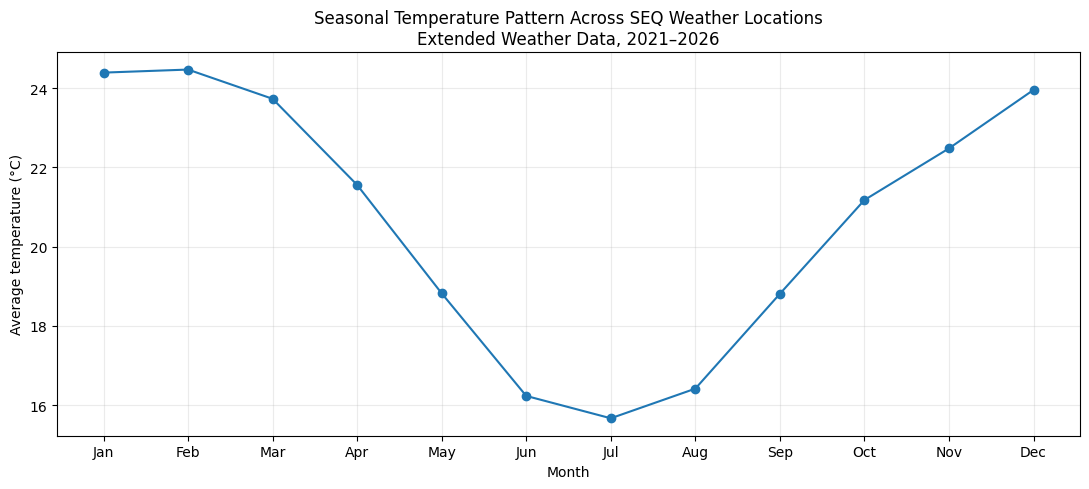


TEMPERATURE AROUND TICK SEASON


,Month_Name,Mean_Temp_C,Median_Temp_C
6,Jul,15.66,15.09
7,Aug,16.41,15.91
8,Sep,18.81,18.35
9,Oct,21.17,20.56
10,Nov,22.48,22.07


In [87]:
# ============================================================
# TEMPERATURE SEASONALITY — EXTENDED WEATHER DATA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

weather = weekly_weather_extended.copy()

weather["Week_End"] = pd.to_datetime(weather["Week_End"])

# Remove partial boundary weeks
weather = weather[
    (weather["Week_End"] >= "2021-10-03") &
    (weather["Week_End"] <= "2026-08-23")
].copy()

weather["Year"] = weather["Week_End"].dt.year
weather["Month"] = weather["Week_End"].dt.month


# ------------------------------------------------------------
# 1. Average temperature by month across weather locations
# ------------------------------------------------------------

monthly_temp = (
    weather
    .groupby(["Year", "Month", "WeatherLocationID"])
    .agg(
        AvgTemp_C=("AvgTemp_C", "mean")
    )
    .reset_index()
)

temp_seasonality = (
    monthly_temp
    .groupby("Month")
    .agg(
        Mean_Temp_C=("AvgTemp_C", "mean"),
        Median_Temp_C=("AvgTemp_C", "median"),
        Min_Temp_C=("AvgTemp_C", "min"),
        Max_Temp_C=("AvgTemp_C", "max"),
        Observations=("AvgTemp_C", "size")
    )
    .reset_index()
)

month_names = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
    5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
    9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}

temp_seasonality["Month_Name"] = (
    temp_seasonality["Month"].map(month_names)
)

print("TEMPERATURE SEASONALITY")
display(
    temp_seasonality[
        [
            "Month",
            "Month_Name",
            "Mean_Temp_C",
            "Median_Temp_C",
            "Min_Temp_C",
            "Max_Temp_C",
            "Observations"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# 2. Year × month temperature
# ------------------------------------------------------------

year_month_temp = (
    weather
    .groupby(["Year", "Month"])
    .agg(
        AvgTemp_C=("AvgTemp_C", "mean")
    )
    .reset_index()
)

year_month_temp["Month_Name"] = (
    year_month_temp["Month"].map(month_names)
)

print("\nYEAR × MONTH TEMPERATURE")
display(
    year_month_temp.pivot(
        index="Month_Name",
        columns="Year",
        values="AvgTemp_C"
    )
    .reindex([
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ])
    .round(2)
)


# ------------------------------------------------------------
# 3. Plot seasonal temperature pattern
# ------------------------------------------------------------

plt.figure(figsize=(11, 5))

plt.plot(
    temp_seasonality["Month"],
    temp_seasonality["Mean_Temp_C"],
    marker="o"
)

plt.xticks(
    range(1, 13),
    [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.xlabel("Month")
plt.ylabel("Average temperature (°C)")
plt.title(
    "Seasonal Temperature Pattern Across SEQ Weather Locations\n"
    "Extended Weather Data, 2021–2026"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Specifically inspect Jul–Nov
# ------------------------------------------------------------

tick_season_window = temp_seasonality[
    temp_seasonality["Month"].isin([7, 8, 9, 10, 11])
][
    ["Month_Name", "Mean_Temp_C", "Median_Temp_C"]
]

print("\nTEMPERATURE AROUND TICK SEASON")
display(tick_season_window.round(2))

TEMPERATURE vs TICK CONSULTATION DEMAND


,Year,Month_Name,AvgTemp_C,Temp_Change_C,Tick_Consultations,Tick_per_1000,Tick_Rate_Change,Both_Increased
0,2023,Jul,16.29,NaN,32,1.99,NaN,False
1,2023,Aug,17.41,1.12,310,2.70,0.71,True
2,2023,Sep,18.58,1.17,893,8.18,5.48,True
3,2023,Oct,20.78,2.20,687,5.86,-2.32,False
4,2023,Nov,22.05,1.26,1087,6.75,0.89,True
5,2024,Jul,15.48,NaN,614,3.74,NaN,False
6,2024,Aug,16.97,1.49,977,6.12,2.38,True
7,2024,Sep,19.74,2.78,1438,8.98,2.86,True
8,2024,Oct,20.87,1.13,2011,11.87,2.89,True
9,2024,Nov,22.94,2.07,934,5.27,-6.60,False



PEAK TICK MONTH BY YEAR


,Year,Peak_Tick_Month,Tick_per_1000,Temperature_at_Tick_Peak
2,2023,Sep,8.18,18.58
8,2024,Oct,11.87,20.87
12,2025,Sep,12.39,18.82


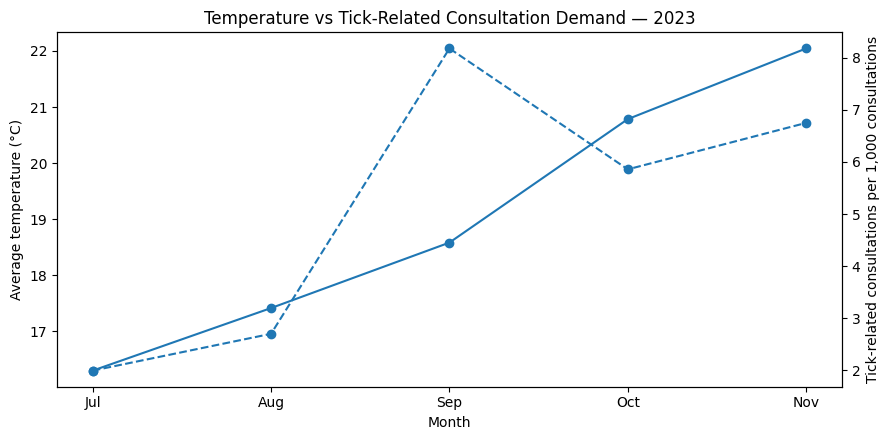

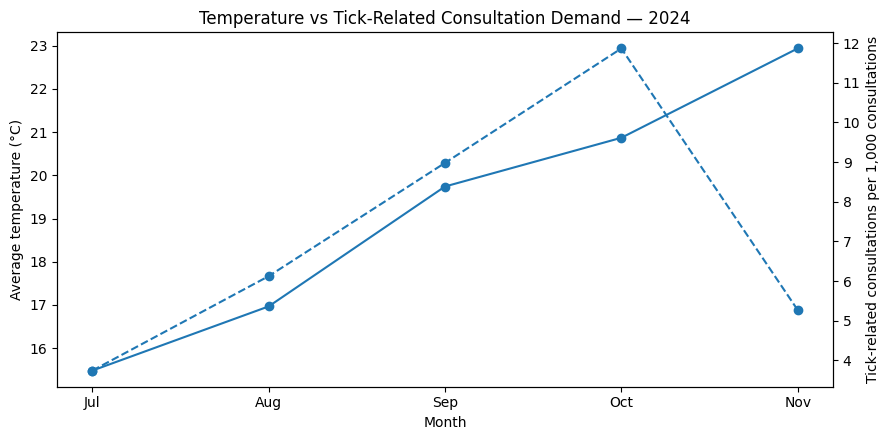

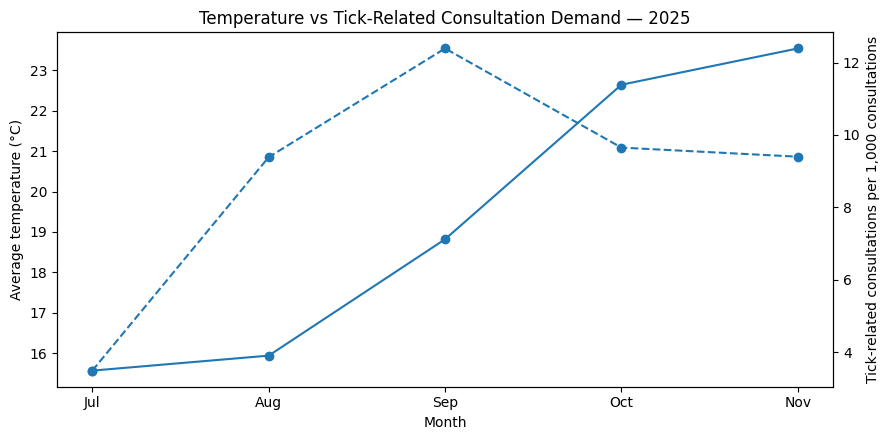

In [88]:
# ============================================================
# TEMPERATURE vs TICK CONSULTATION INCREASE
# 2023, 2024, 2025
# Jul-Nov comparison
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Tick consultation data already obtained earlier
#    Total consultations + tick-related consultations
# ------------------------------------------------------------

tick_monthly_data = [
    # Year, Month, Total consultations, Tick consultations

    # 2023
    [2023, 7, 16056, 32],
    [2023, 8, 114824, 310],
    [2023, 9, 109180, 893],
    [2023,10, 117283, 687],
    [2023,11, 161045,1087],

    # 2024
    [2024, 7, 164062, 614],
    [2024, 8, 159542, 977],
    [2024, 9, 160132,1438],
    [2024,10, 169470,2011],
    [2024,11, 177236, 934],

    # 2025
    [2025, 7, 183122, 639],
    [2025, 8, 174077,1634],
    [2025, 9, 184417,2285],
    [2025,10, 178849,1726],
    [2025,11, 167133,1571],
]

tick_compare = pd.DataFrame(
    tick_monthly_data,
    columns=[
        "Year",
        "Month",
        "Total_Consultations",
        "Tick_Consultations"
    ]
)

# Rate is better than raw count because consultation volume changes
tick_compare["Tick_per_1000"] = (
    tick_compare["Tick_Consultations"]
    / tick_compare["Total_Consultations"]
    * 1000
)


# ------------------------------------------------------------
# 2. Monthly temperature for corresponding years
# ------------------------------------------------------------

temp_compare = (
    year_month_temp[
        (year_month_temp["Year"].isin([2023, 2024, 2025])) &
        (year_month_temp["Month"].isin([7, 8, 9, 10, 11]))
    ]
    [["Year", "Month", "AvgTemp_C"]]
    .copy()
)


# ------------------------------------------------------------
# 3. Merge temperature + tick demand
# ------------------------------------------------------------

temp_tick_compare = tick_compare.merge(
    temp_compare,
    on=["Year", "Month"],
    how="left"
)

month_names = {
    7: "Jul",
    8: "Aug",
    9: "Sep",
    10: "Oct",
    11: "Nov"
}

temp_tick_compare["Month_Name"] = (
    temp_tick_compare["Month"].map(month_names)
)


# ------------------------------------------------------------
# 4. Month-to-month increases
# ------------------------------------------------------------

temp_tick_compare = temp_tick_compare.sort_values(
    ["Year", "Month"]
)

temp_tick_compare["Temp_Change_C"] = (
    temp_tick_compare
    .groupby("Year")["AvgTemp_C"]
    .diff()
)

temp_tick_compare["Tick_Rate_Change"] = (
    temp_tick_compare
    .groupby("Year")["Tick_per_1000"]
    .diff()
)

temp_tick_compare["Temperature_Increased"] = (
    temp_tick_compare["Temp_Change_C"] > 0
)

temp_tick_compare["Tick_Demand_Increased"] = (
    temp_tick_compare["Tick_Rate_Change"] > 0
)

temp_tick_compare["Both_Increased"] = (
    temp_tick_compare["Temperature_Increased"]
    &
    temp_tick_compare["Tick_Demand_Increased"]
)


# ------------------------------------------------------------
# 5. Display comparison
# ------------------------------------------------------------

print("TEMPERATURE vs TICK CONSULTATION DEMAND")

display(
    temp_tick_compare[
        [
            "Year",
            "Month_Name",
            "AvgTemp_C",
            "Temp_Change_C",
            "Tick_Consultations",
            "Tick_per_1000",
            "Tick_Rate_Change",
            "Both_Increased"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# 6. Identify peak month each year
# ------------------------------------------------------------

peak_tick = (
    temp_tick_compare.loc[
        temp_tick_compare
        .groupby("Year")["Tick_per_1000"]
        .idxmax(),
        [
            "Year",
            "Month_Name",
            "Tick_per_1000",
            "AvgTemp_C"
        ]
    ]
    .rename(columns={
        "Month_Name": "Peak_Tick_Month",
        "AvgTemp_C": "Temperature_at_Tick_Peak"
    })
)

print("\nPEAK TICK MONTH BY YEAR")
display(peak_tick.round(2))


# ------------------------------------------------------------
# 7. Plot each year separately
# ------------------------------------------------------------

for year in [2023, 2024, 2025]:

    d = temp_tick_compare[
        temp_tick_compare["Year"] == year
    ].copy()

    fig, ax1 = plt.subplots(figsize=(9, 4.5))

    ax1.plot(
        d["Month_Name"],
        d["AvgTemp_C"],
        marker="o",
        label="Temperature"
    )

    ax1.set_xlabel("Month")
    ax1.set_ylabel("Average temperature (°C)")

    ax2 = ax1.twinx()

    ax2.plot(
        d["Month_Name"],
        d["Tick_per_1000"],
        marker="o",
        linestyle="--",
        label="Tick consultations"
    )

    ax2.set_ylabel(
        "Tick-related consultations per 1,000 consultations"
    )

    plt.title(
        f"Temperature vs Tick-Related Consultation Demand — {year}"
    )

    fig.tight_layout()
    plt.show()

In [89]:
# ============================================================
# 2021–2026 TEMPERATURE + TICK DEMAND COMPARISON
# Use every month where BOTH datasets are available
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Monthly temperature: 2021–2026
# ------------------------------------------------------------

temp_all_years = (
    weather
    .groupby(["Year", "Month"])
    .agg(
        AvgTemp_C=("AvgTemp_C", "mean")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 2. Use our existing monthly consultation summary
# ------------------------------------------------------------

tick_all_years = monthly_consult.copy()

# Make sure Year / Month exist
if "Year" not in tick_all_years.columns:
    tick_all_years["Year"] = tick_all_years["Month"].dt.year

if "MonthNum" not in tick_all_years.columns:
    tick_all_years["MonthNum"] = tick_all_years["Month"].dt.month

# Standardise month column
tick_all_years = tick_all_years.rename(
    columns={"MonthNum": "Month_Number"}
)

# Detect the date/month column if needed
if "Month_Number" not in tick_all_years.columns:
    tick_all_years["Month_Number"] = pd.to_datetime(
        tick_all_years["Month"]
    ).dt.month

# ------------------------------------------------------------
# 3. Merge only months where both are available
# ------------------------------------------------------------

comparison_2021_2026 = tick_all_years.merge(
    temp_all_years,
    left_on=["Year", "Month_Number"],
    right_on=["Year", "Month"],
    how="inner"
)

comparison_2021_2026["Tick_per_1000"] = (
    comparison_2021_2026["Tick_Consultations"]
    / comparison_2021_2026["Total_Consultations"]
    * 1000
)

month_names = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
    5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
    9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}

comparison_2021_2026["Month_Name"] = (
    comparison_2021_2026["Month_Number"].map(month_names)
)

comparison_2021_2026 = comparison_2021_2026.sort_values(
    ["Year", "Month_Number"]
)

# ------------------------------------------------------------
# 4. Month-to-month changes within each year
# ------------------------------------------------------------

comparison_2021_2026["Temp_Change_C"] = (
    comparison_2021_2026
    .groupby("Year")["AvgTemp_C"]
    .diff()
)

comparison_2021_2026["Tick_Rate_Change"] = (
    comparison_2021_2026
    .groupby("Year")["Tick_per_1000"]
    .diff()
)

comparison_2021_2026["Same_Direction"] = (
    np.sign(comparison_2021_2026["Temp_Change_C"])
    ==
    np.sign(comparison_2021_2026["Tick_Rate_Change"])
)

# ------------------------------------------------------------
# 5. Display all available years
# ------------------------------------------------------------

print("AVAILABLE YEARS:")
print(sorted(comparison_2021_2026["Year"].unique()))

print("\nTEMPERATURE vs TICK DEMAND — ALL AVAILABLE MONTHS")

display(
    comparison_2021_2026[
        [
            "Year",
            "Month_Name",
            "AvgTemp_C",
            "Temp_Change_C",
            "Tick_Consultations",
            "Tick_per_1000",
            "Tick_Rate_Change",
            "Same_Direction"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 6. Show data availability by year
# ------------------------------------------------------------

availability_by_year = (
    comparison_2021_2026
    .groupby("Year")
    .agg(
        First_Month=("Month_Number", "min"),
        Last_Month=("Month_Number", "max"),
        Months_Available=("Month_Number", "nunique")
    )
    .reset_index()
)

print("\nCOMPARABLE MONTHS BY YEAR")
display(availability_by_year)

AVAILABLE YEARS:
[np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]

TEMPERATURE vs TICK DEMAND — ALL AVAILABLE MONTHS


,Year,Month_Name,AvgTemp_C,Temp_Change_C,Tick_Consultations,Tick_per_1000,Tick_Rate_Change,Same_Direction
0,2023,Jul,16.29,NaN,44,2.74,NaN,False
1,2023,Aug,17.41,1.12,360,3.14,0.39,True
2,2023,Sep,18.58,1.17,923,8.45,5.32,True
3,2023,Oct,20.78,2.20,726,6.19,-2.26,False
4,2023,Nov,22.05,1.26,1201,7.46,1.27,True
5,2023,Dec,24.93,2.88,962,6.57,-0.89,False
6,2024,Jan,25.26,NaN,499,2.98,NaN,False
7,2024,Feb,25.08,-0.18,359,2.21,-0.77,True
8,2024,Mar,23.52,-1.55,268,1.76,-0.46,True
9,2024,Apr,21.33,-2.19,229,1.44,-0.31,True



COMPARABLE MONTHS BY YEAR


,Year,First_Month,Last_Month,Months_Available
0,2023,7,12,6
1,2024,1,12,12
2,2025,1,12,12
3,2026,1,8,8


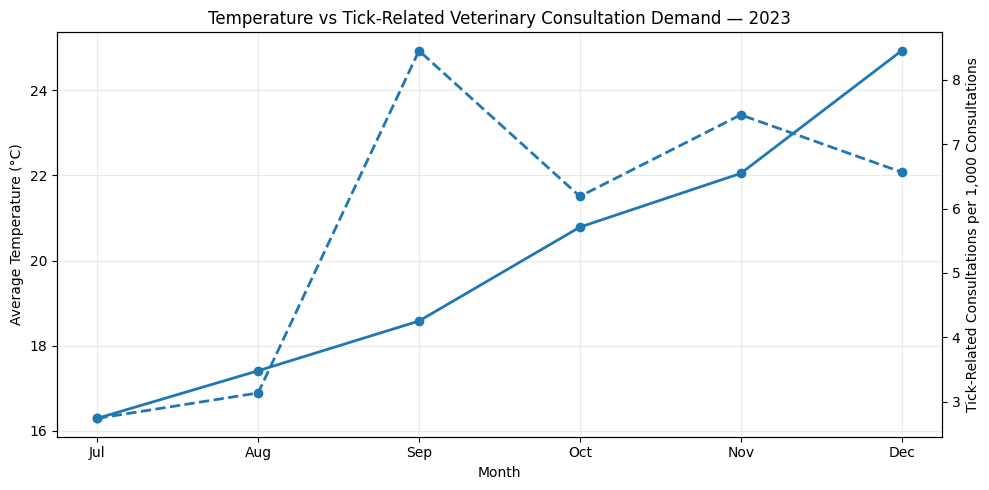

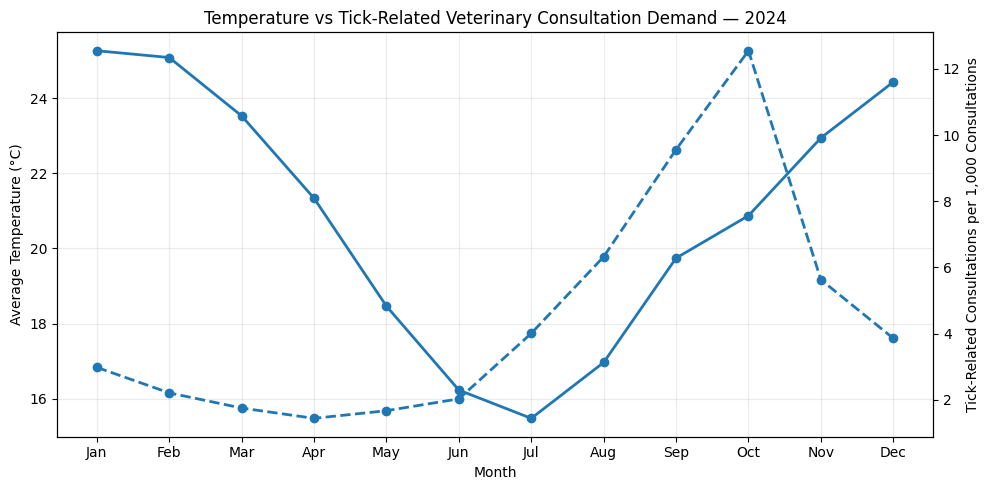

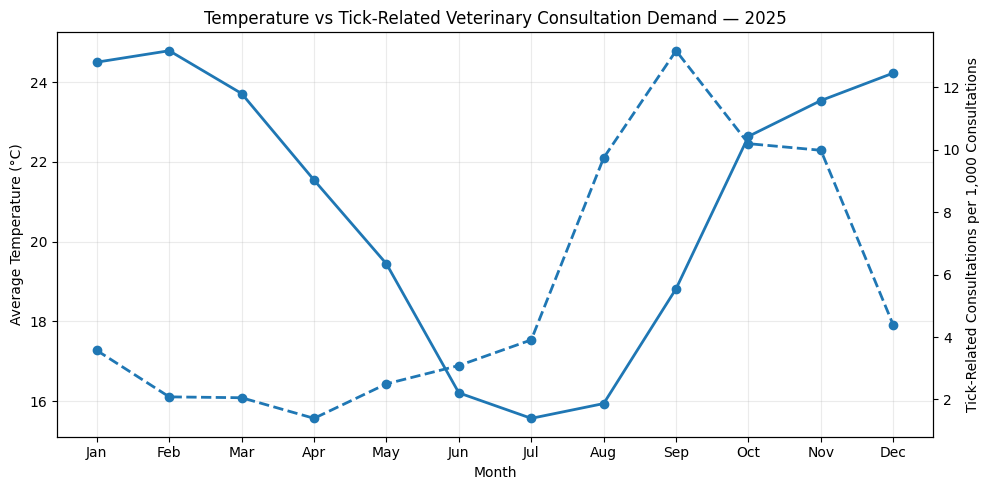

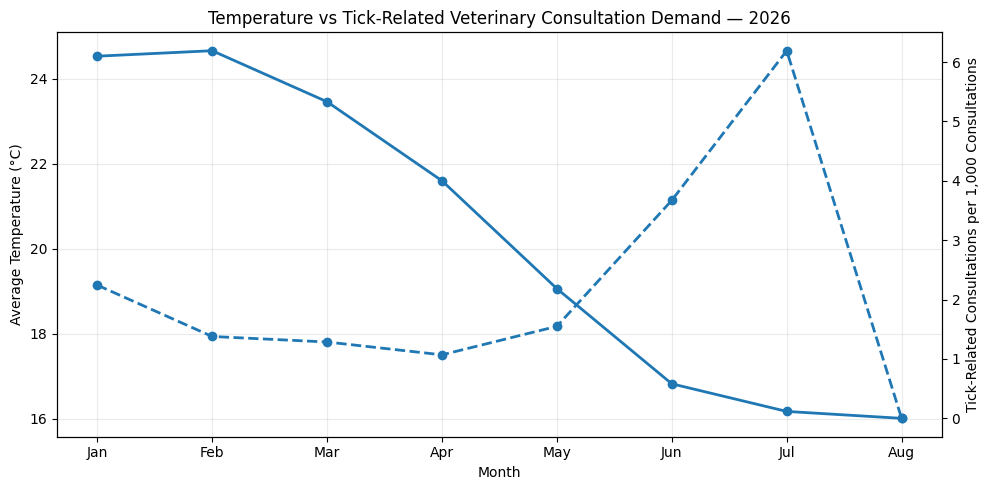

In [90]:
# ============================================================
# GRAPH — TEMPERATURE vs TICK DEMAND, 2021–2026
# ============================================================

import matplotlib.pyplot as plt

years = sorted(comparison_2021_2026["Year"].unique())

for year in years:

    d = comparison_2021_2026[
        comparison_2021_2026["Year"] == year
    ].sort_values("Month_Number")

    fig, ax1 = plt.subplots(figsize=(10, 5))

    # Temperature
    ax1.plot(
        d["Month_Name"],
        d["AvgTemp_C"],
        marker="o",
        linewidth=2,
        label="Average Temperature"
    )

    ax1.set_xlabel("Month")
    ax1.set_ylabel("Average Temperature (°C)")
    ax1.grid(alpha=0.25)

    # Tick consultation rate
    ax2 = ax1.twinx()

    ax2.plot(
        d["Month_Name"],
        d["Tick_per_1000"],
        marker="o",
        linestyle="--",
        linewidth=2,
        label="Tick Consultation Rate"
    )

    ax2.set_ylabel(
        "Tick-Related Consultations per 1,000 Consultations"
    )

    plt.title(
        f"Temperature vs Tick-Related Veterinary Consultation Demand — {year}"
    )

    fig.tight_layout()
    plt.show()

In [91]:
# ============================================================
# CHECK TICK-RELATED RECORDS IN 2021–2022
# Consultation.csv portion only
# ============================================================

old_period = consult[
    (consult["DataSource"] == "Consultation.csv") &
    (consult["ConsultationDate"].dt.year.isin([2021, 2022]))
].copy()

print("Rows:", len(old_period))
print(
    "Period:",
    old_period["ConsultationDate"].min(),
    "to",
    old_period["ConsultationDate"].max()
)

# Search only ItemServiceFeeName — the field available
# in the older Consultation.csv extract
tick_service = old_period[
    old_period["ItemServiceFeeName"]
    .fillna("")
    .str.contains(
        r"tick",
        case=False,
        regex=True
    )
].copy()

print("\nRows containing 'tick':", len(tick_service))
print(
    "Unique consultations:",
    tick_service["ConsultationKey"].nunique()
)

print("\nTICK-RELATED SERVICE NAMES:")
display(
    tick_service[
        "ItemServiceFeeName"
    ]
    .value_counts()
    .rename_axis("ItemServiceFeeName")
    .reset_index(name="Rows")
    .head(50)
)

print("\nBY YEAR:")
display(
    tick_service
    .assign(
        Year=tick_service["ConsultationDate"].dt.year
    )
    .groupby("Year")
    .agg(
        Tick_Rows=("ConsultationKey", "size"),
        Tick_Consultations=("ConsultationKey", "nunique"),
        Clinics=("ClinicID", "nunique")
    )
    .reset_index()
)

Rows: 625652
Period: 2021-10-01 00:00:00 to 2022-12-31 00:00:00

Rows containing 'tick': 68
Unique consultations: 68

TICK-RELATED SERVICE NAMES:


,ItemServiceFeeName,Rows
0,Tick Clip 0-9.9kg (Outpatient),14
1,Sedation/Anaesthesia for Tick Clip (Cat),11
2,TIck Clip - Cat (Outpatient),11
3,TIck Clip - Cat (Inpatient),9
4,Tick Clip 10-29.9kg (Inpatient),6
5,Tick Clip 0-9.9kg (Inpatient),5
6,Sedation/Anaesthesia For Tick Clip (Cat),5
7,Tick Clip 10-29.9kg (Outpatient),4
8,Tick Clip 30kg + (Inpatient),1
9,Tick Clip Double Coat Surcharge,1



BY YEAR:


,Year,Tick_Rows,Tick_Consultations,Clinics
0,2021,16,16,1
1,2022,52,52,1


In [92]:
# ============================================================
# STEP 1 — GROUP THE 48 VETIQ CLINIC LOCATIONS INTO SEQ REGIONS
# ============================================================

import pandas as pd
import numpy as np

# Regional grouping based on clinic suburb/location
region_map = {

    # Brisbane
    "Ashgrove": "Brisbane",
    "Bardon": "Brisbane",
    "Calamvale": "Brisbane",
    "Camp Hill": "Brisbane",
    "Chermside": "Brisbane",
    "Darra": "Brisbane",
    "Kuraby": "Brisbane",
    "Northgate": "Brisbane",
    "Paddington": "Brisbane",
    "Runcorn": "Brisbane",
    "Virginia": "Brisbane",
    "Wynnum": "Brisbane",
    "Zillmere": "Brisbane",

    # Logan
    "Greenbank": "Logan",
    "Logan Central": "Logan",
    "Loganholme": "Logan",
    "North MacLean": "Logan",

    # Ipswich / Springfield
    "Augustine Heights": "Ipswich / Springfield",
    "Bundamba": "Ipswich / Springfield",
    "Redbank Plains": "Ipswich / Springfield",
    "Springfield": "Ipswich / Springfield",

    # Moreton Bay
    "Deception Bay": "Moreton Bay",
    "Lawnton": "Moreton Bay",
    "Morayfield": "Moreton Bay",
    "Narangba": "Moreton Bay",

    # Gold Coast
    "Carrara": "Gold Coast",
    "Coomera": "Gold Coast",
    "Currumbin Waters": "Gold Coast",
    "Helensvale": "Gold Coast",
    "Labrador": "Gold Coast",
    "Miami": "Gold Coast",
    "Molendinar": "Gold Coast",
    "Pimpama": "Gold Coast",
    "Reedy Creek": "Gold Coast",
    "Varsity Lakes": "Gold Coast",

    # Scenic Rim
    "Beaudesert": "Scenic Rim",
    "Flagstone": "Scenic Rim",
    "Jimboomba": "Scenic Rim",

    # Sunshine Coast
    "Buderim": "Sunshine Coast",
    "Coolum Beach": "Sunshine Coast",
}

# ------------------------------------------------------------
# Use our existing 48-clinic location-matching table
# ------------------------------------------------------------

region_clinics = new_location_candidates.copy()

# If your location column is called something else,
# this will find the likely column.
print("Columns available:")
print(region_clinics.columns.tolist())

# ------------------------------------------------------------
# Find actual suburb/location column
# ------------------------------------------------------------

possible_location_cols = [
    "Suburb",
    "MatchedSuburb",
    "Matched_Suburb",
    "Location",
    "MatchedLocation"
]

location_col = next(
    (c for c in possible_location_cols if c in region_clinics.columns),
    None
)

if location_col is None:
    raise ValueError(
        "Could not find the matched suburb column. "
        "Check the columns printed above."
    )

print("\nUsing location column:", location_col)

# ------------------------------------------------------------
# Assign region
# ------------------------------------------------------------

region_clinics["SEQ_Region"] = (
    region_clinics[location_col].map(region_map)
)

# ------------------------------------------------------------
# Flag records
# ------------------------------------------------------------

region_clinics["Region_Status"] = np.where(
    region_clinics["SEQ_Region"].notna(),
    "SEQ",
    "Not mapped / ambiguous"
)

# ------------------------------------------------------------
# Show all clinic mappings
# ------------------------------------------------------------

print("\nCLINIC → LOCATION → REGION")

display(
    region_clinics[
        [
            "ClinicID",
            location_col,
            "SEQ_Region",
            "Region_Status"
        ]
    ]
    .sort_values(["SEQ_Region", "ClinicID"])
)

# ------------------------------------------------------------
# Summary by region
# ------------------------------------------------------------

region_summary = (
    region_clinics[
        region_clinics["Region_Status"] == "SEQ"
    ]
    .groupby("SEQ_Region")
    .agg(
        Clinics=("ClinicID", "nunique"),
        Locations=(location_col, "nunique")
    )
    .reset_index()
    .sort_values("Clinics", ascending=False)
)

print("\nSEQ REGION SUMMARY")
display(region_summary)

print(
    "\nTotal SEQ clinics mapped:",
    region_clinics.loc[
        region_clinics["Region_Status"] == "SEQ",
        "ClinicID"
    ].nunique()
)

print(
    "Clinics still unresolved/non-SEQ:",
    region_clinics.loc[
        region_clinics["Region_Status"] != "SEQ",
        "ClinicID"
    ].nunique()
)

print("\nUNRESOLVED / NON-SEQ LOCATIONS")

display(
    region_clinics.loc[
        region_clinics["Region_Status"] != "SEQ",
        [c for c in ["ClinicID", location_col, "SuburbName"]
         if c in region_clinics.columns]
    ]
)

Columns available:
['ClinicID', 'Suburb', 'Postcode', 'WeatherLocationID', 'latitude', 'longitude']

Using location column: Suburb

CLINIC → LOCATION → REGION


,ClinicID,Suburb,SEQ_Region,Region_Status
5,22,Darra,Brisbane,SEQ
1,15,Miami,Gold Coast,SEQ
4,21,Labrador,Gold Coast,SEQ
3,18,Loganholme,Logan,SEQ
2,17,Flagstone,Scenic Rim,SEQ
0,8,Harristown,NaN,Not mapped / ambiguous
6,91,NaN,NaN,Not mapped / ambiguous
7,96,NaN,NaN,Not mapped / ambiguous
8,99,NaN,NaN,Not mapped / ambiguous
9,101,NaN,NaN,Not mapped / ambiguous



SEQ REGION SUMMARY


,SEQ_Region,Clinics,Locations
1,Gold Coast,2,2
0,Brisbane,1,1
2,Logan,1,1
3,Scenic Rim,1,1



Total SEQ clinics mapped: 5
Clinics still unresolved/non-SEQ: 43

UNRESOLVED / NON-SEQ LOCATIONS


,ClinicID,Suburb
0,8,Harristown
6,91,NaN
7,96,NaN
8,99,NaN
9,101,NaN
10,102,NaN
11,104,NaN
12,105,NaN
13,106,NaN
14,107,NaN


In [93]:
# ============================================================
# 48 CLINICS × COMBINED 5-YEAR CONSULTATION COVERAGE
# Uses variables already in your notebook
# ============================================================

import pandas as pd

# Get the 48 unique ClinicIDs from the table we already created
clinic48_ids = set(
    new_location_candidates["ClinicID"]
    .dropna()
    .astype(int)
    .unique()
)

print("Reference ClinicIDs:", len(clinic48_ids))

# Make sure ClinicID in consultation data is numeric
consult["ClinicID"] = pd.to_numeric(
    consult["ClinicID"],
    errors="coerce"
)

consult["ConsultationDate"] = pd.to_datetime(
    consult["ConsultationDate"],
    errors="coerce"
)

# Keep consultations belonging to the 48-clinic reference list
consult48 = consult[
    consult["ClinicID"].isin(clinic48_ids)
].copy()

print("Clinics found in combined consultation data:",
      consult48["ClinicID"].nunique())

print(
    "Consultation period:",
    consult48["ConsultationDate"].min(),
    "to",
    consult48["ConsultationDate"].max()
)

print(
    "Unique consultations:",
    consult48["ConsultationKey"].nunique()
)

# ------------------------------------------------------------
# Coverage for each clinic
# ------------------------------------------------------------

coverage48 = (
    consult48
    .groupby("ClinicID")
    .agg(
        First_Date=("ConsultationDate", "min"),
        Last_Date=("ConsultationDate", "max"),
        Consultations=("ConsultationKey", "nunique")
    )
    .reset_index()
)

# Include all 48 reference IDs even if they have no consultations
all48 = pd.DataFrame({
    "ClinicID": sorted(clinic48_ids)
})

coverage48 = all48.merge(
    coverage48,
    on="ClinicID",
    how="left"
)

coverage48["Has_Data"] = (
    coverage48["Consultations"].fillna(0) > 0
)

print("\nSUMMARY")
print("Reference clinics:", len(coverage48))
print("With consultation data:", coverage48["Has_Data"].sum())
print("Without consultation data:", (~coverage48["Has_Data"]).sum())

display(coverage48)

Reference ClinicIDs: 48
Clinics found in combined consultation data: 26
Consultation period: 2021-10-01 00:00:00 to 2026-07-25 00:00:00
Unique consultations: 1477695

SUMMARY
Reference clinics: 48
With consultation data: 26
Without consultation data: 22


,ClinicID,First_Date,Last_Date,Consultations,Has_Data
0,8,2021-10-01,2026-04-28,138233.0,True
1,15,2023-07-27,2026-07-25,94838.0,True
2,17,2023-07-27,2026-07-25,80384.0,True
3,18,2023-07-27,2026-07-25,120414.0,True
4,21,2021-10-01,2026-07-25,81891.0,True
5,22,2021-10-01,2026-07-25,57490.0,True
6,91,NaT,NaT,NaN,False
7,96,2022-04-26,2023-09-13,7.0,True
8,99,2021-10-01,2023-10-31,30392.0,True
9,101,2021-10-01,2023-10-31,27747.0,True


In [94]:
# ============================================================
# STEP 3 — REGIONAL MAPPING FOR THE 26 CLINICS WITH DATA
# ============================================================

import pandas as pd

# Clinics that actually occur in the combined consultation data
active_ids = set(
    coverage48.loc[
        coverage48["Has_Data"],
        "ClinicID"
    ].astype(int)
)

# Start from our location candidates
active_locations = new_location_candidates[
    new_location_candidates["ClinicID"].isin(active_ids)
].copy()

# Use the region mapping we already created
active_locations["SEQ_Region"] = (
    active_locations["Suburb"].map(region_map)
)

# ------------------------------------------------------------
# Summarise possible locations/regions for each ClinicID
# ------------------------------------------------------------

clinic_region_check = (
    active_locations
    .groupby("ClinicID")
    .agg(
        Possible_Suburbs=(
            "Suburb",
            lambda x: " / ".join(
                sorted(set(x.dropna().astype(str)))
            )
        ),
        Possible_SEQ_Regions=(
            "SEQ_Region",
            lambda x: " / ".join(
                sorted(set(x.dropna().astype(str)))
            )
        ),
        Number_of_SEQ_Regions=(
            "SEQ_Region",
            lambda x: x.dropna().nunique()
        )
    )
    .reset_index()
)

# Add consultation coverage
clinic_region_check = clinic_region_check.merge(
    coverage48[
        [
            "ClinicID",
            "First_Date",
            "Last_Date",
            "Consultations"
        ]
    ],
    on="ClinicID",
    how="left"
)

# Classification
clinic_region_check["Mapping_Status"] = clinic_region_check[
    "Number_of_SEQ_Regions"
].map(
    lambda n:
        "Confirmed SEQ region" if n == 1
        else "Ambiguous region" if n > 1
        else "Non-SEQ / unresolved"
)

print("26 DATA-AVAILABLE CLINICS — REGIONAL CHECK")
print("=" * 70)

display(
    clinic_region_check.sort_values(
        ["Mapping_Status", "Possible_SEQ_Regions", "ClinicID"]
    )
)

print("\nSUMMARY")

display(
    clinic_region_check[
        "Mapping_Status"
    ].value_counts().rename_axis(
        "Status"
    ).reset_index(name="Clinics")
)

26 DATA-AVAILABLE CLINICS — REGIONAL CHECK


,ClinicID,Possible_Suburbs,Possible_SEQ_Regions,Number_of_SEQ_Regions,First_Date,Last_Date,Consultations,Mapping_Status
5,22,Darra,Brisbane,1,2021-10-01,2026-07-25,57490.0,Confirmed SEQ region
1,15,Miami,Gold Coast,1,2023-07-27,2026-07-25,94838.0,Confirmed SEQ region
4,21,Labrador,Gold Coast,1,2021-10-01,2026-07-25,81891.0,Confirmed SEQ region
3,18,Loganholme,Logan,1,2023-07-27,2026-07-25,120414.0,Confirmed SEQ region
2,17,Flagstone,Scenic Rim,1,2023-07-27,2026-07-25,80384.0,Confirmed SEQ region
0,8,Harristown,,0,2021-10-01,2026-04-28,138233.0,Non-SEQ / unresolved
6,96,,,0,2022-04-26,2023-09-13,7.0,Non-SEQ / unresolved
7,99,,,0,2021-10-01,2023-10-31,30392.0,Non-SEQ / unresolved
8,101,,,0,2021-10-01,2023-10-31,27747.0,Non-SEQ / unresolved
9,102,,,0,2021-10-01,2023-10-31,59636.0,Non-SEQ / unresolved



SUMMARY


,Status,Clinics
0,Non-SEQ / unresolved,21
1,Confirmed SEQ region,5


In [95]:
# ============================================================
# CHECK WHAT TICK DATA IS ALREADY IN MEMORY
# ============================================================

print("Tick-related variables currently in notebook:\n")

for name, obj in globals().items():

    if any(word in name.lower() for word in ["tick", "weekly"]):

        try:
            if isinstance(obj, pd.DataFrame):
                print(
                    f"{name:35s}",
                    "shape =", obj.shape,
                    "| columns =", obj.columns.tolist()
                )
        except:
            pass

Tick-related variables currently in notebook:

tick_service_rows                   shape = (111, 13) | columns = ['ConsultationKey', 'ClientKey', 'PatientKey', 'ClinicID', 'ConsultingVetUserID', 'ConsultationDate', 'ConsultationDateTime', 'ItemServiceFeeName', 'ItemServiceQty', 'TotalSalePriceAmt', 'TotalTaxAmt', 'ConsultationWeightDecimal', 'ConsultationTemperatureDecimal']
tick_service_summary                shape = (12, 3) | columns = ['ItemServiceFeeName', 'Rows', 'Unique_Consultations']
tick_data                           shape = (1672, 14) | columns = ['Tick_Category', 'StateCode', 'ClinicID', 'ConsultationNoCode', 'ConsultDate', 'Year', 'Month', 'PatientID', 'ClientID', 'Tick_Items', 'Items', 'Prevention_Sold', 'Patient_Tick_Visits', 'Repeat_Patient']
monthly_tick                        shape = (37, 2) | columns = ['Month', 'Tick_Consultations']
weekly_weather_extended             shape = (12691, 5) | columns = ['WeatherLocationID', 'Week_End', 'AvgTemp_C', 'Rainfall_mm', 'Humid

In [96]:
# ============================================================
# CHECK EXISTING WEEKLY TOTAL CONSULTATION DATA
# ============================================================

print("weekly_total shape:", weekly_total.shape)

print(
    "Clinics:",
    weekly_total["ClinicID"].nunique()
)

print(
    "Period:",
    pd.to_datetime(weekly_total["Week_End"]).min(),
    "to",
    pd.to_datetime(weekly_total["Week_End"]).max()
)

print("\nClinic IDs:")
print(
    sorted(
        weekly_total["ClinicID"]
        .dropna()
        .astype(int)
        .unique()
    )
)

print("\nWeeks per clinic:")

display(
    weekly_total
    .groupby("ClinicID")
    .agg(
        First_Week=("Week_End", "min"),
        Last_Week=("Week_End", "max"),
        Weeks=("Week_End", "nunique"),
        Total_Consultations=("Total_Consultations", "sum")
    )
    .reset_index()
    .sort_values("ClinicID")
)

weekly_total shape: (2796, 3)
Clinics: 26
Period: 2021-10-03 00:00:00 to 2026-07-26 00:00:00

Clinic IDs:
[np.int64(8), np.int64(15), np.int64(17), np.int64(18), np.int64(21), np.int64(22), np.int64(96), np.int64(99), np.int64(101), np.int64(102), np.int64(104), np.int64(105), np.int64(106), np.int64(107), np.int64(108), np.int64(109), np.int64(112), np.int64(130), np.int64(131), np.int64(136), np.int64(138), np.int64(154), np.int64(176), np.int64(241), np.int64(329), np.int64(338)]

Weeks per clinic:


,ClinicID,First_Week,Last_Week,Weeks,Total_Consultations
0,8,2021-10-03,2026-05-03,240,138233
1,15,2023-07-30,2026-07-26,157,94838
2,17,2023-07-30,2026-07-26,157,80384
3,18,2023-07-30,2026-07-26,157,120414
4,21,2021-10-03,2026-07-26,177,81891
5,22,2021-10-03,2026-07-26,186,57490
6,96,2022-05-01,2023-09-17,4,7
7,99,2021-10-03,2023-11-05,110,30392
8,101,2021-10-03,2023-11-05,110,27747
9,102,2021-10-03,2023-11-05,110,59636


In [97]:
# ============================================================
# CHECK EXISTING WEEKLY TICK-BY-CLINIC FILE
# ============================================================

import pandas as pd

path = "/Users/sreelakshmi/Desktop/RMIT_final/project/new_tick_weekly_by_clinic.csv"

tick_weekly = pd.read_csv(path)

print("Shape:", tick_weekly.shape)

print("\nColumns:")
print(tick_weekly.columns.tolist())

print("\nFirst rows:")
display(tick_weekly.head(10))

print("\nClinic IDs / pseudonyms:")
for col in tick_weekly.columns:
    if "clinic" in col.lower():
        print(
            col,
            "| unique:",
            tick_weekly[col].nunique()
        )
        print(tick_weekly[col].dropna().unique()[:50])

print("\nDate coverage:")
for col in tick_weekly.columns:
    if "week" in col.lower() or "date" in col.lower():
        d = pd.to_datetime(tick_weekly[col], errors="coerce")

        if d.notna().any():
            print(
                col,
                "|",
                d.min(),
                "to",
                d.max(),
                "| rows:",
                d.notna().sum()
            )

print("\nNumeric columns:")
print(
    tick_weekly.select_dtypes(
        include="number"
    ).columns.tolist()
)

Shape: (1167, 3)

Columns:
['ClinicID', 'Week_End', 'Tick_Consultations']

First rows:


,ClinicID,Week_End,Tick_Consultations
0,8,2021-09-12,1
1,8,2021-11-07,1
2,8,2022-06-19,1
3,8,2023-10-15,2
4,8,2023-10-22,2
5,8,2024-10-27,1
6,8,2024-11-24,1
7,8,2025-02-02,1
8,8,2025-11-23,1
9,8,2026-08-16,1



Clinic IDs / pseudonyms:
ClinicID | unique: 29
[  8  15  17  18  21  22  99 101 102 104 105 106 107 108 109 110 111 112
 130 131 136 138 154 176 241 263 269 329 338]

Date coverage:
Week_End | 2020-01-05 00:00:00 to 2026-09-27 00:00:00 | rows: 1167

Numeric columns:
['ClinicID', 'Tick_Consultations']


In [98]:
# ============================================================
# BUILD REGIONAL WEEKLY VETIQ TICK-DEMAND DATASET
# SEQ clinics only
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Dates
# ------------------------------------------------------------

tick_weekly["Week_End"] = pd.to_datetime(tick_weekly["Week_End"])
weekly_total["Week_End"] = pd.to_datetime(weekly_total["Week_End"])

tick_weekly["ClinicID"] = pd.to_numeric(
    tick_weekly["ClinicID"], errors="coerce"
)

weekly_total["ClinicID"] = pd.to_numeric(
    weekly_total["ClinicID"], errors="coerce"
)

# ------------------------------------------------------------
# 2. Use only UNAMBIGUOUS SEQ mappings
#
# Exclude:
# 102 = Ashgrove / Atherton
# 106 = Helensvale / Harristown
# 131 = Gold Coast / Moreton Bay
# 154,176 = non-SEQ
# ------------------------------------------------------------

exclude_ids = {102, 106, 131, 154, 176}

# Get one unique SEQ region per ClinicID
region_lookup = (
    active_locations[
        active_locations["SEQ_Region"].notna()
        & ~active_locations["ClinicID"].isin(exclude_ids)
    ]
    [["ClinicID", "SEQ_Region"]]
    .drop_duplicates()
)

# Keep only IDs that map to exactly one region
region_counts = (
    region_lookup
    .groupby("ClinicID")["SEQ_Region"]
    .nunique()
)

valid_ids = region_counts[
    region_counts == 1
].index

region_lookup = (
    region_lookup[
        region_lookup["ClinicID"].isin(valid_ids)
    ]
    .drop_duplicates("ClinicID")
)

print("Unambiguous SEQ clinics:", region_lookup["ClinicID"].nunique())

display(
    region_lookup
    .sort_values(["SEQ_Region", "ClinicID"])
)

# ------------------------------------------------------------
# 3. Start from weekly_total
#
# This is important:
# a zero tick count is allowed ONLY when the clinic had
# consultations in that week.
# ------------------------------------------------------------

regional_base = weekly_total.merge(
    region_lookup,
    on="ClinicID",
    how="inner"
)

# ------------------------------------------------------------
# 4. Add weekly tick counts
# ------------------------------------------------------------

regional_base = regional_base.merge(
    tick_weekly[
        ["ClinicID", "Week_End", "Tick_Consultations"]
    ],
    on=["ClinicID", "Week_End"],
    how="left"
)

# Active clinic-week + no tick record = zero tick consultations
regional_base["Tick_Consultations"] = (
    regional_base["Tick_Consultations"]
    .fillna(0)
)

# ------------------------------------------------------------
# 5. Aggregate clinics into SEQ regions
# ------------------------------------------------------------

regional_weekly = (
    regional_base
    .groupby(["SEQ_Region", "Week_End"])
    .agg(
        Active_Clinics=("ClinicID", "nunique"),
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
)

# Tick demand per 1,000 consultations
regional_weekly["Tick_per_1000"] = (
    regional_weekly["Tick_Consultations"]
    / regional_weekly["Total_Consultations"]
    * 1000
)

# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

print("\nREGIONAL WEEKLY DATASET")
print("=" * 65)

print("Rows:", len(regional_weekly))
print(
    "Period:",
    regional_weekly["Week_End"].min(),
    "to",
    regional_weekly["Week_End"].max()
)

print("\nREGIONAL COVERAGE")

region_coverage = (
    regional_weekly
    .groupby("SEQ_Region")
    .agg(
        First_Week=("Week_End", "min"),
        Last_Week=("Week_End", "max"),
        Weeks=("Week_End", "nunique"),
        Max_Active_Clinics=("Active_Clinics", "max"),
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
)

display(region_coverage)

print("\nSAMPLE")
display(regional_weekly.head(20))

Unambiguous SEQ clinics: 5


,ClinicID,SEQ_Region
5,22,Brisbane
1,15,Gold Coast
4,21,Gold Coast
3,18,Logan
2,17,Scenic Rim



REGIONAL WEEKLY DATASET
Rows: 752
Period: 2021-10-03 00:00:00 to 2026-07-26 00:00:00

REGIONAL COVERAGE


,SEQ_Region,First_Week,Last_Week,Weeks,Max_Active_Clinics,Total_Consultations,Tick_Consultations
0,Brisbane,2021-10-03,2026-07-26,186,1,57490,104.0
1,Gold Coast,2021-10-03,2026-07-26,252,2,176729,91.0
2,Logan,2023-07-30,2026-07-26,157,1,120414,9.0
3,Scenic Rim,2023-07-30,2026-07-26,157,1,80384,39.0



SAMPLE


,SEQ_Region,Week_End,Active_Clinics,Total_Consultations,Tick_Consultations,Tick_per_1000
0,Brisbane,2021-10-03,1,64,1.0,15.625000
1,Brisbane,2021-10-10,1,196,1.0,5.102041
2,Brisbane,2021-10-17,1,179,0.0,0.000000
3,Brisbane,2021-10-24,1,207,0.0,0.000000
4,Brisbane,2021-10-31,1,240,0.0,0.000000
5,Brisbane,2021-11-07,1,222,0.0,0.000000
6,Brisbane,2021-11-14,1,236,0.0,0.000000
7,Brisbane,2021-11-21,1,236,0.0,0.000000
8,Brisbane,2021-11-28,1,268,1.0,3.731343
9,Brisbane,2021-12-05,1,225,0.0,0.000000


In [99]:
# ============================================================
# STEP 4 — REGIONAL TEMPERATURE + TICK DEMAND
# Then test same week, +1 week and +2 weeks
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# ------------------------------------------------------------
# 1. Attach region to clinic-level weather
# ------------------------------------------------------------

weather_region = clinic_weekly_weather.merge(
    region_lookup,
    on="ClinicID",
    how="inner"
)

weather_region["Week_End"] = pd.to_datetime(
    weather_region["Week_End"]
)

# ------------------------------------------------------------
# 2. Regional average weekly temperature
# ------------------------------------------------------------

regional_temp = (
    weather_region
    .groupby(["SEQ_Region", "Week_End"])
    .agg(
        AvgTemp_C=("AvgTemp_C", "mean"),
        Weather_Clinics=("ClinicID", "nunique")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 3. Merge temperature with regional tick demand
# ------------------------------------------------------------

regional_analysis = regional_weekly.merge(
    regional_temp,
    on=["SEQ_Region", "Week_End"],
    how="inner"
)

regional_analysis = regional_analysis.sort_values(
    ["SEQ_Region", "Week_End"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 4. Temperature change from previous week
# ------------------------------------------------------------

regional_analysis["Temp_Change_C"] = (
    regional_analysis
    .groupby("SEQ_Region")["AvgTemp_C"]
    .diff()
)

# Current tick-rate change
regional_analysis["Tick_Change_0w"] = (
    regional_analysis
    .groupby("SEQ_Region")["Tick_per_1000"]
    .diff()
)

# ------------------------------------------------------------
# 5. FUTURE tick demand
#
# +1 = next week's tick rate
# +2 = tick rate two weeks later
# ------------------------------------------------------------

regional_analysis["Tick_Rate_1w"] = (
    regional_analysis
    .groupby("SEQ_Region")["Tick_per_1000"]
    .shift(-1)
)

regional_analysis["Tick_Rate_2w"] = (
    regional_analysis
    .groupby("SEQ_Region")["Tick_per_1000"]
    .shift(-2)
)

# Change relative to current week
regional_analysis["Tick_Change_1w"] = (
    regional_analysis["Tick_Rate_1w"]
    - regional_analysis["Tick_per_1000"]
)

regional_analysis["Tick_Change_2w"] = (
    regional_analysis["Tick_Rate_2w"]
    - regional_analysis["Tick_per_1000"]
)

# ------------------------------------------------------------
# 6. Direction indicators
# ------------------------------------------------------------

regional_analysis["Temp_Direction"] = np.where(
    regional_analysis["Temp_Change_C"] > 0,
    "Temperature increased",
    np.where(
        regional_analysis["Temp_Change_C"] < 0,
        "Temperature decreased",
        "No change"
    )
)

for lag in [0, 1, 2]:

    regional_analysis[f"Tick_Direction_{lag}w"] = np.where(
        regional_analysis[f"Tick_Change_{lag}w"] > 0,
        "Tick demand increased",
        np.where(
            regional_analysis[f"Tick_Change_{lag}w"] < 0,
            "Tick demand decreased",
            "No change"
        )
    )

# ------------------------------------------------------------
# 7. Spearman relationship by region
# Temperature CHANGE vs tick-demand CHANGE
# ------------------------------------------------------------

results = []

for region, d in regional_analysis.groupby("SEQ_Region"):

    for lag in [0, 1, 2]:

        x = d["Temp_Change_C"]
        y = d[f"Tick_Change_{lag}w"]

        valid = x.notna() & y.notna()

        if valid.sum() >= 10:

            rho, p = spearmanr(
                x[valid],
                y[valid]
            )

        else:
            rho, p = np.nan, np.nan

        # Direction agreement:
        # warming + tick increase OR
        # cooling + tick decrease
        direction_valid = valid & (x != 0) & (y != 0)

        if direction_valid.sum() > 0:

            same_direction = (
                np.sign(x[direction_valid])
                ==
                np.sign(y[direction_valid])
            ).mean() * 100

        else:
            same_direction = np.nan

        results.append({
            "SEQ_Region": region,
            "Lag": f"+{lag} week",
            "Weeks": int(valid.sum()),
            "Spearman_rho": rho,
            "p_value": p,
            "Directional_Agreement_pct": same_direction
        })

regional_temp_tick_results = pd.DataFrame(results)

# ------------------------------------------------------------
# 8. Display
# ------------------------------------------------------------

print("REGIONAL TEMPERATURE CHANGE vs TICK-DEMAND CHANGE")
print("=" * 75)

display(
    regional_temp_tick_results.round({
        "Spearman_rho": 3,
        "p_value": 4,
        "Directional_Agreement_pct": 1
    })
)

print("\nDATA PERIOD / COVERAGE")

display(
    regional_analysis
    .groupby("SEQ_Region")
    .agg(
        First_Week=("Week_End", "min"),
        Last_Week=("Week_End", "max"),
        Weeks=("Week_End", "nunique"),
        Mean_Temp=("AvgTemp_C", "mean"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
    .round(2)
)

REGIONAL TEMPERATURE CHANGE vs TICK-DEMAND CHANGE


,SEQ_Region,Lag,Weeks,Spearman_rho,p_value,Directional_Agreement_pct
0,Brisbane,+0 week,185,-0.083,0.2612,50.0
1,Brisbane,+1 week,184,0.036,0.6321,48.9
2,Brisbane,+2 week,183,0.077,0.3013,53.1
3,Gold Coast,+0 week,251,-0.058,0.3586,45.1
4,Gold Coast,+1 week,250,-0.055,0.3826,46.3
5,Gold Coast,+2 week,249,0.018,0.7725,49.4
6,Logan,+0 week,156,0.004,0.9556,47.1
7,Logan,+1 week,155,-0.134,0.0956,35.3
8,Logan,+2 week,154,0.066,0.4169,64.3
9,Scenic Rim,+0 week,156,0.030,0.7078,62.9



DATA PERIOD / COVERAGE


,SEQ_Region,First_Week,Last_Week,Weeks,Mean_Temp,Tick_Consultations
0,Brisbane,2021-10-03,2026-07-26,186,19.40,104.0
1,Gold Coast,2021-10-03,2026-07-26,252,19.89,91.0
2,Logan,2023-07-30,2026-07-26,157,20.14,9.0
3,Scenic Rim,2023-07-30,2026-07-26,157,20.37,39.0


In [100]:
# ============================================================
# SEQ REGIONAL SEASONALITY
# Monthly temperature vs monthly tick demand
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Add calendar information
# ------------------------------------------------------------

seasonal = regional_analysis.copy()

seasonal["Year"] = seasonal["Week_End"].dt.year
seasonal["Month"] = seasonal["Week_End"].dt.month

month_names = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
    5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
    9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}

# ------------------------------------------------------------
# 2. First aggregate WITHIN each year/month
#
# Important: calculate tick rate from summed consultations,
# not by averaging weekly rates.
# ------------------------------------------------------------

region_year_month = (
    seasonal
    .groupby(["SEQ_Region", "Year", "Month"])
    .agg(
        AvgTemp_C=("AvgTemp_C", "mean"),
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum"),
        Weeks=("Week_End", "nunique")
    )
    .reset_index()
)

region_year_month["Tick_per_1000"] = (
    region_year_month["Tick_Consultations"]
    / region_year_month["Total_Consultations"]
    * 1000
)

# Keep reasonably complete months
region_year_month = region_year_month[
    region_year_month["Weeks"] >= 3
].copy()

# ------------------------------------------------------------
# 3. Seasonal average across years
# ------------------------------------------------------------

regional_seasonality = (
    region_year_month
    .groupby(["SEQ_Region", "Month"])
    .agg(
        Mean_Temp_C=("AvgTemp_C", "mean"),
        Mean_Tick_per_1000=("Tick_per_1000", "mean"),
        Years_Available=("Year", "nunique")
    )
    .reset_index()
)

regional_seasonality["Month_Name"] = (
    regional_seasonality["Month"].map(month_names)
)

# ------------------------------------------------------------
# 4. Find temperature and tick peak month for each region
# ------------------------------------------------------------

peak_rows = []

for region, d in regional_seasonality.groupby("SEQ_Region"):

    temp_peak = d.loc[d["Mean_Temp_C"].idxmax()]
    tick_peak = d.loc[d["Mean_Tick_per_1000"].idxmax()]

    peak_rows.append({
        "SEQ_Region": region,
        "Temperature_Peak_Month":
            month_names[int(temp_peak["Month"])],
        "Peak_Temperature_C":
            temp_peak["Mean_Temp_C"],
        "Tick_Peak_Month":
            month_names[int(tick_peak["Month"])],
        "Peak_Tick_per_1000":
            tick_peak["Mean_Tick_per_1000"]
    })

regional_peaks = pd.DataFrame(peak_rows)

# ------------------------------------------------------------
# 5. Display seasonal pattern
# ------------------------------------------------------------

print("REGIONAL SEASONAL TEMPERATURE + TICK DEMAND")
print("=" * 70)

display(
    regional_seasonality[
        [
            "SEQ_Region",
            "Month_Name",
            "Mean_Temp_C",
            "Mean_Tick_per_1000",
            "Years_Available"
        ]
    ].round(2)
)

print("\nSEASONAL PEAK MONTHS")

display(
    regional_peaks.round({
        "Peak_Temperature_C": 2,
        "Peak_Tick_per_1000": 2
    })
)

REGIONAL SEASONAL TEMPERATURE + TICK DEMAND


,SEQ_Region,Month_Name,Mean_Temp_C,Mean_Tick_per_1000,Years_Available
0,Brisbane,Jan,23.51,2.73,3
1,Brisbane,Feb,23.50,0.33,3
2,Brisbane,Mar,23.17,0.77,3
3,Brisbane,Apr,20.57,0.57,4
4,Brisbane,May,17.46,0.49,3
5,Brisbane,Jun,14.79,0.93,4
6,Brisbane,Jul,14.18,0.94,4
7,Brisbane,Aug,15.10,2.11,3
8,Brisbane,Sep,17.31,4.30,3
9,Brisbane,Oct,20.32,3.87,4



SEASONAL PEAK MONTHS


,SEQ_Region,Temperature_Peak_Month,Peak_Temperature_C,Tick_Peak_Month,Peak_Tick_per_1000
0,Brisbane,Jan,23.51,Sep,4.30
1,Gold Coast,Feb,24.03,Oct,1.84
2,Logan,Feb,24.49,Oct,0.29
3,Scenic Rim,Feb,24.87,Sep,2.79


In [101]:
import pandas as pd

week8_clinics = pd.DataFrame([
    ("Clinic_07", "North MacLean"),
    ("Clinic_47", "Coolum Beach"),
    ("Clinic_18", "Loganholme"),
    ("Clinic_31", "Greenbank"),
    ("Clinic_17", "Flagstone"),
    ("Clinic_59", "Northgate"),
    ("Clinic_13", "Ashgrove"),
    ("Clinic_14", "Jimboomba"),
    ("Clinic_30", "Wynnum"),
    ("Clinic_12", "Bardon"),
    ("Clinic_16", "Helensvale"),
    ("Clinic_27", "Narangba"),
    ("Clinic_54", "Beaudesert"),
    ("Clinic_04", "Redbank Plains"),
    ("Clinic_06", "Greenbank"),
    ("Clinic_03", "Augustine Heights"),
    ("Clinic_28", "Morayfield"),
    ("Clinic_01", "Deception Bay"),
    ("Clinic_58", "Virginia"),
    ("Clinic_19", "Lawnton"),
    ("Clinic_15", "Miami"),
    ("Clinic_05", "Springfield"),
], columns=["Week8_Clinic", "Week8_Suburb"])

print("Week 8 clinics:", len(week8_clinics))

Week 8 clinics: 22


In [102]:
for name in [
    "week8_clinics",
    "new_location_candidates",
    "coverage48",
    "weekly_total"
]:
    print(name, ":", name in globals())

week8_clinics : True
new_location_candidates : True
coverage48 : True
weekly_total : True


In [103]:
week8_match = week8_clinics.merge(
    new_location_candidates[
        ["ClinicID", "Suburb"]
    ].drop_duplicates(),
    left_on="Week8_Suburb",
    right_on="Suburb",
    how="left"
)

print("Rows:", len(week8_match))
print("Columns:", week8_match.columns.tolist())

display(week8_match.head())

Rows: 22
Columns: ['Week8_Clinic', 'Week8_Suburb', 'ClinicID', 'Suburb']


,Week8_Clinic,Week8_Suburb,ClinicID,Suburb
0,Clinic_07,North MacLean,<NA>,NaN
1,Clinic_47,Coolum Beach,<NA>,NaN
2,Clinic_18,Loganholme,18,Loganholme
3,Clinic_31,Greenbank,<NA>,NaN
4,Clinic_17,Flagstone,17,Flagstone


In [104]:

print("Columns in week8_match:")
print(week8_match.columns.tolist())

print("\nColumns in coverage48:")
print(coverage48.columns.tolist())


Columns in week8_match:
['Week8_Clinic', 'Week8_Suburb', 'ClinicID', 'Suburb']

Columns in coverage48:
['ClinicID', 'First_Date', 'Last_Date', 'Consultations', 'Has_Data']


In [105]:


# ============================================================
# FIX WEEK 8 MATCH — ADD CONSULTATION AND WEEKLY COVERAGE
# ============================================================

# Work from the existing location matches
week8_match = week8_match[
    ["Week8_Clinic", "Week8_Suburb", "ClinicID", "Suburb"]
].copy()

# Standardise ClinicID across the three DataFrames
def clean_clinic_id(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

week8_match["ClinicID"] = clean_clinic_id(
    week8_match["ClinicID"]
)

coverage48["ClinicID"] = clean_clinic_id(
    coverage48["ClinicID"]
)

weekly_total["ClinicID"] = clean_clinic_id(
    weekly_total["ClinicID"]
)

# Add consultation coverage
week8_match = week8_match.merge(
    coverage48[
        [
            "ClinicID",
            "Has_Data",
            "First_Date",
            "Last_Date",
            "Consultations"
        ]
    ],
    on="ClinicID",
    how="left",
    validate="many_to_one"
)

# Calculate weekly coverage
weekly_cov = (
    weekly_total
    .groupby("ClinicID")["Week_End"]
    .nunique()
    .reset_index(name="Weeks")
)

# Add weekly coverage
week8_match = week8_match.merge(
    weekly_cov,
    on="ClinicID",
    how="left",
    validate="many_to_one"
)

# Add match status
week8_match["Match_Status"] = np.where(
    week8_match["ClinicID"].isna(),
    "Not found in new 48",
    np.where(
        week8_match["Has_Data"].fillna(False),
        "Matched + consultation data",
        "Matched location but no consultation data"
    )
)

print("Week 8 matching completed.")
print("Matched rows:", len(week8_match))

display(week8_match)


Week 8 matching completed.
Matched rows: 22


/var/folders/_w/whgh5msd3m51z0f722vzc5140000gn/T/ipykernel_27594/4062124031.py:67: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  week8_match["Has_Data"].fillna(False),


,Week8_Clinic,Week8_Suburb,ClinicID,Suburb,Has_Data,First_Date,Last_Date,Consultations,Weeks,Match_Status
0,Clinic_07,North MacLean,<NA>,NaN,NaN,NaT,NaT,NaN,NaN,Not found in new 48
1,Clinic_47,Coolum Beach,<NA>,NaN,NaN,NaT,NaT,NaN,NaN,Not found in new 48
2,Clinic_18,Loganholme,18,Loganholme,True,2023-07-27,2026-07-25,120414.0,157.0,Matched + consultation data
3,Clinic_31,Greenbank,<NA>,NaN,NaN,NaT,NaT,NaN,NaN,Not found in new 48
4,Clinic_17,Flagstone,17,Flagstone,True,2023-07-27,2026-07-25,80384.0,157.0,Matched + consultation data
5,Clinic_59,Northgate,<NA>,NaN,NaN,NaT,NaT,NaN,NaN,Not found in new 48
6,Clinic_13,Ashgrove,<NA>,NaN,NaN,NaT,NaT,NaN,NaN,Not found in new 48
7,Clinic_14,Jimboomba,<NA>,NaN,NaN,NaT,NaT,NaN,NaN,Not found in new 48
8,Clinic_30,Wynnum,<NA>,NaN,NaN,NaT,NaT,NaN,NaN,Not found in new 48
9,Clinic_12,Bardon,<NA>,NaN,NaN,NaT,NaT,NaN,NaN,Not found in new 48


In [106]:
# ============================================================
# BINOMIAL MODEL DATA — 21 UNIQUE MATCHED SEQ CLINICS
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Use the 21 unique matched clinic IDs
# ------------------------------------------------------------

model_ids = np.array([
    8, 15, 17, 18, 21, 22,
    101, 102, 104, 105, 106, 107, 108, 109,
    130, 131, 136, 138, 241, 329, 338
])

print("Clinics selected:", len(model_ids))
print("Clinic IDs:", sorted(model_ids))


# ------------------------------------------------------------
# 2. Weekly total consultations
# ------------------------------------------------------------

binomial_df = weekly_total[
    weekly_total["ClinicID"].isin(model_ids)
].copy()

binomial_df["Week_End"] = pd.to_datetime(
    binomial_df["Week_End"]
)


# ------------------------------------------------------------
# 3. Add tick consultations
# ------------------------------------------------------------

tick_temp = tick_weekly[
    ["ClinicID", "Week_End", "Tick_Consultations"]
].copy()

tick_temp["Week_End"] = pd.to_datetime(
    tick_temp["Week_End"]
)

binomial_df = binomial_df.merge(
    tick_temp,
    on=["ClinicID", "Week_End"],
    how="left"
)

# No recorded tick consultation during an observed week
binomial_df["Tick_Consultations"] = (
    binomial_df["Tick_Consultations"].fillna(0)
)


# ------------------------------------------------------------
# 4. Add weekly local temperature
# ------------------------------------------------------------

weather_temp = clinic_weekly_weather[
    ["ClinicID", "Week_End", "AvgTemp_C"]
].copy()

weather_temp["Week_End"] = pd.to_datetime(
    weather_temp["Week_End"]
)

weather_temp = weather_temp.drop_duplicates(
    ["ClinicID", "Week_End"]
)

binomial_df = binomial_df.merge(
    weather_temp,
    on=["ClinicID", "Week_End"],
    how="left"
)


# ------------------------------------------------------------
# 5. Validate binomial outcome
# ------------------------------------------------------------

binomial_df = binomial_df[
    binomial_df["Total_Consultations"] > 0
].copy()

invalid = (
    binomial_df["Tick_Consultations"]
    > binomial_df["Total_Consultations"]
)

print("\nInvalid tick > total rows:", invalid.sum())

binomial_df = binomial_df[~invalid].copy()


# ------------------------------------------------------------
# 6. Tick consultation rate
# ------------------------------------------------------------

binomial_df["Tick_Rate"] = (
    binomial_df["Tick_Consultations"]
    / binomial_df["Total_Consultations"]
)

binomial_df["Tick_per_1000"] = (
    binomial_df["Tick_Rate"] * 1000
)


# ------------------------------------------------------------
# 7. Annual seasonality
# ------------------------------------------------------------

binomial_df["WeekOfYear"] = (
    binomial_df["Week_End"]
    .dt.isocalendar()
    .week
    .astype(int)
)

binomial_df["Season_Sin"] = np.sin(
    2 * np.pi * binomial_df["WeekOfYear"] / 52.18
)

binomial_df["Season_Cos"] = np.cos(
    2 * np.pi * binomial_df["WeekOfYear"] / 52.18
)


# ------------------------------------------------------------
# 8. Year-month key for Google Trends
# ------------------------------------------------------------

binomial_df["YearMonth"] = (
    binomial_df["Week_End"].dt.to_period("M")
)


# ------------------------------------------------------------
# 9. Audit
# ------------------------------------------------------------

print("\nBINOMIAL DATASET")
print("=" * 70)

print("Rows:", len(binomial_df))
print("Clinics:", binomial_df["ClinicID"].nunique())

print(
    "Period:",
    binomial_df["Week_End"].min().date(),
    "to",
    binomial_df["Week_End"].max().date()
)

print(
    "Total consultations:",
    int(binomial_df["Total_Consultations"].sum())
)

print(
    "Tick consultations:",
    int(binomial_df["Tick_Consultations"].sum())
)

print(
    "Overall tick rate per 1,000:",
    round(
        binomial_df["Tick_Consultations"].sum()
        / binomial_df["Total_Consultations"].sum()
        * 1000,
        3
    )
)

print("\nMissing temperature:",
      binomial_df["AvgTemp_C"].isna().sum())

print("\nWeeks by clinic:")
display(
    binomial_df.groupby("ClinicID")
    .agg(
        First_Week=("Week_End", "min"),
        Last_Week=("Week_End", "max"),
        Weeks=("Week_End", "nunique"),
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .sort_index()
)

display(binomial_df.head())

Clinics selected: 21
Clinic IDs: [np.int64(8), np.int64(15), np.int64(17), np.int64(18), np.int64(21), np.int64(22), np.int64(101), np.int64(102), np.int64(104), np.int64(105), np.int64(106), np.int64(107), np.int64(108), np.int64(109), np.int64(130), np.int64(131), np.int64(136), np.int64(138), np.int64(241), np.int64(329), np.int64(338)]

Invalid tick > total rows: 0

BINOMIAL DATASET
Rows: 0
Clinics: 0
Period: NaT to NaT
Total consultations: 0
Tick consultations: 0
Overall tick rate per 1,000: nan

Missing temperature: 0

Weeks by clinic:


/var/folders/_w/whgh5msd3m51z0f722vzc5140000gn/T/ipykernel_27594/945255637.py:173: RuntimeWarning: invalid value encountered in scalar divide
  binomial_df["Tick_Consultations"].sum()


,First_Week,Last_Week,Weeks,Total_Consultations,Tick_Consultations
ClinicID,,,,,


,ClinicID,Week_End,Total_Consultations,Tick_Consultations,AvgTemp_C,Tick_Rate,Tick_per_1000,WeekOfYear,Season_Sin,Season_Cos,YearMonth


In [107]:
%whos DataFrame

Variable                     Type         Data/Info
---------------------------------------------------
active_locations             DataFrame        ClinicID      Suburb <...>  NaN  \n43         NaN  
adjusted_results             DataFrame       Lag_Months  Pearson_Ad<...>nsultations by 2 months  
all48                        DataFrame        ClinicID\n0          <...>6       359\n47       373
all48_status                 DataFrame        ClinicID         Subu<...>                  False  
analysis_data                DataFrame                             <...>6593321 rows x 8 columns]
anchor_compare               DataFrame            Month  tick_b1  t<...>\n\n[82 rows x 4 columns]
availability                 DataFrame        ClinicID First_Date  <...>-28                 43647
availability_by_year         DataFrame       Year  First_Month  Las<...>      8                 8
basket1                      DataFrame            Month  tick  tick<...>\n\n[82 rows x 6 columns]
basket2       

seq_consult                  DataFrame                             <...>197140 rows x 10 columns]
seq_local_weather_extended   DataFrame                Date  AvgTemp<...>n[88543 rows x 7 columns]
seq_weather_clinics          DataFrame        ClinicID         Subu<...>82                    1  
source_coverage              DataFrame                       DataSo<...>        429120        6  
temp                         DataFrame           Google  Consultati<...>  18.288515      1.487473
temp_all_years               DataFrame        Year  Month  AvgTemp_<...>8  2026      8  16.015015
temp_compare                 DataFrame        Year  Month  AvgTemp_<...>9  2025     11  23.540933
temp_seasonality             DataFrame        Month  Mean_Temp_C  M<...>   Nov  \n11        Dec  
temp_tick_compare            DataFrame        Year  Month  Total_Co<...>  False           False  
tick_all_years               DataFrame            Month  Total_Cons<...>  7  \n37             8  
tick_compare        

In [108]:
print("Columns in trends:")
print(trends.columns.tolist())

print("\nFirst 5 rows:")
display(trends.head())

print("\nLast 5 rows:")
display(trends.tail())

Columns in trends:
['Month', 'tick', 'tick_bite', 'tick_paralysis', 'paralysis_tick', 'tick_symptoms', 'tick_treatment', 'tick_removal', 'tick_prevention', 'tick_on_dog', 'nexgard', 'nexgard_spectra', 'nexgard_tick', 'nexgard_for_dogs', 'tick_z', 'tick_bite_z', 'tick_paralysis_z', 'paralysis_tick_z', 'tick_symptoms_z', 'tick_treatment_z', 'tick_removal_z', 'tick_prevention_z', 'tick_on_dog_z', 'nexgard_z', 'nexgard_spectra_z', 'nexgard_tick_z', 'nexgard_for_dogs_z', 'Search_Index_Z', 'Tick_Search_Index', 'Year', 'Month_Num', 'Month_Name']

First 5 rows:


,Month,tick,tick_bite,tick_paralysis,paralysis_tick,tick_symptoms,tick_treatment,tick_removal,tick_prevention,tick_on_dog,...,tick_on_dog_z,nexgard_z,nexgard_spectra_z,nexgard_tick_z,nexgard_for_dogs_z,Search_Index_Z,Tick_Search_Index,Year,Month_Num,Month_Name
0,2020-01-01,45,2,3,3,2,2,0,0,1,...,0.189702,-1.396862,-1.653426,-0.677218,-0.118161,-0.517933,19.412985,2020,1,Jan
1,2020-02-01,44,1,2,2,1,2,0,1,1,...,0.189702,-0.753364,-0.947275,-0.677218,-0.118161,-0.572524,17.492684,2020,2,Feb
2,2020-03-01,47,1,1,1,1,1,0,0,1,...,0.189702,-0.753364,-0.947275,-0.677218,-0.118161,-0.823443,8.666384,2020,3,Mar
3,2020-04-01,53,1,1,1,1,2,0,0,0,...,-2.032524,-0.109866,-0.241125,-0.677218,-0.118161,-0.781217,10.151722,2020,4,Apr
4,2020-05-01,49,1,1,1,1,2,0,0,1,...,0.189702,-1.396862,-1.653426,-0.677218,-2.540451,-1.032512,1.312207,2020,5,May



Last 5 rows:


,Month,tick,tick_bite,tick_paralysis,paralysis_tick,tick_symptoms,tick_treatment,tick_removal,tick_prevention,tick_on_dog,...,tick_on_dog_z,nexgard_z,nexgard_spectra_z,nexgard_tick_z,nexgard_for_dogs_z,Search_Index_Z,Tick_Search_Index,Year,Month_Num,Month_Name
77,2026-06-01,62,3,3,3,1,2,1,0,1,...,0.189702,-0.109866,-0.241125,-0.677218,-0.118161,-0.132099,32.985015,2026,6,Jun
78,2026-07-01,59,4,3,3,2,3,0,1,1,...,0.189702,-0.109866,-0.241125,1.458623,-0.118161,0.272344,47.211665,2026,7,Jul
79,2026-08-01,67,4,6,6,2,4,1,1,1,...,0.189702,0.533633,0.465026,-0.677218,-0.118161,0.702636,62.347562,2026,8,Aug
80,2026-09-01,78,4,7,7,2,5,2,0,1,...,0.189702,0.533633,0.465026,-0.677218,-0.118161,0.930529,70.363900,2026,9,Sep
81,2026-10-01,100,5,8,8,2,5,1,2,2,...,2.411929,0.533633,0.465026,1.458623,-0.118161,1.685192,96.909861,2026,10,Oct


In [109]:
import pandas as pd

print("ClinicID type:", weekly_total["ClinicID"].dtype)
print("Model IDs:", model_ids)

# Make clinic IDs consistent
weekly_total["ClinicID"] = pd.to_numeric(
    weekly_total["ClinicID"],
    errors="coerce"
).astype("Int64")

model_ids = pd.to_numeric(
    pd.Series(model_ids),
    errors="coerce"
).dropna().astype("int64").tolist()

# Recreate binomial dataset
binomial_df = weekly_total[
    weekly_total["ClinicID"].isin(model_ids)
].copy()

print("\nAfter fixing:")
print("weekly_total rows:", len(weekly_total))
print("binomial_df rows:", len(binomial_df))
print("Unique clinics:", binomial_df["ClinicID"].nunique())

ClinicID type: string
Model IDs: [  8  15  17  18  21  22 101 102 104 105 106 107 108 109 130 131 136 138
 241 329 338]

After fixing:
weekly_total rows: 2796
binomial_df rows: 2461
Unique clinics: 21


In [110]:
binomial_df = weekly_total.copy()

binomial_df["ClinicID"] = pd.to_numeric(
    binomial_df["ClinicID"],
    errors="coerce"
).astype("Int64")

binomial_df = binomial_df[
    binomial_df["ClinicID"].isin(model_ids)
].copy()

print("Rows:", len(binomial_df))
print("Clinics:", binomial_df["ClinicID"].nunique())

Rows: 2461
Clinics: 21


In [111]:
import pandas as pd

binomial_df["Week_End"] = pd.to_datetime(
    binomial_df["Week_End"]
)

binomial_df["YearMonth"] = (
    binomial_df["Week_End"].dt.to_period("M")
)

print("Rows:", len(binomial_df))
print("YearMonth created:", "YearMonth" in binomial_df.columns)

display(binomial_df[["ClinicID", "Week_End", "YearMonth"]].head())

Rows: 2461
YearMonth created: True


,ClinicID,Week_End,YearMonth
0,8,2021-10-03,2021-10
1,8,2021-10-10,2021-10
2,8,2021-10-17,2021-10
3,8,2021-10-24,2021-10
4,8,2021-10-31,2021-10


In [112]:
# Prepare weekly weather
weather_temp = clinic_weekly_weather[
    ["ClinicID", "Week_End", "AvgTemp_C"]
].copy()

weather_temp["ClinicID"] = pd.to_numeric(
    weather_temp["ClinicID"], errors="coerce"
).astype("Int64")

weather_temp["Week_End"] = pd.to_datetime(
    weather_temp["Week_End"]
)

weather_temp = weather_temp.drop_duplicates(
    ["ClinicID", "Week_End"]
)

# Prepare binomial clinic IDs and dates
binomial_df["ClinicID"] = pd.to_numeric(
    binomial_df["ClinicID"], errors="coerce"
).astype("Int64")

binomial_df["Week_End"] = pd.to_datetime(
    binomial_df["Week_End"]
)

# Avoid duplicate temperature columns when rerunning
binomial_df = binomial_df.drop(
    columns=["AvgTemp_C", "AvgTemp_C_x", "AvgTemp_C_y"],
    errors="ignore"
)

# Merge temperature
binomial_df = binomial_df.merge(
    weather_temp,
    on=["ClinicID", "Week_End"],
    how="left",
    validate="many_to_one"
)

print("Rows:", len(binomial_df))
print("Clinics:", binomial_df["ClinicID"].nunique())
print("Missing Temperature:", binomial_df["AvgTemp_C"].isna().sum())

Rows: 2461
Clinics: 21
Missing Temperature: 122


In [113]:
import numpy as np
import pandas as pd

# Prepare tick consultation data
tick_temp = tick_weekly[
    ["ClinicID", "Week_End", "Tick_Consultations"]
].copy()

tick_temp["ClinicID"] = pd.to_numeric(
    tick_temp["ClinicID"], errors="coerce"
).astype("Int64")

tick_temp["Week_End"] = pd.to_datetime(tick_temp["Week_End"])

tick_temp = tick_temp.groupby(
    ["ClinicID", "Week_End"], as_index=False
)["Tick_Consultations"].sum()

# Remove previous tick columns if the cell is rerun
binomial_df = binomial_df.drop(
    columns=[
        "Tick_Consultations",
        "Tick_Rate",
        "Tick_per_1000",
        "Season_Sin",
        "Season_Cos"
    ],
    errors="ignore"
)

# Merge tick consultations
binomial_df = binomial_df.merge(
    tick_temp,
    on=["ClinicID", "Week_End"],
    how="left",
    validate="many_to_one"
)

binomial_df["Tick_Consultations"] = (
    binomial_df["Tick_Consultations"].fillna(0)
)

# Keep valid consultation counts
binomial_df = binomial_df[
    (binomial_df["Total_Consultations"] > 0) &
    (binomial_df["Tick_Consultations"] <= binomial_df["Total_Consultations"])
].copy()

# Calculate tick rate
binomial_df["Tick_Rate"] = (
    binomial_df["Tick_Consultations"] /
    binomial_df["Total_Consultations"]
)

binomial_df["Tick_per_1000"] = binomial_df["Tick_Rate"] * 1000

# Recreate seasonality
binomial_df["WeekOfYear"] = (
    binomial_df["Week_End"].dt.isocalendar().week.astype(int)
)

binomial_df["Season_Sin"] = np.sin(
    2 * np.pi * binomial_df["WeekOfYear"] / 52.18
)

binomial_df["Season_Cos"] = np.cos(
    2 * np.pi * binomial_df["WeekOfYear"] / 52.18
)

print("Rows:", len(binomial_df))
print("Clinics:", binomial_df["ClinicID"].nunique())
print("Tick consultations:", binomial_df["Tick_Consultations"].sum())
print("Missing temperature:", binomial_df["AvgTemp_C"].isna().sum())

display(binomial_df[
    ["ClinicID", "Week_End", "Total_Consultations",
     "Tick_Consultations", "Tick_Rate",
     "AvgTemp_C", "Season_Sin", "Season_Cos"]
].head())

Rows: 2461
Clinics: 21
Tick consultations: 472.0
Missing temperature: 122


,ClinicID,Week_End,Total_Consultations,Tick_Consultations,Tick_Rate,AvgTemp_C,Season_Sin,Season_Cos
0,8,2021-10-03,183,0.0,0.0,19.385714,-0.999868,-0.016255
1,8,2021-10-10,599,0.0,0.0,21.342857,-0.994580,0.103970
2,8,2021-10-17,686,0.0,0.0,20.828571,-0.974890,0.222689
3,8,2021-10-24,683,0.0,0.0,21.671429,-0.941080,0.338183
4,8,2021-10-31,583,0.0,0.0,22.800000,-0.893643,0.448779


In [114]:
# ============================================================
# MERGE MONTHLY GOOGLE TRENDS INTO WEEKLY BINOMIAL DATA
# ============================================================

# 1. Prepare Google Trends data
google_monthly = trends[
    ["Month", "Tick_Search_Index"]
].copy()

google_monthly["Month"] = pd.to_datetime(
    google_monthly["Month"]
)

# Create the same YearMonth key used in binomial_df
google_monthly["YearMonth"] = (
    google_monthly["Month"].dt.to_period("M")
)

# Keep one Google value per month
google_monthly = (
    google_monthly[
        ["YearMonth", "Tick_Search_Index"]
    ]
    .drop_duplicates(subset="YearMonth")
)

# ------------------------------------------------------------
# 2. Merge Google Trends with clinic-week data
# ------------------------------------------------------------

binomial_google = binomial_df.merge(
    google_monthly,
    on="YearMonth",
    how="left"
)

# ------------------------------------------------------------
# 3. Check the merge
# ------------------------------------------------------------

print("AFTER GOOGLE TRENDS MERGE")
print("=" * 60)

print("Rows:", len(binomial_google))
print("Clinics:", binomial_google["ClinicID"].nunique())

print(
    "Period:",
    binomial_google["Week_End"].min().date(),
    "to",
    binomial_google["Week_End"].max().date()
)

print("\nMissing values")
print("-" * 60)

print(
    "Missing Google Trends:",
    binomial_google["Tick_Search_Index"].isna().sum()
)

print(
    "Missing Temperature:",
    binomial_google["AvgTemp_C"].isna().sum()
)

# ------------------------------------------------------------
# 4. Create COMMON dataset for all 4 models
#
# This is important:
# Every model must use exactly the same clinic-week observations
# so AIC/deviance comparisons are fair.
# ------------------------------------------------------------

model_df = binomial_google.dropna(
    subset=[
        "Tick_Rate",
        "Total_Consultations",
        "Season_Sin",
        "Season_Cos",
        "AvgTemp_C",
        "Tick_Search_Index"
    ]
).copy()

# Clinic ID as categorical variable
model_df["ClinicID"] = model_df["ClinicID"].astype(str)

print("\nCOMMON MODEL DATASET")
print("=" * 60)

print("Rows:", len(model_df))
print("Clinics:", model_df["ClinicID"].nunique())

print(
    "Period:",
    model_df["Week_End"].min().date(),
    "to",
    model_df["Week_End"].max().date()
)

print(
    "Total consultations:",
    int(model_df["Total_Consultations"].sum())
)

print(
    "Tick consultations:",
    int(model_df["Tick_Consultations"].sum())
)

print(
    "Overall tick rate per 1,000:",
    round(
        model_df["Tick_Consultations"].sum()
        / model_df["Total_Consultations"].sum()
        * 1000,
        3
    )
)

print("\nGoogle Trends range:")
print(
    round(model_df["Tick_Search_Index"].min(), 2),
    "to",
    round(model_df["Tick_Search_Index"].max(), 2)
)

print("\nTemperature range:")
print(
    round(model_df["AvgTemp_C"].min(), 2),
    "to",
    round(model_df["AvgTemp_C"].max(), 2)
)

display(
    model_df[
        [
            "ClinicID",
            "Week_End",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_Rate",
            "AvgTemp_C",
            "Tick_Search_Index",
            "Season_Sin",
            "Season_Cos"
        ]
    ].head(10)
)

AFTER GOOGLE TRENDS MERGE
Rows: 2461
Clinics: 21
Period: 2021-10-03 to 2026-07-26

Missing values
------------------------------------------------------------
Missing Google Trends: 0
Missing Temperature: 122

COMMON MODEL DATASET
Rows: 2339
Clinics: 19
Period: 2021-10-03 to 2026-07-26
Total consultations: 1166738
Tick consultations: 450
Overall tick rate per 1,000: 0.386

Google Trends range:
12.16 to 100.0

Temperature range:
11.21 to 26.71


,ClinicID,Week_End,Total_Consultations,Tick_Consultations,Tick_Rate,AvgTemp_C,Tick_Search_Index,Season_Sin,Season_Cos
0,8,2021-10-03,183,0.0,0.000000,19.385714,55.634678,-0.999868,-0.016255
1,8,2021-10-10,599,0.0,0.000000,21.342857,55.634678,-0.994580,0.103970
2,8,2021-10-17,686,0.0,0.000000,20.828571,55.634678,-0.974890,0.222689
3,8,2021-10-24,683,0.0,0.000000,21.671429,55.634678,-0.941080,0.338183
4,8,2021-10-31,583,0.0,0.000000,22.800000,55.634678,-0.893643,0.448779
5,8,2021-11-07,662,1.0,0.001511,21.028571,56.904109,-0.833263,0.552877
6,8,2021-11-14,669,0.0,0.000000,22.985714,56.904109,-0.760816,0.648967
7,8,2021-11-21,692,0.0,0.000000,22.200000,56.904109,-0.677352,0.735660
8,8,2021-11-28,724,0.0,0.000000,22.785714,56.904109,-0.584077,0.811698
9,8,2021-12-05,617,0.0,0.000000,23.128571,22.546773,-0.482344,0.875982


In [115]:
# ============================================================
# FOUR BINOMIAL MODELS
#
# M1 = Seasonality
# M2 = Seasonality + Temperature
# M3 = Seasonality + Google Trends
# M4 = Seasonality + Temperature + Google Trends
#
# All models:
# - use the SAME observations
# - include clinic effects
# - model Tick_Consultations / Total_Consultations
# ============================================================

import statsmodels.api as sm
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# M1 — SEASONALITY
# ------------------------------------------------------------

M1 = smf.glm(
    formula="""
        Tick_Rate ~
        Season_Sin +
        Season_Cos +
        C(ClinicID)
    """,
    data=model_df,
    family=sm.families.Binomial(),
    freq_weights=model_df["Total_Consultations"]
).fit()


# ------------------------------------------------------------
# M2 — SEASONALITY + TEMPERATURE
# ------------------------------------------------------------

M2 = smf.glm(
    formula="""
        Tick_Rate ~
        Season_Sin +
        Season_Cos +
        AvgTemp_C +
        C(ClinicID)
    """,
    data=model_df,
    family=sm.families.Binomial(),
    freq_weights=model_df["Total_Consultations"]
).fit()


# ------------------------------------------------------------
# M3 — SEASONALITY + GOOGLE TRENDS
# ------------------------------------------------------------

M3 = smf.glm(
    formula="""
        Tick_Rate ~
        Season_Sin +
        Season_Cos +
        Tick_Search_Index +
        C(ClinicID)
    """,
    data=model_df,
    family=sm.families.Binomial(),
    freq_weights=model_df["Total_Consultations"]
).fit()


# ------------------------------------------------------------
# M4 — SEASONALITY + TEMPERATURE + GOOGLE TRENDS
# ------------------------------------------------------------

M4 = smf.glm(
    formula="""
        Tick_Rate ~
        Season_Sin +
        Season_Cos +
        AvgTemp_C +
        Tick_Search_Index +
        C(ClinicID)
    """,
    data=model_df,
    family=sm.families.Binomial(),
    freq_weights=model_df["Total_Consultations"]
).fit()


print("All four binomial models fitted successfully.")
print()
print("Observations used:", len(model_df))
print("Clinics:", model_df["ClinicID"].nunique())
print("Total consultations:",
      int(model_df["Total_Consultations"].sum()))
print("Tick consultations:",
      int(model_df["Tick_Consultations"].sum()))

All four binomial models fitted successfully.

Observations used: 2339
Clinics: 19
Total consultations: 1166738
Tick consultations: 450


In [116]:
# ============================================================
# COMPARE THE FOUR BINOMIAL MODELS
# ============================================================

model_comparison = pd.DataFrame({
    "Model": [
        "M1: Seasonality",
        "M2: Seasonality + Temperature",
        "M3: Seasonality + Google",
        "M4: Seasonality + Temperature + Google"
    ],
    
    "AIC": [
        M1.aic,
        M2.aic,
        M3.aic,
        M4.aic
    ],
    
    "Deviance": [
        M1.deviance,
        M2.deviance,
        M3.deviance,
        M4.deviance
    ],
    
    "Log_Likelihood": [
        M1.llf,
        M2.llf,
        M3.llf,
        M4.llf
    ]
})

# ------------------------------------------------------------
# Calculate ΔAIC
# Lower AIC = better relative fit
# ------------------------------------------------------------

model_comparison["Delta_AIC"] = (
    model_comparison["AIC"]
    - model_comparison["AIC"].min()
)

# Sort best model first
model_comparison = (
    model_comparison
    .sort_values("AIC")
    .reset_index(drop=True)
)

print("BINOMIAL MODEL COMPARISON")
print("=" * 75)

display(
    model_comparison.round({
        "AIC": 2,
        "Deviance": 2,
        "Log_Likelihood": 2,
        "Delta_AIC": 2
    })
)

print(
    "\nBest model by AIC:",
    model_comparison.iloc[0]["Model"]
)

BINOMIAL MODEL COMPARISON


,Model,AIC,Deviance,Log_Likelihood,Delta_AIC
0,M4: Seasonality + Temperature + Google,6320.16,1221.65,-3137.08,0.00
1,M2: Seasonality + Temperature,6320.77,1224.25,-3138.38,0.60
2,M1: Seasonality,6321.59,1227.08,-3139.80,1.43
3,M3: Seasonality + Google,6321.73,1225.22,-3138.87,1.57



Best model by AIC: M4: Seasonality + Temperature + Google


In [117]:
# ============================================================
# LIKELIHOOD-RATIO TESTS FOR ADDED PREDICTORS
# ============================================================

from scipy.stats import chi2
import numpy as np
import pandas as pd


def likelihood_ratio_test(reduced_model, full_model):
    
    LR = 2 * (
        full_model.llf
        - reduced_model.llf
    )
    
    df_diff = (
        full_model.df_model
        - reduced_model.df_model
    )
    
    p_value = chi2.sf(
        LR,
        df_diff
    )
    
    return LR, df_diff, p_value


# ------------------------------------------------------------
# Tests
# ------------------------------------------------------------

tests = []

# Does temperature improve seasonality?
lr, df, p = likelihood_ratio_test(M1, M2)

tests.append([
    "M1 → M2",
    "Add Temperature",
    lr,
    df,
    p
])


# Does Google improve seasonality?
lr, df, p = likelihood_ratio_test(M1, M3)

tests.append([
    "M1 → M3",
    "Add Google",
    lr,
    df,
    p
])


# Does Google add information after temperature?
lr, df, p = likelihood_ratio_test(M2, M4)

tests.append([
    "M2 → M4",
    "Add Google after Temperature",
    lr,
    df,
    p
])


# Does temperature add information after Google?
lr, df, p = likelihood_ratio_test(M3, M4)

tests.append([
    "M3 → M4",
    "Add Temperature after Google",
    lr,
    df,
    p
])


lr_results = pd.DataFrame(
    tests,
    columns=[
        "Comparison",
        "Question",
        "LR_Statistic",
        "df",
        "p_value"
    ]
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("LIKELIHOOD-RATIO TESTS")
print("=" * 75)

display(
    lr_results.round({
        "LR_Statistic": 3,
        "p_value": 4
    })
)


# ------------------------------------------------------------
# Effect sizes from final model M4
# ------------------------------------------------------------

effects = []

for variable, label in [
    ("AvgTemp_C", "Temperature (+1°C)"),
    ("Tick_Search_Index", "Google Trends (+1 index point)")
]:
    
    beta = M4.params[variable]
    se = M4.bse[variable]
    p = M4.pvalues[variable]
    
    OR = np.exp(beta)
    
    lower = np.exp(
        beta - 1.96 * se
    )
    
    upper = np.exp(
        beta + 1.96 * se
    )
    
    effects.append([
        label,
        beta,
        OR,
        lower,
        upper,
        p
    ])


effect_results = pd.DataFrame(
    effects,
    columns=[
        "Predictor",
        "Coefficient",
        "Odds_Ratio",
        "CI_Lower",
        "CI_Upper",
        "p_value"
    ]
)


print("\nM4 EFFECT SIZES")
print("=" * 75)

display(
    effect_results.round({
        "Coefficient": 5,
        "Odds_Ratio": 4,
        "CI_Lower": 4,
        "CI_Upper": 4,
        "p_value": 4
    })
)

LIKELIHOOD-RATIO TESTS


,Comparison,Question,LR_Statistic,df,p_value
0,M1 → M2,Add Temperature,2.827,1,0.0927
1,M1 → M3,Add Google,1.859,1,0.1728
2,M2 → M4,Add Google after Temperature,2.602,1,0.1067
3,M3 → M4,Add Temperature after Google,3.571,1,0.0588



M4 EFFECT SIZES


,Predictor,Coefficient,Odds_Ratio,CI_Lower,CI_Upper,p_value
0,Temperature (+1°C),-0.07076,0.9317,0.8656,1.0029,0.0596
1,Google Trends (+1 index point),0.00493,1.0049,0.9989,1.0110,0.1078


In [118]:
print("week8_match exists:", "week8_match" in globals())
print("coverage48 exists:", "coverage48" in globals())
print("model_df exists:", "model_df" in globals())

if "week8_match" in globals():
    print("\nweek8_match columns:")
    print(week8_match.columns.tolist())

week8_match exists: True
coverage48 exists: True
model_df exists: True

week8_match columns:
['Week8_Clinic', 'Week8_Suburb', 'ClinicID', 'Suburb', 'Has_Data', 'First_Date', 'Last_Date', 'Consultations', 'Weeks', 'Match_Status']


In [119]:
import pandas as pd

model_clinics = week8_match[
    ["ClinicID", "Week8_Suburb", "Has_Data"]
].copy()

model_clinics["ClinicID"] = pd.to_numeric(
    model_clinics["ClinicID"], errors="coerce"
).astype("Int64")

model_clinics = model_clinics[
    model_clinics["Has_Data"].fillna(False).astype(bool)
].dropna(subset=["ClinicID"])

model_clinics = model_clinics[
    model_clinics["ClinicID"].isin(model_df["ClinicID"])
].drop_duplicates(subset=["ClinicID"])

print("Model clinics:", len(model_clinics))
display(model_clinics.head())

Model clinics: 0


/var/folders/_w/whgh5msd3m51z0f722vzc5140000gn/T/ipykernel_27594/4259253232.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  model_clinics["Has_Data"].fillna(False).astype(bool)


,ClinicID,Week8_Suburb,Has_Data


In [120]:
# ============================================================
# CLINIC-LEVEL TICK BURDEN — MATCHED SEQ CLINICS
# ============================================================

clinic_tick_summary = (
    model_df
    .groupby("ClinicID")
    .agg(
        Weeks=("Week_End", "nunique"),
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
)

# Tick-related consultations per 1,000 consultations
clinic_tick_summary["Tick_per_1000"] = (
    clinic_tick_summary["Tick_Consultations"]
    / clinic_tick_summary["Total_Consultations"]
    * 1000
)

# Add suburb names from our Week 8 matching
clinic_names = (
    model_clinics[
        ["ClinicID", "Week8_Suburb"]
    ]
    .drop_duplicates(subset="ClinicID")
    .copy()
)

clinic_names["ClinicID"] = (
    clinic_names["ClinicID"]
    .astype(int)
    .astype(str)
)

clinic_tick_summary["ClinicID"] = (
    clinic_tick_summary["ClinicID"]
    .astype(str)
)

clinic_tick_summary = clinic_tick_summary.merge(
    clinic_names,
    on="ClinicID",
    how="left"
)

# Display label
clinic_tick_summary["Clinic"] = (
    clinic_tick_summary["Week8_Suburb"]
    + " (ID "
    + clinic_tick_summary["ClinicID"]
    + ")"
)

# Highest tick consultation rate first
clinic_tick_summary = (
    clinic_tick_summary
    .sort_values(
        "Tick_per_1000",
        ascending=False
    )
    .reset_index(drop=True)
)

print("CLINIC-LEVEL TICK BURDEN — SEQ")
print("=" * 75)

display(
    clinic_tick_summary[
        [
            "Clinic",
            "Weeks",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_per_1000"
        ]
    ].round({
        "Tick_per_1000": 3
    })
)

CLINIC-LEVEL TICK BURDEN — SEQ


,Clinic,Weeks,Total_Consultations,Tick_Consultations,Tick_per_1000
0,NaN,186,57490,104.0,1.809
1,NaN,14,3093,5.0,1.617
2,NaN,110,34563,43.0,1.244
3,NaN,110,22524,22.0,0.977
4,NaN,157,94838,59.0,0.622
5,NaN,109,97229,48.0,0.494
6,NaN,157,80384,39.0,0.485
7,NaN,177,81891,32.0,0.391
8,NaN,110,51000,15.0,0.294
9,NaN,108,57122,13.0,0.228


48 supplied clinics → only some had consultation data → we matched the new clinic IDs to the locations used in the earlier SEQ analysis → 21 unique clinics were available in that matched cohort → when we created the common dataset required for the binomial models, 2 clinics had no usable matched temperature observations → therefore the final common dataset contained 19 clinics.  So we had only done 19 clinics modelling


48 supplied clinics
→ identify which have consultation records
→ identify which have usable tick-related records
→ calculate Total_Consultations, Tick_Consultations, and Tick_per_1000 for every available clinic
→ identify high-burden clinics
→ map weather to as many of those clinics as possible
→ perform clinic-level +1/+2 week temperature analysis
→ then run the binomial/Google analysis on whatever subset actually has all required varia code to do all of these

In [121]:
# ============================================================
# FULL 48-CLINIC ANALYSIS
# STEP 1 — Clinic coverage + consultation/tick availability
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Find the 48-clinic reference dataframe
# ------------------------------------------------------------

possible_clinic_dfs = [
    "clinics_new",
    "clinics",
    "clinic_ref",
    "clinic_reference",
    "new_clinics"
]

clinic_ref = None

for name in possible_clinic_dfs:
    if name in globals():
        candidate = globals()[name]

        if (
            isinstance(candidate, pd.DataFrame)
            and "ClinicID" in candidate.columns
            and candidate["ClinicID"].nunique() == 48
        ):
            clinic_ref = candidate.copy()
            print(f"Using clinic reference dataframe: {name}")
            break

if clinic_ref is None:
    raise ValueError(
        "Could not automatically find the 48-clinic dataframe. "
        "Please check the dataframe name containing ClinicID and the 48 clinics."
    )

# ------------------------------------------------------------
# 2. Clean ClinicID types
# ------------------------------------------------------------

clinic_ref["ClinicID"] = (
    pd.to_numeric(clinic_ref["ClinicID"], errors="coerce")
    .astype("Int64")
)

consult["ClinicID"] = (
    pd.to_numeric(consult["ClinicID"], errors="coerce")
    .astype("Int64")
)

tick_weekly["ClinicID"] = (
    pd.to_numeric(tick_weekly["ClinicID"], errors="coerce")
    .astype("Int64")
)

# Keep exactly one row per supplied clinic
clinic_48 = (
    clinic_ref
    .drop_duplicates(subset="ClinicID")
    .copy()
)

# ------------------------------------------------------------
# 3. Consultation coverage
# ------------------------------------------------------------

consult_coverage = (
    consult[
        consult["ClinicID"].isin(clinic_48["ClinicID"])
    ]
    .groupby("ClinicID")
    .agg(
        First_Consultation=("ConsultationDate", "min"),
        Last_Consultation=("ConsultationDate", "max"),
        Total_Consultations=("ConsultationKey", "nunique")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 4. Existing tick-data coverage
# ------------------------------------------------------------

tick_coverage = (
    tick_weekly[
        tick_weekly["ClinicID"].isin(clinic_48["ClinicID"])
    ]
    .groupby("ClinicID")
    .agg(
        First_Tick_Week=("Week_End", "min"),
        Last_Tick_Week=("Week_End", "max"),
        Tick_Weeks_With_Data=("Week_End", "nunique"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 5. Merge everything back to ALL 48 clinics
# ------------------------------------------------------------

clinic_audit = (
    clinic_48
    .merge(
        consult_coverage,
        on="ClinicID",
        how="left"
    )
    .merge(
        tick_coverage,
        on="ClinicID",
        how="left"
    )
)

clinic_audit["Has_Consultation_Data"] = (
    clinic_audit["Total_Consultations"].notna()
)

clinic_audit["Has_Tick_Data"] = (
    clinic_audit["Tick_Consultations"].notna()
)

# Do NOT convert clinics with no source data to zero.
# Missing means "not available", not "zero cases".

# ------------------------------------------------------------
# 6. Tick burden per 1,000 consultations
# ------------------------------------------------------------

clinic_audit["Tick_per_1000"] = np.where(
    (
        clinic_audit["Total_Consultations"].notna()
        & clinic_audit["Tick_Consultations"].notna()
        & (clinic_audit["Total_Consultations"] > 0)
    ),
    (
        clinic_audit["Tick_Consultations"]
        / clinic_audit["Total_Consultations"]
        * 1000
    ),
    np.nan
)

# ------------------------------------------------------------
# 7. Sort: highest observed tick burden first
# ------------------------------------------------------------

clinic_audit = (
    clinic_audit
    .sort_values(
        ["Has_Tick_Data", "Tick_per_1000"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 8. Summary
# ------------------------------------------------------------

print("\nFULL 48-CLINIC DATA AUDIT")
print("=" * 80)

print("Supplied clinics:",
      clinic_audit["ClinicID"].nunique())

print("Clinics with consultation data:",
      clinic_audit["Has_Consultation_Data"].sum())

print("Clinics with tick data:",
      clinic_audit["Has_Tick_Data"].sum())

print(
    "Clinics with BOTH:",
    (
        clinic_audit["Has_Consultation_Data"]
        & clinic_audit["Has_Tick_Data"]
    ).sum()
)

print("\nCLINIC TABLE")
print("=" * 80)

display_columns = [
    "ClinicID"
]

# Add suburb column if available
for col in ["SuburbName", "Suburb"]:
    if col in clinic_audit.columns:
        display_columns.append(col)
        break

display_columns += [
    "Has_Consultation_Data",
    "Has_Tick_Data",
    "First_Consultation",
    "Last_Consultation",
    "Total_Consultations",
    "Tick_Consultations",
    "Tick_per_1000"
]

display(
    clinic_audit[display_columns]
    .round({"Tick_per_1000": 3})
)

Using clinic reference dataframe: clinics

FULL 48-CLINIC DATA AUDIT
Supplied clinics: 48
Clinics with consultation data: 26
Clinics with tick data: 29
Clinics with BOTH: 25

CLINIC TABLE


,ClinicID,SuburbName,Has_Consultation_Data,Has_Tick_Data,First_Consultation,Last_Consultation,Total_Consultations,Tick_Consultations,Tick_per_1000
0,112,D****,True,True,2021-11-18,2023-08-24,3.0,4.0,1333.333
1,130,N*******,True,True,2023-03-01,2023-10-31,3093.0,40.0,12.932
2,131,M*********,True,True,2023-07-05,2023-10-31,3085.0,37.0,11.994
3,22,N**** M******,True,True,2021-10-01,2026-07-25,57490.0,179.0,3.114
4,107,F********,True,True,2021-10-01,2023-10-31,34563.0,93.0,2.691
5,104,J********,True,True,2021-10-01,2023-10-31,22524.0,52.0,2.309
6,176,S********,True,True,2021-10-01,2023-10-28,63215.0,125.0,1.977
7,154,T****** B****,True,True,2021-10-01,2023-10-28,151063.0,244.0,1.615
8,138,G********,True,True,2021-10-01,2023-10-28,97229.0,150.0,1.543
9,17,R****** P*****,True,True,2023-07-27,2026-07-25,80384.0,108.0,1.344


48 supplied clinics → 26 with consultation data → 25 with both consultation + tick data → then weather availability → final modelling cohort.

In [122]:
# ============================================================
# STEP 2 — ALIGN WEEKLY CONSULTATIONS + TICK CONSULTATIONS
# Across the full 48-clinic reference
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Make sure dates are datetime
# ------------------------------------------------------------

consult["ConsultationDate"] = pd.to_datetime(
    consult["ConsultationDate"],
    errors="coerce"
)

tick_weekly["Week_End"] = pd.to_datetime(
    tick_weekly["Week_End"],
    errors="coerce"
)

# Clinic IDs
consult["ClinicID"] = pd.to_numeric(
    consult["ClinicID"],
    errors="coerce"
).astype("Int64")

tick_weekly["ClinicID"] = pd.to_numeric(
    tick_weekly["ClinicID"],
    errors="coerce"
).astype("Int64")


# ------------------------------------------------------------
# 2. Keep consultations belonging to the supplied 48 clinics
# ------------------------------------------------------------

consult_48 = consult[
    consult["ClinicID"].isin(clinic_48["ClinicID"])
].copy()


# ------------------------------------------------------------
# 3. Create Week_End = Sunday
# This matches our previous W-SUN methodology
# ------------------------------------------------------------

consult_48["Week_End"] = (
    consult_48["ConsultationDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)


# ------------------------------------------------------------
# 4. Count UNIQUE consultations per clinic-week
# ------------------------------------------------------------

weekly_total_48 = (
    consult_48
    .groupby(
        ["ClinicID", "Week_End"],
        as_index=False
    )
    .agg(
        Total_Consultations=(
            "ConsultationKey",
            "nunique"
        )
    )
)


# ------------------------------------------------------------
# 5. Prepare tick weekly counts
# ------------------------------------------------------------

tick_weekly_48 = (
    tick_weekly[
        tick_weekly["ClinicID"].isin(clinic_48["ClinicID"])
    ]
    [["ClinicID", "Week_End", "Tick_Consultations"]]
    .copy()
)

# If duplicate clinic-week rows exist, combine them
tick_weekly_48 = (
    tick_weekly_48
    .groupby(
        ["ClinicID", "Week_End"],
        as_index=False
    )
    .agg(
        Tick_Consultations=(
            "Tick_Consultations",
            "sum"
        )
    )
)


# ------------------------------------------------------------
# 6. Merge using CONSULTATION weeks as the base
# ------------------------------------------------------------

weekly_48 = weekly_total_48.merge(
    tick_weekly_48,
    on=["ClinicID", "Week_End"],
    how="left"
)

# A clinic-week with consultations but no tick event
# is treated as zero tick consultations
weekly_48["Tick_Consultations"] = (
    weekly_48["Tick_Consultations"]
    .fillna(0)
)


# ------------------------------------------------------------
# 7. Calculate weekly tick rate
# ------------------------------------------------------------

weekly_48["Tick_Rate"] = (
    weekly_48["Tick_Consultations"]
    / weekly_48["Total_Consultations"]
)

weekly_48["Tick_per_1000"] = (
    weekly_48["Tick_Rate"] * 1000
)


# ------------------------------------------------------------
# 8. VALIDATION
# Tick consultations must never exceed total consultations
# ------------------------------------------------------------

invalid_weeks = weekly_48[
    weekly_48["Tick_Consultations"]
    > weekly_48["Total_Consultations"]
].copy()


print("FULL CLINIC WEEKLY PANEL")
print("=" * 75)

print(
    "Supplied clinics:",
    clinic_48["ClinicID"].nunique()
)

print(
    "Clinics with consultation weeks:",
    weekly_48["ClinicID"].nunique()
)

print(
    "Weekly rows:",
    len(weekly_48)
)

print(
    "Period:",
    weekly_48["Week_End"].min(),
    "to",
    weekly_48["Week_End"].max()
)

print(
    "Total consultations:",
    int(weekly_48["Total_Consultations"].sum())
)

print(
    "Aligned tick consultations:",
    int(weekly_48["Tick_Consultations"].sum())
)

print(
    "Invalid weeks (tick > total):",
    len(invalid_weeks)
)


# ------------------------------------------------------------
# 9. Clinic-level aligned summary
# ------------------------------------------------------------

clinic_weekly_summary = (
    weekly_48
    .groupby("ClinicID")
    .agg(
        Weeks=("Week_End", "nunique"),
        First_Week=("Week_End", "min"),
        Last_Week=("Week_End", "max"),
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
)

clinic_weekly_summary["Tick_per_1000"] = (
    clinic_weekly_summary["Tick_Consultations"]
    / clinic_weekly_summary["Total_Consultations"]
    * 1000
)


# ------------------------------------------------------------
# 10. Add supplied clinic/suburb information
# ------------------------------------------------------------

clinic_info_cols = ["ClinicID"]

if "SuburbName" in clinic_48.columns:
    clinic_info_cols.append("SuburbName")
elif "Suburb" in clinic_48.columns:
    clinic_info_cols.append("Suburb")

clinic_weekly_summary = (
    clinic_weekly_summary
    .merge(
        clinic_48[clinic_info_cols]
        .drop_duplicates("ClinicID"),
        on="ClinicID",
        how="left"
    )
)


# Sort by tick burden
clinic_weekly_summary = (
    clinic_weekly_summary
    .sort_values(
        "Tick_per_1000",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\nALIGNED CLINIC SUMMARY")
print("=" * 75)

display(
    clinic_weekly_summary.round({
        "Tick_per_1000": 3
    })
)


# ------------------------------------------------------------
# 11. Show invalid rows if there are any
# ------------------------------------------------------------

if len(invalid_weeks) > 0:
    print("\n⚠️ INVALID CLINIC-WEEKS FOUND")
    display(invalid_weeks)
else:
    print(
        "\n✓ Validation passed:"
        " no clinic-week has more tick consultations"
        " than total consultations."
    )

FULL CLINIC WEEKLY PANEL
Supplied clinics: 48
Clinics with consultation weeks: 26
Weekly rows: 2796
Period: 2021-10-03 00:00:00 to 2026-07-26 00:00:00
Total consultations: 1477695
Aligned tick consultations: 574
Invalid weeks (tick > total): 0

ALIGNED CLINIC SUMMARY


,ClinicID,Weeks,First_Week,Last_Week,Total_Consultations,Tick_Consultations,Tick_per_1000,SuburbName
0,131,12,2023-07-09,2023-11-05,3085,9.0,2.917,M*********
1,22,186,2021-10-03,2026-07-26,57490,104.0,1.809,N**** M******
2,130,14,2023-03-05,2023-11-05,3093,5.0,1.617,N*******
3,107,110,2021-10-03,2023-11-05,34563,43.0,1.244,F********
4,104,110,2021-10-03,2023-11-05,22524,22.0,0.977,J********
5,15,157,2023-07-30,2026-07-26,94838,59.0,0.622,A******** H******
6,138,109,2021-10-03,2023-10-29,97229,48.0,0.494,G********
7,17,157,2023-07-30,2026-07-26,80384,39.0,0.485,R****** P*****
8,176,109,2021-10-03,2023-10-29,63215,30.0,0.475,S********
9,154,109,2021-10-03,2023-10-29,151063,67.0,0.444,T****** B****



✓ Validation passed: no clinic-week has more tick consultations than total consultations.


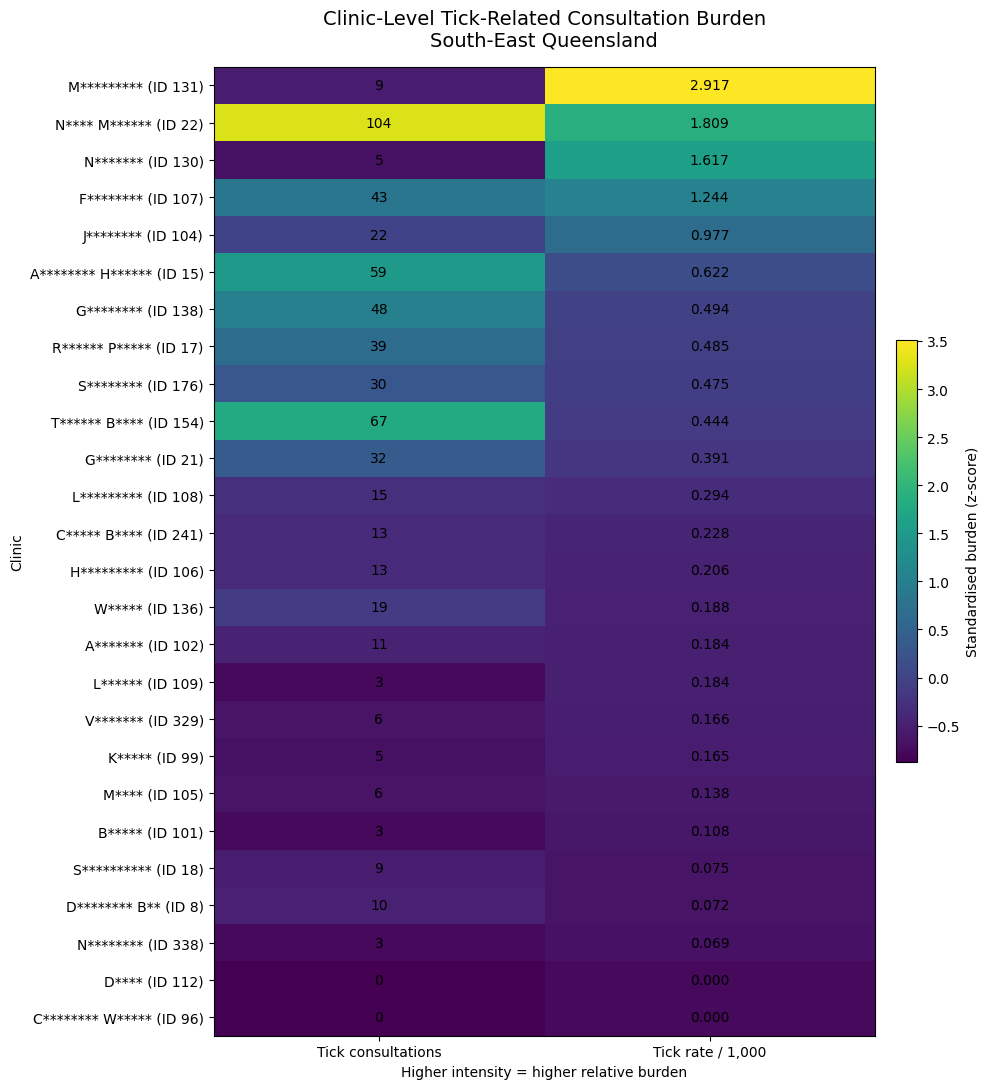


CLINIC BURDEN RANKING


,ClinicID,SuburbName,Weeks,Total_Consultations,Tick_Consultations,Tick_per_1000
0,131,M*********,12,3085,9.0,2.917
1,22,N**** M******,186,57490,104.0,1.809
2,130,N*******,14,3093,5.0,1.617
3,107,F********,110,34563,43.0,1.244
4,104,J********,110,22524,22.0,0.977
5,15,A******** H******,157,94838,59.0,0.622
6,138,G********,109,97229,48.0,0.494
7,17,R****** P*****,157,80384,39.0,0.485
8,176,S********,109,63215,30.0,0.475
9,154,T****** B****,109,151063,67.0,0.444


In [123]:
# ============================================================
# STEP 3 — CLINIC-LEVEL TICK BURDEN HEATMAP
# Full consultation-available cohort
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Prepare plotting table
# ------------------------------------------------------------

burden_plot = clinic_weekly_summary.copy()

# Create readable clinic labels
if "SuburbName" in burden_plot.columns:
    burden_plot["Clinic_Label"] = (
        burden_plot["SuburbName"].astype(str)
        + " (ID "
        + burden_plot["ClinicID"].astype(str)
        + ")"
    )
else:
    burden_plot["Clinic_Label"] = (
        "Clinic "
        + burden_plot["ClinicID"].astype(str)
    )

# Sort highest rate first
burden_plot = (
    burden_plot
    .sort_values("Tick_per_1000", ascending=False)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Variables for heatmap
# ------------------------------------------------------------

heatmap_values = burden_plot[
    [
        "Tick_Consultations",
        "Tick_per_1000"
    ]
].copy()

# Standardise columns because counts and rates
# have very different numerical scales
heatmap_z = (
    heatmap_values
    - heatmap_values.mean()
) / heatmap_values.std()


# ------------------------------------------------------------
# 3. Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 11)
)

im = ax.imshow(
    heatmap_z.values,
    aspect="auto"
)

ax.set_yticks(
    np.arange(len(burden_plot))
)

ax.set_yticklabels(
    burden_plot["Clinic_Label"]
)

ax.set_xticks([0, 1])

ax.set_xticklabels(
    [
        "Tick consultations",
        "Tick rate / 1,000"
    ]
)


# ------------------------------------------------------------
# 4. Add ACTUAL values as annotations
# ------------------------------------------------------------

for i, row in burden_plot.iterrows():

    ax.text(
        0,
        i,
        f'{int(row["Tick_Consultations"])}',
        ha="center",
        va="center"
    )

    ax.text(
        1,
        i,
        f'{row["Tick_per_1000"]:.3f}',
        ha="center",
        va="center"
    )


# ------------------------------------------------------------
# 5. Formatting
# ------------------------------------------------------------

ax.set_title(
    "Clinic-Level Tick-Related Consultation Burden\n"
    "South-East Queensland",
    fontsize=14,
    pad=15
)

ax.set_xlabel(
    "Higher intensity = higher relative burden"
)

ax.set_ylabel("Clinic")

cbar = plt.colorbar(
    im,
    ax=ax,
    fraction=0.03,
    pad=0.03
)

cbar.set_label(
    "Standardised burden (z-score)"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Supporting ranking table
# ------------------------------------------------------------

print("\nCLINIC BURDEN RANKING")
print("=" * 80)

display(
    burden_plot[
        [
            "ClinicID",
            "SuburbName",
            "Weeks",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_per_1000"
        ]
    ].round({
        "Tick_per_1000": 3
    })
)

In [124]:
# ============================================================
# STEP 4 — WEATHER MAPPING AUDIT
# 26 clinics with consultation data
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Clinics currently available for analysis
# ------------------------------------------------------------

weather_audit = clinic_weekly_summary[
    [
        "ClinicID",
        "SuburbName",
        "Weeks",
        "Total_Consultations",
        "Tick_Consultations",
        "Tick_per_1000"
    ]
].copy()

weather_audit["ClinicID"] = pd.to_numeric(
    weather_audit["ClinicID"],
    errors="coerce"
).astype("Int64")


# ------------------------------------------------------------
# 2. Check whether these ClinicIDs already exist in our
#    clinic-weekly weather dataframe
# ------------------------------------------------------------

weather_ids = (
    clinic_weekly_weather["ClinicID"]
    .dropna()
    .astype(int)
    .unique()
)

weather_audit["Has_Existing_Weather"] = (
    weather_audit["ClinicID"]
    .astype(int)
    .isin(weather_ids)
)


# ------------------------------------------------------------
# 3. Get weather coverage for already-mapped clinics
# ------------------------------------------------------------

weather_coverage = (
    clinic_weekly_weather
    .copy()
)

weather_coverage["ClinicID"] = pd.to_numeric(
    weather_coverage["ClinicID"],
    errors="coerce"
).astype("Int64")

weather_coverage = (
    weather_coverage
    .groupby("ClinicID")
    .agg(
        Weather_Weeks=("Week_End", "nunique"),
        First_Weather_Week=("Week_End", "min"),
        Last_Weather_Week=("Week_End", "max"),
        Missing_Temperature=("AvgTemp_C", lambda x: x.isna().sum())
    )
    .reset_index()
)


# ------------------------------------------------------------
# 4. Merge weather coverage
# ------------------------------------------------------------

weather_audit = weather_audit.merge(
    weather_coverage,
    on="ClinicID",
    how="left"
)


# ------------------------------------------------------------
# 5. Determine overlapping consultation/weather period
# ------------------------------------------------------------

consult_dates = (
    weekly_48
    .groupby("ClinicID")
    .agg(
        First_Consult_Week=("Week_End", "min"),
        Last_Consult_Week=("Week_End", "max")
    )
    .reset_index()
)

weather_audit = weather_audit.merge(
    consult_dates,
    on="ClinicID",
    how="left"
)


# ------------------------------------------------------------
# 6. Display summary
# ------------------------------------------------------------

print("WEATHER MAPPING AUDIT")
print("=" * 80)

print(
    "Clinics with consultation data:",
    weather_audit["ClinicID"].nunique()
)

print(
    "Already mapped to local weather:",
    int(weather_audit["Has_Existing_Weather"].sum())
)

print(
    "Not yet mapped:",
    int((~weather_audit["Has_Existing_Weather"]).sum())
)


print("\nALREADY MAPPED")
print("=" * 80)

display(
    weather_audit[
        weather_audit["Has_Existing_Weather"]
    ][
        [
            "ClinicID",
            "SuburbName",
            "Weeks",
            "Tick_Consultations",
            "Tick_per_1000",
            "Weather_Weeks",
            "First_Weather_Week",
            "Last_Weather_Week"
        ]
    ].sort_values(
        "Tick_per_1000",
        ascending=False
    ).round(3)
)


print("\nNOT YET MAPPED")
print("=" * 80)

display(
    weather_audit[
        ~weather_audit["Has_Existing_Weather"]
    ][
        [
            "ClinicID",
            "SuburbName",
            "Weeks",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_per_1000"
        ]
    ].sort_values(
        "Tick_per_1000",
        ascending=False
    ).round(3)
)

WEATHER MAPPING AUDIT
Clinics with consultation data: 26
Already mapped to local weather: 22
Not yet mapped: 4

ALREADY MAPPED


,ClinicID,SuburbName,Weeks,Tick_Consultations,Tick_per_1000,Weather_Weeks,First_Weather_Week,Last_Weather_Week
1,22,N**** M******,186,104.0,1.809,259.0,2021-09-19,2026-08-30
2,130,N*******,14,5.0,1.617,259.0,2021-09-19,2026-08-30
3,107,F********,110,43.0,1.244,259.0,2021-09-19,2026-08-30
4,104,J********,110,22.0,0.977,259.0,2021-09-19,2026-08-30
5,15,A******** H******,157,59.0,0.622,259.0,2021-09-19,2026-08-30
6,138,G********,109,48.0,0.494,259.0,2021-09-19,2026-08-30
7,17,R****** P*****,157,39.0,0.485,259.0,2021-09-19,2026-08-30
10,21,G********,177,32.0,0.391,259.0,2021-09-19,2026-08-30
11,108,L*********,110,15.0,0.294,259.0,2021-09-19,2026-08-30
12,241,C***** B****,108,13.0,0.228,259.0,2021-09-19,2026-08-30



NOT YET MAPPED


,ClinicID,SuburbName,Weeks,Total_Consultations,Tick_Consultations,Tick_per_1000
0,131,M*********,12,3085,9.0,2.917
8,176,S********,109,63215,30.0,0.475
9,154,T****** B****,109,151063,67.0,0.444
13,106,H*********,110,63192,13.0,0.206


In [125]:
# ============================================================
# STEP 5 — INVESTIGATE THE 4 CLINICS WITHOUT WEATHER
# ============================================================

import pandas as pd

missing_weather_ids = [131, 176, 154, 106]

print("CLINIC REFERENCE DETAILS")
print("=" * 80)

display(
    clinic_48[
        clinic_48["ClinicID"].isin(missing_weather_ids)
    ].sort_values("ClinicID")
)

# ------------------------------------------------------------
# Check other dataframes containing ClinicID
# and possible location information
# ------------------------------------------------------------

print("\nPOSSIBLE LOCATION DATAFRAMES")
print("=" * 80)

for name, obj in globals().copy().items():

    if isinstance(obj, pd.DataFrame):

        if "ClinicID" in obj.columns:

            location_cols = [
                c for c in obj.columns
                if any(
                    word in str(c).lower()
                    for word in [
                        "suburb",
                        "location",
                        "postcode",
                        "latitude",
                        "longitude",
                        "weather"
                    ]
                )
            ]

            if location_cols:

                temp = obj[
                    pd.to_numeric(
                        obj["ClinicID"],
                        errors="coerce"
                    ).isin(missing_weather_ids)
                ]

                if len(temp) > 0:

                    print(f"\nDATAFRAME: {name}")

                    cols_to_show = (
                        ["ClinicID"] + location_cols
                    )

                    cols_to_show = list(
                        dict.fromkeys(cols_to_show)
                    )

                    display(
                        temp[cols_to_show].drop_duplicates()
                    )

CLINIC REFERENCE DETAILS


,ClinicID,SuburbName,StateCode,CountryCode
13,106,H*********,QLD,AU
24,131,M*********,QLD,AU
28,154,T****** B****,QLD,AU
29,176,S********,QLD,AU



POSSIBLE LOCATION DATAFRAMES

DATAFRAME: clinics


,ClinicID,SuburbName
13,106,H*********
24,131,M*********
28,154,T****** B****
29,176,S********



DATAFRAME: master_clinics


...

,ClinicID,SuburbName
0,131,M*********
8,176,S********
9,154,T****** B****
13,106,H*********



DATAFRAME: burden_plot


,ClinicID,SuburbName
0,131,M*********
8,176,S********
9,154,T****** B****
13,106,H*********



DATAFRAME: weather_audit


,ClinicID,SuburbName,Has_Existing_Weather,Weather_Weeks,First_Weather_Week,Last_Weather_Week
0,131,M*********,False,NaN,NaT,NaT
8,176,S********,False,NaN,NaT,NaT
9,154,T****** B****,False,NaN,NaT,NaT
13,106,H*********,False,NaN,NaT,NaT


In [126]:
# ============================================================
# STEP 5B — ADD CONFIRMED HELENSVALE WEATHER FOR CLINIC 106
# ============================================================

clinic_106_mapping = pd.DataFrame({
    "ClinicID": [106],
    "Suburb": ["Helensvale"],
    "Postcode": [4212],
    "WeatherLocationID": ["Weather_14"],
    "latitude": [-27.869823],
    "longitude": [153.360694]
})

print("Confirmed additional SEQ weather mapping:")
display(clinic_106_mapping)

print("\nClinic 131 remains ambiguous:")
display(
    resolved_candidates[
        resolved_candidates["ClinicID"] == 131
    ][
        [
            "ClinicID",
            "SuburbName",
            "Suburb",
            "Postcode",
            "WeatherLocationID",
            "latitude",
            "longitude"
        ]
    ]
)

Confirmed additional SEQ weather mapping:


,ClinicID,Suburb,Postcode,WeatherLocationID,latitude,longitude
0,106,Helensvale,4212,Weather_14,-27.869823,153.360694



Clinic 131 remains ambiguous:


,ClinicID,SuburbName,Suburb,Postcode,WeatherLocationID,latitude,longitude
20,131,M*********,Molendinar,4214.0,Weather_19,-27.967005,153.365576
21,131,M*********,Morayfield,4506.0,Weather_23,-27.128401,152.936289


In [127]:
# ============================================================
# STEP 6 — BUILD EXPANDED SEQ CLINIC + WEATHER PANEL
# Add confirmed Clinic 106 → Helensvale → Weather_14
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Existing clinic-weather panel
# ------------------------------------------------------------

weather_existing = clinic_weekly_weather.copy()

weather_existing["ClinicID"] = pd.to_numeric(
    weather_existing["ClinicID"],
    errors="coerce"
).astype("Int64")

weather_existing["Week_End"] = pd.to_datetime(
    weather_existing["Week_End"]
)


# ------------------------------------------------------------
# 2. Get Weather_14 weekly weather for Clinic 106
# ------------------------------------------------------------

weather_106 = (
    weekly_weather_extended[
        weekly_weather_extended["WeatherLocationID"] == "Weather_14"
    ]
    .copy()
)

weather_106["ClinicID"] = 106
weather_106["Suburb"] = "Helensvale"


# ------------------------------------------------------------
# 3. Keep columns compatible with existing weather panel
# ------------------------------------------------------------

common_cols = [
    c for c in weather_existing.columns
    if c in weather_106.columns
]

weather_106 = weather_106[common_cols].copy()


# ------------------------------------------------------------
# 4. Combine
# ------------------------------------------------------------

clinic_weather_expanded = pd.concat(
    [
        weather_existing,
        weather_106
    ],
    ignore_index=True
)

clinic_weather_expanded = (
    clinic_weather_expanded
    .drop_duplicates(
        subset=["ClinicID", "Week_End"],
        keep="first"
    )
)


# ------------------------------------------------------------
# 5. Merge with our CORRECT aligned consultation/tick panel
# ------------------------------------------------------------

seq_weather_panel = weekly_48.merge(
    clinic_weather_expanded,
    on=["ClinicID", "Week_End"],
    how="inner"
)


# ------------------------------------------------------------
# 6. Validate
# ------------------------------------------------------------

print("EXPANDED SEQ WEATHER PANEL")
print("=" * 75)

print(
    "Clinics:",
    seq_weather_panel["ClinicID"].nunique()
)

print(
    "Clinic IDs:",
    sorted(
        seq_weather_panel["ClinicID"]
        .dropna()
        .astype(int)
        .unique()
    )
)

print(
    "Rows:",
    len(seq_weather_panel)
)

print(
    "Period:",
    seq_weather_panel["Week_End"].min(),
    "to",
    seq_weather_panel["Week_End"].max()
)

print(
    "Total consultations:",
    int(seq_weather_panel["Total_Consultations"].sum())
)

print(
    "Tick consultations:",
    int(seq_weather_panel["Tick_Consultations"].sum())
)

print(
    "Missing temperature:",
    seq_weather_panel["AvgTemp_C"].isna().sum()
)


# ------------------------------------------------------------
# 7. Clinic-level coverage
# ------------------------------------------------------------

seq_weather_coverage = (
    seq_weather_panel
    .groupby("ClinicID")
    .agg(
        Weeks=("Week_End", "nunique"),
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum"),
        First_Week=("Week_End", "min"),
        Last_Week=("Week_End", "max")
    )
    .reset_index()
)

seq_weather_coverage["Tick_per_1000"] = (
    seq_weather_coverage["Tick_Consultations"]
    / seq_weather_coverage["Total_Consultations"]
    * 1000
)

seq_weather_coverage = (
    seq_weather_coverage
    .sort_values("Tick_per_1000", ascending=False)
)

display(
    seq_weather_coverage.round({
        "Tick_per_1000": 3
    })
)

EXPANDED SEQ WEATHER PANEL
Clinics: 23
Clinic IDs: [np.int64(8), np.int64(15), np.int64(17), np.int64(18), np.int64(21), np.int64(22), np.int64(96), np.int64(99), np.int64(101), np.int64(102), np.int64(104), np.int64(105), np.int64(106), np.int64(107), np.int64(108), np.int64(109), np.int64(112), np.int64(130), np.int64(136), np.int64(138), np.int64(241), np.int64(329), np.int64(338)]
Rows: 2566
Period: 2021-10-03 00:00:00 to 2026-07-26 00:00:00
Total consultations: 1260332
Tick consultations: 468
Missing temperature: 0


,ClinicID,Weeks,Total_Consultations,Tick_Consultations,First_Week,Last_Week,Tick_per_1000
5,22,186,57490,104.0,2021-10-03,2026-07-26,1.809
17,130,14,3093,5.0,2023-03-05,2023-11-05,1.617
13,107,110,34563,43.0,2021-10-03,2023-11-05,1.244
10,104,110,22524,22.0,2021-10-03,2023-11-05,0.977
1,15,157,94838,59.0,2023-07-30,2026-07-26,0.622
19,138,109,97229,48.0,2021-10-03,2023-10-29,0.494
2,17,157,80384,39.0,2023-07-30,2026-07-26,0.485
4,21,177,81891,32.0,2021-10-03,2026-07-26,0.391
14,108,110,51000,15.0,2021-10-03,2023-11-05,0.294
20,241,108,57122,13.0,2021-10-03,2023-10-29,0.228


In [128]:
# ============================================================
# FIX — ADD CLINIC 106 (HELENSVALE) WEATHER PROPERLY
# ============================================================

# First inspect Weather_14
weather_14 = (
    weekly_weather_extended[
        weekly_weather_extended["WeatherLocationID"] == "Weather_14"
    ]
    .copy()
)

print("Weather_14 rows:", len(weather_14))
print("Weather_14 columns:", weather_14.columns.tolist())

display(weather_14.head())


# ------------------------------------------------------------
# Build Clinic 106 weather explicitly
# ------------------------------------------------------------

weather_106 = weather_14.copy()

weather_106["ClinicID"] = 106
weather_106["Suburb"] = "Helensvale"

weather_106["ClinicID"] = (
    pd.to_numeric(
        weather_106["ClinicID"],
        errors="coerce"
    )
    .astype("Int64")
)

weather_106["Week_End"] = pd.to_datetime(
    weather_106["Week_End"]
)


# ------------------------------------------------------------
# Check Clinic 106 consultation coverage
# ------------------------------------------------------------

consult_106 = weekly_48[
    weekly_48["ClinicID"] == 106
].copy()

print("\nClinic 106 consultation weeks:", len(consult_106))

if len(consult_106) > 0:
    print(
        "Consultation period:",
        consult_106["Week_End"].min(),
        "to",
        consult_106["Week_End"].max()
    )

    print(
        "Total consultations:",
        int(consult_106["Total_Consultations"].sum())
    )

    print(
        "Tick consultations:",
        int(consult_106["Tick_Consultations"].sum())
    )


# ------------------------------------------------------------
# Merge Clinic 106 consultations directly with Weather_14
# ------------------------------------------------------------

clinic_106_panel = consult_106.merge(
    weather_106[
        [
            "ClinicID",
            "Week_End",
            "WeatherLocationID",
            "AvgTemp_C",
            "Rainfall_mm",
            "Humidity_pct"
        ]
    ],
    on=["ClinicID", "Week_End"],
    how="inner"
)

print("\nClinic 106 matched weather rows:", len(clinic_106_panel))

if len(clinic_106_panel) > 0:
    print(
        "Matched period:",
        clinic_106_panel["Week_End"].min(),
        "to",
        clinic_106_panel["Week_End"].max()
    )

    print(
        "Missing temperature:",
        clinic_106_panel["AvgTemp_C"].isna().sum()
    )

display(clinic_106_panel.head())

Weather_14 rows: 259
Weather_14 columns: ['WeatherLocationID', 'Week_End', 'AvgTemp_C', 'Rainfall_mm', 'Humidity_pct']


,WeatherLocationID,Week_End,AvgTemp_C,Rainfall_mm,Humidity_pct
3367,Weather_14,2021-09-19,17.480000,0.7,66.966667
3368,Weather_14,2021-09-26,18.357143,1.8,64.428571
3369,Weather_14,2021-10-03,18.728571,14.0,70.077381
3370,Weather_14,2021-10-10,20.571429,0.8,64.684524
3371,Weather_14,2021-10-17,19.742857,95.0,74.369048



Clinic 106 consultation weeks: 110
Consultation period: 2021-10-03 00:00:00 to 2023-11-05 00:00:00
Total consultations: 63192
Tick consultations: 13

Clinic 106 matched weather rows: 110
Matched period: 2021-10-03 00:00:00 to 2023-11-05 00:00:00
Missing temperature: 0


,ClinicID,Week_End,Total_Consultations,Tick_Consultations,Tick_Rate,Tick_per_1000,WeatherLocationID,AvgTemp_C,Rainfall_mm,Humidity_pct
0,106,2021-10-03,132,0.0,0.0,0.0,Weather_14,18.728571,14.0,70.077381
1,106,2021-10-10,489,0.0,0.0,0.0,Weather_14,20.571429,0.8,64.684524
2,106,2021-10-17,511,0.0,0.0,0.0,Weather_14,19.742857,95.0,74.369048
3,106,2021-10-24,465,0.0,0.0,0.0,Weather_14,20.571429,14.6,82.232143
4,106,2021-10-31,517,0.0,0.0,0.0,Weather_14,21.785714,57.7,82.029762


In [129]:
# ============================================================
# STEP 6A — DOWNLOAD MISSING WEATHER_14 (HELENSVALE)
# Same methodology as existing extended weather
# ============================================================

import requests
import pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": -27.869823,
    "longitude": 153.360694,
    "start_date": "2021-09-15",
    "end_date": "2026-08-26",
    "daily": [
        "temperature_2m_mean",
        "precipitation_sum"
    ],
    "hourly": [
        "relative_humidity_2m"
    ],
    "timezone": "Australia/Brisbane"
}

response = requests.get(
    url,
    params=params,
    timeout=60
)

response.raise_for_status()

data = response.json()


# ------------------------------------------------------------
# DAILY temperature + rainfall
# ------------------------------------------------------------

daily = pd.DataFrame({
    "Date": pd.to_datetime(data["daily"]["time"]),
    "AvgTemp_C": data["daily"]["temperature_2m_mean"],
    "Rainfall_mm": data["daily"]["precipitation_sum"]
})


# ------------------------------------------------------------
# HOURLY humidity -> daily mean humidity
# ------------------------------------------------------------

hourly = pd.DataFrame({
    "DateTime": pd.to_datetime(data["hourly"]["time"]),
    "Humidity_pct": data["hourly"]["relative_humidity_2m"]
})

hourly["Date"] = hourly["DateTime"].dt.normalize()

daily_humidity = (
    hourly
    .groupby("Date", as_index=False)
    .agg(
        Humidity_pct=("Humidity_pct", "mean")
    )
)


# ------------------------------------------------------------
# Combine daily weather
# ------------------------------------------------------------

weather14_daily = daily.merge(
    daily_humidity,
    on="Date",
    how="left"
)

weather14_daily["WeatherLocationID"] = "Weather_14"


# ------------------------------------------------------------
# Convert to weekly W-SUN
# ------------------------------------------------------------

weather14_daily["Week_End"] = (
    weather14_daily["Date"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

weather14_weekly = (
    weather14_daily
    .groupby(
        ["WeatherLocationID", "Week_End"],
        as_index=False
    )
    .agg(
        AvgTemp_C=("AvgTemp_C", "mean"),
        Rainfall_mm=("Rainfall_mm", "sum"),
        Humidity_pct=("Humidity_pct", "mean")
    )
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("WEATHER_14 — HELENSVALE")
print("=" * 70)

print("Daily rows:", len(weather14_daily))
print("Weekly rows:", len(weather14_weekly))

print(
    "Period:",
    weather14_weekly["Week_End"].min(),
    "to",
    weather14_weekly["Week_End"].max()
)

print(
    "Missing temperature:",
    weather14_weekly["AvgTemp_C"].isna().sum()
)

print(
    "Missing rainfall:",
    weather14_weekly["Rainfall_mm"].isna().sum()
)

print(
    "Missing humidity:",
    weather14_weekly["Humidity_pct"].isna().sum()
)

display(weather14_weekly.head())

WEATHER_14 — HELENSVALE
Daily rows: 1807
Weekly rows: 259
Period: 2021-09-19 00:00:00 to 2026-08-30 00:00:00
Missing temperature: 0
Missing rainfall: 0
Missing humidity: 0


,WeatherLocationID,Week_End,AvgTemp_C,Rainfall_mm,Humidity_pct
0,Weather_14,2021-09-19,17.480000,0.7,66.966667
1,Weather_14,2021-09-26,18.357143,1.8,64.428571
2,Weather_14,2021-10-03,18.728571,14.0,70.077381
3,Weather_14,2021-10-10,20.571429,0.8,64.684524
4,Weather_14,2021-10-17,19.742857,95.0,74.369048


In [130]:
# ============================================================
# STEP 6B — ADD WEATHER_14 + CLINIC 106 TO WEATHER PANEL
# ============================================================

# 1. Add Weather_14 to extended weather data
weekly_weather_extended = pd.concat(
    [
        weekly_weather_extended[
            weekly_weather_extended["WeatherLocationID"] != "Weather_14"
        ],
        weather14_weekly
    ],
    ignore_index=True
)

weekly_weather_extended = (
    weekly_weather_extended
    .drop_duplicates(
        subset=["WeatherLocationID", "Week_End"]
    )
    .sort_values(
        ["WeatherLocationID", "Week_End"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Build Clinic 106 weather from Weather_14
# ------------------------------------------------------------

weather_106 = (
    weather14_weekly.copy()
)

weather_106["ClinicID"] = 106
weather_106["Suburb"] = "Helensvale"

weather_106["ClinicID"] = (
    weather_106["ClinicID"]
    .astype("Int64")
)


# ------------------------------------------------------------
# 3. Add Clinic 106 to existing clinic-weather panel
# ------------------------------------------------------------

clinic_weather_expanded = (
    clinic_weekly_weather.copy()
)

clinic_weather_expanded["ClinicID"] = pd.to_numeric(
    clinic_weather_expanded["ClinicID"],
    errors="coerce"
).astype("Int64")

# Remove any old 106 rows just in case
clinic_weather_expanded = clinic_weather_expanded[
    clinic_weather_expanded["ClinicID"] != 106
].copy()

# Use only columns required for modelling
weather_cols = [
    "ClinicID",
    "Week_End",
    "AvgTemp_C",
    "Rainfall_mm",
    "Humidity_pct"
]

clinic_weather_expanded = pd.concat(
    [
        clinic_weather_expanded[weather_cols],
        weather_106[weather_cols]
    ],
    ignore_index=True
)

clinic_weather_expanded = (
    clinic_weather_expanded
    .drop_duplicates(
        subset=["ClinicID", "Week_End"]
    )
)


# ------------------------------------------------------------
# 4. Rebuild consultation + tick + weather panel
# ------------------------------------------------------------

seq_weather_panel = weekly_48.merge(
    clinic_weather_expanded,
    on=["ClinicID", "Week_End"],
    how="inner"
)


# ------------------------------------------------------------
# 5. Validation
# ------------------------------------------------------------

print("FINAL EXPANDED SEQ WEATHER PANEL")
print("=" * 75)

print(
    "Clinics:",
    seq_weather_panel["ClinicID"].nunique()
)

print(
    "Clinic IDs:",
    sorted(
        seq_weather_panel["ClinicID"]
        .astype(int)
        .unique()
    )
)

print(
    "Rows:",
    len(seq_weather_panel)
)

print(
    "Period:",
    seq_weather_panel["Week_End"].min(),
    "to",
    seq_weather_panel["Week_End"].max()
)

print(
    "Total consultations:",
    int(seq_weather_panel["Total_Consultations"].sum())
)

print(
    "Tick consultations:",
    int(seq_weather_panel["Tick_Consultations"].sum())
)

print(
    "Missing temperature:",
    seq_weather_panel["AvgTemp_C"].isna().sum()
)


# ------------------------------------------------------------
# 6. Confirm Clinic 106 specifically
# ------------------------------------------------------------

check_106 = seq_weather_panel[
    seq_weather_panel["ClinicID"] == 106
]

print("\nCLINIC 106 — HELENSVALE")
print("=" * 75)

print("Matched weeks:", len(check_106))
print(
    "Consultations:",
    int(check_106["Total_Consultations"].sum())
)
print(
    "Tick consultations:",
    int(check_106["Tick_Consultations"].sum())
)
print(
    "Missing temperature:",
    check_106["AvgTemp_C"].isna().sum()
)

FINAL EXPANDED SEQ WEATHER PANEL
Clinics: 23
Clinic IDs: [np.int64(8), np.int64(15), np.int64(17), np.int64(18), np.int64(21), np.int64(22), np.int64(96), np.int64(99), np.int64(101), np.int64(102), np.int64(104), np.int64(105), np.int64(106), np.int64(107), np.int64(108), np.int64(109), np.int64(112), np.int64(130), np.int64(136), np.int64(138), np.int64(241), np.int64(329), np.int64(338)]
Rows: 2566
Period: 2021-10-03 00:00:00 to 2026-07-26 00:00:00
Total consultations: 1260332
Tick consultations: 468
Missing temperature: 0

CLINIC 106 — HELENSVALE
Matched weeks: 110
Consultations: 63192
Tick consultations: 13
Missing temperature: 0


In [131]:
# ============================================================
# STEP 7 — CLINIC-LEVEL TEMPERATURE LEAD ANALYSIS
# Week 8-style seasonality adjustment
# Eligibility: >= 100 overlapping weeks
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import spearmanr

# ------------------------------------------------------------
# 1. Determine eligible clinics
# ------------------------------------------------------------

coverage = (
    seq_weather_panel
    .groupby("ClinicID")
    .agg(
        Weeks=("Week_End", "nunique"),
        Tick_Consultations=("Tick_Consultations", "sum"),
        Total_Consultations=("Total_Consultations", "sum")
    )
    .reset_index()
)

eligible_ids = (
    coverage.loc[
        coverage["Weeks"] >= 100,
        "ClinicID"
    ]
    .tolist()
)

temp_analysis = (
    seq_weather_panel[
        seq_weather_panel["ClinicID"].isin(eligible_ids)
    ]
    .copy()
)

print("TEMPERATURE ANALYSIS COHORT")
print("=" * 70)
print("Clinics:", temp_analysis["ClinicID"].nunique())
print("Rows:", len(temp_analysis))
print(
    "Period:",
    temp_analysis["Week_End"].min(),
    "to",
    temp_analysis["Week_End"].max()
)


# ------------------------------------------------------------
# 2. Seasonal terms
# ------------------------------------------------------------

temp_analysis["WeekOfYear"] = (
    temp_analysis["Week_End"]
    .dt.isocalendar()
    .week
    .astype(int)
)

temp_analysis["Season_Sin"] = np.sin(
    2 * np.pi * temp_analysis["WeekOfYear"] / 52.18
)

temp_analysis["Season_Cos"] = np.cos(
    2 * np.pi * temp_analysis["WeekOfYear"] / 52.18
)


# ------------------------------------------------------------
# 3. Calculate tick consultation rate
# ------------------------------------------------------------

temp_analysis["Tick_per_1000"] = (
    temp_analysis["Tick_Consultations"]
    / temp_analysis["Total_Consultations"]
    * 1000
)


# ------------------------------------------------------------
# 4. Remove annual seasonality separately within each clinic
# ------------------------------------------------------------

def seasonal_residuals(group, variable):

    X = group[
        ["Season_Sin", "Season_Cos"]
    ].copy()

    X = sm.add_constant(X)

    y = group[variable].astype(float)

    model = sm.OLS(
        y,
        X,
        missing="drop"
    ).fit()

    return y - model.predict(X)


temp_analysis = (
    temp_analysis
    .sort_values(["ClinicID", "Week_End"])
    .reset_index(drop=True)
)

temp_analysis["Temp_Anomaly"] = (
    temp_analysis
    .groupby("ClinicID", group_keys=False)
    .apply(
        lambda g: seasonal_residuals(
            g,
            "AvgTemp_C"
        ),
        include_groups=False
    )
    .reset_index(level=0, drop=True)
)

temp_analysis["Tick_Anomaly"] = (
    temp_analysis
    .groupby("ClinicID", group_keys=False)
    .apply(
        lambda g: seasonal_residuals(
            g,
            "Tick_per_1000"
        ),
        include_groups=False
    )
    .reset_index(level=0, drop=True)
)


# ------------------------------------------------------------
# 5. Clinic-specific +1 and +2 week correlations
# Temperature this week vs tick anomaly in future weeks
# ------------------------------------------------------------

results = []

for clinic_id, g in temp_analysis.groupby("ClinicID"):

    g = g.sort_values("Week_End").copy()

    # Future tick demand
    g["Tick_1w_Later"] = g["Tick_Anomaly"].shift(-1)
    g["Tick_2w_Later"] = g["Tick_Anomaly"].shift(-2)

    # +1 week
    valid1 = g[
        ["Temp_Anomaly", "Tick_1w_Later"]
    ].dropna()

    rho1, p1 = spearmanr(
        valid1["Temp_Anomaly"],
        valid1["Tick_1w_Later"]
    )

    # +2 weeks
    valid2 = g[
        ["Temp_Anomaly", "Tick_2w_Later"]
    ].dropna()

    rho2, p2 = spearmanr(
        valid2["Temp_Anomaly"],
        valid2["Tick_2w_Later"]
    )

    results.append({
        "ClinicID": clinic_id,
        "Weeks": len(g),
        "Tick_Consultations": g["Tick_Consultations"].sum(),

        "Temp_Rho_1w": rho1,
        "Temp_P_1w": p1,

        "Temp_Rho_2w": rho2,
        "Temp_P_2w": p2
    })


clinic_temperature_results_new = pd.DataFrame(results)


# ------------------------------------------------------------
# 6. Add clinic names
# ------------------------------------------------------------

clinic_names = (
    clinic_48[
        ["ClinicID", "SuburbName"]
    ]
    .drop_duplicates("ClinicID")
)

clinic_temperature_results_new = (
    clinic_temperature_results_new
    .merge(
        clinic_names,
        on="ClinicID",
        how="left"
    )
)


# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

positive_1w = (
    clinic_temperature_results_new["Temp_Rho_1w"] > 0
).sum()

positive_2w = (
    clinic_temperature_results_new["Temp_Rho_2w"] > 0
).sum()

n_clinics = len(clinic_temperature_results_new)

print("\nTEMPERATURE LEAD RESULTS")
print("=" * 70)

print(
    f"+1 week positive: "
    f"{positive_1w}/{n_clinics} "
    f"({positive_1w/n_clinics*100:.1f}%)"
)

print(
    f"+2 weeks positive: "
    f"{positive_2w}/{n_clinics} "
    f"({positive_2w/n_clinics*100:.1f}%)"
)

print(
    "Median rho +1 week:",
    round(
        clinic_temperature_results_new[
            "Temp_Rho_1w"
        ].median(),
        3
    )
)

print(
    "Median rho +2 weeks:",
    round(
        clinic_temperature_results_new[
            "Temp_Rho_2w"
        ].median(),
        3
    )
)

display(
    clinic_temperature_results_new[
        [
            "ClinicID",
            "SuburbName",
            "Weeks",
            "Tick_Consultations",
            "Temp_Rho_1w",
            "Temp_P_1w",
            "Temp_Rho_2w",
            "Temp_P_2w"
        ]
    ]
    .sort_values(
        "Temp_Rho_1w",
        ascending=False
    )
    .round(3)
)

TEMPERATURE ANALYSIS COHORT
Clinics: 19
Rows: 2496
Period: 2021-10-03 00:00:00 to 2026-07-26 00:00:00

TEMPERATURE LEAD RESULTS
+1 week positive: 17/19 (89.5%)
+2 weeks positive: 18/19 (94.7%)
Median rho +1 week: 0.073
Median rho +2 weeks: 0.091


,ClinicID,SuburbName,Weeks,Tick_Consultations,Temp_Rho_1w,Temp_P_1w,Temp_Rho_2w,Temp_P_2w
15,138,G********,109,48.0,0.350,0.000,0.171,0.079
9,104,J********,110,22.0,0.191,0.047,0.165,0.088
16,241,C***** B****,108,13.0,0.188,0.053,0.147,0.133
13,108,L*********,110,15.0,0.135,0.163,0.192,0.046
14,136,W*****,109,19.0,0.095,0.328,0.093,0.338
7,101,B*****,110,3.0,0.083,0.388,0.091,0.348
0,8,D******** B**,240,10.0,0.083,0.201,0.094,0.150
10,105,M****,110,6.0,0.074,0.443,0.086,0.376
2,17,R****** P*****,157,39.0,0.073,0.363,0.078,0.337
4,21,G********,177,32.0,0.073,0.336,0.153,0.043


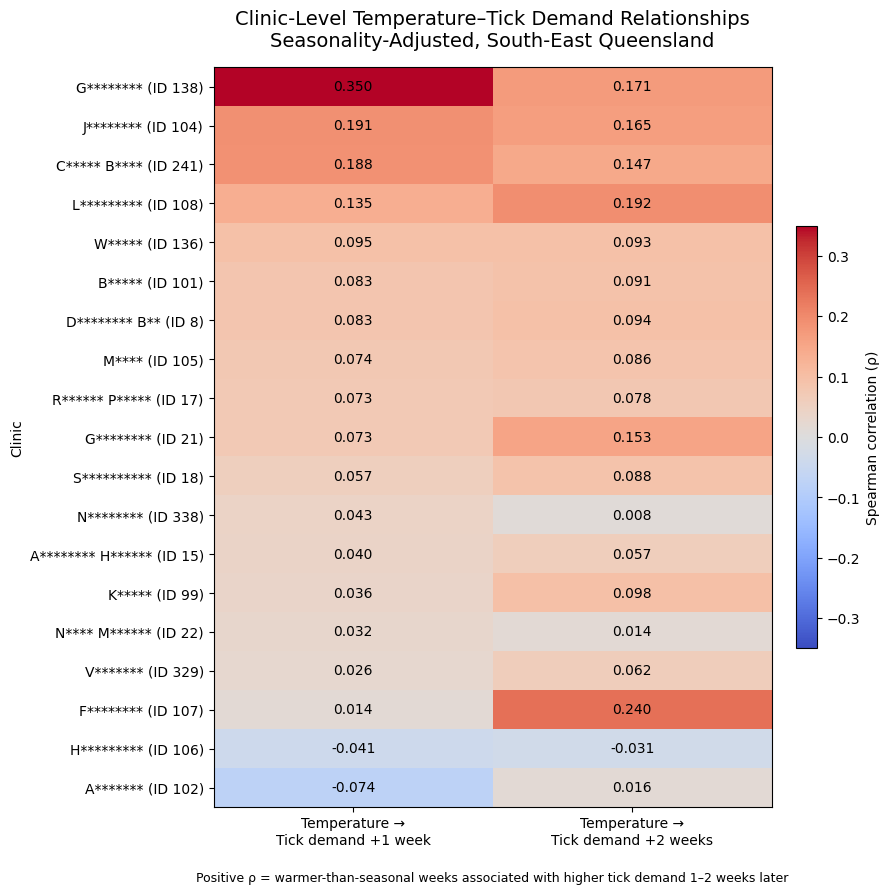

TEMPERATURE HEATMAP SUMMARY
+1 week: 17/19 clinics positive (89.5%)
+2 weeks: 18/19 clinics positive (94.7%)
Median rho +1 week: 0.073
Median rho +2 weeks: 0.091


In [132]:
# ============================================================
# STEP 8 — CLINIC-LEVEL TEMPERATURE LEAD HEATMAP
# Seasonality-adjusted +1 and +2 week relationships
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Prepare results
# ------------------------------------------------------------

heatmap_df = (
    clinic_temperature_results_new
    .copy()
    .sort_values(
        "Temp_Rho_1w",
        ascending=False
    )
    .reset_index(drop=True)
)

# Readable labels
heatmap_df["Clinic_Label"] = (
    heatmap_df["SuburbName"].astype(str)
    + " (ID "
    + heatmap_df["ClinicID"].astype(str)
    + ")"
)

values = heatmap_df[
    ["Temp_Rho_1w", "Temp_Rho_2w"]
].to_numpy()


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 9))

# Fixed scale so positive/negative correlations
# are visually comparable
limit = max(
    abs(np.nanmin(values)),
    abs(np.nanmax(values))
)

im = ax.imshow(
    values,
    aspect="auto",
    vmin=-limit,
    vmax=limit,
    cmap="coolwarm"
)

ax.set_yticks(
    np.arange(len(heatmap_df))
)

ax.set_yticklabels(
    heatmap_df["Clinic_Label"]
)

ax.set_xticks([0, 1])

ax.set_xticklabels([
    "Temperature →\nTick demand +1 week",
    "Temperature →\nTick demand +2 weeks"
])


# ------------------------------------------------------------
# Add correlation values
# ------------------------------------------------------------

for i in range(len(heatmap_df)):
    for j in range(2):

        value = values[i, j]

        ax.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center"
        )


# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.set_title(
    "Clinic-Level Temperature–Tick Demand Relationships\n"
    "Seasonality-Adjusted, South-East Queensland",
    fontsize=14,
    pad=15
)

ax.set_ylabel("Clinic")

cbar = plt.colorbar(
    im,
    ax=ax,
    fraction=0.035,
    pad=0.04
)

cbar.set_label("Spearman correlation (ρ)")

# Zero-reference meaning
ax.text(
    0.5,
    -0.10,
    "Positive ρ = warmer-than-seasonal weeks associated with "
    "higher tick demand 1–2 weeks later",
    transform=ax.transAxes,
    ha="center",
    fontsize=9
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Summary for report
# ------------------------------------------------------------

n = len(heatmap_df)

pos1 = (heatmap_df["Temp_Rho_1w"] > 0).sum()
pos2 = (heatmap_df["Temp_Rho_2w"] > 0).sum()

print("TEMPERATURE HEATMAP SUMMARY")
print("=" * 70)

print(
    f"+1 week: {pos1}/{n} clinics positive "
    f"({pos1/n*100:.1f}%)"
)

print(
    f"+2 weeks: {pos2}/{n} clinics positive "
    f"({pos2/n*100:.1f}%)"
)

print(
    f"Median rho +1 week: "
    f"{heatmap_df['Temp_Rho_1w'].median():.3f}"
)

print(
    f"Median rho +2 weeks: "
    f"{heatmap_df['Temp_Rho_2w'].median():.3f}"
)

In [133]:
# ============================================================
# STEP 9 — BUILD FINAL BINOMIAL MODELLING DATASET
# Outcome: tick consultations / total consultations
# Predictors: seasonality + clinic + temperature + Google
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Start from the cleaned consultation + weather panel
# ------------------------------------------------------------

final_binomial = seq_weather_panel.copy()

final_binomial["Week_End"] = pd.to_datetime(
    final_binomial["Week_End"]
)


# ------------------------------------------------------------
# 2. Create annual seasonal terms
# ------------------------------------------------------------

final_binomial["WeekOfYear"] = (
    final_binomial["Week_End"]
    .dt.isocalendar()
    .week
    .astype(int)
)

final_binomial["Season_Sin"] = np.sin(
    2 * np.pi * final_binomial["WeekOfYear"] / 52.18
)

final_binomial["Season_Cos"] = np.cos(
    2 * np.pi * final_binomial["WeekOfYear"] / 52.18
)


# ------------------------------------------------------------
# 3. Inspect Google dataframe(s) currently in notebook
# ------------------------------------------------------------

print("POSSIBLE GOOGLE DATAFRAMES")
print("=" * 75)

for name, obj in list(globals().items()):

    if isinstance(obj, pd.DataFrame):

        google_cols = [
            str(c) for c in obj.columns
            if any(
                word in str(c).lower()
                for word in [
                    "google",
                    "search",
                    "trend",
                    "index"
                ]
            )
        ]

        if google_cols:
            print(f"\n{name}")
            print("Shape:", obj.shape)
            print("Columns:", obj.columns.tolist())

            display(obj.head(3))


# ------------------------------------------------------------
# 4. Current binomial base validation
# ------------------------------------------------------------

print("\nBINOMIAL BASE BEFORE GOOGLE")
print("=" * 75)

print(
    "Clinics:",
    final_binomial["ClinicID"].nunique()
)

print(
    "Clinic-weeks:",
    len(final_binomial)
)

print(
    "Period:",
    final_binomial["Week_End"].min(),
    "to",
    final_binomial["Week_End"].max()
)

print(
    "Total consultations:",
    int(final_binomial["Total_Consultations"].sum())
)

print(
    "Tick consultations:",
    int(final_binomial["Tick_Consultations"].sum())
)

print(
    "Overall tick rate / 1,000:",
    round(
        final_binomial["Tick_Consultations"].sum()
        / final_binomial["Total_Consultations"].sum()
        * 1000,
        3
    )
)

print(
    "Missing temperature:",
    final_binomial["AvgTemp_C"].isna().sum()
)

print(
    "Invalid tick > total rows:",
    (
        final_binomial["Tick_Consultations"]
        > final_binomial["Total_Consultations"]
    ).sum()
)

POSSIBLE GOOGLE DATAFRAMES

trends
Shape: (82, 32)
Columns: ['Month', 'tick', 'tick_bite', 'tick_paralysis', 'paralysis_tick', 'tick_symptoms', 'tick_treatment', 'tick_removal', 'tick_prevention', 'tick_on_dog', 'nexgard', 'nexgard_spectra', 'nexgard_tick', 'nexgard_for_dogs', 'tick_z', 'tick_bite_z', 'tick_paralysis_z', 'paralysis_tick_z', 'tick_symptoms_z', 'tick_treatment_z', 'tick_removal_z', 'tick_prevention_z', 'tick_on_dog_z', 'nexgard_z', 'nexgard_spectra_z', 'nexgard_tick_z', 'nexgard_for_dogs_z', 'Search_Index_Z', 'Tick_Search_Index', 'Year', 'Month_Num', 'Month_Name']


,Month,tick,tick_bite,tick_paralysis,paralysis_tick,tick_symptoms,tick_treatment,tick_removal,tick_prevention,tick_on_dog,...,tick_on_dog_z,nexgard_z,nexgard_spectra_z,nexgard_tick_z,nexgard_for_dogs_z,Search_Index_Z,Tick_Search_Index,Year,Month_Num,Month_Name
0,2020-01-01,45,2,3,3,2,2,0,0,1,...,0.189702,-1.396862,-1.653426,-0.677218,-0.118161,-0.517933,19.412985,2020,1,Jan
1,2020-02-01,44,1,2,2,1,2,0,1,1,...,0.189702,-0.753364,-0.947275,-0.677218,-0.118161,-0.572524,17.492684,2020,2,Feb
2,2020-03-01,47,1,1,1,1,1,0,0,1,...,0.189702,-0.753364,-0.947275,-0.677218,-0.118161,-0.823443,8.666384,2020,3,Mar



historical
Shape: (72, 32)
Columns: ['Month', 'tick', 'tick_bite', 'tick_paralysis', 'paralysis_tick', 'tick_symptoms', 'tick_treatment', 'tick_removal', 'tick_prevention', 'tick_on_dog', 'nexgard', 'nexgard_spectra', 'nexgard_tick', 'nexgard_for_dogs', 'tick_z', 'tick_bite_z', 'tick_paralysis_z', 'paralysis_tick_z', 'tick_symptoms_z', 'tick_treatment_z', 'tick_removal_z', 'tick_prevention_z', 'tick_on_dog_z', 'nexgard_z', 'nexgard_spectra_z', 'nexgard_tick_z', 'nexgard_for_dogs_z', 'Search_Index_Z', 'Tick_Search_Index', 'Year', 'Month_Num', 'Month_Name']


,Month,tick,tick_bite,tick_paralysis,paralysis_tick,tick_symptoms,tick_treatment,tick_removal,tick_prevention,tick_on_dog,...,tick_on_dog_z,nexgard_z,nexgard_spectra_z,nexgard_tick_z,nexgard_for_dogs_z,Search_Index_Z,Tick_Search_Index,Year,Month_Num,Month_Name
0,2020-01-01,45,2,3,3,2,2,0,0,1,...,0.189702,-1.396862,-1.653426,-0.677218,-0.118161,-0.517933,19.412985,2020,1,Jan
1,2020-02-01,44,1,2,2,1,2,0,1,1,...,0.189702,-0.753364,-0.947275,-0.677218,-0.118161,-0.572524,17.492684,2020,2,Feb
2,2020-03-01,47,1,1,1,1,1,0,0,1,...,0.189702,-0.753364,-0.947275,-0.677218,-0.118161,-0.823443,8.666384,2020,3,Mar



search_2026_plot
Shape: (10, 3)
Columns: ['Month_Num', 'Month_Name', 'Tick_Search_Index']


...


binomial_google
Shape: (2461, 12)
Columns: ['ClinicID', 'Week_End', 'Total_Consultations', 'YearMonth', 'AvgTemp_C', 'Tick_Consultations', 'Tick_Rate', 'Tick_per_1000', 'WeekOfYear', 'Season_Sin', 'Season_Cos', 'Tick_Search_Index']


,ClinicID,Week_End,Total_Consultations,YearMonth,AvgTemp_C,Tick_Consultations,Tick_Rate,Tick_per_1000,WeekOfYear,Season_Sin,Season_Cos,Tick_Search_Index
0,8,2021-10-03,183,2021-10,19.385714,0.0,0.0,0.0,39,-0.999868,-0.016255,55.634678
1,8,2021-10-10,599,2021-10,21.342857,0.0,0.0,0.0,40,-0.994580,0.103970,55.634678
2,8,2021-10-17,686,2021-10,20.828571,0.0,0.0,0.0,41,-0.974890,0.222689,55.634678



model_df
Shape: (2339, 12)
Columns: ['ClinicID', 'Week_End', 'Total_Consultations', 'YearMonth', 'AvgTemp_C', 'Tick_Consultations', 'Tick_Rate', 'Tick_per_1000', 'WeekOfYear', 'Season_Sin', 'Season_Cos', 'Tick_Search_Index']


,ClinicID,Week_End,Total_Consultations,YearMonth,AvgTemp_C,Tick_Consultations,Tick_Rate,Tick_per_1000,WeekOfYear,Season_Sin,Season_Cos,Tick_Search_Index
0,8,2021-10-03,183,2021-10,19.385714,0.0,0.0,0.0,39,-0.999868,-0.016255,55.634678
1,8,2021-10-10,599,2021-10,21.342857,0.0,0.0,0.0,40,-0.994580,0.103970,55.634678
2,8,2021-10-17,686,2021-10,20.828571,0.0,0.0,0.0,41,-0.974890,0.222689,55.634678



BINOMIAL BASE BEFORE GOOGLE
Clinics: 23
Clinic-weeks: 2566
Period: 2021-10-03 00:00:00 to 2026-07-26 00:00:00
Total consultations: 1260332
Tick consultations: 468
Overall tick rate / 1,000: 0.371
Missing temperature: 0
Invalid tick > total rows: 0


In [134]:
# ============================================================
# STEP 10 — MERGE GOOGLE TRENDS INTO FINAL BINOMIAL DATA
# ============================================================

# Start fresh from our cleaned base
binomial_final = final_binomial.copy()


# ------------------------------------------------------------
# 1. Create Year-Month from weekly consultation date
# ------------------------------------------------------------

binomial_final["YearMonth"] = (
    binomial_final["Week_End"]
    .dt.to_period("M")
)


# ------------------------------------------------------------
# 2. Prepare Google monthly data
# ------------------------------------------------------------

google_for_model = google_monthly.copy()

google_for_model["YearMonth"] = (
    google_for_model["YearMonth"]
    .astype("period[M]")
)

google_for_model = (
    google_for_model[
        ["YearMonth", "Tick_Search_Index"]
    ]
    .drop_duplicates("YearMonth")
)


# ------------------------------------------------------------
# 3. Merge
# ------------------------------------------------------------

binomial_final = binomial_final.merge(
    google_for_model,
    on="YearMonth",
    how="left"
)


# ------------------------------------------------------------
# 4. Keep common complete-case observations
#    ALL four models will use these exact same rows
# ------------------------------------------------------------

model_final = (
    binomial_final
    .dropna(
        subset=[
            "Total_Consultations",
            "Tick_Consultations",
            "AvgTemp_C",
            "Season_Sin",
            "Season_Cos",
            "Tick_Search_Index"
        ]
    )
    .copy()
)


# ------------------------------------------------------------
# 5. Binomial outcome
# ------------------------------------------------------------

model_final["Tick_Rate"] = (
    model_final["Tick_Consultations"]
    / model_final["Total_Consultations"]
)

model_final["Tick_per_1000"] = (
    model_final["Tick_Rate"] * 1000
)


# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

print("FINAL BINOMIAL MODELLING DATASET")
print("=" * 75)

print(
    "Clinics:",
    model_final["ClinicID"].nunique()
)

print(
    "Clinic IDs:",
    sorted(
        model_final["ClinicID"]
        .astype(int)
        .unique()
    )
)

print(
    "Clinic-weeks:",
    len(model_final)
)

print(
    "Period:",
    model_final["Week_End"].min(),
    "to",
    model_final["Week_End"].max()
)

print(
    "Total consultations:",
    int(model_final["Total_Consultations"].sum())
)

print(
    "Tick consultations:",
    int(model_final["Tick_Consultations"].sum())
)

print(
    "Overall tick rate / 1,000:",
    round(
        model_final["Tick_Consultations"].sum()
        / model_final["Total_Consultations"].sum()
        * 1000,
        3
    )
)

print(
    "Missing Google:",
    model_final["Tick_Search_Index"].isna().sum()
)

print(
    "Google range:",
    round(model_final["Tick_Search_Index"].min(), 2),
    "to",
    round(model_final["Tick_Search_Index"].max(), 2)
)


# ------------------------------------------------------------
# 7. Clinic coverage in final model
# ------------------------------------------------------------

model_coverage = (
    model_final
    .groupby("ClinicID")
    .agg(
        Weeks=("Week_End", "nunique"),
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
    .sort_values("Weeks", ascending=False)
)

display(model_coverage)

FINAL BINOMIAL MODELLING DATASET
Clinics: 23
Clinic IDs: [np.int64(8), np.int64(15), np.int64(17), np.int64(18), np.int64(21), np.int64(22), np.int64(96), np.int64(99), np.int64(101), np.int64(102), np.int64(104), np.int64(105), np.int64(106), np.int64(107), np.int64(108), np.int64(109), np.int64(112), np.int64(130), np.int64(136), np.int64(138), np.int64(241), np.int64(329), np.int64(338)]
Clinic-weeks: 2566
Period: 2021-10-03 00:00:00 to 2026-07-26 00:00:00
Total consultations: 1260332
Tick consultations: 468
Overall tick rate / 1,000: 0.371
Missing Google: 0
Google range: 12.16 to 100.0


,ClinicID,Weeks,Total_Consultations,Tick_Consultations
0,8,240,138233,10.0
5,22,186,57490,104.0
4,21,177,81891,32.0
2,17,157,80384,39.0
3,18,157,120414,9.0
1,15,157,94838,59.0
10,104,110,22524,22.0
14,108,110,51000,15.0
13,107,110,34563,43.0
12,106,110,63192,13.0


In [135]:
# ============================================================
# STEP 11 — FINAL BINOMIAL GLM MODELS
#
# M1 = Clinic + Seasonality
# M2 = M1 + Temperature
# M3 = M1 + Google Trends
# M4 = M1 + Temperature + Google Trends
# ============================================================

import statsmodels.api as sm
import statsmodels.formula.api as smf
import pandas as pd
import numpy as np
from scipy.stats import chi2


# ------------------------------------------------------------
# 1. Make ClinicID categorical
# ------------------------------------------------------------

model_final["ClinicID"] = (
    model_final["ClinicID"]
    .astype(int)
    .astype("category")
)


# ------------------------------------------------------------
# 2. Fit models
#
# Tick_Rate = successes / total consultations
# freq_weights = number of consultations in each clinic-week
# ------------------------------------------------------------

M1 = smf.glm(
    formula=(
        "Tick_Rate ~ "
        "Season_Sin + Season_Cos + C(ClinicID)"
    ),
    data=model_final,
    family=sm.families.Binomial(),
    freq_weights=model_final["Total_Consultations"]
).fit()


M2 = smf.glm(
    formula=(
        "Tick_Rate ~ "
        "Season_Sin + Season_Cos + "
        "AvgTemp_C + C(ClinicID)"
    ),
    data=model_final,
    family=sm.families.Binomial(),
    freq_weights=model_final["Total_Consultations"]
).fit()


M3 = smf.glm(
    formula=(
        "Tick_Rate ~ "
        "Season_Sin + Season_Cos + "
        "Tick_Search_Index + C(ClinicID)"
    ),
    data=model_final,
    family=sm.families.Binomial(),
    freq_weights=model_final["Total_Consultations"]
).fit()


M4 = smf.glm(
    formula=(
        "Tick_Rate ~ "
        "Season_Sin + Season_Cos + "
        "AvgTemp_C + Tick_Search_Index + "
        "C(ClinicID)"
    ),
    data=model_final,
    family=sm.families.Binomial(),
    freq_weights=model_final["Total_Consultations"]
).fit()


# ------------------------------------------------------------
# 3. AIC comparison
# ------------------------------------------------------------

aic_table = pd.DataFrame({
    "Model": [
        "M1: Seasonality + Clinic",
        "M2: M1 + Temperature",
        "M3: M1 + Google",
        "M4: M1 + Temperature + Google"
    ],
    "AIC": [
        M1.aic,
        M2.aic,
        M3.aic,
        M4.aic
    ]
})

aic_table["Delta_AIC"] = (
    aic_table["AIC"]
    - aic_table["AIC"].min()
)

aic_table = (
    aic_table
    .sort_values("AIC")
    .reset_index(drop=True)
)

print("FINAL MODEL COMPARISON — AIC")
print("=" * 75)

display(
    aic_table.round(3)
)


# ------------------------------------------------------------
# 4. Likelihood-ratio test function
# ------------------------------------------------------------

def likelihood_ratio_test(reduced, full):

    lr_stat = 2 * (
        full.llf - reduced.llf
    )

    df_diff = (
        full.df_model
        - reduced.df_model
    )

    p_value = chi2.sf(
        lr_stat,
        df_diff
    )

    return lr_stat, df_diff, p_value


# ------------------------------------------------------------
# 5. LRT comparisons
# ------------------------------------------------------------

comparisons = [
    (
        "M1 → M2: Add temperature",
        M1,
        M2
    ),
    (
        "M1 → M3: Add Google",
        M1,
        M3
    ),
    (
        "M2 → M4: Add Google after temperature",
        M2,
        M4
    ),
    (
        "M3 → M4: Add temperature after Google",
        M3,
        M4
    )
]

lrt_results = []

for name, reduced, full in comparisons:

    lr, df_diff, p = likelihood_ratio_test(
        reduced,
        full
    )

    lrt_results.append({
        "Comparison": name,
        "LR_statistic": lr,
        "df": df_diff,
        "p_value": p
    })

lrt_table = pd.DataFrame(lrt_results)

print("\nLIKELIHOOD-RATIO TESTS")
print("=" * 75)

display(
    lrt_table.round(4)
)


# ------------------------------------------------------------
# 6. Temperature + Google effects from full model M4
# ------------------------------------------------------------

effect_rows = []

for variable, label in [
    ("AvgTemp_C", "Temperature (+1°C)"),
    ("Tick_Search_Index", "Google search index (+1 point)")
]:

    coef = M4.params[variable]
    se = M4.bse[variable]

    lower = coef - 1.96 * se
    upper = coef + 1.96 * se

    effect_rows.append({
        "Variable": label,
        "Coefficient": coef,
        "Odds_Ratio": np.exp(coef),
        "CI_Lower": np.exp(lower),
        "CI_Upper": np.exp(upper),
        "p_value": M4.pvalues[variable]
    })

effect_table = pd.DataFrame(effect_rows)

print("\nFULL MODEL M4 — EFFECT ESTIMATES")
print("=" * 75)

display(
    effect_table.round(4)
)


# ------------------------------------------------------------
# 7. Google effect per +10 index points
# Easier to interpret than +1 point
# ------------------------------------------------------------

google_coef = M4.params["Tick_Search_Index"]

google_or_10 = np.exp(
    google_coef * 10
)

print(
    "\nGoogle OR for +10 search-index points:",
    round(google_or_10, 4)
)


# ------------------------------------------------------------
# 8. Basic model information
# ------------------------------------------------------------

print("\nMODEL DATA")
print("=" * 75)

print(
    "Clinics:",
    model_final["ClinicID"].nunique()
)

print(
    "Clinic-weeks:",
    len(model_final)
)

print(
    "Consultations:",
    int(model_final["Total_Consultations"].sum())
)

print(
    "Tick consultations:",
    int(model_final["Tick_Consultations"].sum())
)

FINAL MODEL COMPARISON — AIC


,Model,AIC,Delta_AIC
0,M4: M1 + Temperature + Google,6625.221,0.000
1,M3: M1 + Google,6627.576,2.355
2,M2: M1 + Temperature,6627.768,2.547
3,M1: Seasonality + Clinic,6629.039,3.818



LIKELIHOOD-RATIO TESTS


,Comparison,LR_statistic,df,p_value
0,M1 → M2: Add temperature,3.2711,1,0.0705
1,M1 → M3: Add Google,3.4636,1,0.0627
2,M2 → M4: Add Google after temperature,4.5471,1,0.0330
3,M3 → M4: Add temperature after Google,4.3546,1,0.0369



FULL MODEL M4 — EFFECT ESTIMATES


,Variable,Coefficient,Odds_Ratio,CI_Lower,CI_Upper,p_value
0,Temperature (+1°C),-0.0768,0.9260,0.8614,0.9956,0.0375
1,Google search index (+1 point),0.0064,1.0064,1.0005,1.0123,0.0338



Google OR for +10 search-index points: 1.0657

MODEL DATA
Clinics: 23
Clinic-weeks: 2566
Consultations: 1260332
Tick consultations: 468


In [136]:
# ============================================================
# STEP 12 — BUILD FINAL RIDGE FORECASTING DATASET
# Target: tick-related consultation rate 2 weeks ahead
# Cohort: clinics with >= 100 weeks
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Use the same eligible longitudinal clinics
# ------------------------------------------------------------

ridge_ids = (
    coverage.loc[
        coverage["Weeks"] >= 100,
        "ClinicID"
    ]
    .astype(int)
    .tolist()
)

ridge_df = (
    model_final[
        model_final["ClinicID"]
        .astype(int)
        .isin(ridge_ids)
    ]
    .copy()
)

ridge_df["ClinicID"] = (
    ridge_df["ClinicID"]
    .astype(int)
)

ridge_df = (
    ridge_df
    .sort_values(
        ["ClinicID", "Week_End"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Current tick consultation rate / 1,000
# ------------------------------------------------------------

ridge_df["Tick_Current"] = (
    ridge_df["Tick_Consultations"]
    / ridge_df["Total_Consultations"]
    * 1000
)


# ------------------------------------------------------------
# 3. Historical tick-demand features
# ------------------------------------------------------------

for lag in range(1, 5):

    ridge_df[f"Tick_Lag_{lag}"] = (
        ridge_df
        .groupby("ClinicID")["Tick_Current"]
        .shift(lag)
    )


# Previous 4 completed weeks
ridge_df["Tick_Prev4w_Avg"] = (
    ridge_df
    .groupby("ClinicID")["Tick_Current"]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(
            window=4,
            min_periods=4
        )
        .mean()
    )
)


# ------------------------------------------------------------
# 4. Two-week-ahead target
# ------------------------------------------------------------

ridge_df["Target_2w"] = (
    ridge_df
    .groupby("ClinicID")["Tick_Current"]
    .shift(-2)
)


# ------------------------------------------------------------
# 5. Keep complete forecasting rows
# ------------------------------------------------------------

ridge_features_required = [
    "Tick_Current",
    "Tick_Lag_1",
    "Tick_Lag_2",
    "Tick_Lag_3",
    "Tick_Lag_4",
    "Tick_Prev4w_Avg",
    "Season_Sin",
    "Season_Cos",
    "AvgTemp_C",
    "Tick_Search_Index",
    "Target_2w"
]

ridge_model_df = (
    ridge_df
    .dropna(
        subset=ridge_features_required
    )
    .copy()
)


# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

print("FINAL RIDGE FORECASTING DATASET")
print("=" * 75)

print(
    "Clinics:",
    ridge_model_df["ClinicID"].nunique()
)

print(
    "Clinic IDs:",
    sorted(
        ridge_model_df["ClinicID"].unique()
    )
)

print(
    "Rows:",
    len(ridge_model_df)
)

print(
    "Period:",
    ridge_model_df["Week_End"].min(),
    "to",
    ridge_model_df["Week_End"].max()
)

print(
    "Target mean:",
    round(
        ridge_model_df["Target_2w"].mean(),
        3
    )
)

print(
    "Target median:",
    round(
        ridge_model_df["Target_2w"].median(),
        3
    )
)

print(
    "Target max:",
    round(
        ridge_model_df["Target_2w"].max(),
        3
    )
)

print(
    "Missing values:",
    ridge_model_df[
        ridge_features_required
    ].isna().sum().sum()
)


# ------------------------------------------------------------
# 7. Coverage by clinic
# ------------------------------------------------------------

ridge_coverage = (
    ridge_model_df
    .groupby("ClinicID")
    .agg(
        Rows=("Week_End", "size"),
        First_Week=("Week_End", "min"),
        Last_Week=("Week_End", "max"),
        Tick_Consultations=(
            "Tick_Consultations",
            "sum"
        )
    )
    .reset_index()
)

display(ridge_coverage)

FINAL RIDGE FORECASTING DATASET
Clinics: 19
Clinic IDs: [np.int64(8), np.int64(15), np.int64(17), np.int64(18), np.int64(21), np.int64(22), np.int64(99), np.int64(101), np.int64(102), np.int64(104), np.int64(105), np.int64(106), np.int64(107), np.int64(108), np.int64(136), np.int64(138), np.int64(241), np.int64(329), np.int64(338)]
Rows: 2382
Period: 2021-10-31 00:00:00 to 2026-07-12 00:00:00
Target mean: 1.203
Target median: 0.0
Target max: 333.333
Missing values: 0


,ClinicID,Rows,First_Week,Last_Week,Tick_Consultations
0,8,234,2021-10-31,2026-04-19,10.0
1,15,151,2023-08-27,2026-07-12,58.0
2,17,151,2023-08-27,2026-07-12,38.0
3,18,151,2023-08-27,2026-07-12,8.0
4,21,171,2021-10-31,2026-07-12,29.0
5,22,180,2021-10-31,2026-07-12,100.0
6,99,104,2021-10-31,2023-10-22,5.0
7,101,104,2021-10-31,2023-10-22,2.0
8,102,104,2021-10-31,2023-10-22,11.0
9,104,104,2021-10-31,2023-10-22,21.0


In [137]:
# ============================================================
# STEP 13 — TIME-BASED RIDGE FORECAST COMPARISON
#
# R1 = History + Seasonality
# R2 = R1 + Temperature
# R3 = R1 + Google
# R4 = R1 + Temperature + Google
#
# Within-clinic chronological 80/20 split
# ============================================================

import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


# ------------------------------------------------------------
# 1. Define feature sets
# ------------------------------------------------------------

baseline_features = [
    "Tick_Current",
    "Tick_Lag_1",
    "Tick_Lag_2",
    "Tick_Lag_3",
    "Tick_Lag_4",
    "Tick_Prev4w_Avg",
    "Season_Sin",
    "Season_Cos"
]

feature_sets = {
    "R1: History + Seasonality":
        baseline_features,

    "R2: R1 + Temperature":
        baseline_features
        + ["AvgTemp_C"],

    "R3: R1 + Google":
        baseline_features
        + ["Tick_Search_Index"],

    "R4: R1 + Temperature + Google":
        baseline_features
        + ["AvgTemp_C", "Tick_Search_Index"]
}


# ------------------------------------------------------------
# 2. Within-clinic chronological 80/20 split
# ------------------------------------------------------------

train_parts = []
test_parts = []

for clinic_id, g in ridge_model_df.groupby("ClinicID"):

    g = (
        g.sort_values("Week_End")
        .reset_index(drop=True)
    )

    split_idx = int(
        np.floor(len(g) * 0.80)
    )

    train_parts.append(
        g.iloc[:split_idx].copy()
    )

    test_parts.append(
        g.iloc[split_idx:].copy()
    )


train_df = pd.concat(
    train_parts,
    ignore_index=True
)

test_df = pd.concat(
    test_parts,
    ignore_index=True
)


print("RIDGE TRAIN / TEST SPLIT")
print("=" * 75)

print(
    "Training rows:",
    len(train_df)
)

print(
    "Testing rows:",
    len(test_df)
)

print(
    "Training clinics:",
    train_df["ClinicID"].nunique()
)

print(
    "Testing clinics:",
    test_df["ClinicID"].nunique()
)

print(
    "Training period:",
    train_df["Week_End"].min(),
    "to",
    train_df["Week_End"].max()
)

print(
    "Testing period:",
    test_df["Week_End"].min(),
    "to",
    test_df["Week_End"].max()
)


# ------------------------------------------------------------
# 3. Fit the four Ridge variants
# ------------------------------------------------------------

alphas = np.logspace(-3, 3, 50)

ridge_results = []
ridge_models = {}
ridge_predictions = {}

y_train = train_df["Target_2w"].values
y_test = test_df["Target_2w"].values


for model_name, features in feature_sets.items():

    pipeline = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "ridge",
            RidgeCV(
                alphas=alphas
            )
        )
    ])

    pipeline.fit(
        train_df[features],
        y_train
    )

    pred = pipeline.predict(
        test_df[features]
    )

    mae = mean_absolute_error(
        y_test,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            pred
        )
    )

    alpha = (
        pipeline
        .named_steps["ridge"]
        .alpha_
    )

    ridge_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "Selected_Alpha": alpha
    })

    ridge_models[model_name] = pipeline
    ridge_predictions[model_name] = pred


# ------------------------------------------------------------
# 4. Comparison table
# ------------------------------------------------------------

ridge_comparison = pd.DataFrame(
    ridge_results
)

baseline_mae = (
    ridge_comparison.loc[
        ridge_comparison["Model"]
        == "R1: History + Seasonality",
        "MAE"
    ].iloc[0]
)

baseline_rmse = (
    ridge_comparison.loc[
        ridge_comparison["Model"]
        == "R1: History + Seasonality",
        "RMSE"
    ].iloc[0]
)

ridge_comparison["MAE_Improvement_vs_R1_%"] = (
    (
        baseline_mae
        - ridge_comparison["MAE"]
    )
    / baseline_mae
    * 100
)

ridge_comparison["RMSE_Improvement_vs_R1_%"] = (
    (
        baseline_rmse
        - ridge_comparison["RMSE"]
    )
    / baseline_rmse
    * 100
)

ridge_comparison = (
    ridge_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)


print("\nOUT-OF-SAMPLE RIDGE RESULTS")
print("=" * 75)

display(
    ridge_comparison.round(4)
)


# ------------------------------------------------------------
# 5. Naive benchmark
# Predict future rate = current rate
# ------------------------------------------------------------

naive_pred = test_df["Tick_Current"].values

naive_mae = mean_absolute_error(
    y_test,
    naive_pred
)

naive_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        naive_pred
    )
)

print("\nNAIVE BENCHMARK")
print("=" * 75)

print(
    "MAE:",
    round(naive_mae, 4)
)

print(
    "RMSE:",
    round(naive_rmse, 4)
)

RIDGE TRAIN / TEST SPLIT
Training rows: 1898
Testing rows: 484
Training clinics: 19
Testing clinics: 19
Training period: 2021-10-31 00:00:00 to 2025-12-07 00:00:00
Testing period: 2023-05-28 00:00:00 to 2026-07-12 00:00:00

OUT-OF-SAMPLE RIDGE RESULTS


/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: i

,Model,MAE,RMSE,Selected_Alpha,MAE_Improvement_vs_R1_%,RMSE_Improvement_vs_R1_%
0,R3: R1 + Google,1.1634,1.9482,754.312,0.6727,0.0044
1,R4: R1 + Temperature + Google,1.1638,1.9482,754.312,0.6400,0.0073
2,R1: History + Seasonality,1.1713,1.9483,754.312,0.0000,0.0000
3,R2: R1 + Temperature,1.1716,1.9483,754.312,-0.0312,0.0021



NAIVE BENCHMARK
MAE: 0.6392
RMSE: 2.0051


In [138]:
# ============================================================
# STEP 14 — RIDGE RESULT VALIDATION
# Check extreme values + predictions + numerical stability
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Check feature ranges
# ------------------------------------------------------------

check_cols = [
    "Tick_Current",
    "Tick_Lag_1",
    "Tick_Lag_2",
    "Tick_Lag_3",
    "Tick_Lag_4",
    "Tick_Prev4w_Avg",
    "Season_Sin",
    "Season_Cos",
    "AvgTemp_C",
    "Tick_Search_Index",
    "Target_2w"
]

print("FEATURE / TARGET RANGES")
print("=" * 75)

display(
    ridge_model_df[check_cols]
    .describe()
    .T[
        ["min", "mean", "50%", "max"]
    ]
    .round(3)
)


# ------------------------------------------------------------
# 2. Find extreme target observations
# ------------------------------------------------------------

print("\nTOP 15 TARGET VALUES")
print("=" * 75)

extreme_targets = (
    ridge_model_df[
        [
            "ClinicID",
            "Week_End",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_Current",
            "Target_2w"
        ]
    ]
    .sort_values(
        "Target_2w",
        ascending=False
    )
    .head(15)
)

display(extreme_targets)


# ------------------------------------------------------------
# 3. Check Ridge predictions
# ------------------------------------------------------------

prediction_check = test_df[
    [
        "ClinicID",
        "Week_End",
        "Target_2w",
        "Tick_Current"
    ]
].copy()

for name, pred in ridge_predictions.items():

    short_name = (
        name.split(":")[0]
    )

    prediction_check[
        f"{short_name}_Pred"
    ] = pred


print("\nPREDICTION RANGES")
print("=" * 75)

pred_cols = [
    c for c in prediction_check.columns
    if "Pred" in c
]

for col in pred_cols:

    print(
        col,
        "| min:",
        round(prediction_check[col].min(), 3),
        "| max:",
        round(prediction_check[col].max(), 3),
        "| mean:",
        round(prediction_check[col].mean(), 3)
    )


# ------------------------------------------------------------
# 4. Non-finite check
# ------------------------------------------------------------

print("\nNON-FINITE VALUE CHECK")
print("=" * 75)

for col in check_cols:

    values = ridge_model_df[col].to_numpy(
        dtype=float
    )

    print(
        col,
        "non-finite:",
        (~np.isfinite(values)).sum()
    )


# ------------------------------------------------------------
# 5. How sparse is the target?
# ------------------------------------------------------------

zero_pct = (
    (ridge_model_df["Target_2w"] == 0)
    .mean()
    * 100
)

test_zero_pct = (
    (test_df["Target_2w"] == 0)
    .mean()
    * 100
)

print("\nTARGET SPARSITY")
print("=" * 75)

print(
    "Overall zero-target weeks:",
    f"{zero_pct:.1f}%"
)

print(
    "Test zero-target weeks:",
    f"{test_zero_pct:.1f}%"
)

print(
    "Non-zero test observations:",
    int(
        (test_df["Target_2w"] > 0)
        .sum()
    ),
    "/",
    len(test_df)
)

FEATURE / TARGET RANGES


,min,mean,50%,max
Tick_Current,0.000,1.188,0.000,333.333
Tick_Lag_1,0.000,1.188,0.000,333.333
Tick_Lag_2,0.000,1.181,0.000,333.333
Tick_Lag_3,0.000,1.180,0.000,333.333
Tick_Lag_4,0.000,1.186,0.000,333.333
Tick_Prev4w_Avg,0.000,1.184,0.000,291.667
Season_Sin,-1.000,0.011,0.011,1.000
Season_Cos,-1.000,0.001,0.005,1.000
AvgTemp_C,11.214,19.930,20.407,26.714
Tick_Search_Index,12.163,43.124,30.170,100.000



TOP 15 TARGET VALUES


,ClinicID,Week_End,Total_Consultations,Tick_Consultations,Tick_Current,Target_2w
998,22,2024-04-07,3,0.0,0.000000,333.333333
997,22,2024-02-18,6,0.0,0.000000,333.333333
1001,22,2024-08-18,4,1.0,250.000000,333.333333
1002,22,2024-09-29,4,1.0,250.000000,333.333333
999,22,2024-07-14,3,1.0,333.333333,250.000000
1000,22,2024-08-04,3,1.0,333.333333,250.000000
1511,104,2023-10-22,270,0.0,0.000000,25.000000
1841,107,2023-10-22,360,1.0,2.777778,23.809524
988,22,2023-09-03,289,2.0,6.920415,18.348624
401,17,2023-08-27,238,0.0,0.000000,17.730496



PREDICTION RANGES
R1_Pred | min: -0.72 | max: 3.947 | mean: 1.039
R2_Pred | min: -0.721 | max: 3.948 | mean: 1.039
R3_Pred | min: -0.689 | max: 3.879 | mean: 1.022
R4_Pred | min: -0.69 | max: 3.88 | mean: 1.022

NON-FINITE VALUE CHECK
Tick_Current non-finite: 0
Tick_Lag_1 non-finite: 0
Tick_Lag_2 non-finite: 0
Tick_Lag_3 non-finite: 0
Tick_Lag_4 non-finite: 0
Tick_Prev4w_Avg non-finite: 0
Season_Sin non-finite: 0
Season_Cos non-finite: 0
AvgTemp_C non-finite: 0
Tick_Search_Index non-finite: 0
Target_2w non-finite: 0

TARGET SPARSITY
Overall zero-target weeks: 86.6%
Test zero-target weeks: 84.1%
Non-zero test observations: 77 / 484


In [139]:
# ============================================================
# STEP 15 — CHECK WEEKLY CONSULTATION DENOMINATORS
# Before final Ridge sensitivity analysis
# ============================================================

volume_check = (
    model_final[
        model_final["ClinicID"]
        .astype(int)
        .isin(ridge_ids)
    ]
    .copy()
)

print("WEEKLY CONSULTATION VOLUME")
print("=" * 75)

print(
    volume_check["Total_Consultations"]
    .describe(
        percentiles=[
            0.01,
            0.025,
            0.05,
            0.10,
            0.25,
            0.50
        ]
    )
    .round(2)
)

print("\nLOW-VOLUME WEEKS")
print("=" * 75)

for threshold in [5, 10, 20, 30, 50, 100]:

    n = (
        volume_check["Total_Consultations"]
        < threshold
    ).sum()

    pct = (
        n / len(volume_check) * 100
    )

    print(
        f"< {threshold:3d} consultations:"
        f" {n:4d} weeks ({pct:.2f}%)"
    )


print("\nLOW-VOLUME WEEKS BY CLINIC")
print("=" * 75)

low_volume_by_clinic = (
    volume_check
    .groupby("ClinicID")
    .agg(
        Weeks=("Week_End", "size"),
        Median_Consultations=(
            "Total_Consultations",
            "median"
        ),
        Min_Consultations=(
            "Total_Consultations",
            "min"
        ),
        Weeks_Under_20=(
            "Total_Consultations",
            lambda x: (x < 20).sum()
        ),
        Weeks_Under_50=(
            "Total_Consultations",
            lambda x: (x < 50).sum()
        )
    )
    .reset_index()
)

display(low_volume_by_clinic)

WEEKLY CONSULTATION VOLUME
count    2496.00
mean      497.18
std       224.75
min         2.00
1%         63.10
2.5%      157.75
5%        196.75
10%       241.00
25%       326.00
50%       472.00
max      1294.00
Name: Total_Consultations, dtype: float64

LOW-VOLUME WEEKS
<   5 consultations:   10 weeks (0.40%)
<  10 consultations:   17 weeks (0.68%)
<  20 consultations:   19 weeks (0.76%)
<  30 consultations:   19 weeks (0.76%)
<  50 consultations:   25 weeks (1.00%)
< 100 consultations:   33 weeks (1.32%)

LOW-VOLUME WEEKS BY CLINIC


/var/folders/_w/whgh5msd3m51z0f722vzc5140000gn/T/ipykernel_27594/192162804.py:57: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  volume_check


,ClinicID,Weeks,Median_Consultations,Min_Consultations,Weeks_Under_20,Weeks_Under_50
0,8,240,552.5,179.0,0,0
1,15,157,629.0,150.0,0,0
2,17,157,531.0,146.0,0,0
3,18,157,793.0,119.0,0,0
4,21,177,454.0,120.0,0,0
5,22,186,265.5,2.0,18,20
6,96,0,NaN,NaN,0,0
7,99,110,278.0,46.0,0,1
8,101,110,255.5,36.0,0,1
9,102,110,551.0,78.0,0,0


In [140]:
# ============================================================
# STEP 16 — FINAL RIDGE SENSITIVITY ANALYSIS
# Exclude clinic-weeks with <20 total consultations
# Rebuild rates, lags and 2-week target from scratch
# ============================================================

import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


# ------------------------------------------------------------
# 1. Start from eligible longitudinal clinics
# ------------------------------------------------------------

ridge_clean = (
    model_final[
        model_final["ClinicID"]
        .astype(int)
        .isin(ridge_ids)
    ]
    .copy()
)

ridge_clean["ClinicID"] = (
    ridge_clean["ClinicID"]
    .astype(int)
)

ridge_clean = (
    ridge_clean[
        ridge_clean["Total_Consultations"] >= 20
    ]
    .copy()
)

ridge_clean = (
    ridge_clean
    .sort_values(
        ["ClinicID", "Week_End"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Recalculate current rate
# ------------------------------------------------------------

ridge_clean["Tick_Current"] = (
    ridge_clean["Tick_Consultations"]
    / ridge_clean["Total_Consultations"]
    * 1000
)


# ------------------------------------------------------------
# 3. Rebuild lag features
# ------------------------------------------------------------

for lag in range(1, 5):

    ridge_clean[f"Tick_Lag_{lag}"] = (
        ridge_clean
        .groupby("ClinicID")["Tick_Current"]
        .shift(lag)
    )


ridge_clean["Tick_Prev4w_Avg"] = (
    ridge_clean
    .groupby("ClinicID")["Tick_Current"]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(
            4,
            min_periods=4
        )
        .mean()
    )
)


# ------------------------------------------------------------
# 4. Rebuild two-week-ahead target
# ------------------------------------------------------------

ridge_clean["Target_2w"] = (
    ridge_clean
    .groupby("ClinicID")["Tick_Current"]
    .shift(-2)
)


# ------------------------------------------------------------
# 5. Complete forecasting rows
# ------------------------------------------------------------

required = [
    "Tick_Current",
    "Tick_Lag_1",
    "Tick_Lag_2",
    "Tick_Lag_3",
    "Tick_Lag_4",
    "Tick_Prev4w_Avg",
    "Season_Sin",
    "Season_Cos",
    "AvgTemp_C",
    "Tick_Search_Index",
    "Target_2w"
]

ridge_clean_model = (
    ridge_clean
    .dropna(subset=required)
    .copy()
)


print("CLEAN RIDGE DATASET")
print("=" * 75)

print(
    "Clinics:",
    ridge_clean_model["ClinicID"].nunique()
)

print(
    "Rows:",
    len(ridge_clean_model)
)

print(
    "Period:",
    ridge_clean_model["Week_End"].min(),
    "to",
    ridge_clean_model["Week_End"].max()
)

print(
    "Target max:",
    round(
        ridge_clean_model["Target_2w"].max(),
        3
    )
)

print(
    "Zero targets:",
    f"{(ridge_clean_model['Target_2w'] == 0).mean()*100:.1f}%"
)


# ------------------------------------------------------------
# 6. Within-clinic chronological 80/20 split
# ------------------------------------------------------------

train_parts = []
test_parts = []

for clinic_id, g in ridge_clean_model.groupby("ClinicID"):

    g = (
        g.sort_values("Week_End")
        .reset_index(drop=True)
    )

    split = int(
        np.floor(len(g) * 0.80)
    )

    train_parts.append(
        g.iloc[:split].copy()
    )

    test_parts.append(
        g.iloc[split:].copy()
    )


train_clean = pd.concat(
    train_parts,
    ignore_index=True
)

test_clean = pd.concat(
    test_parts,
    ignore_index=True
)


print("\nTRAIN / TEST")
print("=" * 75)

print(
    "Train rows:",
    len(train_clean)
)

print(
    "Test rows:",
    len(test_clean)
)

print(
    "Train clinics:",
    train_clean["ClinicID"].nunique()
)

print(
    "Test clinics:",
    test_clean["ClinicID"].nunique()
)


# ------------------------------------------------------------
# 7. Feature sets — SAME methodology as before
# ------------------------------------------------------------

baseline_features = [
    "Tick_Current",
    "Tick_Lag_1",
    "Tick_Lag_2",
    "Tick_Lag_3",
    "Tick_Lag_4",
    "Tick_Prev4w_Avg",
    "Season_Sin",
    "Season_Cos"
]

feature_sets = {

    "R1: History + Seasonality":
        baseline_features,

    "R2: R1 + Temperature":
        baseline_features
        + ["AvgTemp_C"],

    "R3: R1 + Google":
        baseline_features
        + ["Tick_Search_Index"],

    "R4: R1 + Temperature + Google":
        baseline_features
        + [
            "AvgTemp_C",
            "Tick_Search_Index"
        ]
}


# ------------------------------------------------------------
# 8. Fit Ridge models
# ------------------------------------------------------------

alphas = np.logspace(-3, 3, 50)

results = {}

y_train = train_clean["Target_2w"].values
y_test = test_clean["Target_2w"].values


for model_name, features in feature_sets.items():

    model = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "ridge",
            RidgeCV(
                alphas=alphas
            )
        )
    ])

    model.fit(
        train_clean[features],
        y_train
    )

    pred = model.predict(
        test_clean[features]
    )

    results[model_name] = {
        "MAE": mean_absolute_error(
            y_test,
            pred
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_test,
                pred
            )
        ),

        "Alpha":
            model
            .named_steps["ridge"]
            .alpha_
    }


# ------------------------------------------------------------
# 9. Results table
# ------------------------------------------------------------

final_ridge_results = (
    pd.DataFrame(results)
    .T
    .reset_index()
    .rename(
        columns={"index": "Model"}
    )
)


baseline_mae = (
    final_ridge_results.loc[
        final_ridge_results["Model"]
        == "R1: History + Seasonality",
        "MAE"
    ]
    .iloc[0]
)

baseline_rmse = (
    final_ridge_results.loc[
        final_ridge_results["Model"]
        == "R1: History + Seasonality",
        "RMSE"
    ]
    .iloc[0]
)


final_ridge_results[
    "MAE_Improvement_vs_R1_%"
] = (
    (
        baseline_mae
        - final_ridge_results["MAE"]
    )
    / baseline_mae
    * 100
)


final_ridge_results[
    "RMSE_Improvement_vs_R1_%"
] = (
    (
        baseline_rmse
        - final_ridge_results["RMSE"]
    )
    / baseline_rmse
    * 100
)


final_ridge_results = (
    final_ridge_results
    .sort_values("MAE")
    .reset_index(drop=True)
)


print("\nFINAL RIDGE RESULTS")
print("=" * 75)

display(
    final_ridge_results.round(4)
)


# ------------------------------------------------------------
# 10. Naive persistence benchmark
# ------------------------------------------------------------

naive_pred = (
    test_clean["Tick_Current"]
    .values
)

naive_mae = mean_absolute_error(
    y_test,
    naive_pred
)

naive_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        naive_pred
    )
)


print("\nNAIVE BENCHMARK")
print("=" * 75)

print(
    "MAE:",
    round(naive_mae, 4)
)

print(
    "RMSE:",
    round(naive_rmse, 4)
)

CLEAN RIDGE DATASET
Clinics: 19
Rows: 2363
Period: 2021-10-31 00:00:00 to 2026-07-12 00:00:00
Target max: 25.0
Zero targets: 86.8%

TRAIN / TEST
Train rows: 1882
Test rows: 481
Train clinics: 19
Test clinics: 19

FINAL RIDGE RESULTS


/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: i

,Model,MAE,RMSE,Alpha,MAE_Improvement_vs_R1_%,RMSE_Improvement_vs_R1_%
0,R2: R1 + Temperature,0.7158,1.7870,754.3120,0.2556,-0.0789
1,R1: History + Seasonality,0.7176,1.7856,568.9866,0.0000,0.0000
2,R3: R1 + Google,0.7331,1.7823,754.3120,-2.1620,0.1857
3,R4: R1 + Temperature + Google,0.7340,1.7819,754.3120,-2.2842,0.2070



NAIVE BENCHMARK
MAE: 0.6396
RMSE: 2.0099


In [141]:
# ============================================================
# STEP 17 — 2021–2026 HISTORICAL SEASONAL PATTERN
# Focus: When does tick demand rise and peak each year?
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Start from cleaned eligible longitudinal clinic data
# ------------------------------------------------------------

seasonal_pattern = (
    model_final[
        model_final["ClinicID"]
        .astype(int)
        .isin(ridge_ids)
    ]
    .copy()
)

seasonal_pattern["ClinicID"] = (
    seasonal_pattern["ClinicID"]
    .astype(int)
)

# Remove anomalously low-volume clinic-weeks
seasonal_pattern = seasonal_pattern[
    seasonal_pattern["Total_Consultations"] >= 20
].copy()


# ------------------------------------------------------------
# 2. Add calendar year/month
# ------------------------------------------------------------

seasonal_pattern["Year"] = (
    seasonal_pattern["Week_End"].dt.year
)

seasonal_pattern["Month"] = (
    seasonal_pattern["Week_End"].dt.month
)

seasonal_pattern["Month_Name"] = (
    seasonal_pattern["Week_End"]
    .dt.strftime("%b")
)


# ------------------------------------------------------------
# 3. Aggregate ALL clinics by month
# ------------------------------------------------------------

monthly_pattern = (
    seasonal_pattern
    .groupby(
        ["Year", "Month", "Month_Name"],
        as_index=False
    )
    .agg(
        Total_Consultations=(
            "Total_Consultations",
            "sum"
        ),
        Tick_Consultations=(
            "Tick_Consultations",
            "sum"
        )
    )
)


# ------------------------------------------------------------
# 4. Calculate monthly tick rate
# ------------------------------------------------------------

monthly_pattern["Tick_per_1000"] = (
    monthly_pattern["Tick_Consultations"]
    / monthly_pattern["Total_Consultations"]
    * 1000
)


# ------------------------------------------------------------
# 5. Correct month ordering
# ------------------------------------------------------------

monthly_pattern = (
    monthly_pattern
    .sort_values(
        ["Year", "Month"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Show full 2021–2026 table
# ------------------------------------------------------------

print("MONTHLY TICK CONSULTATION PATTERN — 2021 TO 2026")
print("=" * 80)

display(
    monthly_pattern[
        [
            "Year",
            "Month_Name",
            "Total_Consultations",
            "Tick_Consultations",
            "Tick_per_1000"
        ]
    ].round(3)
)


# ------------------------------------------------------------
# 7. Identify peak month for each COMPLETE historical year
# 2022–2025
# ------------------------------------------------------------

complete_years = monthly_pattern[
    monthly_pattern["Year"].isin(
        [2022, 2023, 2024, 2025]
    )
].copy()

peak_months = (
    complete_years
    .loc[
        complete_years
        .groupby("Year")["Tick_per_1000"]
        .idxmax()
    ]
    [
        [
            "Year",
            "Month_Name",
            "Tick_Consultations",
            "Tick_per_1000"
        ]
    ]
    .reset_index(drop=True)
)


print("\nPEAK MONTH BY COMPLETE YEAR")
print("=" * 80)

display(
    peak_months.round(3)
)


# ------------------------------------------------------------
# 8. Specifically compare Aug-Nov peak season
# ------------------------------------------------------------

peak_season = monthly_pattern[
    monthly_pattern["Month"].isin(
        [8, 9, 10, 11]
    )
].copy()


print("\nAUGUST–NOVEMBER COMPARISON")
print("=" * 80)

peak_pivot = (
    peak_season
    .pivot(
        index="Year",
        columns="Month_Name",
        values="Tick_per_1000"
    )
    .reindex(
        columns=[
            "Aug",
            "Sep",
            "Oct",
            "Nov"
        ]
    )
)

display(
    peak_pivot.round(3)
)

MONTHLY TICK CONSULTATION PATTERN — 2021 TO 2026


,Year,Month_Name,Total_Consultations,Tick_Consultations,Tick_per_1000
0,2021,Oct,31697,20.0,0.631
1,2021,Nov,30536,15.0,0.491
2,2021,Dec,32379,12.0,0.371
3,2022,Jan,36000,10.0,0.278
4,2022,Feb,32095,3.0,0.093
5,2022,Mar,31705,1.0,0.032
6,2022,Apr,29463,3.0,0.102
7,2022,May,36985,0.0,0.000
8,2022,Jun,30469,7.0,0.230
9,2022,Jul,36689,5.0,0.136



PEAK MONTH BY COMPLETE YEAR


,Year,Month_Name,Tick_Consultations,Tick_per_1000
0,2022,Oct,40.0,1.056
1,2023,Oct,50.0,1.155
2,2024,Oct,13.0,1.257
3,2025,Nov,22.0,1.235



AUGUST–NOVEMBER COMPARISON


Month_Name,Aug,Sep,Oct,Nov
Year,,,,
2021,NaN,NaN,0.631,0.491
2022,0.451,0.510,1.056,0.754
2023,0.444,1.064,1.155,1.108
2024,0.096,0.361,1.257,0.187
2025,0.974,1.061,1.191,1.235


Given the recurring 2021–2025 seasonal pattern and the observed January–July 2026 trajectory, what level of tick-related consultation demand should we expect during August–November 2026?

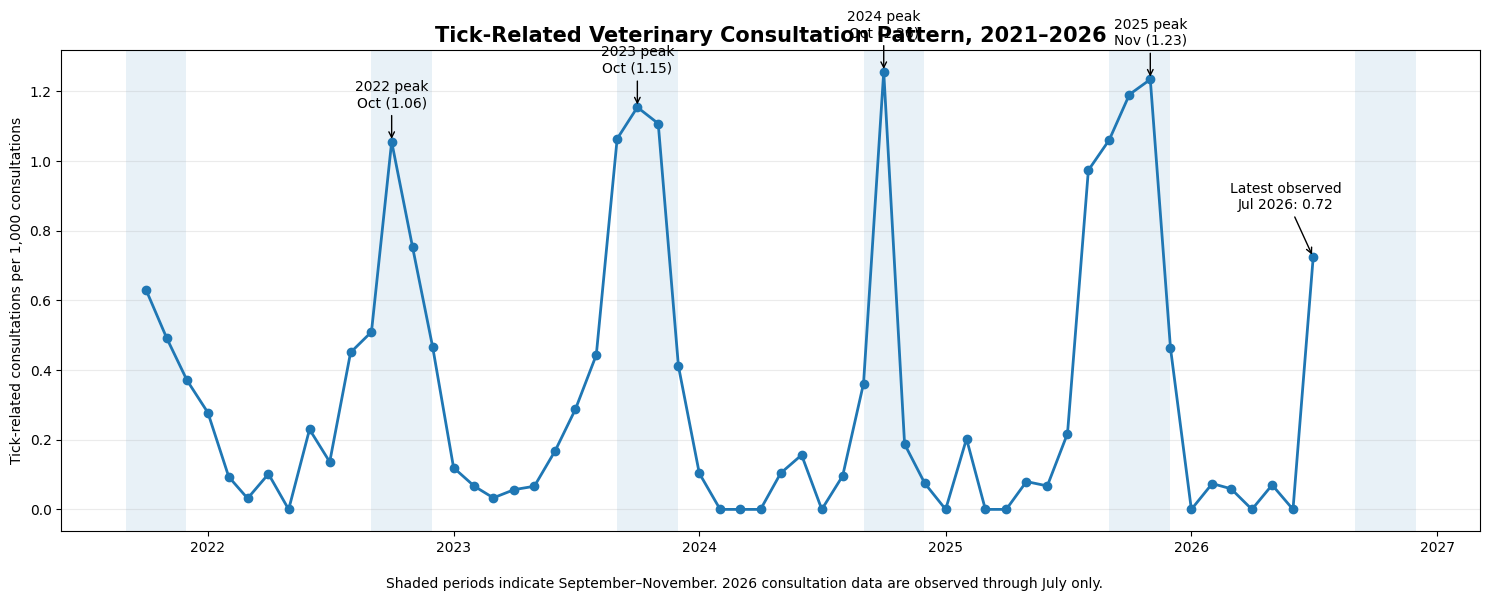

In [142]:
# ============================================================
# VISUAL — 2021–2026 TICK CONSULTATION SEASONAL PATTERN
# Shows recurring spring peak
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

plot_df = monthly_pattern.copy()

# Create proper monthly date
plot_df["Date"] = pd.to_datetime(
    plot_df["Year"].astype(str)
    + "-"
    + plot_df["Month"].astype(str)
    + "-01"
)

plot_df = plot_df.sort_values("Date")


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    plot_df["Date"],
    plot_df["Tick_per_1000"],
    marker="o",
    linewidth=2
)


# ------------------------------------------------------------
# Highlight Sep–Nov peak season each year
# ------------------------------------------------------------

for year in range(2021, 2027):

    ax.axvspan(
        pd.Timestamp(f"{year}-09-01"),
        pd.Timestamp(f"{year}-11-30"),
        alpha=0.10
    )


# ------------------------------------------------------------
# Mark annual peaks for complete years
# ------------------------------------------------------------

for year in [2022, 2023, 2024, 2025]:

    year_data = plot_df[
        plot_df["Year"] == year
    ]

    peak = year_data.loc[
        year_data["Tick_per_1000"].idxmax()
    ]

    ax.annotate(
        f"{year} peak\n"
        f"{peak['Month_Name']} "
        f"({peak['Tick_per_1000']:.2f})",

        xy=(
            peak["Date"],
            peak["Tick_per_1000"]
        ),

        xytext=(0, 25),

        textcoords="offset points",

        ha="center",

        arrowprops=dict(
            arrowstyle="->",
            lw=1
        )
    )


# ------------------------------------------------------------
# Label July 2026 — latest observed consultation month
# ------------------------------------------------------------

latest_2026 = plot_df[
    plot_df["Year"] == 2026
].iloc[-1]

ax.annotate(
    f"Latest observed\n"
    f"Jul 2026: "
    f"{latest_2026['Tick_per_1000']:.2f}",

    xy=(
        latest_2026["Date"],
        latest_2026["Tick_per_1000"]
    ),

    xytext=(-20, 35),

    textcoords="offset points",

    ha="center",

    arrowprops=dict(
        arrowstyle="->",
        lw=1
    )
)


# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.set_title(
    "Tick-Related Veterinary Consultation Pattern, 2021–2026",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel(
    "Tick-related consultations per 1,000 consultations"
)

ax.set_xlabel("")

ax.grid(
    axis="y",
    alpha=0.25
)

fig.text(
    0.5,
    0.01,
    "Shaded periods indicate September–November. "
    "2026 consultation data are observed through July only.",
    ha="center",
    fontsize=10
)

plt.tight_layout(
    rect=[0, 0.04, 1, 1]
)

plt.show()

SEQ WEEKLY SARIMA SERIES
Period: 2021-10-03 00:00:00 to 2026-07-26 00:00:00
Weeks: 252
Tick consultations: 452
Total consultations: 1240858
Rate range: 0.0 to 2.681
Clinics reporting per week: 4 to 19

WEEKLY DATE GAPS
Gap_Days
7.0    251
Name: count, dtype: int64


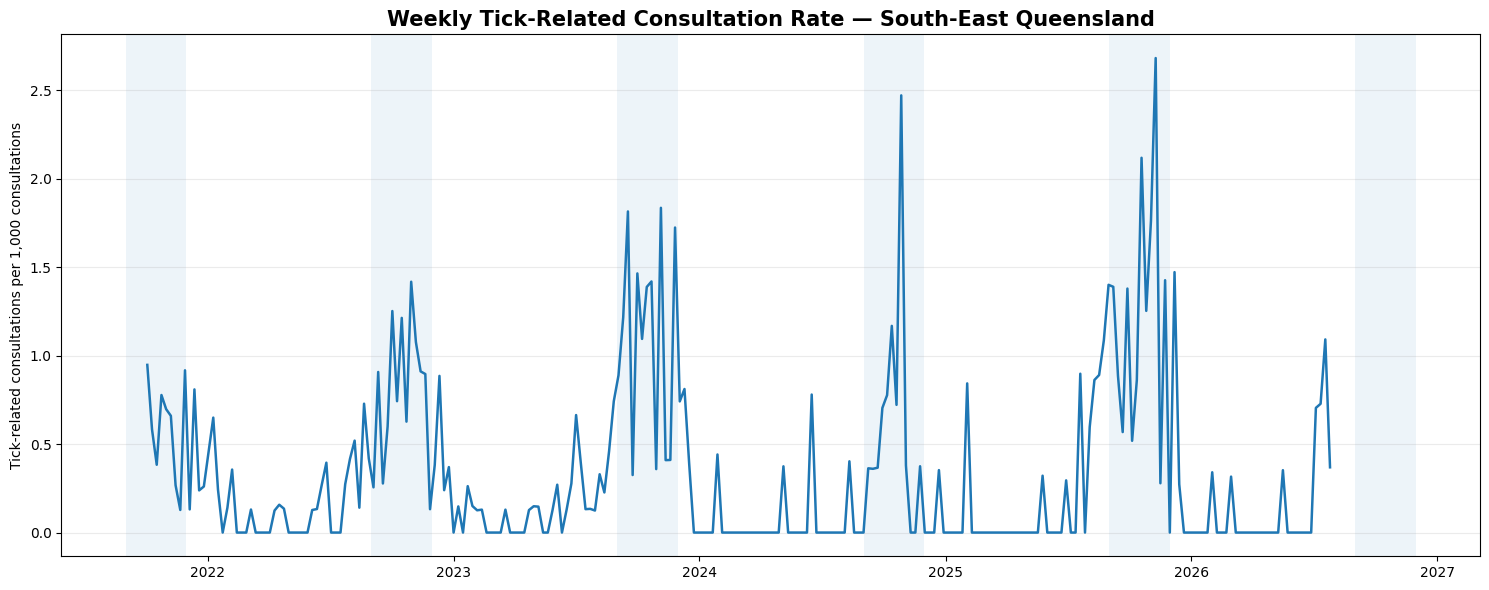

In [143]:
# ============================================================
# SARIMA STEP 1 — BUILD WEEKLY SEQ FORECASTING SERIES
# Same 19 eligible SEQ clinics used for Ridge
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Start with same eligible SEQ clinics
# ------------------------------------------------------------

sarima_base = model_final[
    model_final["ClinicID"]
    .astype(int)
    .isin(ridge_ids)
].copy()

sarima_base["ClinicID"] = (
    sarima_base["ClinicID"]
    .astype(int)
)

# Same denominator-quality rule used in Ridge sensitivity analysis
sarima_base = sarima_base[
    sarima_base["Total_Consultations"] >= 20
].copy()


# ------------------------------------------------------------
# 2. Aggregate clinics to ONE SEQ weekly series
# ------------------------------------------------------------

seq_weekly_sarima = (
    sarima_base
    .groupby("Week_End", as_index=False)
    .agg(
        Total_Consultations=(
            "Total_Consultations",
            "sum"
        ),
        Tick_Consultations=(
            "Tick_Consultations",
            "sum"
        ),
        Clinics_Reporting=(
            "ClinicID",
            "nunique"
        )
    )
    .sort_values("Week_End")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. Regional tick consultation rate
# ------------------------------------------------------------

seq_weekly_sarima["Tick_per_1000"] = (
    seq_weekly_sarima["Tick_Consultations"]
    / seq_weekly_sarima["Total_Consultations"]
    * 1000
)


# ------------------------------------------------------------
# 4. Basic checks
# ------------------------------------------------------------

print("SEQ WEEKLY SARIMA SERIES")
print("=" * 70)

print(
    "Period:",
    seq_weekly_sarima["Week_End"].min(),
    "to",
    seq_weekly_sarima["Week_End"].max()
)

print(
    "Weeks:",
    len(seq_weekly_sarima)
)

print(
    "Tick consultations:",
    int(
        seq_weekly_sarima[
            "Tick_Consultations"
        ].sum()
    )
)

print(
    "Total consultations:",
    int(
        seq_weekly_sarima[
            "Total_Consultations"
        ].sum()
    )
)

print(
    "Rate range:",
    round(
        seq_weekly_sarima[
            "Tick_per_1000"
        ].min(), 3
    ),
    "to",
    round(
        seq_weekly_sarima[
            "Tick_per_1000"
        ].max(), 3
    )
)

print(
    "Clinics reporting per week:",
    seq_weekly_sarima[
        "Clinics_Reporting"
    ].min(),
    "to",
    seq_weekly_sarima[
        "Clinics_Reporting"
    ].max()
)


# ------------------------------------------------------------
# 5. Check whether every observation is exactly 7 days apart
# ------------------------------------------------------------

seq_weekly_sarima["Gap_Days"] = (
    seq_weekly_sarima["Week_End"]
    .diff()
    .dt.days
)

print("\nWEEKLY DATE GAPS")
print("=" * 70)

print(
    seq_weekly_sarima[
        "Gap_Days"
    ].value_counts().sort_index()
)


# ------------------------------------------------------------
# 6. Plot regional weekly series
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(15, 6)
)

ax.plot(
    seq_weekly_sarima["Week_End"],
    seq_weekly_sarima["Tick_per_1000"],
    linewidth=1.8
)

# Highlight Sep-Nov peak season
for year in range(2021, 2027):

    ax.axvspan(
        pd.Timestamp(f"{year}-09-01"),
        pd.Timestamp(f"{year}-11-30"),
        alpha=0.08
    )

ax.set_title(
    "Weekly Tick-Related Consultation Rate — South-East Queensland",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel(
    "Tick-related consultations per 1,000 consultations"
)

ax.set_xlabel("")

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()
plt.show()

Missing weeks: 0

HISTORICAL VALIDATION
Training: 2021-10-03 00:00:00 to 2025-07-27 00:00:00
Testing: 2025-08-03 00:00:00 to 2025-11-30 00:00:00
Training weeks: 200
Testing weeks: 18


/Users/sreelakshmi/walert/quantitative_eval/nmslib/python_bindings/.eggs/numpy-2.0.2-py3.9-macosx-15.4-arm64.egg/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/sreelakshmi/walert/quantitative_eval/nmslib/python_bindings/.eggs/numpy-2.0.2-py3.9-macosx-15.4-arm64.egg/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/sreelakshmi/walert/quantitative_eval/nmslib/python_bindings/.eggs/numpy-2.0.2-py3.9-macosx-15.4-arm64.egg/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'



Model AIC: 77.12

VALIDATION ACCURACY
MAE : 0.5108
RMSE: 0.6797
Actual mean: 1.1085
Forecast mean: 0.9415
Actual maximum: 2.681
Forecast maximum: 1.8086

PEAK TIMING
Actual 2025 peak: 2025-11-09 | 2.681
Forecast 2025 peak: 2025-11-02 | 1.809


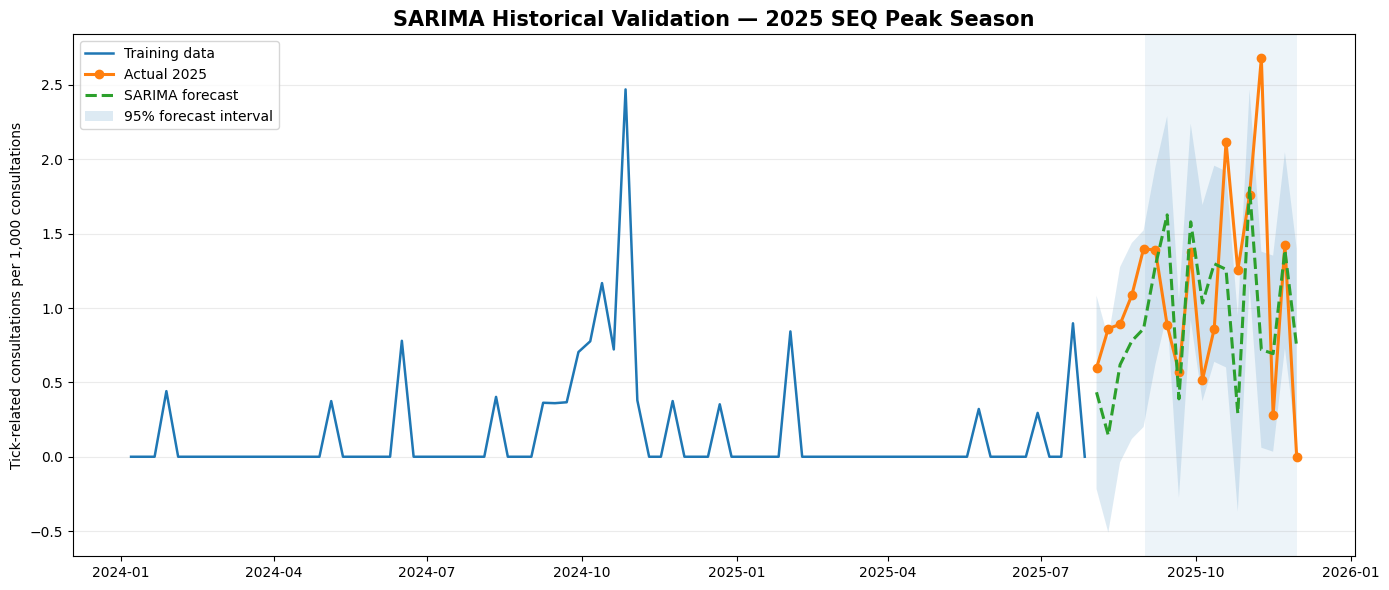

In [144]:
# ============================================================
# SARIMA STEP 2 — HISTORICAL VALIDATION
# Can seasonality predict the 2025 Aug-Nov peak?
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error


# ------------------------------------------------------------
# 1. Prepare regular weekly SEQ series
# ------------------------------------------------------------

sarima_series = (
    seq_weekly_sarima
    .set_index("Week_End")["Tick_per_1000"]
    .asfreq("W-SUN")
)

print("Missing weeks:", sarima_series.isna().sum())


# ------------------------------------------------------------
# 2. Historical validation
# Train through July 2025
# Test Aug-Nov 2025
# ------------------------------------------------------------

train_end = pd.Timestamp("2025-07-27")
test_start = pd.Timestamp("2025-08-03")
test_end = pd.Timestamp("2025-11-30")

train = sarima_series.loc[:train_end]
test = sarima_series.loc[test_start:test_end]


print("\nHISTORICAL VALIDATION")
print("=" * 70)

print(
    "Training:",
    train.index.min(),
    "to",
    train.index.max()
)

print(
    "Testing:",
    test.index.min(),
    "to",
    test.index.max()
)

print("Training weeks:", len(train))
print("Testing weeks:", len(test))


# ------------------------------------------------------------
# 3. Fit seasonal ARIMA
#
# SARIMA(1,0,1)(1,1,1,52)
# 52-week seasonal cycle
# ------------------------------------------------------------

model = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 1, 1, 52),
    enforce_stationarity=False,
    enforce_invertibility=False
)

fit = model.fit(
    disp=False,
    maxiter=500
)

print("\nModel AIC:", round(fit.aic, 2))


# ------------------------------------------------------------
# 4. Forecast Aug-Nov 2025
# ------------------------------------------------------------

forecast_result = fit.get_forecast(
    steps=len(test)
)

forecast_mean = forecast_result.predicted_mean

forecast_ci = forecast_result.conf_int()


# ------------------------------------------------------------
# 5. Accuracy
# ------------------------------------------------------------

mae = mean_absolute_error(
    test,
    forecast_mean
)

rmse = np.sqrt(
    mean_squared_error(
        test,
        forecast_mean
    )
)


print("\nVALIDATION ACCURACY")
print("=" * 70)

print("MAE :", round(mae, 4))
print("RMSE:", round(rmse, 4))

print(
    "Actual mean:",
    round(test.mean(), 4)
)

print(
    "Forecast mean:",
    round(forecast_mean.mean(), 4)
)

print(
    "Actual maximum:",
    round(test.max(), 4)
)

print(
    "Forecast maximum:",
    round(forecast_mean.max(), 4)
)


# ------------------------------------------------------------
# 6. Compare peak timing
# ------------------------------------------------------------

actual_peak_date = test.idxmax()
forecast_peak_date = forecast_mean.idxmax()

print("\nPEAK TIMING")
print("=" * 70)

print(
    "Actual 2025 peak:",
    actual_peak_date.date(),
    "|",
    round(test.max(), 3)
)

print(
    "Forecast 2025 peak:",
    forecast_peak_date.date(),
    "|",
    round(forecast_mean.max(), 3)
)


# ------------------------------------------------------------
# 7. Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

# Show recent history
history_plot = train.loc["2024-01-01":]

ax.plot(
    history_plot.index,
    history_plot,
    label="Training data",
    linewidth=1.8
)

ax.plot(
    test.index,
    test,
    label="Actual 2025",
    linewidth=2.2,
    marker="o"
)

ax.plot(
    forecast_mean.index,
    forecast_mean,
    label="SARIMA forecast",
    linewidth=2.2,
    linestyle="--"
)

ax.fill_between(
    forecast_ci.index,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    alpha=0.15,
    label="95% forecast interval"
)

ax.axvspan(
    pd.Timestamp("2025-09-01"),
    pd.Timestamp("2025-11-30"),
    alpha=0.08
)

ax.set_title(
    "SARIMA Historical Validation — 2025 SEQ Peak Season",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel(
    "Tick-related consultations per 1,000 consultations"
)

ax.set_xlabel("")

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()
plt.show()

In [145]:
# ============================================================
# SARIMA STEP 3 — SIMPLE MODEL COMPARISON
# Validate models using Aug–Nov 2025
# ============================================================

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np
import warnings

candidate_models = {
    "S1": ((1, 0, 0), (0, 1, 0, 52)),
    "S2": ((0, 0, 1), (0, 1, 0, 52)),
    "S3": ((1, 0, 1), (0, 1, 0, 52)),
    "S4": ((1, 0, 0), (0, 1, 1, 52))
}

comparison = []

for name, (order, seasonal_order) in candidate_models.items():

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            model = SARIMAX(
                train,
                order=order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted = model.fit(
                disp=False,
                maxiter=500
            )

        pred = fitted.get_forecast(
            steps=len(test)
        ).predicted_mean

        mae = mean_absolute_error(
            test,
            pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                test,
                pred
            )
        )

        comparison.append({
            "Model": name,
            "Order": str(order),
            "Seasonal_Order": str(seasonal_order),
            "AIC": fitted.aic,
            "MAE": mae,
            "RMSE": rmse,
            "Forecast_Peak_Date": pred.idxmax(),
            "Forecast_Peak": pred.max(),
            "Actual_Peak_Date": test.idxmax(),
            "Actual_Peak": test.max()
        })

    except Exception as e:
        print(name, "failed:", e)


sarima_comparison = (
    pd.DataFrame(comparison)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("SARIMA HISTORICAL VALIDATION COMPARISON")
print("=" * 90)

display(
    sarima_comparison.round({
        "AIC": 2,
        "MAE": 4,
        "RMSE": 4,
        "Forecast_Peak": 3,
        "Actual_Peak": 3
    })
)

SARIMA HISTORICAL VALIDATION COMPARISON


,Model,Order,Seasonal_Order,AIC,MAE,RMSE,Forecast_Peak_Date,Forecast_Peak,Actual_Peak_Date,Actual_Peak
0,S4,"(1, 0, 0)","(0, 1, 1, 52)",100.26,0.5529,0.7674,2025-10-26,1.236,2025-11-09,2.681
1,S3,"(1, 0, 1)","(0, 1, 0, 52)",197.88,0.8379,1.0417,2025-10-26,2.489,2025-11-09,2.681
2,S1,"(1, 0, 0)","(0, 1, 0, 52)",205.18,0.8572,1.0592,2025-10-26,2.470,2025-11-09,2.681
3,S2,"(0, 0, 1)","(0, 1, 0, 52)",204.75,0.8572,1.0592,2025-10-26,2.470,2025-11-09,2.681


In [146]:
# ============================================================
# STEP 6 — MULTI-YEAR SEASONAL VALIDATION
# Predict Aug-Nov 2025 using historical seasonal weeks
# from 2022, 2023 and 2024
# ============================================================

import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# ------------------------------------------------------------
# 1. Create helper dataframe
# ------------------------------------------------------------

season_df = (
    seq_weekly_sarima[
        ["Week_End", "Tick_per_1000"]
    ]
    .copy()
)

season_df["Year"] = (
    season_df["Week_End"].dt.year
)

season_df["ISO_Week"] = (
    season_df["Week_End"]
    .dt.isocalendar()
    .week
    .astype(int)
)


# ------------------------------------------------------------
# 2. Actual Aug-Nov 2025
# ------------------------------------------------------------

actual_2025_df = season_df[
    (season_df["Week_End"] >= "2025-08-03")
    &
    (season_df["Week_End"] <= "2025-11-30")
].copy()


# ------------------------------------------------------------
# 3. Historical seasonal expectation
# Use ONLY years before 2025
# ------------------------------------------------------------

historical_2022_2024 = season_df[
    season_df["Year"].isin(
        [2022, 2023, 2024]
    )
].copy()

seasonal_expectation = (
    historical_2022_2024
    .groupby("ISO_Week")
    ["Tick_per_1000"]
    .agg(
        Forecast="mean",
        Historical_SD="std",
        Years_Available="count"
    )
    .reset_index()
)


# ------------------------------------------------------------
# 4. Match historical seasonal expectation to 2025
# ------------------------------------------------------------

validation_2025 = (
    actual_2025_df
    .merge(
        seasonal_expectation,
        on="ISO_Week",
        how="left"
    )
)


# ------------------------------------------------------------
# 5. Accuracy
# ------------------------------------------------------------

valid = validation_2025[
    "Forecast"
].notna()

y_actual = validation_2025.loc[
    valid,
    "Tick_per_1000"
]

y_pred = validation_2025.loc[
    valid,
    "Forecast"
]


mae = mean_absolute_error(
    y_actual,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_actual,
        y_pred
    )
)


print(
    "MULTI-YEAR SEASONAL 2025 VALIDATION"
)

print("=" * 70)

print(
    "MAE:",
    round(mae, 4)
)

print(
    "RMSE:",
    round(rmse, 4)
)

print(
    "Actual mean:",
    round(y_actual.mean(), 4)
)

print(
    "Forecast mean:",
    round(y_pred.mean(), 4)
)


# ------------------------------------------------------------
# 6. Peak comparison
# ------------------------------------------------------------

actual_peak = (
    validation_2025.loc[
        validation_2025[
            "Tick_per_1000"
        ].idxmax()
    ]
)

forecast_peak = (
    validation_2025.loc[
        validation_2025[
            "Forecast"
        ].idxmax()
    ]
)


print("\nPEAK COMPARISON")
print("=" * 70)

print(
    "Actual peak:",
    actual_peak["Week_End"].date(),
    "|",
    round(
        actual_peak["Tick_per_1000"],
        3
    )
)

print(
    "Forecast peak:",
    forecast_peak["Week_End"].date(),
    "|",
    round(
        forecast_peak["Forecast"],
        3
    )
)


# ------------------------------------------------------------
# 7. Compare all approaches
# ------------------------------------------------------------

print("\nMODEL COMPARISON")
print("=" * 70)

print(
    "S4 SARIMA validation   | "
    "MAE 0.5529 | RMSE 0.7674 "
    "(final fit unstable)"
)

print(
    "Seasonal naive         | "
    "MAE 0.8572 | RMSE 1.0592"
)

print(
    "Multi-year seasonal    | "
    f"MAE {mae:.4f} | RMSE {rmse:.4f}"
)


# ------------------------------------------------------------
# 8. Show validation table
# ------------------------------------------------------------

display(
    validation_2025[
        [
            "Week_End",
            "ISO_Week",
            "Tick_per_1000",
            "Forecast",
            "Years_Available"
        ]
    ].round(3)
)

MULTI-YEAR SEASONAL 2025 VALIDATION
MAE: 0.5755
RMSE: 0.7623
Actual mean: 1.1085
Forecast mean: 0.693

PEAK COMPARISON
Actual peak: 2025-11-09 | 2.681
Forecast peak: 2025-10-26 | 1.415

MODEL COMPARISON
S4 SARIMA validation   | MAE 0.5529 | RMSE 0.7674 (final fit unstable)
Seasonal naive         | MAE 0.8572 | RMSE 1.0592
Multi-year seasonal    | MAE 0.5755 | RMSE 0.7623


,Week_End,ISO_Week,Tick_per_1000,Forecast,Years_Available
0,2025-08-03,31,0.596,0.283,3
1,2025-08-10,32,0.862,0.257,3
2,2025-08-17,33,0.890,0.396,3
3,2025-08-24,34,1.086,0.387,3
4,2025-08-31,35,1.400,0.381,3
5,2025-09-07,36,1.389,0.829,3
6,2025-09-14,37,0.885,0.817,3
7,2025-09-21,38,0.568,0.430,3
8,2025-09-28,39,1.379,1.140,3
9,2025-10-05,40,0.518,0.871,3


FINAL 2026 SEQ SEASONAL OUTLOOK
Expected peak week: 2026-10-25
Expected rate: 1.375 per 1,000 consultations
Historical range for this seasonal week: 0.358 to 2.47

MONTHLY 2026 OUTLOOK


,Month,Expected_Mean_Rate,Expected_Max_Weekly_Rate
0,Aug,0.497,0.636
1,Sep,0.867,1.200
2,Oct,1.134,1.375
3,Nov,0.771,1.263



WEEKLY 2026 OUTLOOK


,Week_End,ISO_Week,Forecast,Historical_Min,Historical_Max,Years_Available
0,2026-08-02,31,0.361,0.000,0.596,4
1,2026-08-09,32,0.408,0.140,0.862,4
2,2026-08-16,33,0.519,0.000,0.890,4
3,2026-08-23,34,0.562,0.000,1.086,4
4,2026-08-30,35,0.636,0.000,1.400,4
5,2026-09-06,36,0.969,0.363,1.389,4
6,2026-09-13,37,0.834,0.277,1.814,4
7,2026-09-20,38,0.465,0.325,0.599,4
8,2026-09-27,39,1.200,0.704,1.464,4
9,2026-10-04,40,0.783,0.518,1.094,4


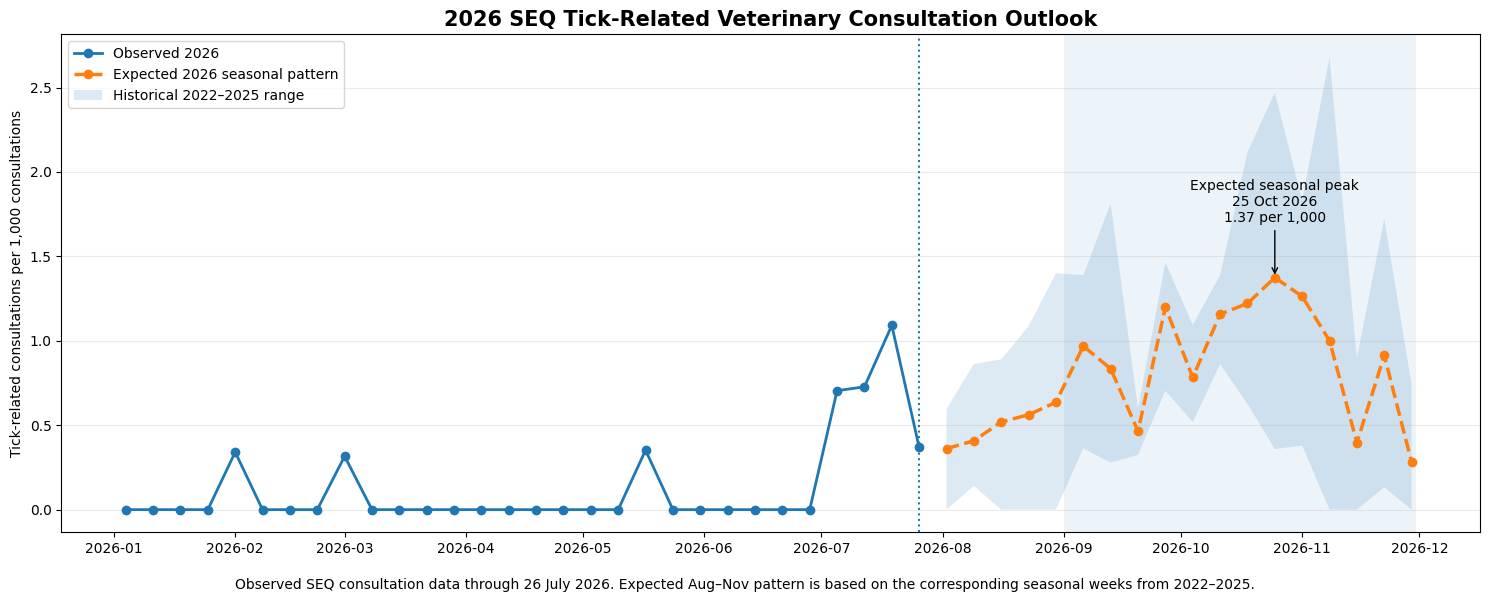

In [147]:
# ============================================================
# FINAL — 2026 SEQ PEAK-SEASON OUTLOOK
# Historical multi-year seasonal expectation
# Based on 2022–2025
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Historical data used to estimate seasonal pattern
# ------------------------------------------------------------

historical = season_df[
    season_df["Year"].isin(
        [2022, 2023, 2024, 2025]
    )
].copy()


# ------------------------------------------------------------
# 2. Historical expectation for each ISO week
# ------------------------------------------------------------

historical_weekly_pattern = (
    historical
    .groupby("ISO_Week")["Tick_per_1000"]
    .agg(
        Forecast="mean",
        Historical_SD="std",
        Historical_Min="min",
        Historical_Max="max",
        Years_Available="count"
    )
    .reset_index()
)


# ------------------------------------------------------------
# 3. Future 2026 weeks: Aug-Nov
# ------------------------------------------------------------

future_2026 = pd.DataFrame({
    "Week_End": pd.date_range(
        start="2026-08-02",
        end="2026-11-29",
        freq="W-SUN"
    )
})

future_2026["ISO_Week"] = (
    future_2026["Week_End"]
    .dt.isocalendar()
    .week
    .astype(int)
)


# ------------------------------------------------------------
# 4. Apply historical seasonal expectation
# ------------------------------------------------------------

forecast_2026_final = (
    future_2026
    .merge(
        historical_weekly_pattern,
        on="ISO_Week",
        how="left"
    )
)


# ------------------------------------------------------------
# 5. Find expected peak
# ------------------------------------------------------------

peak = forecast_2026_final.loc[
    forecast_2026_final["Forecast"].idxmax()
]


print("FINAL 2026 SEQ SEASONAL OUTLOOK")
print("=" * 75)

print(
    "Expected peak week:",
    peak["Week_End"].date()
)

print(
    "Expected rate:",
    round(
        peak["Forecast"],
        3
    ),
    "per 1,000 consultations"
)

print(
    "Historical range for this seasonal week:",
    round(
        peak["Historical_Min"],
        3
    ),
    "to",
    round(
        peak["Historical_Max"],
        3
    )
)


# ------------------------------------------------------------
# 6. Monthly summary
# ------------------------------------------------------------

forecast_2026_final["Month"] = (
    forecast_2026_final["Week_End"]
    .dt.strftime("%b")
)

monthly_2026_outlook = (
    forecast_2026_final
    .groupby(
        "Month",
        sort=False
    )
    .agg(
        Expected_Mean_Rate=(
            "Forecast",
            "mean"
        ),
        Expected_Max_Weekly_Rate=(
            "Forecast",
            "max"
        )
    )
    .reset_index()
)


print("\nMONTHLY 2026 OUTLOOK")
print("=" * 75)

display(
    monthly_2026_outlook.round(3)
)


# ------------------------------------------------------------
# 7. Full weekly forecast
# ------------------------------------------------------------

print("\nWEEKLY 2026 OUTLOOK")
print("=" * 75)

display(
    forecast_2026_final[
        [
            "Week_End",
            "ISO_Week",
            "Forecast",
            "Historical_Min",
            "Historical_Max",
            "Years_Available"
        ]
    ].round(3)
)


# ------------------------------------------------------------
# 8. Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(15, 6)
)

# Observed 2026
observed_2026 = (
    seq_weekly_sarima[
        seq_weekly_sarima["Week_End"]
        .dt.year == 2026
    ]
)

ax.plot(
    observed_2026["Week_End"],
    observed_2026["Tick_per_1000"],
    marker="o",
    linewidth=2,
    label="Observed 2026"
)


# Expected 2026 seasonal pattern
ax.plot(
    forecast_2026_final["Week_End"],
    forecast_2026_final["Forecast"],
    marker="o",
    linestyle="--",
    linewidth=2.5,
    label="Expected 2026 seasonal pattern"
)


# Historical seasonal range
ax.fill_between(
    forecast_2026_final["Week_End"],
    forecast_2026_final["Historical_Min"],
    forecast_2026_final["Historical_Max"],
    alpha=0.15,
    label="Historical 2022–2025 range"
)


# Sep-Nov shading
ax.axvspan(
    pd.Timestamp("2026-09-01"),
    pd.Timestamp("2026-11-30"),
    alpha=0.08
)


# Forecast boundary
ax.axvline(
    pd.Timestamp("2026-07-26"),
    linestyle=":",
    linewidth=1.5
)


# Peak annotation
ax.annotate(
    "Expected seasonal peak\n"
    + peak["Week_End"].strftime("%d %b %Y")
    + "\n"
    + f"{peak['Forecast']:.2f} per 1,000",

    xy=(
        peak["Week_End"],
        peak["Forecast"]
    ),

    xytext=(0, 40),

    textcoords="offset points",

    ha="center",

    arrowprops=dict(
        arrowstyle="->",
        lw=1
    )
)


ax.set_title(
    "2026 SEQ Tick-Related Veterinary Consultation Outlook",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel(
    "Tick-related consultations per 1,000 consultations"
)

ax.set_xlabel("")

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

fig.text(
    0.5,
    0.01,
    "Observed SEQ consultation data through 26 July 2026. "
    "Expected Aug–Nov pattern is based on the corresponding "
    "seasonal weeks from 2022–2025.",
    ha="center",
    fontsize=10
)

plt.tight_layout(
    rect=[0, 0.04, 1, 1]
)

plt.show()

In [148]:
# ============================================================
# VALIDATE THE SEASONAL OUTLOOK ACROSS MULTIPLE YEARS
# 2024 forecast uses 2022-2023
# 2025 forecast uses 2022-2024
# ============================================================

import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

validation_results = []


for target_year in [2024, 2025]:

    # --------------------------------------------------------
    # Historical years available BEFORE target year
    # --------------------------------------------------------

    training_years = list(
        range(2022, target_year)
    )

    historical_train = season_df[
        season_df["Year"].isin(training_years)
    ].copy()


    # --------------------------------------------------------
    # Historical mean for each seasonal week
    # --------------------------------------------------------

    seasonal_reference = (
        historical_train
        .groupby("ISO_Week")["Tick_per_1000"]
        .mean()
        .rename("Forecast")
        .reset_index()
    )


    # --------------------------------------------------------
    # Actual Aug-Nov target year
    # --------------------------------------------------------

    actual = season_df[
        (season_df["Year"] == target_year)
        &
        (season_df["Week_End"].dt.month.isin(
            [8, 9, 10, 11]
        ))
    ].copy()


    validation = actual.merge(
        seasonal_reference,
        on="ISO_Week",
        how="left"
    )

    validation = validation.dropna(
        subset=["Forecast"]
    )


    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    mae = mean_absolute_error(
        validation["Tick_per_1000"],
        validation["Forecast"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            validation["Tick_per_1000"],
            validation["Forecast"]
        )
    )


    # --------------------------------------------------------
    # Actual and predicted peaks
    # --------------------------------------------------------

    actual_peak = validation.loc[
        validation["Tick_per_1000"].idxmax()
    ]

    forecast_peak = validation.loc[
        validation["Forecast"].idxmax()
    ]


    validation_results.append({

        "Forecast_Year":
            target_year,

        "Training_Years":
            f"{training_years[0]}–{training_years[-1]}",

        "MAE":
            mae,

        "RMSE":
            rmse,

        "Actual_Peak_Date":
            actual_peak["Week_End"],

        "Actual_Peak_Rate":
            actual_peak["Tick_per_1000"],

        "Predicted_Peak_Date":
            forecast_peak["Week_End"],

        "Predicted_Peak_Rate":
            forecast_peak["Forecast"],

        "Peak_Difference_Days":
            abs(
                (
                    actual_peak["Week_End"]
                    - forecast_peak["Week_End"]
                ).days
            )
    })


backtest_results = pd.DataFrame(
    validation_results
)


print("MULTI-YEAR HISTORICAL BACKTEST")
print("=" * 85)

display(
    backtest_results.round({
        "MAE": 4,
        "RMSE": 4,
        "Actual_Peak_Rate": 3,
        "Predicted_Peak_Rate": 3
    })
)


print("\nAVERAGE PERFORMANCE")
print("=" * 85)

print(
    "Mean MAE:",
    round(
        backtest_results["MAE"].mean(),
        4
    )
)

print(
    "Mean RMSE:",
    round(
        backtest_results["RMSE"].mean(),
        4
    )
)

print(
    "Mean peak timing error:",
    round(
        backtest_results[
            "Peak_Difference_Days"
        ].mean() / 7,
        1
    ),
    "weeks"
)

MULTI-YEAR HISTORICAL BACKTEST


,Forecast_Year,Training_Years,MAE,RMSE,Actual_Peak_Date,Actual_Peak_Rate,Predicted_Peak_Date,Predicted_Peak_Rate,Peak_Difference_Days
0,2024,2022–2023,0.5661,0.6685,2024-10-27,2.470,2024-11-03,1.456,7
1,2025,2022–2024,0.5755,0.7623,2025-11-09,2.681,2025-10-26,1.415,14



AVERAGE PERFORMANCE
Mean MAE: 0.5708
Mean RMSE: 0.7154
Mean peak timing error: 1.5 weeks


In [149]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

backtest_results = []

for target_year in [2024, 2025]:

    historical = season_df[
        (season_df["Year"] >= 2022) &
        (season_df["Year"] < target_year)
    ].copy()

    actual = season_df[
        (season_df["Year"] == target_year) &
        (season_df["Week_End"].dt.month.isin([8, 9, 10, 11]))
    ].copy()

    # Historical weekly seasonal pattern
    seasonal_pattern = (
        historical.groupby("ISO_Week")["Tick_per_1000"]
        .mean()
        .rename("Forecast")
    )

    actual = actual.join(
        seasonal_pattern,
        on="ISO_Week"
    ).dropna(subset=["Forecast"])

    if actual.empty:
        continue

    y_true = actual["Tick_per_1000"]
    y_pred = actual["Forecast"]

    # Simple historical average benchmark
    baseline = historical["Tick_per_1000"].mean()

    actual_peak = actual.loc[y_true.idxmax(), "Week_End"]
    predicted_peak = actual.loc[y_pred.idxmax(), "Week_End"]

    backtest_results.append({
        "Year": target_year,
        "Seasonal_MAE": mean_absolute_error(y_true, y_pred),
        "Seasonal_RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Baseline_MAE": mean_absolute_error(
            y_true,
            np.repeat(baseline, len(y_true))
        ),
        "Actual_Peak": actual_peak.date(),
        "Predicted_Peak": predicted_peak.date(),
        "Peak_Error_Weeks": abs(
            (actual_peak - predicted_peak).days
        ) / 7
    })

backtest_results = pd.DataFrame(backtest_results)

print("HISTORICAL FORECAST BACKTEST")
display(backtest_results.round(3))

print("\nAVERAGE RESULTS")
print("Seasonal MAE:", round(backtest_results["Seasonal_MAE"].mean(), 3))
print("Baseline MAE:", round(backtest_results["Baseline_MAE"].mean(), 3))
print("Peak timing error:", round(backtest_results["Peak_Error_Weeks"].mean(), 2), "weeks")

HISTORICAL FORECAST BACKTEST


,Year,Seasonal_MAE,Seasonal_RMSE,Baseline_MAE,Actual_Peak,Predicted_Peak,Peak_Error_Weeks
0,2024,0.566,0.669,0.370,2024-10-27,2024-11-03,1.0
1,2025,0.576,0.762,0.831,2025-11-09,2025-10-26,2.0



AVERAGE RESULTS
Seasonal MAE: 0.571
Baseline MAE: 0.601
Peak timing error: 1.5 weeks


In [150]:
import pandas as pd
import numpy as np

print("FINAL VETIQ DATA QUALITY AUDIT")
print("=" * 65)

# 1. Check available datasets
datasets = [
    "consult",
    "tick_weekly",
    "seq_weather_panel",
    "model_final",
    "season_df",
    "seq_weekly_sarima"
]

for name in datasets:
    if name in globals():
        df = globals()[name]
        print(f"{name}: {df.shape}")
    else:
        print(f"{name}: NOT AVAILABLE")

# 2. Consultation-level checks
if "consult" in globals():

    print("\nCONSULTATION DATA")
    print("=" * 65)

    print("Total rows:", len(consult))

    if "ConsultationKey" in consult.columns:
        print(
            "Unique consultation keys:",
            consult["ConsultationKey"].nunique()
        )

        print(
            "Duplicate consultation-key rows:",
            consult["ConsultationKey"].duplicated().sum()
        )

    if "ConsultationDate" in consult.columns:
        dates = pd.to_datetime(
            consult["ConsultationDate"],
            errors="coerce"
        )

        print("Earliest date:", dates.min())
        print("Latest date:", dates.max())
        print("Invalid dates:", dates.isna().sum())

# 3. Clinic-week checks
if "model_final" in globals():

    print("\nCLINIC-WEEK DATA")
    print("=" * 65)

    df = model_final.copy()

    print("Rows:", len(df))
    print("Clinics:", df["ClinicID"].nunique())

    print(
        "Duplicate clinic-weeks:",
        df.duplicated(
            subset=["ClinicID", "Week_End"]
        ).sum()
    )

    print(
        "Tick consultations > total consultations:",
        (
            df["Tick_Consultations"]
            > df["Total_Consultations"]
        ).sum()
    )

    print(
        "Zero or negative total consultations:",
        (df["Total_Consultations"] <= 0).sum()
    )

    print(
        "Missing temperatures:",
        df["AvgTemp_C"].isna().sum()
    )

    print(
        "Missing Google Trends:",
        df["Tick_Search_Index"].isna().sum()
    )

# 4. Clinic coverage by year
if "model_final" in globals():

    df["Year"] = pd.to_datetime(
        df["Week_End"]
    ).dt.year

    coverage = (
        df.groupby("Year")
        .agg(
            Clinics=("ClinicID", "nunique"),
            Clinic_Weeks=("Week_End", "count"),
            Total_Consultations=(
                "Total_Consultations", "sum"
            ),
            Tick_Consultations=(
                "Tick_Consultations", "sum"
            )
        )
        .reset_index()
    )

    coverage["Tick_per_1000"] = (
        1000
        * coverage["Tick_Consultations"]
        / coverage["Total_Consultations"]
    )

    print("\nANNUAL CLINIC COVERAGE")
    display(coverage.round(3))

FINAL VETIQ DATA QUALITY AUDIT
consult: (7641896, 9)
tick_weekly: (1167, 3)
seq_weather_panel: (2566, 9)
model_final: (2566, 14)
season_df: (252, 4)
seq_weekly_sarima: (252, 6)

CONSULTATION DATA
Total rows: 7641896
Unique consultation keys: 7036110
Duplicate consultation-key rows: 605786
Earliest date: 2021-10-01 00:00:00
Latest date: 2026-08-26 00:00:00
Invalid dates: 0

CLINIC-WEEK DATA
Rows: 2566
Clinics: 23
Duplicate clinic-weeks: 0
Tick consultations > total consultations: 0
Zero or negative total consultations: 0
Missing temperatures: 0
Missing Google Trends: 0

ANNUAL CLINIC COVERAGE


,Year,Clinics,Clinic_Weeks,Total_Consultations,Tick_Consultations,Tick_per_1000
0,2021,17,209,94613,47.0,0.497
1,2022,18,835,393583,137.0,0.348
2,2023,23,853,383224,154.0,0.402
3,2024,5,219,133568,34.0,0.255
4,2025,6,282,161357,85.0,0.527
5,2026,6,168,93987,11.0,0.117


In [151]:
import pandas as pd

df = model_final.copy()

df["Year"] = pd.to_datetime(
    df["Week_End"]
).dt.year

# Clinic-week coverage by year
clinic_year_coverage = (
    df.groupby(["ClinicID", "Year"])
    .agg(
        Weeks=("Week_End", "nunique"),
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
)

# Number of weeks observed in each year
coverage_matrix = (
    clinic_year_coverage
    .pivot(
        index="ClinicID",
        columns="Year",
        values="Weeks"
    )
    .fillna(0)
    .astype(int)
)

print("CLINIC COVERAGE BY YEAR")
display(coverage_matrix)

# Consistent clinics across complete historical years
years_required = [2022, 2023, 2024, 2025]

consistent_clinics = coverage_matrix.index[
    (coverage_matrix.reindex(
        columns=years_required,
        fill_value=0
    ) >= 40).all(axis=1)
].tolist()

print("\nCLINICS WITH AT LEAST 40 WEEKS")
print("IN EACH YEAR FROM 2022–2025")
print("=" * 60)

print("Number:", len(consistent_clinics))
print("Clinic IDs:", consistent_clinics)

CLINIC COVERAGE BY YEAR


/var/folders/_w/whgh5msd3m51z0f722vzc5140000gn/T/ipykernel_27594/1847070601.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["ClinicID", "Year"])


Year,2021,2022,2023,2024,2025,2026
ClinicID,,,,,,
8,13,52,53,52,52,18
15,0,0,23,52,52,30
17,0,0,23,52,52,30
18,0,0,23,52,52,30
21,13,52,44,0,38,30
22,13,52,44,11,36,30
96,0,2,2,0,0,0
99,13,52,45,0,0,0
101,13,52,45,0,0,0



CLINICS WITH AT LEAST 40 WEEKS
IN EACH YEAR FROM 2022–2025
Number: 1
Clinic IDs: [8]


In [152]:
import pandas as pd
import numpy as np

# Consistent clinic across 2022–2025
clinic8 = model_final[
    model_final["ClinicID"] == 8
].copy()

clinic8["Week_End"] = pd.to_datetime(
    clinic8["Week_End"]
)

clinic8 = clinic8.sort_values("Week_End")

clinic8["Year"] = clinic8["Week_End"].dt.year
clinic8["Month"] = clinic8["Week_End"].dt.month

# Monthly aggregation
monthly_clinic8 = (
    clinic8
    .groupby(["Year", "Month"])
    .agg(
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
)

monthly_clinic8["Tick_per_1000"] = (
    1000
    * monthly_clinic8["Tick_Consultations"]
    / monthly_clinic8["Total_Consultations"]
)

# Identify peak month for complete historical years
historical = monthly_clinic8[
    monthly_clinic8["Year"].between(2022, 2025)
]

peak_months = (
    historical
    .loc[
        historical.groupby("Year")["Tick_per_1000"].idxmax()
    ]
    .sort_values("Year")
)

print("CLINIC 8 — ANNUAL PEAK MONTHS")
print("=" * 65)

display(
    peak_months[
        [
            "Year",
            "Month",
            "Tick_Consultations",
            "Total_Consultations",
            "Tick_per_1000"
        ]
    ].round(3)
)

print("\nCLINIC 8 — AUGUST TO NOVEMBER")
print("=" * 65)

display(
    historical[
        historical["Month"].isin([8, 9, 10, 11])
    ][
        [
            "Year",
            "Month",
            "Tick_Consultations",
            "Total_Consultations",
            "Tick_per_1000"
        ]
    ].round(3)
)

CLINIC 8 — ANNUAL PEAK MONTHS


,Year,Month,Tick_Consultations,Total_Consultations,Tick_per_1000
8,2022,6,1.0,2552,0.392
24,2023,10,4.0,5661,0.707
37,2024,11,1.0,1867,0.536
40,2025,2,1.0,1698,0.589



CLINIC 8 — AUGUST TO NOVEMBER


,Year,Month,Tick_Consultations,Total_Consultations,Tick_per_1000
10,2022,8,0.0,2294,0.000
11,2022,9,0.0,2220,0.000
12,2022,10,0.0,3052,0.000
13,2022,11,0.0,2574,0.000
22,2023,8,0.0,4584,0.000
23,2023,9,0.0,4751,0.000
24,2023,10,4.0,5661,0.707
25,2023,11,0.0,2018,0.000
34,2024,8,0.0,1692,0.000
35,2024,9,0.0,2442,0.000


In [153]:
print("TICK WEEKLY DATA")
print("=" * 60)

print("Columns:", tick_weekly.columns.tolist())
print("Shape:", tick_weekly.shape)

display(tick_weekly.head(10))

print("\nDATE COVERAGE")
print("Earliest:", tick_weekly["Week_End"].min())
print("Latest:", tick_weekly["Week_End"].max())

print("\nCONSULTATION DATA COLUMNS")
print(consult.columns.tolist())

print("\nTICK WEEKLY FILE SOURCE")
print("Please verify which notebook cell or CSV generated tick_weekly.")

TICK WEEKLY DATA
Columns: ['ClinicID', 'Week_End', 'Tick_Consultations']
Shape: (1167, 3)


,ClinicID,Week_End,Tick_Consultations
0,8,2021-09-12,1
1,8,2021-11-07,1
2,8,2022-06-19,1
3,8,2023-10-15,2
4,8,2023-10-22,2
5,8,2024-10-27,1
6,8,2024-11-24,1
7,8,2025-02-02,1
8,8,2025-11-23,1
9,8,2026-08-16,1



DATE COVERAGE
Earliest: 2020-01-05 00:00:00
Latest: 2026-09-27 00:00:00

CONSULTATION DATA COLUMNS
['ConsultationKey', 'ClinicID', 'ClinicPseudonym', 'ConsultationDate', 'ItemServiceFeeName', 'ExaminationTextString', 'SummaryString', 'SpecialInstructionString', 'DataSource']

TICK WEEKLY FILE SOURCE
Please verify which notebook cell or CSV generated tick_weekly.


In [154]:
import pandas as pd

ticks = tick_weekly.copy()
ticks["Week_End"] = pd.to_datetime(ticks["Week_End"])

consult_check = consult[
    ["ConsultationKey", "ClinicID", "ConsultationDate", "DataSource"]
].copy()

consult_check["ConsultationDate"] = pd.to_datetime(
    consult_check["ConsultationDate"]
)

# Count unique consultations per clinic-week and source
consult_check["Week_End"] = (
    consult_check["ConsultationDate"]
    + pd.to_timedelta(
        6 - consult_check["ConsultationDate"].dt.weekday,
        unit="D"
    )
).dt.normalize()

source_summary = (
    consult_check.groupby("DataSource")
    .agg(
        Rows=("ConsultationKey", "size"),
        Unique_Consultations=("ConsultationKey", "nunique"),
        First_Date=("ConsultationDate", "min"),
        Last_Date=("ConsultationDate", "max"),
        Clinics=("ClinicID", "nunique")
    )
)

print("CONSULTATION SOURCE SUMMARY")
display(source_summary)

print("\nTICK COUNTS OUTSIDE CONSULTATION DATE RANGE")

first_date = consult_check["ConsultationDate"].min()
last_date = consult_check["ConsultationDate"].max()

outside = ticks[
    (ticks["Week_End"] < first_date)
    | (ticks["Week_End"] > last_date + pd.Timedelta(days=6))
]

print("Tick weekly rows outside consultation coverage:", len(outside))
print("Tick consultations outside coverage:",
      outside["Tick_Consultations"].sum())

print("\nTICK WEEKLY BY YEAR")
display(
    ticks.assign(Year=ticks["Week_End"].dt.year)
    .groupby("Year")
    .agg(
        Clinic_Weeks=("Week_End", "size"),
        Clinics=("ClinicID", "nunique"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
)

CONSULTATION SOURCE SUMMARY


,Rows,Unique_Consultations,First_Date,Last_Date,Clinics
DataSource,,,,,
Consultation.csv,1048575,1048575,2021-10-01,2023-10-31,23
consultations_freetext.csv,6593321,5987535,2023-07-27,2026-08-26,58



TICK COUNTS OUTSIDE CONSULTATION DATE RANGE
Tick weekly rows outside consultation coverage: 244
Tick consultations outside coverage: 338

TICK WEEKLY BY YEAR


,Clinic_Weeks,Clinics,Tick_Consultations
Year,,,
2020,141,20,196
2021,134,18,176
2022,178,20,254
2023,197,23,288
2024,196,23,277
2025,219,25,342
2026,102,22,139


In [155]:
import pandas as pd

c = consult[
    ["ConsultationKey", "ClinicID", "ConsultationDate"]
].copy()

c["ConsultationDate"] = pd.to_datetime(c["ConsultationDate"])

c["Week_End"] = (
    c["ConsultationDate"]
    + pd.to_timedelta(
        6 - c["ConsultationDate"].dt.weekday,
        unit="D"
    )
).dt.normalize()

# Unique consultations, not repeated service rows
c = c.drop_duplicates(
    ["ClinicID", "Week_End", "ConsultationKey"]
)

weekly_total = (
    c.groupby(["ClinicID", "Week_End"])
    .size()
    .rename("Available_Consultations")
    .reset_index()
)

comparison = tick_weekly.merge(
    weekly_total,
    on=["ClinicID", "Week_End"],
    how="left"
)

comparison["Exceeds_Total"] = (
    comparison["Tick_Consultations"]
    > comparison["Available_Consultations"]
)

print("TICK / CONSULTATION COMPATIBILITY CHECK")
print("=" * 60)

print("Tick clinic-weeks:", len(comparison))
print(
    "Clinic-weeks with no consultation match:",
    comparison["Available_Consultations"].isna().sum()
)
print(
    "Clinic-weeks where ticks exceed available consultations:",
    comparison["Exceeds_Total"].sum()
)

print("\nUNMATCHED TICK ROWS BY YEAR")
display(
    comparison[
        comparison["Available_Consultations"].isna()
    ]
    .assign(Year=lambda x: x["Week_End"].dt.year)
    .groupby("Year")
    .agg(
        Clinic_Weeks=("Week_End", "size"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
)

print("\nEXAMPLES OF INCOMPATIBLE ROWS")
display(
    comparison[
        comparison["Exceeds_Total"]
    ].head(15)
)

TICK / CONSULTATION COMPATIBILITY CHECK
Tick clinic-weeks: 1167
Clinic-weeks with no consultation match: 748
Clinic-weeks where ticks exceed available consultations: 0

UNMATCHED TICK ROWS BY YEAR


,Clinic_Weeks,Tick_Consultations
Year,,
2020,141,196
2021,83,113
2022,40,69
2023,56,92
2024,173,243
2025,163,257
2026,92,128



EXAMPLES OF INCOMPATIBLE ROWS


,ClinicID,Week_End,Tick_Consultations,Available_Consultations,Exceeds_Total


In [156]:
# Identify why tick clinic-weeks have no consultation match

tick_check = tick_weekly.copy()
tick_check["Week_End"] = pd.to_datetime(tick_check["Week_End"])

consult_clinics = set(consult["ClinicID"].dropna().unique())

consult_dates = pd.to_datetime(consult["ConsultationDate"])

start_date = consult_dates.min()
end_date = consult_dates.max()

unmatched = comparison[
    comparison["Available_Consultations"].isna()
].copy()

unmatched["Clinic_Exists"] = (
    unmatched["ClinicID"].isin(consult_clinics)
)

unmatched["Outside_Date_Range"] = (
    (unmatched["Week_End"] < start_date)
    | (unmatched["Week_End"] > end_date + pd.Timedelta(days=6))
)

unmatched["Reason"] = "No matching clinic-week"

unmatched.loc[
    ~unmatched["Clinic_Exists"],
    "Reason"
] = "Clinic ID absent from consultation data"

unmatched.loc[
    unmatched["Outside_Date_Range"],
    "Reason"
] = "Outside consultation date coverage"

print("REASONS FOR UNMATCHED TICK CLINIC-WEEKS")
display(
    unmatched.groupby("Reason")
    .agg(
        Clinic_Weeks=("Week_End", "size"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
)

print("\nUNMATCHED CLINIC IDs")
print(
    sorted(
        unmatched.loc[
            ~unmatched["Clinic_Exists"],
            "ClinicID"
        ].unique()
    )
)

REASONS FOR UNMATCHED TICK CLINIC-WEEKS


,Clinic_Weeks,Tick_Consultations
Reason,,
Clinic ID absent from consultation data,118,221
No matching clinic-week,386,539
Outside consultation date coverage,244,338



UNMATCHED CLINIC IDs
[np.int64(110), np.int64(111), np.int64(263), np.int64(269)]


In [157]:

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

# Create clinic_coverage if it doesn't already exist
if "clinic_coverage" not in globals():
    temp = consult[["ClinicID", "ConsultationKey", "ConsultationDate"]].copy()
    temp["ConsultationDate"] = pd.to_datetime(
        temp["ConsultationDate"], errors="coerce"
    )
    temp = temp.dropna(subset=["ClinicID", "ConsultationDate"])
    temp["Week_End"] = (
        temp["ConsultationDate"]
        .dt.to_period("W-SUN")
        .dt.end_time
        .dt.normalize()
    )

    clinic_coverage = (
        temp.groupby("ClinicID")
        .agg(
            Weeks=("Week_End", "nunique"),
            Consultations=("ConsultationKey", "nunique"),
            First_Date=("ConsultationDate", "min"),
            Last_Date=("ConsultationDate", "max")
        )
        .reset_index()
    )

# Use only unambiguous location matches
geo = final_weather_clinics[
    final_weather_clinics["RealLocationMatches"] == 1
].copy()

geo["ClinicID"] = geo["ClinicID"].astype(str)
coverage = clinic_coverage.copy()
coverage["ClinicID"] = coverage["ClinicID"].astype(str)

geo = geo.merge(
    coverage[["ClinicID", "Weeks", "Consultations"]],
    on="ClinicID",
    how="inner"
)

geo["latitude"] = pd.to_numeric(geo["latitude"], errors="coerce")
geo["longitude"] = pd.to_numeric(geo["longitude"], errors="coerce")
geo = geo.dropna(subset=["latitude", "longitude"])

seq_ids = set(seq_weather_clinics["ClinicID"].astype(str))
geo["Study_Group"] = np.where(
    geo["ClinicID"].isin(seq_ids),
    "SEQ study clinic",
    "Other mapped clinic"
)

fig = px.scatter_map(
    geo,
    lat="latitude",
    lon="longitude",
    size="Consultations",
    color="Study_Group",
    hover_name="ClinicID",
    hover_data=["Suburb", "Weeks", "Consultations"],
    size_max=25,
    zoom=5,
    center={"lat": -23.5, "lon": 145.0},
    map_style="carto-positron",
    title="Queensland Veterinary Clinic Coverage"
)

fig.update_layout(
    height=650,
    margin=dict(l=0, r=0, t=60, b=0)
)

fig.show()


In [158]:

coverage_plot = clinic_coverage.copy()
coverage_plot["ClinicID"] = coverage_plot["ClinicID"].astype(str)

seq_ids = set(seq_weather_clinics["ClinicID"].astype(str))
coverage_plot["Group"] = np.where(
    coverage_plot["ClinicID"].isin(seq_ids),
    "SEQ study clinic",
    "Other clinic"
)

coverage_plot = coverage_plot.sort_values("Weeks")

fig = go.Figure()

for _, row in coverage_plot.iterrows():
    color = "#0F766E" if row["Group"] == "SEQ study clinic" else "#F59E0B"

    fig.add_trace(go.Scatter(
        x=[0, row["Weeks"]],
        y=[row["ClinicID"], row["ClinicID"]],
        mode="lines",
        line=dict(color=color, width=3),
        showlegend=False,
        hoverinfo="skip"
    ))

fig.add_trace(go.Scatter(
    x=coverage_plot["Weeks"],
    y=coverage_plot["ClinicID"],
    mode="markers",
    marker=dict(
        size=11,
        color=np.where(
            coverage_plot["Group"] == "SEQ study clinic",
            "#0F766E", "#F59E0B"
        )
    ),
    customdata=coverage_plot[["Consultations", "Group"]],
    hovertemplate=(
        "Clinic: %{y}<br>"
        "Observed weeks: %{x}<br>"
        "Consultations: %{customdata[0]}<br>"
        "Group: %{customdata[1]}<extra></extra>"
    ),
    showlegend=False
))

fig.add_vline(
    x=100,
    line_dash="dash",
    line_color="#DC2626",
    annotation_text="100-week threshold"
)

fig.update_layout(
    title="How Much Consultation History Does Each Clinic Have?",
    xaxis_title="Weeks with recorded consultations",
    yaxis_title="Clinic ID",
    template="plotly_white",
    height=max(550, len(coverage_plot) * 25)
)

fig.show()


In [159]:

import plotly.io as pio
import plotly.graph_objects as go
from IPython.display import display

# Use the Jupyter-compatible renderer
pio.renderers.default = "iframe"

# Test whether a graph appears
fig = go.Figure()
fig.add_scatter(
    x=[1, 2, 3, 4],
    y=[10, 15, 8, 20],
    mode="lines+markers"
)
fig.update_layout(title="Plotly Display Test")
fig.show()


In [160]:

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

# Create clinic_coverage if it doesn't already exist
if "clinic_coverage" not in globals():
    temp = consult[["ClinicID", "ConsultationKey", "ConsultationDate"]].copy()
    temp["ConsultationDate"] = pd.to_datetime(
        temp["ConsultationDate"], errors="coerce"
    )
    temp = temp.dropna(subset=["ClinicID", "ConsultationDate"])
    temp["Week_End"] = (
        temp["ConsultationDate"]
        .dt.to_period("W-SUN")
        .dt.end_time
        .dt.normalize()
    )

    clinic_coverage = (
        temp.groupby("ClinicID")
        .agg(
            Weeks=("Week_End", "nunique"),
            Consultations=("ConsultationKey", "nunique"),
            First_Date=("ConsultationDate", "min"),
            Last_Date=("ConsultationDate", "max")
        )
        .reset_index()
    )

# Use only unambiguous location matches
geo = final_weather_clinics[
    final_weather_clinics["RealLocationMatches"] == 1
].copy()

geo["ClinicID"] = geo["ClinicID"].astype(str)
coverage = clinic_coverage.copy()
coverage["ClinicID"] = coverage["ClinicID"].astype(str)

geo = geo.merge(
    coverage[["ClinicID", "Weeks", "Consultations"]],
    on="ClinicID",
    how="inner"
)

geo["latitude"] = pd.to_numeric(geo["latitude"], errors="coerce")
geo["longitude"] = pd.to_numeric(geo["longitude"], errors="coerce")
geo = geo.dropna(subset=["latitude", "longitude"])

seq_ids = set(seq_weather_clinics["ClinicID"].astype(str))
geo["Study_Group"] = np.where(
    geo["ClinicID"].isin(seq_ids),
    "SEQ study clinic",
    "Other mapped clinic"
)

fig = px.scatter_map(
    geo,
    lat="latitude",
    lon="longitude",
    size="Consultations",
    color="Study_Group",
    hover_name="ClinicID",
    hover_data=["Suburb", "Weeks", "Consultations"],
    size_max=25,
    zoom=5,
    center={"lat": -23.5, "lon": 145.0},
    map_style="carto-positron",
    title="Queensland Veterinary Clinic Coverage"
)

fig.update_layout(
    height=650,
    margin=dict(l=0, r=0, t=60, b=0)
)

fig.show()


In [161]:

coverage_plot = clinic_coverage.copy()
coverage_plot["ClinicID"] = coverage_plot["ClinicID"].astype(str)

seq_ids = set(seq_weather_clinics["ClinicID"].astype(str))
coverage_plot["Group"] = np.where(
    coverage_plot["ClinicID"].isin(seq_ids),
    "SEQ study clinic",
    "Other clinic"
)

coverage_plot = coverage_plot.sort_values("Weeks")

fig = go.Figure()

for _, row in coverage_plot.iterrows():
    color = "#0F766E" if row["Group"] == "SEQ study clinic" else "#F59E0B"

    fig.add_trace(go.Scatter(
        x=[0, row["Weeks"]],
        y=[row["ClinicID"], row["ClinicID"]],
        mode="lines",
        line=dict(color=color, width=3),
        showlegend=False,
        hoverinfo="skip"
    ))

fig.add_trace(go.Scatter(
    x=coverage_plot["Weeks"],
    y=coverage_plot["ClinicID"],
    mode="markers",
    marker=dict(
        size=11,
        color=np.where(
            coverage_plot["Group"] == "SEQ study clinic",
            "#0F766E", "#F59E0B"
        )
    ),
    customdata=coverage_plot[["Consultations", "Group"]],
    hovertemplate=(
        "Clinic: %{y}<br>"
        "Observed weeks: %{x}<br>"
        "Consultations: %{customdata[0]}<br>"
        "Group: %{customdata[1]}<extra></extra>"
    ),
    showlegend=False
))

fig.add_vline(
    x=100,
    line_dash="dash",
    line_color="#DC2626",
    annotation_text="100-week threshold"
)

fig.update_layout(
    title="How Much Consultation History Does Each Clinic Have?",
    xaxis_title="Weeks with recorded consultations",
    yaxis_title="Clinic ID",
    template="plotly_white",
    height=max(550, len(coverage_plot) * 25)
)

fig.show()


In [162]:

activity = consult[
    ["ClinicID", "ConsultationKey", "ConsultationDate"]
].copy()

activity["ConsultationDate"] = pd.to_datetime(
    activity["ConsultationDate"], errors="coerce"
)
activity = activity.dropna(subset=["ConsultationDate", "ClinicID"])

activity["Year"] = activity["ConsultationDate"].dt.year

yearly = (
    activity.groupby(["ClinicID", "Year"])["ConsultationKey"]
    .nunique()
    .reset_index(name="Consultations")
)

yearly["ClinicID"] = yearly["ClinicID"].astype(str)

matrix = yearly.pivot(
    index="ClinicID",
    columns="Year",
    values="Consultations"
).fillna(0)

fig = px.imshow(
    matrix,
    color_continuous_scale="Blues",
    aspect="auto",
    labels={
        "x": "Year",
        "y": "Clinic ID",
        "color": "Consultations"
    },
    title="Clinic Participation and Consultation Coverage by Year"
)

fig.update_layout(
    template="plotly_white",
    height=max(550, len(matrix) * 24),
    title_x=0.5
)

fig.show()


In [163]:

monthly_activity = consult[
    ["ClinicID", "ConsultationKey", "ConsultationDate"]
].copy()

monthly_activity["ConsultationDate"] = pd.to_datetime(
    monthly_activity["ConsultationDate"], errors="coerce"
)
monthly_activity = monthly_activity.dropna(
    subset=["ClinicID", "ConsultationDate"]
)

monthly_activity["ClinicID"] = monthly_activity["ClinicID"].astype(str)

seq_ids = set(seq_weather_clinics["ClinicID"].astype(str))

monthly_activity["Study_Group"] = np.where(
    monthly_activity["ClinicID"].isin(seq_ids),
    "SEQ study clinics",
    "Other clinics"
)

monthly_activity["Month"] = (
    monthly_activity["ConsultationDate"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_counts = (
    monthly_activity.groupby(["Month", "Study_Group"])["ConsultationKey"]
    .nunique()
    .reset_index(name="Consultations")
)

fig = px.area(
    monthly_counts,
    x="Month",
    y="Consultations",
    color="Study_Group",
    title="Monthly Consultation Activity: SEQ Study vs Other Clinics",
    labels={
        "Consultations": "Unique consultation records",
        "Month": "Month"
    },
    color_discrete_map={
        "SEQ study clinics": "#0F766E",
        "Other clinics": "#F59E0B"
    }
)

fig.update_layout(
    template="plotly_white",
    height=550,
    hovermode="x unified"
)

fig.show()


In [164]:

import re

tick_source = consult.copy()

# Exploratory tick-related keyword screen
text_cols = [
    "ItemServiceFeeName",
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString"
]

available_text_cols = [
    c for c in text_cols if c in tick_source.columns
]

if not available_text_cols:
    raise ValueError("No consultation text columns available.")

# Broad screening only: requires validation before final analysis
tick_pattern = r"\bticks?\b|\bixodes\b|\btick paralysis\b"

tick_source["Tick_Match"] = False

for col in available_text_cols:
    tick_source["Tick_Match"] |= (
        tick_source[col]
        .fillna("")
        .astype(str)
        .str.contains(tick_pattern, case=False, regex=True)
    )

# Deduplicate at consultation level
tick_consultations = (
    tick_source[tick_source["Tick_Match"]]
    .drop_duplicates(["ClinicID", "ConsultationKey"])
    .copy()
)

clinic_ticks = (
    tick_consultations.groupby("ClinicID")
    .size()
    .reset_index(name="Tick_Matched_Consultations")
)

clinic_ticks["ClinicID"] = clinic_ticks["ClinicID"].astype(str)

clinic_ticks = clinic_ticks.sort_values(
    "Tick_Matched_Consultations",
    ascending=False
)

fig = px.bar(
    clinic_ticks.head(25),
    x="Tick_Matched_Consultations",
    y="ClinicID",
    orientation="h",
    color="Tick_Matched_Consultations",
    color_continuous_scale="Teal",
    title="Clinics with the Most Tick-Related Text Matches"
)

fig.update_layout(
    template="plotly_white",
    height=650,
    yaxis=dict(autorange="reversed"),
    coloraxis_showscale=False
)

fig.show()


In [165]:

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "iframe"

# Use existing clinic coverage table
coverage_compare = clinic_coverage.copy()
coverage_compare["ClinicID"] = coverage_compare["ClinicID"].astype(str)

# Existing SEQ study clinic IDs
seq_ids = set(
    seq_weather_clinics["ClinicID"].astype(str)
)

coverage_compare["Study_Group"] = np.where(
    coverage_compare["ClinicID"].isin(seq_ids),
    "SEQ study clinics",
    "Other clinics"
)

# Summary
summary = (
    coverage_compare.groupby("Study_Group")
    .agg(
        Clinics=("ClinicID", "nunique"),
        Median_Weeks=("Weeks", "median"),
        Mean_Weeks=("Weeks", "mean"),
        Total_Consultations=("Consultations", "sum"),
        Clinics_100_Weeks=("Weeks", lambda x: (x >= 100).sum())
    )
    .reset_index()
)

display(summary)


,Study_Group,Clinics,Median_Weeks,Mean_Weeks,Total_Consultations,Clinics_100_Weeks
0,Other clinics,56,153.5,134.107143,6444756,49
1,SEQ study clinics,22,110.0,111.636364,1197140,18


In [166]:

mapped_ids = set(
    final_weather_clinics["ClinicID"].astype(str)
)

coverage_compare["Has_Candidate_Weather_Mapping"] = (
    coverage_compare["ClinicID"].isin(mapped_ids)
)

mapping_summary = (
    coverage_compare.groupby("Study_Group")
    .agg(
        Total_Clinics=("ClinicID", "nunique"),
        Candidate_Weather_Mappings=(
            "Has_Candidate_Weather_Mapping", "sum"
        )
    )
    .reset_index()
)

mapping_summary["Mapping_Percentage"] = (
    100 *
    mapping_summary["Candidate_Weather_Mappings"] /
    mapping_summary["Total_Clinics"]
)

display(mapping_summary)


,Study_Group,Total_Clinics,Candidate_Weather_Mappings,Mapping_Percentage
0,Other clinics,56,2,3.571429
1,SEQ study clinics,22,22,100.000000


In [167]:

# Investigate why other clinics lack weather mappings

audit = coverage_compare.copy()
audit["ClinicID"] = audit["ClinicID"].astype(str).str.strip()

location_info = clinics[
    ["ClinicID", "SuburbName", "StateCode"]
].drop_duplicates("ClinicID").copy()

location_info["ClinicID"] = (
    location_info["ClinicID"].astype(str).str.strip()
)

audit = audit.merge(
    location_info,
    on="ClinicID",
    how="left",
    validate="many_to_one"
)

audit["Has_Location_Info"] = (
    audit["SuburbName"].notna()
    & audit["SuburbName"].astype(str).str.strip().ne("")
)

audit["Has_Weather_Mapping"] = (
    audit["Has_Candidate_Weather_Mapping"]
)

audit["Status"] = np.select(
    [
        audit["Has_Weather_Mapping"],
        audit["Has_Location_Info"]
    ],
    [
        "Candidate weather mapping",
        "Location known, weather mapping missing"
    ],
    default="Location information unavailable"
)

regional_audit = (
    audit.groupby(["Study_Group", "Status"])
    .size()
    .reset_index(name="Clinics")
)

display(regional_audit)

fig = px.bar(
    regional_audit,
    x="Study_Group",
    y="Clinics",
    color="Status",
    text="Clinics",
    title="Geographic and Weather Data Readiness for Regional Expansion",
    color_discrete_map={
        "Candidate weather mapping": "#0F766E",
        "Location known, weather mapping missing": "#F59E0B",
        "Location information unavailable": "#DC2626"
    }
)

fig.update_layout(
    template="plotly_white",
    height=520,
    xaxis_title="Clinic group",
    yaxis_title="Number of clinics",
    legend_title="Mapping readiness"
)

fig.show()

# Save a browser-viewable version
fig.write_html("vetiq_regional_mapping_readiness.html")


,Study_Group,Status,Clinics
0,Other clinics,Candidate weather mapping,2
1,Other clinics,Location information unavailable,52
2,Other clinics,"Location known, weather mapping missing",2
3,SEQ study clinics,Candidate weather mapping,22


In [168]:

# Investigate clinics with missing geographic information

missing_location_ids = set(
    audit.loc[
        audit["Status"] == "Location information unavailable",
        "ClinicID"
    ].astype(str)
)

missing_records = consult[
    consult["ClinicID"].astype(str).isin(missing_location_ids)
].copy()

missing_summary = (
    missing_records.groupby("DataSource")
    .agg(
        Clinic_Count=("ClinicID", "nunique"),
        Consultation_Keys=("ConsultationKey", "nunique"),
        Total_Rows=("ConsultationKey", "size")
    )
    .reset_index()
)

print("Source breakdown for clinics without location matches:")
display(missing_summary)

print("\nExample unmatched clinic IDs:")
display(
    audit.loc[
        audit["Status"] == "Location information unavailable",
        ["ClinicID", "Weeks", "Consultations"]
    ].head(15)
)


Source breakdown for clinics without location matches:


,DataSource,Clinic_Count,Consultation_Keys,Total_Rows
0,consultations_freetext.csv,52,5571119,6164201



Example unmatched clinic IDs:


,ClinicID,Weeks,Consultations
4,46,157,111921
5,47,157,76849
6,35,157,102511
7,33,157,256911
8,31,157,140870
9,30,157,163603
10,52,157,209695
11,54,157,80148
12,55,157,49256
13,56,157,178286


In [169]:

# Inspect the combined consultation dataset

print("Total rows:", len(consult))
print("Unique clinic IDs:", consult["ClinicID"].nunique())

print("\nData sources:")
display(consult["DataSource"].value_counts())

print("\nClinic ID examples by source:")
for source, df in consult.groupby("DataSource"):
    print(f"\nSource: {source}")
    print("Clinics:", df["ClinicID"].nunique())
    print("Sample IDs:", df["ClinicID"].dropna().unique()[:15])


Total rows: 7641896
Unique clinic IDs: 78

Data sources:


DataSource
consultations_freetext.csv    6593321
Consultation.csv              1048575
Name: count, dtype: int64


Clinic ID examples by source:

Source: Consultation.csv
Clinics: 23
Sample IDs: <IntegerArray>
[8, 21, 22, 176, 99, 101, 136, 102, 104, 138, 105, 154, 241, 329, 338]
Length: 15, dtype: Int64

Source: consultations_freetext.csv
Clinics: 58
Sample IDs: <IntegerArray>
[1, 2, 3, 4, 5, 6, 7, 11, 12, 13, 14, 15, 16, 17, 18]
Length: 15, dtype: Int64


In [170]:

# Compare clinic identifiers across the two sources

source_a = set(
    consult.loc[
        consult["DataSource"] == "Consultation.csv",
        "ClinicID"
    ].dropna().astype(str)
)

source_b = set(
    consult.loc[
        consult["DataSource"] == "consultations_freetext.csv",
        "ClinicID"
    ].dropna().astype(str)
)

shared_ids = source_a & source_b

print("Shared clinic IDs:", sorted(shared_ids))
print("Number of shared IDs:", len(shared_ids))

print("\nOnly in Consultation.csv:", len(source_a - source_b))
print("Only in consultations_freetext.csv:", len(source_b - source_a))

# Check pseudonyms associated with shared IDs
display(
    consult.loc[
        consult["ClinicID"].astype(str).isin(shared_ids),
        ["DataSource", "ClinicID", "ClinicPseudonym"]
    ].drop_duplicates().sort_values(
        ["ClinicID", "DataSource"]
    )
)


Shared clinic IDs: ['21', '22', '8']
Number of shared IDs: 3

Only in Consultation.csv: 20
Only in consultations_freetext.csv: 55


,DataSource,ClinicID,ClinicPseudonym
0,Consultation.csv,8,Clinic_08
4180082,consultations_freetext.csv,8,Clinic_08
129,Consultation.csv,21,Clinic_21
2740625,consultations_freetext.csv,21,Clinic_21
155,Consultation.csv,22,Clinic_22
1051270,consultations_freetext.csv,22,Clinic_22


In [171]:

# Compare clinic pseudonyms with the historical mapping

identity = consult[
    ["DataSource", "ClinicID", "ClinicPseudonym"]
].drop_duplicates().copy()

historical = old_clinics[
    ["ClinicPseudonym", "Suburb", "Postcode", "StateCode"]
].drop_duplicates().copy()

identity["Pseudonym_Key"] = (
    identity["ClinicPseudonym"]
    .astype("string").str.strip().str.lower()
)

historical["Pseudonym_Key"] = (
    historical["ClinicPseudonym"]
    .astype("string").str.strip().str.lower()
)

# Avoid duplicating clinics where historical pseudonyms
# are not unique
print("Historical duplicate pseudonyms:",
      historical["Pseudonym_Key"].duplicated().sum())

historical_unique = historical.drop_duplicates(
    "Pseudonym_Key", keep=False
)

regional_matches = identity.merge(
    historical_unique[
        ["Pseudonym_Key", "Suburb", "Postcode", "StateCode"]
    ],
    on="Pseudonym_Key",
    how="left",
    validate="many_to_one"
)

regional_matches["Location_Matched"] = (
    regional_matches["Suburb"].notna()
)

display(
    regional_matches.groupby("DataSource")
    .agg(
        Clinic_Identity_Rows=("ClinicID", "size"),
        Matched_Rows=("Location_Matched", "sum")
    )
)

print("\nSample matching locations:")
display(
    regional_matches[
        regional_matches["Location_Matched"]
    ].head(20)
)


Historical duplicate pseudonyms: 0


,Clinic_Identity_Rows,Matched_Rows
DataSource,,
Consultation.csv,23,3
consultations_freetext.csv,58,58



Sample matching locations:


,DataSource,ClinicID,ClinicPseudonym,Pseudonym_Key,Suburb,Postcode,StateCode,Location_Matched
0,Consultation.csv,8,Clinic_08,clinic_08,Harristown,4350.0,QLD,True
1,Consultation.csv,21,Clinic_21,clinic_21,Labrador,4215.0,QLD,True
2,Consultation.csv,22,Clinic_22,clinic_22,Darra,4076.0,QLD,True
23,consultations_freetext.csv,1,Clinic_01,clinic_01,Deception Bay,4508.0,QLD,True
24,consultations_freetext.csv,2,Clinic_02,clinic_02,Yeppoon,4703.0,QLD,True
25,consultations_freetext.csv,3,Clinic_03,clinic_03,Augustine Heights,4300.0,QLD,True
26,consultations_freetext.csv,4,Clinic_04,clinic_04,Redbank Plains,4301.0,QLD,True
27,consultations_freetext.csv,5,Clinic_05,clinic_05,Springfield,4300.0,QLD,True
28,consultations_freetext.csv,6,Clinic_06,clinic_06,Greenbank,4124.0,QLD,True
29,consultations_freetext.csv,7,Clinic_07,clinic_07,North MacLean,4280.0,QLD,True


In [172]:

# Focus on the historical free-text dataset,
# where all 58 clinic pseudonyms matched

regional_clinics = regional_matches[
    (regional_matches["DataSource"] == "consultations_freetext.csv")
    & (regional_matches["Location_Matched"])
].copy()

regional_clinics = regional_clinics[
    ["ClinicID", "ClinicPseudonym", "Suburb", "Postcode", "StateCode"]
].drop_duplicates()

print("Clinics with candidate geographic matches:",
      regional_clinics["ClinicID"].nunique())

display(
    regional_clinics.sort_values("Suburb")
)


Clinics with candidate geographic matches: 58


,ClinicID,ClinicPseudonym,Suburb,Postcode,StateCode
32,13,Clinic_13,Ashgrove,4060.0,QLD
65,41,Clinic_41,Atherton,4883.0,QLD
25,3,Clinic_03,Augustine Heights,4300.0,QLD
64,40,Clinic_40,Ayr,4807.0,QLD
70,43,Clinic_43,Babinda,4861.0,QLD
31,12,Clinic_12,Bardon,4065.0,QLD
46,54,Clinic_54,Beaudesert,4285.0,QLD
76,49,Clinic_49,Buderim,4556.0,QLD
57,24,Clinic_24,Bundamba,4304.0,QLD
41,32,Clinic_32,Cairns City,4870.0,QLD


In [173]:

# List all clinic locations from the historical dataset

regional_locations = (
    regional_clinics[
        ["ClinicID", "ClinicPseudonym", "Suburb", "Postcode"]
    ]
    .drop_duplicates()
    .sort_values("Suburb")
)

print("Total clinics:", regional_locations["ClinicID"].nunique())

display(regional_locations.to_string(index=False))


Total clinics: 58


' ClinicID ClinicPseudonym            Suburb  Postcode\n       13       Clinic_13          Ashgrove    4060.0\n       41       Clinic_41          Atherton    4883.0\n        3       Clinic_03 Augustine Heights    4300.0\n       40       Clinic_40               Ayr    4807.0\n       43       Clinic_43           Babinda    4861.0\n       12       Clinic_12            Bardon    4065.0\n       54       Clinic_54        Beaudesert    4285.0\n       49       Clinic_49           Buderim    4556.0\n       24       Clinic_24          Bundamba    4304.0\n       32       Clinic_32       Cairns City    4870.0\n       56       Clinic_56         Calamvale    4116.0\n       51       Clinic_51           Carrara    4211.0\n       48       Clinic_48         Chermside    4032.0\n       47       Clinic_47      Coolum Beach    4573.0\n       37       Clinic_37           Coomera    4209.0\n       10       Clinic_10  Currumbin Waters    4223.0\n       22       Clinic_22             Darra    4076.0\n        1

In [174]:

import pandas as pd

# Use the historical free-text clinics with matched locations
regional_clinics = regional_matches[
    (regional_matches["DataSource"] == "consultations_freetext.csv")
    & (regional_matches["Location_Matched"])
][["ClinicID", "Suburb", "Postcode", "StateCode"]].copy()

regional_clinics["ClinicID"] = (
    regional_clinics["ClinicID"].astype(str).str.strip()
)

regional_clinics = regional_clinics.drop_duplicates("ClinicID")

# Extract consultation records from the combined dataset
regional_consult = consult[
    consult["DataSource"] == "consultations_freetext.csv"
].copy()

regional_consult["ClinicID"] = (
    regional_consult["ClinicID"].astype(str).str.strip()
)

regional_consult["ConsultationDate"] = pd.to_datetime(
    regional_consult["ConsultationDate"],
    errors="coerce"
)

# Attach candidate clinic locations
regional_consult = regional_consult.merge(
    regional_clinics,
    on="ClinicID",
    how="left",
    validate="many_to_one"
)

# Summarise consultation coverage by suburb
suburb_summary = (
    regional_consult.groupby("Suburb")
    .agg(
        Clinics=("ClinicID", "nunique"),
        Consultations=("ConsultationKey", "nunique"),
        First_Date=("ConsultationDate", "min"),
        Last_Date=("ConsultationDate", "max")
    )
    .reset_index()
    .sort_values("Consultations", ascending=False)
)

print("Suburbs identified:", len(suburb_summary))
display(suburb_summary.head(25))


Suburbs identified: 55


,Suburb,Clinics,Consultations,First_Date,Last_Date
43,Runcorn,1,506198,2023-07-27,2026-07-25
26,Jindalee,1,349613,2023-07-27,2026-05-30
12,Chermside,1,280862,2023-07-29,2026-05-30
7,Buderim,1,262429,2023-07-27,2026-05-30
46,Trinity Beach,1,256911,2023-07-27,2026-07-26
48,Varsity Lakes,1,228208,2023-07-27,2026-07-18
11,Carrara,1,222567,2023-07-29,2026-05-30
23,Ingham,1,218980,2023-07-27,2026-05-19
50,Wilsonton,1,209695,2023-07-27,2026-07-26
20,Greenbank,2,204745,2023-07-27,2026-07-26


In [175]:

import plotly.express as px
import plotly.io as pio

pio.renderers.default = "iframe"

plot_data = (
    suburb_summary
    .sort_values("Consultations", ascending=False)
    .head(25)
    .sort_values("Consultations")
)

fig = px.bar(
    plot_data,
    x="Consultations",
    y="Suburb",
    orientation="h",
    color="Consultations",
    color_continuous_scale="Teal",
    hover_data=["Clinics", "First_Date", "Last_Date"],
    title="Veterinary Consultation Coverage Across Queensland Suburbs",
    labels={
        "Consultations": "Unique consultation keys",
        "Suburb": "Clinic suburb"
    },
    height=750
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    coloraxis_showscale=False,
    margin=dict(l=140, r=40, t=80, b=50)
)

fig.show()

# Save an interactive version you can open in Chrome
fig.write_html("vetiq_queensland_suburb_coverage.html")

print("Visualisation saved successfully.")


Visualisation saved successfully.


In [176]:

# List all historical clinic locations

all_locations = (
    regional_clinics[
        ["ClinicID", "Suburb", "Postcode", "StateCode"]
    ]
    .drop_duplicates()
    .sort_values("Suburb")
)

print("Total clinics:", all_locations["ClinicID"].nunique())
print("Unique suburbs:", all_locations["Suburb"].nunique())

display(all_locations.to_string(index=False))


Total clinics: 58
Unique suburbs: 55


'ClinicID            Suburb  Postcode StateCode\n      13          Ashgrove    4060.0       QLD\n      41          Atherton    4883.0       QLD\n       3 Augustine Heights    4300.0       QLD\n      40               Ayr    4807.0       QLD\n      43           Babinda    4861.0       QLD\n      12            Bardon    4065.0       QLD\n      54        Beaudesert    4285.0       QLD\n      49           Buderim    4556.0       QLD\n      24          Bundamba    4304.0       QLD\n      32       Cairns City    4870.0       QLD\n      56         Calamvale    4116.0       QLD\n      51           Carrara    4211.0       QLD\n      48         Chermside    4032.0       QLD\n      47      Coolum Beach    4573.0       QLD\n      37           Coomera    4209.0       QLD\n      10  Currumbin Waters    4223.0       QLD\n      22             Darra    4076.0       QLD\n       1     Deception Bay    4508.0       QLD\n      17         Flagstone    4280.0       QLD\n      25            Goodna    4300.0   

In [177]:

import pandas as pd
import numpy as np

regional_clinics = regional_clinics.copy()

# Explicit classification of the locations in your output
fnq = {
    "Atherton", "Babinda", "Cairns City", "Innisfail",
    "Stratford", "Trinity Beach", "Tully", "Wongaling Beach"
}

nq = {"Ayr", "Ingham"}

cq = {"Yeppoon"}

darling_downs = {
    "Harristown", "North Toowoomba", "Wilsonton"
}

def classify_region(suburb):
    if suburb in fnq:
        return "Far North Queensland"
    elif suburb in nq:
        return "North Queensland"
    elif suburb in cq:
        return "Central Queensland"
    elif suburb in darling_downs:
        return "Darling Downs / Toowoomba"
    else:
        return "South-East Queensland"

regional_clinics["Region"] = (
    regional_clinics["Suburb"].apply(classify_region)
)

print("Clinics by region:")
display(
    regional_clinics.groupby("Region")
    .agg(
        Clinics=("ClinicID", "nunique"),
        Suburbs=("Suburb", "nunique")
    )
    .reset_index()
    .sort_values("Clinics", ascending=False)
)


Clinics by region:


,Region,Clinics,Suburbs
4,South-East Queensland,44,41
2,Far North Queensland,8,8
1,Darling Downs / Toowoomba,3,3
3,North Queensland,2,2
0,Central Queensland,1,1


In [178]:
print("consult:", "consult" in globals())
print("regional_clinics:", "regional_clinics" in globals())
print("regional_matches:", "regional_matches" in globals())

consult: True
regional_clinics: True
regional_matches: True


In [179]:

from pathlib import Path

print("Current folder:", Path.cwd())

# Show CSV files in the current folder
csv_files = list(Path.cwd().rglob("*.csv"))

for file in csv_files[:50]:
    print(file)

print("\nTotal CSV files found:", len(csv_files))


Current folder: /Users/sreelakshmi/Desktop/RMIT_final/project
/Users/sreelakshmi/Desktop/RMIT_final/project/weather_44clinics_daily.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/qld_sa2_population_income.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/temperature_correlation_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/vetiq_monthly_44clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/weekly_vetiq_weather_44clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/seq_19clinics_correlation_comparison.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/weekly_vetiq_weather_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/temperature_lag_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/old_model_df.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/weather_44clinics_weekly.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/google_trends_vetiq_19clinics.csv
/Users/sreelakshmi/Desktop/RMIT_final/project/weather_daily_24clinics.csv
/Users/sreela

In [180]:
for name, value in list(globals().items()):
    if "forecast" in name.lower() or "predict" in name.lower():
        print(name, "|", type(value).__name__,
              "|", getattr(value, "shape", ""))

ridge_predictions | dict | 
prediction_check | DataFrame | (484, 8)
forecast_result | PredictionResultsWrapper | 
forecast_mean | Series | (18,)
forecast_ci | DataFrame | (18, 2)
forecast_peak_date | Timestamp | 
forecast_peak | Series | (5,)
forecast_2026_final | DataFrame | (18, 8)
predicted_peak | Timestamp | 


In [181]:
print("Forecast columns:")
print(forecast_2026_final.columns.tolist())

print("\nForecast data:")
display(forecast_2026_final.head(10))

print("\nForecast date range:")
print(forecast_2026_final.tail(3))

Forecast columns:
['Week_End', 'ISO_Week', 'Forecast', 'Historical_SD', 'Historical_Min', 'Historical_Max', 'Years_Available', 'Month']

Forecast data:


,Week_End,ISO_Week,Forecast,Historical_SD,Historical_Min,Historical_Max,Years_Available,Month
0,2026-08-02,31,0.361283,0.265694,0.000000,0.596303,4,Aug
1,2026-08-09,32,0.407928,0.321810,0.140489,0.862069,4,Aug
2,2026-08-16,33,0.519445,0.389177,0.000000,0.890208,4,Aug
3,2026-08-23,34,0.561835,0.463235,0.000000,1.086366,4,Aug
4,2026-08-30,35,0.635957,0.631523,0.000000,1.399776,4,Aug
5,2026-09-06,36,0.968803,0.450283,0.362976,1.388503,4,Sep
6,2026-09-13,37,0.834331,0.706634,0.277316,1.814301,4,Sep
7,2026-09-20,38,0.464616,0.138938,0.324992,0.599341,4,Sep
8,2026-09-27,39,1.199617,0.341611,0.704225,1.464129,4,Sep
9,2026-10-04,40,0.782766,0.236995,0.518403,1.094092,4,Oct



Forecast date range:
     Week_End  ISO_Week  Forecast  Historical_SD  Historical_Min  \
15 2026-11-15        46  0.396081       0.374348        0.000000   
16 2026-11-22        47  0.913885       0.778823        0.131891   
17 2026-11-29        48  0.280674       0.355749        0.000000   

    Historical_Max  Years_Available Month  
15        0.895599                4   Nov  
16        1.723395                4   Nov  
17        0.741015                4   Nov  


In [182]:
for name, value in list(globals().items()):
    if any(x in name.lower() for x in [
        "sarima", "sarimax", "arima"
    ]):
        print(name, "|", type(value).__name__)

sarima_base | DataFrame
seq_weekly_sarima | DataFrame
SARIMAX | type
sarima_series | Series
sarima_comparison | DataFrame


In [183]:
print(forecast_2026_final.columns.tolist())
display(forecast_2026_final.head())

['Week_End', 'ISO_Week', 'Forecast', 'Historical_SD', 'Historical_Min', 'Historical_Max', 'Years_Available', 'Month']


,Week_End,ISO_Week,Forecast,Historical_SD,Historical_Min,Historical_Max,Years_Available,Month
0,2026-08-02,31,0.361283,0.265694,0.000000,0.596303,4,Aug
1,2026-08-09,32,0.407928,0.321810,0.140489,0.862069,4,Aug
2,2026-08-16,33,0.519445,0.389177,0.000000,0.890208,4,Aug
3,2026-08-23,34,0.561835,0.463235,0.000000,1.086366,4,Aug
4,2026-08-30,35,0.635957,0.631523,0.000000,1.399776,4,Aug


In [184]:
print("SARIMA series:")
print("Length:", len(sarima_series))
print("Date range:", sarima_series.index.min(), "to", sarima_series.index.max())

print("\nFitted forecasting models:")
for name, obj in list(globals().items()):
    if hasattr(obj, "get_forecast") and hasattr(obj, "aic"):
        print(name, "|", type(obj).__name__, "| AIC:", obj.aic)

print("\nForecast-related variables:")
for name, obj in list(globals().items()):
    if any(word in name.lower() for word in ["sarima", "forecast", "prediction"]):
        print(name, "|", type(obj).__name__)

SARIMA series:
Length: 252
Date range: 2021-10-03 00:00:00 to 2026-07-26 00:00:00

Fitted forecasting models:
fit | SARIMAXResultsWrapper | AIC: 77.12290376981542
fitted | SARIMAXResultsWrapper | AIC: 100.25883251612636

Forecast-related variables:
ridge_predictions | dict
prediction_check | DataFrame
sarima_base | DataFrame
seq_weekly_sarima | DataFrame
SARIMAX | type
sarima_series | Series
forecast_result | PredictionResultsWrapper
forecast_mean | Series
forecast_ci | DataFrame
forecast_peak_date | Timestamp
sarima_comparison | DataFrame
forecast_peak | Series
forecast_2026_final | DataFrame


In [185]:
print("Forecast mean:")
display(forecast_mean.head())

print("\nForecast confidence intervals:")
display(forecast_ci.head())

print("\nForecast units:")
print("Series name:", sarima_series.name)

print("\nExisting forecast columns:")
print(forecast_2026_final.columns.tolist())

Forecast mean:


2025-08-03    0.433518
2025-08-10    0.144166
2025-08-17    0.618672
2025-08-24    0.778629
2025-08-31    0.861086
Freq: W-SUN, Name: predicted_mean, dtype: float64


Forecast confidence intervals:


,lower Tick_per_1000,upper Tick_per_1000
2025-08-03,-0.216569,1.083605
2025-08-10,-0.509772,0.798104
2025-08-17,-0.038248,1.275593
2025-08-24,0.119397,1.437861
2025-08-31,0.200062,1.522110



Forecast units:
Series name: Tick_per_1000

Existing forecast columns:
['Week_End', 'ISO_Week', 'Forecast', 'Historical_SD', 'Historical_Min', 'Historical_Max', 'Years_Available', 'Month']


In [186]:
import pandas as pd

sarima_forecast_csv = pd.DataFrame({
    "Week_End": pd.date_range(
        start=sarima_series.index.max() + pd.Timedelta(weeks=1),
        periods=len(forecast_mean),
        freq="W-SUN"
    ),
    "SARIMA_Forecast": forecast_mean.to_numpy(),
    "SARIMA_Lower": forecast_ci.iloc[:, 0].to_numpy(),
    "SARIMA_Upper": forecast_ci.iloc[:, 1].to_numpy()
})

sarima_forecast_csv.to_csv(
    "/Users/sreelakshmi/Desktop/RMIT_final/project/sarima_forecast.csv",
    index=False
)

print("SARIMA forecast saved!")
display(sarima_forecast_csv.head())

SARIMA forecast saved!


,Week_End,SARIMA_Forecast,SARIMA_Lower,SARIMA_Upper
0,2026-08-02,0.433518,-0.216569,1.083605
1,2026-08-09,0.144166,-0.509772,0.798104
2,2026-08-16,0.618672,-0.038248,1.275593
3,2026-08-23,0.778629,0.119397,1.437861
4,2026-08-30,0.861086,0.200062,1.522110


In [187]:
import pandas as pd
import numpy as np

datasets = [
    "model_df",
    "weekly_total",
    "seq_weekly_sarima",
    "sarima_base",
    "sarima_series",
    "forecast_2026_final"
]

for name in datasets:
    if name in globals():
        df = globals()[name]

        print(f"\n{'='*45}")
        print("Dataset:", name)
        print("Shape:", df.shape)

        if isinstance(df, pd.DataFrame):
            print("Columns:", df.columns.tolist())
            display(df.head(3))
        elif isinstance(df, pd.Series):
            print("Series name:", df.name)
            display(df.head(3))


Dataset: model_df
Shape: (2339, 12)
Columns: ['ClinicID', 'Week_End', 'Total_Consultations', 'YearMonth', 'AvgTemp_C', 'Tick_Consultations', 'Tick_Rate', 'Tick_per_1000', 'WeekOfYear', 'Season_Sin', 'Season_Cos', 'Tick_Search_Index']


,ClinicID,Week_End,Total_Consultations,YearMonth,AvgTemp_C,Tick_Consultations,Tick_Rate,Tick_per_1000,WeekOfYear,Season_Sin,Season_Cos,Tick_Search_Index
0,8,2021-10-03,183,2021-10,19.385714,0.0,0.0,0.0,39,-0.999868,-0.016255,55.634678
1,8,2021-10-10,599,2021-10,21.342857,0.0,0.0,0.0,40,-0.994580,0.103970,55.634678
2,8,2021-10-17,686,2021-10,20.828571,0.0,0.0,0.0,41,-0.974890,0.222689,55.634678



Dataset: weekly_total
Shape: (9966, 3)
Columns: ['ClinicID', 'Week_End', 'Available_Consultations']


,ClinicID,Week_End,Available_Consultations
0,1,2023-07-30,20
1,1,2023-08-06,35
2,1,2023-08-13,42



Dataset: seq_weekly_sarima
Shape: (252, 6)
Columns: ['Week_End', 'Total_Consultations', 'Tick_Consultations', 'Clinics_Reporting', 'Tick_per_1000', 'Gap_Days']


...

,ClinicID,Week_End,Total_Consultations,Tick_Consultations,Tick_Rate,Tick_per_1000,AvgTemp_C,Rainfall_mm,Humidity_pct,WeekOfYear,Season_Sin,Season_Cos,YearMonth,Tick_Search_Index
0,8,2021-10-03,183,0.0,0.0,0.0,19.385714,23.4,68.839286,39,-0.999868,-0.016255,2021-10,55.634678
1,8,2021-10-10,599,0.0,0.0,0.0,21.342857,2.2,62.083333,40,-0.994580,0.103970,2021-10,55.634678
2,8,2021-10-17,686,0.0,0.0,0.0,20.828571,38.6,69.982143,41,-0.974890,0.222689,2021-10,55.634678



Dataset: sarima_series
Shape: (252,)
Series name: Tick_per_1000


Week_End
2021-10-03    0.947418
2021-10-10    0.582920
2021-10-17    0.383093
Freq: W-SUN, Name: Tick_per_1000, dtype: float64


Dataset: forecast_2026_final
Shape: (18, 8)
Columns: ['Week_End', 'ISO_Week', 'Forecast', 'Historical_SD', 'Historical_Min', 'Historical_Max', 'Years_Available', 'Month']


,Week_End,ISO_Week,Forecast,Historical_SD,Historical_Min,Historical_Max,Years_Available,Month
0,2026-08-02,31,0.361283,0.265694,0.000000,0.596303,4,Aug
1,2026-08-09,32,0.407928,0.321810,0.140489,0.862069,4,Aug
2,2026-08-16,33,0.519445,0.389177,0.000000,0.890208,4,Aug


In [188]:
import pandas as pd
import numpy as np

# Create a separate dataset without changing existing variables
comparison_df = seq_weekly_sarima.copy()

comparison_df["Week_End"] = pd.to_datetime(
    comparison_df["Week_End"]
)

comparison_df = (
    comparison_df
    .sort_values("Week_End")
    .drop_duplicates(subset=["Week_End"])
    .reset_index(drop=True)
)

# Verify weekly continuity
comparison_df["Gap_Days_Check"] = (
    comparison_df["Week_End"].diff().dt.days
)

print("Total weeks:", len(comparison_df))
print("Start:", comparison_df["Week_End"].min())
print("End:", comparison_df["Week_End"].max())

print("\nTarget summary:")
print(comparison_df["Tick_per_1000"].describe())

print("\nMissing weekly intervals:",
      (comparison_df["Gap_Days_Check"].dropna() != 7).sum())

print("\nMissing target values:",
      comparison_df["Tick_per_1000"].isna().sum())

display(comparison_df.head())

Total weeks: 252
Start: 2021-10-03 00:00:00
End: 2026-07-26 00:00:00

Target summary:
count    252.000000
mean       0.335049
std        0.489495
min        0.000000
25%        0.000000
50%        0.127535
75%        0.454872
max        2.680965
Name: Tick_per_1000, dtype: float64

Missing weekly intervals: 0

Missing target values: 0


,Week_End,Total_Consultations,Tick_Consultations,Clinics_Reporting,Tick_per_1000,Gap_Days,Gap_Days_Check
0,2021-10-03,2111,2.0,16,0.947418,NaN,NaN
1,2021-10-10,6862,4.0,16,0.582920,7.0,7.0
2,2021-10-17,7831,3.0,16,0.383093,7.0,7.0
3,2021-10-24,7721,6.0,16,0.777101,7.0,7.0
4,2021-10-31,7172,5.0,16,0.697156,7.0,7.0


In [189]:
import numpy as np
import pandas as pd

ml_df = comparison_df.copy()
ml_df = ml_df.sort_values("Week_End").reset_index(drop=True)

# Target: tick consultation rate 4 weeks into the future
ml_df["Target_4Week"] = ml_df["Tick_per_1000"].shift(-4)

# Historical demand features
for lag in [0, 1, 2, 3, 4, 8, 12]:
    ml_df[f"Tick_Lag_{lag}"] = ml_df["Tick_per_1000"].shift(lag)

# Historical rolling averages
ml_df["Rolling_Mean_4"] = (
    ml_df["Tick_per_1000"].rolling(4).mean()
)

ml_df["Rolling_Mean_8"] = (
    ml_df["Tick_per_1000"].rolling(8).mean()
)

# Seasonality of the week being predicted
future_week = ml_df["Week_End"] + pd.Timedelta(weeks=4)
week_number = future_week.dt.isocalendar().week.astype(int)

ml_df["Season_Sin"] = np.sin(2 * np.pi * week_number / 52.18)
ml_df["Season_Cos"] = np.cos(2 * np.pi * week_number / 52.18)

# Remove incomplete rows
ml_df = ml_df.dropna().reset_index(drop=True)

features = [
    "Tick_Lag_0",
    "Tick_Lag_1",
    "Tick_Lag_2",
    "Tick_Lag_3",
    "Tick_Lag_4",
    "Tick_Lag_8",
    "Tick_Lag_12",
    "Rolling_Mean_4",
    "Rolling_Mean_8",
    "Season_Sin",
    "Season_Cos"
]

# Chronological 80/20 split
split = int(len(ml_df) * 0.8)

train_df = ml_df.iloc[:split].copy()
test_df = ml_df.iloc[split:].copy()

X_train = train_df[features]
X_test = test_df[features]

y_train = train_df["Target_4Week"]
y_test = test_df["Target_4Week"]

print("Training weeks:", len(train_df))
print("Testing weeks:", len(test_df))

print("\nTraining target dates:")
print(train_df["Week_End"].min() + pd.Timedelta(weeks=4),
      "to",
      train_df["Week_End"].max() + pd.Timedelta(weeks=4))

print("\nTesting target dates:")
print(test_df["Week_End"].min() + pd.Timedelta(weeks=4),
      "to",
      test_df["Week_End"].max() + pd.Timedelta(weeks=4))

print("\nFeatures:", len(features))
print("Missing values:", X_train.isna().sum().sum())

Training weeks: 188
Testing weeks: 48

Training target dates:
2022-01-23 00:00:00 to 2025-08-24 00:00:00

Testing target dates:
2025-08-31 00:00:00 to 2026-07-26 00:00:00

Features: 11
Missing values: 0


In [190]:
variables = [
    "ridge_model_4w",
    "rf_model_4w",
    "xgb_model_4w",
    "predictions_4w",
    "X_test",
    "y_test",
    "ml_comparison_results"
]

for name in variables:
    if name in globals():
        print(name, "✓ Available")
    else:
        print(name, "✗ Missing")

ridge_model_4w ✗ Missing
rf_model_4w ✗ Missing
xgb_model_4w ✗ Missing
predictions_4w ✗ Missing
X_test ✓ Available
y_test ✓ Available
ml_comparison_results ✗ Missing


In [191]:
 %pip install xgboost


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: /Users/sreelakshmi/.pyenv/versions/3.9.18/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [192]:

import numpy as np
import pandas as pd

# Start from the five-year clinic-week dataset
assert "model_df" in globals(), "model_df is missing. Run the data preparation cells first."

df = model_df.copy()

df["Week_End"] = pd.to_datetime(df["Week_End"])
df = df.sort_values(["ClinicID", "Week_End"]).reset_index(drop=True)

required = [
    "ClinicID", "Week_End", "Tick_per_1000",
    "AvgTemp_C", "Tick_Search_Index"
]

missing = [c for c in required if c not in df.columns]
assert not missing, f"Missing columns: {missing}"

# Two-week-ahead prediction target
# Validate weekly continuity before using row shifts
g = df.groupby("ClinicID", group_keys=False)

df["Target_Date"] = g["Week_End"].shift(-2)
df["Target_2Week"] = g["Tick_per_1000"].shift(-2)

# Keep only observations exactly two weeks apart
df.loc[
    (df["Target_Date"] - df["Week_End"]).dt.days != 14,
    "Target_2Week"
] = np.nan

# Known historical demand
df["Tick_Lag_0"] = df["Tick_per_1000"]
df["Tick_Lag_1"] = g["Tick_per_1000"].shift(1)
df["Tick_Lag_2"] = g["Tick_per_1000"].shift(2)
df["Tick_Lag_4"] = g["Tick_per_1000"].shift(4)

# Weather and search information available at forecast origin
df["Temp_Current"] = df["AvgTemp_C"]
df["Trends_Current"] = df["Tick_Search_Index"]

# Seasonality for the future target date
week = df["Target_Date"].dt.isocalendar().week.astype(float)

df["Season_Sin_2w"] = np.sin(2 * np.pi * week / 52.18)
df["Season_Cos_2w"] = np.cos(2 * np.pi * week / 52.18)

# Common rows for a fair comparison
base_features = [
    "Season_Sin_2w", "Season_Cos_2w",
    "Tick_Lag_0", "Tick_Lag_1",
    "Tick_Lag_2", "Tick_Lag_4"
]

feature_sets = {
    "M1: Seasonality": base_features,
    "M2: Seasonality + Temperature":
        base_features + ["Temp_Current"],
    "M3: Seasonality + Google Trends":
        base_features + ["Trends_Current"],
    "M4: Combined":
        base_features + ["Temp_Current", "Trends_Current"]
}

all_features = feature_sets["M4: Combined"]

experiment_df = df.dropna(
    subset=["Target_2Week", "Target_Date"] + all_features
).copy()

# Chronological split based on forecast origin
dates = np.sort(experiment_df["Week_End"].unique())
cutoff = dates[int(len(dates) * 0.8)]

# Purge training labels that extend into the test origin period
train_exp = experiment_df[
    experiment_df["Target_Date"] < cutoff
].copy()

test_exp = experiment_df[
    experiment_df["Week_End"] >= cutoff
].copy()

print("Training rows:", len(train_exp))
print("Testing rows:", len(test_exp))
print("Training target ends:", train_exp["Target_Date"].max())
print("Testing origins begin:", test_exp["Week_End"].min())
print("Feature combinations:", len(feature_sets))


Training rows: 1896
Testing rows: 288
Training target ends: 2025-07-27 00:00:00
Testing origins begin: 2025-08-03 00:00:00
Feature combinations: 4


In [193]:
print("Original model_df date range:")
print(model_df["Week_End"].min(), "to", model_df["Week_End"].max())

print("\nExperiment date range:")
print(experiment_df["Week_End"].min(), "to", experiment_df["Week_End"].max())

print("\nYears represented:")
print(experiment_df["Week_End"].dt.year.value_counts().sort_index())

print("\nUnique clinics:", experiment_df["ClinicID"].nunique())
print("Total modelling rows:", len(experiment_df))

Original model_df date range:
2021-10-03 00:00:00 to 2026-07-26 00:00:00

Experiment date range:
2021-10-31 00:00:00 to 2026-07-12 00:00:00

Years represented:
Week_End
2021    122
2022    723
2023    713
2024    208
2025    274
2026    156
Name: count, dtype: int64

Unique clinics: 19
Total modelling rows: 2196


In [194]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

try:
    from xgboost import XGBRegressor
except ImportError:
    raise ImportError("Run %pip install xgboost in a separate cell first.")

# Confirm Step 1 variables exist
for variable in ["train_exp", "test_exp", "feature_sets"]:
    if variable not in globals():
        raise NameError(f"{variable} missing. Run Step 1 first.")

results = []
trained_models = {}

for experiment, columns in feature_sets.items():

    X_train = train_exp[columns]
    X_test = test_exp[columns]

    y_train = train_exp["Target_2Week"]
    y_test = test_exp["Target_2Week"]

    models = {
        "Linear Regression": make_pipeline(
            StandardScaler(), LinearRegression()
        ),
        "Lasso Regression": make_pipeline(
            StandardScaler(), Lasso(alpha=0.01, max_iter=10000)
        ),
        "Ridge Regression": make_pipeline(
            StandardScaler(), Ridge(alpha=10)
        ),
        
        "XGBoost": XGBRegressor(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=2
        )
    }

    for name, model in models.items():
        model.fit(X_train, y_train)

        predictions = np.maximum(model.predict(X_test), 0)

        results.append({
            "Model": name,
            "Experiment": experiment,
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
        })

        trained_models[(name, experiment)] = model

final_comparison = pd.DataFrame(results)

mae_table = final_comparison.pivot(
    index="Model", columns="Experiment", values="MAE"
)

rmse_table = final_comparison.pivot(
    index="Model", columns="Experiment", values="RMSE"
)

print("Total experiments completed:", len(final_comparison))

print("\nMAE COMPARISON")
display(mae_table.round(4))

print("\nRMSE COMPARISON")
display(rmse_table.round(4))

print("\nBEST MODELS BY MAE")
display(final_comparison.sort_values("MAE").head(5).round(4))

/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sreelakshmi/.pyenv/versions/3.9

Total experiments completed: 16

MAE COMPARISON


Experiment,M1: Seasonality,M2: Seasonality + Temperature,M3: Seasonality + Google Trends,M4: Combined
Model,,,,
Lasso Regression,0.5695,0.5689,0.5884,0.5864
Linear Regression,0.5676,0.5673,0.5891,0.5870
Ridge Regression,0.5677,0.5674,0.5887,0.5865
XGBoost,0.5923,0.5909,0.5796,0.5810



RMSE COMPARISON


Experiment,M1: Seasonality,M2: Seasonality + Temperature,M3: Seasonality + Google Trends,M4: Combined
Model,,,,
Lasso Regression,1.0172,1.0176,1.0150,1.0168
Linear Regression,1.0147,1.0150,1.0126,1.0150
Ridge Regression,1.0148,1.0152,1.0127,1.0148
XGBoost,1.2929,1.2614,1.1633,1.1816



BEST MODELS BY MAE


,Model,Experiment,MAE,RMSE
4,Linear Regression,M2: Seasonality + Temperature,0.5673,1.0150
6,Ridge Regression,M2: Seasonality + Temperature,0.5674,1.0152
0,Linear Regression,M1: Seasonality,0.5676,1.0147
2,Ridge Regression,M1: Seasonality,0.5677,1.0148
5,Lasso Regression,M2: Seasonality + Temperature,0.5689,1.0176


/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sreelakshmi/.pyenv/versions/3.9.18/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


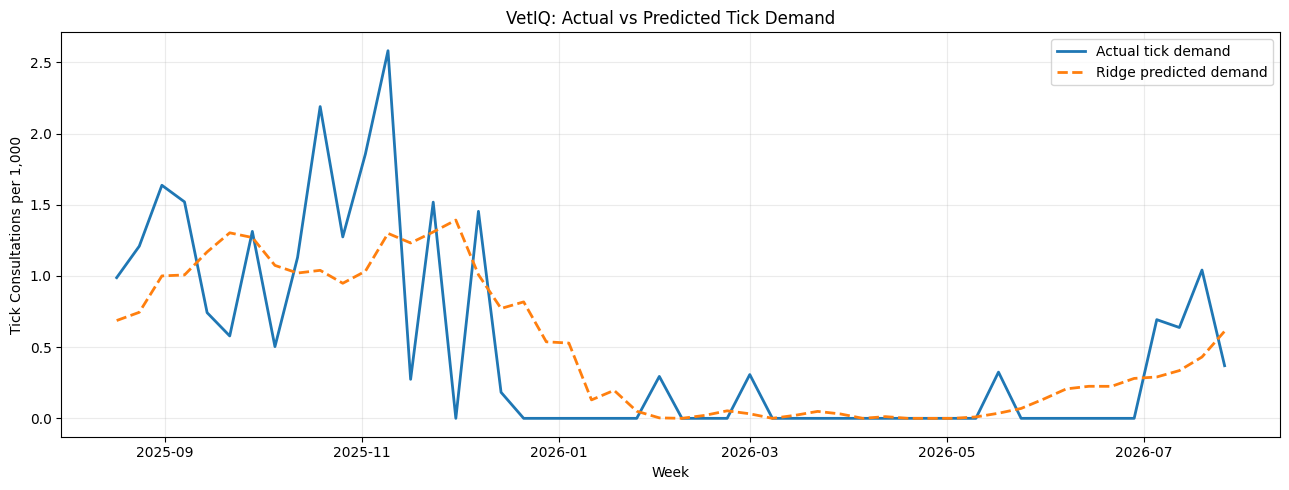

In [195]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

model = trained_models[
    ("Ridge Regression", "M2: Seasonality + Temperature")
]

cols = feature_sets["M2: Seasonality + Temperature"]

plot_df = test_exp[["Target_Date", "Target_2Week"]].copy()
plot_df["Predicted"] = np.maximum(
    model.predict(test_exp[cols]), 0
)

# Aggregate clinic predictions by target week for readability
weekly_plot = (
    plot_df.groupby("Target_Date")
    [["Target_2Week", "Predicted"]]
    .mean()
    .sort_index()
)

plt.figure(figsize=(13, 5))
plt.plot(
    weekly_plot.index,
    weekly_plot["Target_2Week"],
    label="Actual tick demand",
    linewidth=2
)
plt.plot(
    weekly_plot.index,
    weekly_plot["Predicted"],
    label="Ridge predicted demand",
    linewidth=2,
    linestyle="--"
)

plt.title("VetIQ: Actual vs Predicted Tick Demand")
plt.xlabel("Week")
plt.ylabel("Tick Consultations per 1,000")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


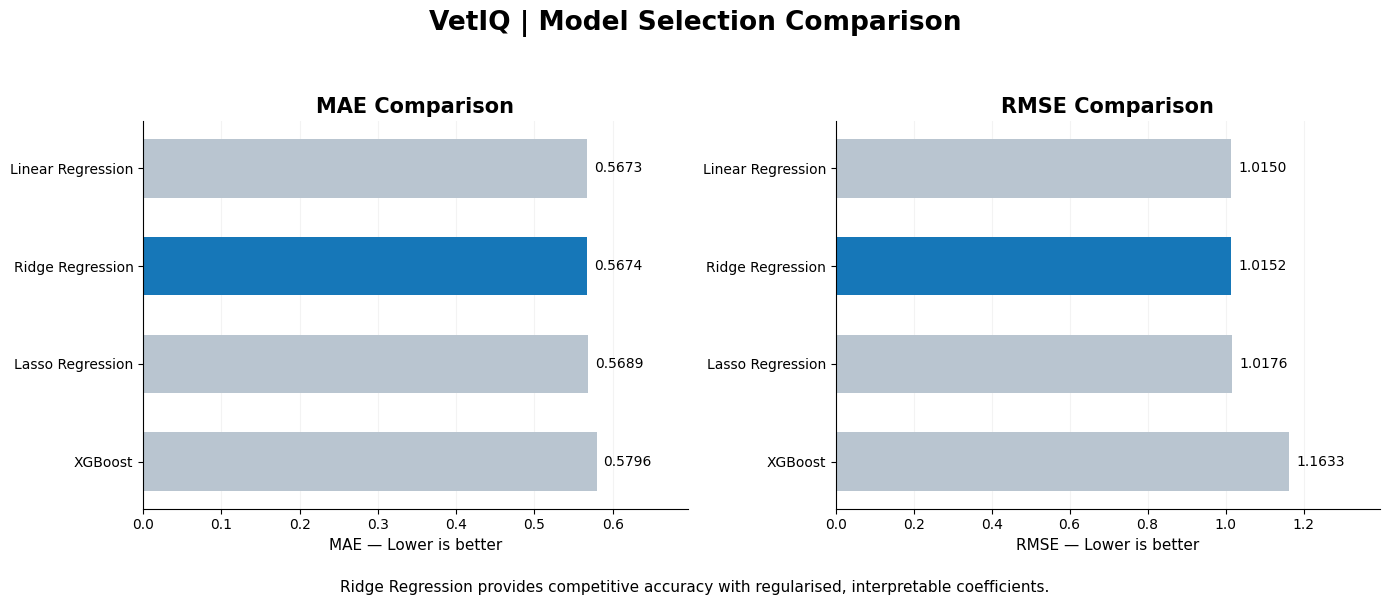

In [196]:


import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Remove Random Forest from the comparison
filtered_comparison = final_comparison[
    ~final_comparison["Model"].str.contains(
        "Random Forest",
        case=False,
        na=False
    )
].copy()

# Select each remaining model's best experiment by MAE
best = (
    filtered_comparison
    .sort_values("MAE")
    .drop_duplicates("Model")
    .sort_values("MAE")
    .reset_index(drop=True)
)

# Highlight Ridge Regression
colors = [
    "#1677B8" if "Ridge" in model
    else "#B9C5D0"
    for model in best["Model"]
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, metric in zip(axes, ["MAE", "RMSE"]):

    bars = ax.barh(
        best["Model"],
        best[metric],
        color=colors,
        height=0.6
    )

    ax.invert_yaxis()

    ax.set_title(
        f"{metric} Comparison",
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel(
        f"{metric} — Lower is better",
        fontsize=11
    )

    ax.set_xlim(0, best[metric].max() * 1.2)

    for bar, value in zip(bars, best[metric]):
        ax.text(
            value + best[metric].max() * 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.4f}",
            va="center",
            fontsize=10
        )

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)

fig.suptitle(
    "VetIQ | Model Selection Comparison",
    fontsize=19,
    fontweight="bold"
)

fig.text(
    0.5, 0.01,
    "Ridge Regression provides competitive accuracy "
    "with regularised, interpretable coefficients.",
    ha="center",
    fontsize=11
)

plt.tight_layout(rect=[0, 0.05, 1, 0.93])

plt.savefig(
    "vetiq_model_selection_without_random_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [197]:

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

required = [
    "ClinicID", "Week_End",
    "Tick_Consultations", "Total_Consultations",
    "AvgTemp_C", "Tick_Search_Index",
    "Season_Sin", "Season_Cos"
]

missing = [c for c in required if c not in model_df.columns]
assert not missing, f"Missing columns: {missing}"

stat_df = model_df[required].copy()
stat_df["Week_End"] = pd.to_datetime(stat_df["Week_End"])

stat_df = stat_df.replace([np.inf, -np.inf], np.nan)
stat_df = stat_df.dropna(subset=required)

# Valid binomial count observations
stat_df = stat_df[
    (stat_df["Total_Consultations"] > 0) &
    (stat_df["Tick_Consultations"] >= 0) &
    (stat_df["Tick_Consultations"] <= stat_df["Total_Consultations"])
].copy()

stat_df["Tick_Rate"] = (
    stat_df["Tick_Consultations"] /
    stat_df["Total_Consultations"]
)

stat_df["Log_Exposure"] = np.log(
    stat_df["Total_Consultations"]
)

# Same chronological split for all three models
dates = np.sort(stat_df["Week_End"].unique())
cutoff = dates[int(len(dates) * 0.8)]

stat_train = stat_df[stat_df["Week_End"] < cutoff].copy()
stat_test = stat_df[stat_df["Week_End"] >= cutoff].copy()

# Ensure test clinics were represented in training
stat_test = stat_test[
    stat_test["ClinicID"].isin(stat_train["ClinicID"])
].copy()

print("Training rows:", len(stat_train))
print("Testing rows:", len(stat_test))
print("Date range:", stat_df["Week_End"].min(),
      "to", stat_df["Week_End"].max())
print("Test begins:", stat_test["Week_End"].min())


Training rows: 2045
Testing rows: 294
Date range: 2021-10-03 00:00:00 to 2026-07-26 00:00:00
Test begins: 2025-08-10 00:00:00


In [198]:

formula = (
    "Tick_Rate ~ AvgTemp_C + Tick_Search_Index "
    "+ Season_Sin + Season_Cos + C(ClinicID)"
)

count_formula = formula.replace(
    "Tick_Rate ~", "Tick_Consultations ~"
)

# 1. Binomial GLM
binomial_glm = smf.glm(
    formula=formula,
    data=stat_train,
    family=sm.families.Binomial(),
    var_weights=stat_train["Total_Consultations"]
).fit()

# 2. Poisson GLM
poisson_glm = smf.glm(
    formula=count_formula,
    data=stat_train,
    family=sm.families.Poisson(),
    offset=stat_train["Log_Exposure"]
).fit()

# 3. Negative Binomial GLM
# Alpha is estimated from a discrete NB2 count model
nb_model = smf.negativebinomial(
    formula=count_formula,
    data=stat_train,
    offset=stat_train["Log_Exposure"]
)

negative_binomial = nb_model.fit(
    disp=False,
    maxiter=300
)

print("Binomial GLM fitted:", binomial_glm.converged)
print("Poisson GLM fitted:", poisson_glm.converged)
print("Negative Binomial fitted:",
      negative_binomial.mle_retvals.get("converged"))

print("\nNegative Binomial alpha:",
      negative_binomial.params["alpha"])


Binomial GLM fitted: True
Poisson GLM fitted: True
Negative Binomial fitted: True

Negative Binomial alpha: 0.4665535187849172


In [199]:

# Odds ratios and 95% confidence intervals
terms = [
    "AvgTemp_C",
    "Tick_Search_Index",
    "Season_Sin",
    "Season_Cos"
]

ci = binomial_glm.conf_int()

odds_ratio_df = pd.DataFrame({
    "Variable": terms,
    "Odds_Ratio": np.exp(binomial_glm.params[terms]),
    "CI_Lower": np.exp(ci.loc[terms, 0]),
    "CI_Upper": np.exp(ci.loc[terms, 1]),
    "P_Value": binomial_glm.pvalues[terms]
})

display(odds_ratio_df.round(4))


,Variable,Odds_Ratio,CI_Lower,CI_Upper,P_Value
AvgTemp_C,AvgTemp_C,0.9774,0.8970,1.0650,0.6019
Tick_Search_Index,Tick_Search_Index,1.0075,1.0010,1.0139,0.0225
Season_Sin,Season_Sin,0.2925,0.2022,0.4231,0.0000
Season_Cos,Season_Cos,1.3861,0.9191,2.0906,0.1194


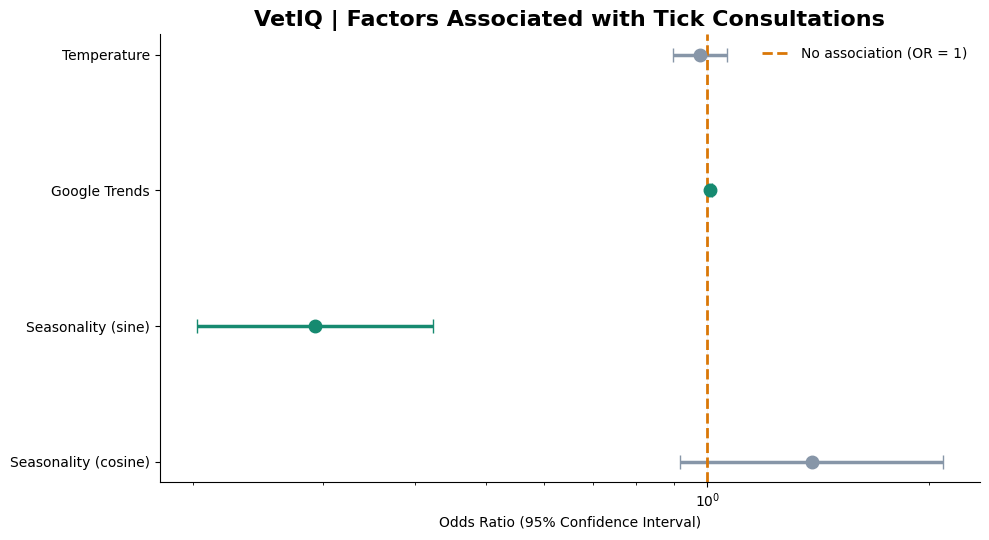

In [200]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

terms = [
    "AvgTemp_C", "Tick_Search_Index",
    "Season_Sin", "Season_Cos"
]

labels = [
    "Temperature",
    "Google Trends",
    "Seasonality (sine)",
    "Seasonality (cosine)"
]

ci = binomial_glm.conf_int().loc[terms]
or_values = np.exp(binomial_glm.params.loc[terms])
lower = np.exp(ci.iloc[:, 0])
upper = np.exp(ci.iloc[:, 1])

fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(terms))[::-1]

for i, (odds, lo, hi) in enumerate(
    zip(or_values, lower, upper)
):
    significant = lo > 1 or hi < 1
    color = "#168A70" if significant else "#8796A8"

    ax.errorbar(
        odds, y[i],
        xerr=[[odds-lo], [hi-odds]],
        fmt="o", markersize=9,
        capsize=5, linewidth=2.5,
        color=color
    )

ax.axvline(1, color="#D97706",
           linestyle="--", linewidth=2,
           label="No association (OR = 1)")

ax.set_yticks(y, labels)
ax.set_xscale("log")
ax.set_xlabel("Odds Ratio (95% Confidence Interval)")
ax.set_title(
    "VetIQ | Factors Associated with Tick Consultations",
    fontsize=16, fontweight="bold"
)

ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.15)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("vetiq_glm_forest.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [201]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Actual tick consultation rate per 1,000
actual = (
    stat_test["Tick_Consultations"]
    / stat_test["Total_Consultations"]
) * 1000

# Predictions from all three fitted models
predictions = {
    "Binomial GLM": (
        binomial_glm.predict(stat_test) * 1000
    ),

    "Poisson GLM": (
        poisson_glm.predict(
            stat_test,
            offset=stat_test["Log_Exposure"]
        ) / stat_test["Total_Consultations"] * 1000
    ),

    "Negative Binomial": (
        negative_binomial.predict(
            stat_test,
            offset=stat_test["Log_Exposure"]
        ) / stat_test["Total_Consultations"] * 1000
    )
}

# Calculate performance metrics
results = []

for model_name, predicted in predictions.items():
    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    })

stat_comparison = pd.DataFrame(results)
stat_comparison = stat_comparison.sort_values("MAE")

print("VetIQ | Statistical Model Comparison")
display(stat_comparison.round(4))

VetIQ | Statistical Model Comparison


,Model,MAE,RMSE
1,Poisson GLM,0.6231,1.1822
0,Binomial GLM,0.6232,1.1819
2,Negative Binomial,0.6676,1.2885


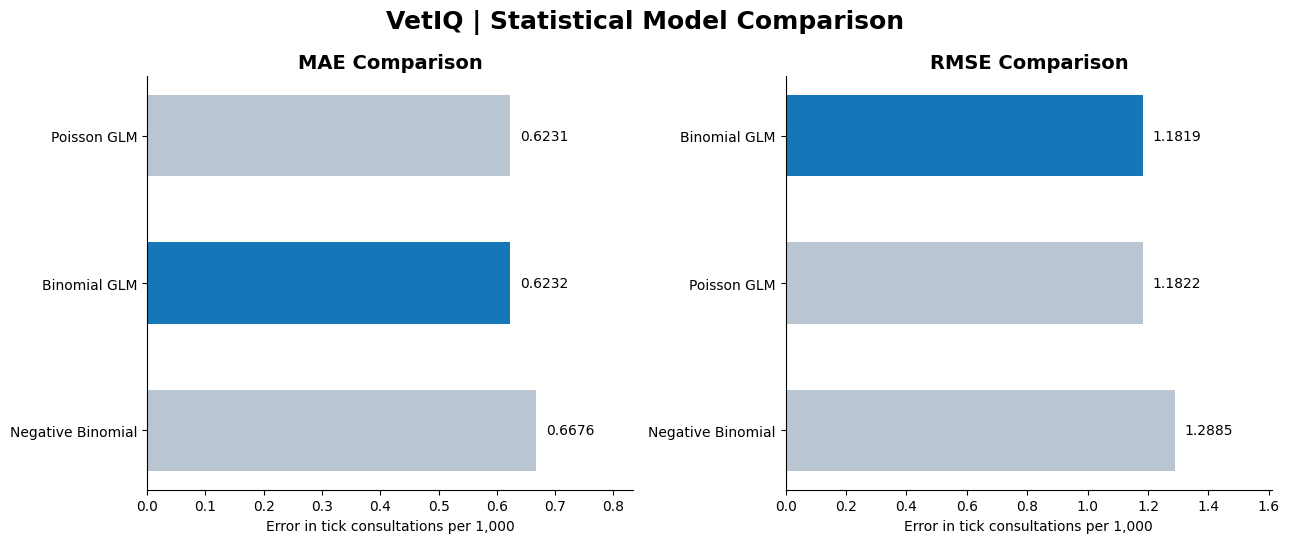

In [202]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, metric in zip(axes, ["MAE", "RMSE"]):

    data = stat_comparison.sort_values(metric)

    colors = [
        "#1677B8" if model == "Binomial GLM"
        else "#B9C5D0"
        for model in data["Model"]
    ]

    bars = ax.barh(
        data["Model"],
        data[metric],
        color=colors,
        height=0.55
    )

    ax.invert_yaxis()
    ax.set_xlim(0, data[metric].max() * 1.25)

    ax.set_title(
        f"{metric} Comparison",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Error in tick consultations per 1,000")

    for bar, value in zip(bars, data[metric]):
        ax.text(
            value + data[metric].max() * 0.025,
            bar.get_y() + bar.get_height()/2,
            f"{value:.4f}",
            va="center"
        )

    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "VetIQ | Statistical Model Comparison",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    "vetiq_statistical_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [203]:

import pandas as pd
import numpy as np
import re

# Use your existing combined dataset, or load it if needed
if "consult" in globals():
    raw = consult.copy()
else:
    raw = pd.read_csv("combined_5year.csv", low_memory=False)

raw["ClinicID"] = pd.to_numeric(raw["ClinicID"], errors="coerce")
raw["ConsultationDate"] = pd.to_datetime(
    raw["ConsultationDate"], errors="coerce", dayfirst=False
)

text_cols = [
    "ItemServiceFeeName",
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString"
]
text_cols = [c for c in text_cols if c in raw.columns]

pattern = r"\bticks?\b|\bixodes\b|\btick paralysis\b"

raw["Tick_Match_Audit"] = False
for col in text_cols:
    raw["Tick_Match_Audit"] |= (
        raw[col].fillna("").astype(str)
        .str.contains(pattern, case=False, regex=True)
    )

print("Fields examined:", text_cols)
print("Keyword pattern:", pattern)
print("Matching rows:", raw["Tick_Match_Audit"].sum())

# One consultation counted once per clinic
audit_ticks = raw.loc[
    raw["Tick_Match_Audit"] &
    raw["ClinicID"].notna() &
    raw["ConsultationKey"].notna() &
    raw["ConsultationDate"].notna()
].copy()

audit_ticks["Week_End"] = (
    audit_ticks["ConsultationDate"]
    .dt.to_period("W-SUN")
    .dt.end_time.dt.normalize()
)

audit_weekly = (
    audit_ticks.drop_duplicates(
        ["ClinicID", "ConsultationKey"]
    )
    .groupby(["ClinicID", "Week_End"])
    .size()
    .reset_index(name="Audit_Tick_Consultations")
)

if "tick_weekly" in globals():
    actual = tick_weekly.copy()
    actual["ClinicID"] = pd.to_numeric(
        actual["ClinicID"], errors="coerce"
    )
    actual["Week_End"] = pd.to_datetime(actual["Week_End"])

    actual = actual.groupby(
        ["ClinicID", "Week_End"], as_index=False
    )["Tick_Consultations"].sum()

    check = actual.merge(
        audit_weekly,
        on=["ClinicID", "Week_End"],
        how="outer"
    ).fillna({
        "Tick_Consultations": 0,
        "Audit_Tick_Consultations": 0
    })

    check["Difference"] = (
        check["Tick_Consultations"] -
        check["Audit_Tick_Consultations"]
    )

    print("Clinic-weeks compared:", len(check))
    print("Clinic-weeks with different counts:",
          (check["Difference"] != 0).sum())
    display(check.loc[check["Difference"] != 0].head(20))
else:
    print("tick_weekly is not loaded; comparison skipped.")


Fields examined: ['ItemServiceFeeName', 'ExaminationTextString', 'SummaryString', 'SpecialInstructionString']
Keyword pattern: \bticks?\b|\bixodes\b|\btick paralysis\b
Matching rows: 446185
Clinic-weeks compared: 5423
Clinic-weeks with different counts: 5402


,ClinicID,Week_End,Tick_Consultations,Audit_Tick_Consultations,Difference
0,1,2023-09-03,0.0,1.0,-1.0
1,1,2023-09-10,0.0,1.0,-1.0
2,1,2023-09-24,0.0,1.0,-1.0
3,1,2023-10-01,0.0,3.0,-3.0
4,1,2023-10-22,0.0,20.0,-20.0
5,1,2023-10-29,0.0,11.0,-11.0
6,1,2023-11-05,0.0,24.0,-24.0
7,1,2023-11-12,0.0,28.0,-28.0
8,1,2023-11-19,0.0,10.0,-10.0
9,1,2023-11-26,0.0,21.0,-21.0


In [204]:
import os

print("Current folder:", os.getcwd())

print("\nAvailable CSV files:")
for file in os.listdir():
    if file.lower().endswith(".csv"):
        print(file)

Current folder: /Users/sreelakshmi/Desktop/RMIT_final/project

Available CSV files:
weather_44clinics_daily.csv
qld_sa2_population_income.csv
temperature_correlation_19clinics.csv
vetiq_monthly_44clinics.csv
weekly_vetiq_weather_44clinics.csv
seq_19clinics_correlation_comparison.csv
weekly_vetiq_weather_19clinics.csv
temperature_lag_19clinics.csv
old_model_df.csv
weather_44clinics_weekly.csv
google_trends_vetiq_19clinics.csv
weather_daily_24clinics.csv
tick_clinic_monthly_preliminary.csv
seq_google_trends_lag_results.csv
weather_weekly_24clinics.csv
tracksandtrails.csv
clinic_weather_mapping.csv
google_trends_vetiq_44clinics.csv
tick_manual_review_19clinics.csv
seq_19clinics_google_weather_lags.csv
unique_weather_locations.csv
vetiq_weekly.csv
seq_19clinics_google_weather_vetiq.csv
old_trends_index.csv
old_clinic_weekly_weather.csv
weather_locations_24clinics.csv
seq_combined_google_trends_vetiq.csv
seq_google_weather_vetiq_monthly.csv
new_tick_weekly_by_clinic.csv
clinic_weekly_weathe

In [205]:
import pandas as pd

keywords = [
    "consult", "tick", "weekly", "clinic",
    "weather", "trend", "model", "ridge",
    "binomial", "experiment"
]

datasets = []

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if any(k in name.lower() for k in keywords) or len(obj) > 1_000_000:
            datasets.append({
                "Variable": name,
                "Rows": len(obj),
                "Columns": len(obj.columns),
                "Clinics": obj["ClinicID"].nunique()
                    if "ClinicID" in obj.columns else None
            })

dataset_inventory = pd.DataFrame(datasets)
display(dataset_inventory.sort_values("Rows", ascending=False))

,Variable,Rows,Columns,Clinics
108,activity,7641896,4,78.0
109,monthly_activity,7641896,5,78.0
110,tick_source,7641896,10,78.0
31,coverage_source,7641896,10,78.0
7,consult,7641896,9,78.0
...,...,...,...,...
15,overlap_clinics,3,4,3.0
43,peak_tick,3,4,NaN
22,clinic_102,1,8,1.0
75,clinic_106_mapping,1,6,1.0


In [206]:
import numpy as np

# Prefer the dataset before complete-case filtering
possible = [
    "binomial_final",
    "final_binomial",
    "model_df"
]

source_name = next(
    (
        name for name in possible
        if name in globals()
        and isinstance(globals()[name], pd.DataFrame)
        and {"AvgTemp_C", "Tick_Search_Index"}.issubset(
            globals()[name].columns
        )
    ),
    None
)

if source_name is None:
    print("No suitable merged weather/Google Trends dataset found.")
else:
    audit_df = globals()[source_name]

    print("Dataset:", source_name)
    print("Total clinic-week rows:", len(audit_df))

    weather_missing = audit_df["AvgTemp_C"].isna()
    trends_missing = audit_df["Tick_Search_Index"].isna()

    missing_summary = pd.DataFrame({
        "Category": [
            "Weather missing only",
            "Google Trends missing only",
            "Both missing",
            "Both available"
        ],
        "Rows": [
            (weather_missing & ~trends_missing).sum(),
            (~weather_missing & trends_missing).sum(),
            (weather_missing & trends_missing).sum(),
            (~weather_missing & ~trends_missing).sum()
        ]
    })

    display(missing_summary)

    print("\nMissing percentage by column:")
    display(
        audit_df.isna()
        .mean()
        .mul(100)
        .sort_values(ascending=False)
        .head(20)
        .round(2)
    )

Dataset: binomial_final
Total clinic-week rows: 2566


,Category,Rows
0,Weather missing only,0
1,Google Trends missing only,0
2,Both missing,0
3,Both available,2566



Missing percentage by column:


ClinicID               0.0
Week_End               0.0
Total_Consultations    0.0
Tick_Consultations     0.0
Tick_Rate              0.0
Tick_per_1000          0.0
AvgTemp_C              0.0
Rainfall_mm            0.0
Humidity_pct           0.0
WeekOfYear             0.0
Season_Sin             0.0
Season_Cos             0.0
YearMonth              0.0
Tick_Search_Index      0.0
dtype: float64

In [207]:
print("Tick source columns:")
print(tick_source.columns.tolist())

print("\nFirst 5 rows:")
display(tick_source.head())

print("\nTick-related columns:")
print([
    col for col in tick_source.columns
    if "tick" in col.lower()
])

Tick source columns:
['ConsultationKey', 'ClinicID', 'ClinicPseudonym', 'ConsultationDate', 'ItemServiceFeeName', 'ExaminationTextString', 'SummaryString', 'SpecialInstructionString', 'DataSource', 'Tick_Match']

First 5 rows:


,ConsultationKey,ClinicID,ClinicPseudonym,ConsultationDate,ItemServiceFeeName,ExaminationTextString,SummaryString,SpecialInstructionString,DataSource,Tick_Match
0,A726C982F0D077B2DBDA21FA915EF54B4E6C503BC9BEC1...,8,Clinic_08,2021-10-01,Standard Fee,NaN,NaN,NaN,Consultation.csv,False
1,37BDEB8EE25F1103F14F312F351F32BE25CBB908F2E9F9...,8,Clinic_08,2021-10-01,Standard Fee,NaN,NaN,NaN,Consultation.csv,False
2,9914B7E657C41B48039E8F87F2453BAF4E0F6750190834...,8,Clinic_08,2021-10-01,Standard Fee,NaN,NaN,NaN,Consultation.csv,False
3,1F0BE8BD616A94C4F33374337396824196BEFDC2975192...,8,Clinic_08,2021-10-01,Standard Fee,NaN,NaN,NaN,Consultation.csv,False
4,08BDFDE5077878933F768190667CDD82D33D4B60C9C193...,8,Clinic_08,2021-10-01,1st Animal,NaN,NaN,NaN,Consultation.csv,False



Tick-related columns:
['Tick_Match']


In [208]:
for name in [
    "weekly_total",
    "tick_weekly",
    "binomial_final",
    "model_df",
    "ridge_model_df",
    "experiment_df"
]:
    if name in globals():
        data = globals()[name]

        print(f"\n{name}")
        print("Rows:", len(data))
        print("Clinics:", data["ClinicID"].nunique()
              if "ClinicID" in data.columns else "N/A")
        print("Columns:", data.columns.tolist())


weekly_total
Rows: 9966
Clinics: 78
Columns: ['ClinicID', 'Week_End', 'Available_Consultations']

tick_weekly
Rows: 1167
Clinics: 29
Columns: ['ClinicID', 'Week_End', 'Tick_Consultations']

binomial_final
Rows: 2566
Clinics: 23
Columns: ['ClinicID', 'Week_End', 'Total_Consultations', 'Tick_Consultations', 'Tick_Rate', 'Tick_per_1000', 'AvgTemp_C', 'Rainfall_mm', 'Humidity_pct', 'WeekOfYear', 'Season_Sin', 'Season_Cos', 'YearMonth', 'Tick_Search_Index']

model_df
Rows: 2339
Clinics: 19
Columns: ['ClinicID', 'Week_End', 'Total_Consultations', 'YearMonth', 'AvgTemp_C', 'Tick_Consultations', 'Tick_Rate', 'Tick_per_1000', 'WeekOfYear', 'Season_Sin', 'Season_Cos', 'Tick_Search_Index']

ridge_model_df
Rows: 2382
Clinics: 19
Columns: ['ClinicID', 'Week_End', 'Total_Consultations', 'Tick_Consultations', 'Tick_Rate', 'Tick_per_1000', 'AvgTemp_C', 'Rainfall_mm', 'Humidity_pct', 'WeekOfYear', 'Season_Sin', 'Season_Cos', 'YearMonth', 'Tick_Search_Index', 'Tick_Current', 'Tick_Lag_1', 'Tick_Lag_2',

In [209]:
print("Total consultation records:", f"{len(tick_source):,}")

print("\nTick classification:")
print(tick_source["Tick_Match"].value_counts(dropna=False))

print("\nUnique consultations flagged as tick-related:")
tick_cases = tick_source.loc[
    tick_source["Tick_Match"] == True,
    ["ClinicID", "ConsultationKey"]
]

print(
    f"{tick_cases.drop_duplicates().shape[0]:,}"
)

print("\nTick-related records by source:")
print(
    tick_source.groupby("DataSource")["Tick_Match"]
    .agg(["count", "sum"])
)

Total consultation records: 7,641,896

Tick classification:
Tick_Match
False    7195711
True      446185
Name: count, dtype: int64

Unique consultations flagged as tick-related:
446,185

Tick-related records by source:
                              count     sum
DataSource                                 
Consultation.csv            1048575     111
consultations_freetext.csv  6593321  446074


In [210]:
import pandas as pd

datasets = {
    "weekly_total": weekly_total,
    "tick_weekly": tick_weekly,
    "binomial_final": binomial_final,
    "model_df": model_df,
    "ridge_model_df": ridge_model_df,
    "experiment_df": experiment_df
}

keys = {}

for name, data in datasets.items():
    temp = data[["ClinicID", "Week_End"]].copy()
    temp["ClinicID"] = temp["ClinicID"].astype(str)
    temp["Week_End"] = pd.to_datetime(temp["Week_End"]).dt.normalize()

    keys[name] = set(map(tuple, temp.drop_duplicates().to_numpy()))

comparisons = [
    ("weekly_total", "binomial_final"),
    ("binomial_final", "model_df"),
    ("model_df", "ridge_model_df"),
    ("ridge_model_df", "experiment_df")
]

for before, after in comparisons:
    print(f"\n{before} → {after}")
    print("Shared clinic-weeks:", len(keys[before] & keys[after]))
    print("Only in first:", len(keys[before] - keys[after]))
    print("Only in second:", len(keys[after] - keys[before]))


weekly_total → binomial_final
Shared clinic-weeks: 2566
Only in first: 7400
Only in second: 0

binomial_final → model_df
Shared clinic-weeks: 2339
Only in first: 227
Only in second: 0

model_df → ridge_model_df
Shared clinic-weeks: 2174
Only in first: 165
Only in second: 208

ridge_model_df → experiment_df
Shared clinic-weeks: 2145
Only in first: 237
Only in second: 51


In [211]:
clinic_weekly_weather.to_csv("old_clinic_weekly_weather.csv", index=False)
trends[["Month", "Tick_Search_Index"]].to_csv("old_trends_index.csv", index=False)
model_df.to_csv("old_model_df.csv", index=False)   # the exact table the experiment used

In [212]:
# ============================================================
# CHECK ORIGINAL NOTEBOOK — RIDGE FORECASTING DATASET
# ============================================================

print("ORIGINAL NOTEBOOK")
print("=" * 60)

print("Clinics:", ridge_model_df["ClinicID"].nunique())
print("Observations:", len(ridge_model_df))

print("\nClinic IDs:")
print(sorted(ridge_model_df["ClinicID"].unique()))

print("\nDate range:")
print(
    ridge_model_df["Week_End"].min(),
    "to",
    ridge_model_df["Week_End"].max()
)

print("\nTARGET DISTRIBUTION")
print(ridge_model_df["Target_2w"].describe().round(4))

print("\nZERO-RATE OBSERVATIONS")
print(
    round(
        (ridge_model_df["Target_2w"] == 0).mean() * 100,
        2
    ),
    "%"
)

print("\nFEATURES")
print(ridge_features_required)

ORIGINAL NOTEBOOK
Clinics: 19
Observations: 2382

Clinic IDs:
[np.int64(8), np.int64(15), np.int64(17), np.int64(18), np.int64(21), np.int64(22), np.int64(99), np.int64(101), np.int64(102), np.int64(104), np.int64(105), np.int64(106), np.int64(107), np.int64(108), np.int64(136), np.int64(138), np.int64(241), np.int64(329), np.int64(338)]

Date range:
2021-10-31 00:00:00 to 2026-07-12 00:00:00

TARGET DISTRIBUTION
count    2382.0000
mean        1.2030
std        15.5007
min         0.0000
25%         0.0000
50%         0.0000
75%         0.0000
max       333.3333
Name: Target_2w, dtype: float64

ZERO-RATE OBSERVATIONS
86.65 %

FEATURES
['Tick_Current', 'Tick_Lag_1', 'Tick_Lag_2', 'Tick_Lag_3', 'Tick_Lag_4', 'Tick_Prev4w_Avg', 'Season_Sin', 'Season_Cos', 'AvgTemp_C', 'Tick_Search_Index', 'Target_2w']


In [213]:

# ============================================================
# OLD NOTEBOOK — FIND CLINIC GEOGRAPHICAL DATASETS
# ============================================================

import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if "ClinicID" in obj.columns:
            location_cols = [
                c for c in obj.columns
                if any(
                    word in str(c).lower()
                    for word in [
                        "suburb",
                        "postcode",
                        "state",
                        "location",
                        "latitude",
                        "longitude"
                    ]
                )
            ]

            if location_cols:
                print(
                    f"\n{name}: "
                    f"{len(obj)} rows, "
                    f"{obj['ClinicID'].nunique()} clinics"
                )
                print("Location columns:", location_cols)



sample: 5 rows, 2 clinics
Location columns: ['StateCode']

clinics: 48 rows, 48 clinics
Location columns: ['SuburbName', 'StateCode']

master_clinics: 48 rows, 48 clinics
Location columns: ['SuburbName', 'StateCode', 'Postcode', 'Suburb', 'WeatherLocationID', 'latitude', 'longitude']

tick_data: 1672 rows, 29 clinics
Location columns: ['StateCode']

new_clinics: 48 rows, 48 clinics
Location columns: ['SuburbName', 'StateCode']

overlap_clinics: 3 rows, 3 clinics
Location columns: ['SuburbName', 'StateCode']

old_clinics: 62 rows, 62 clinics
Location columns: ['Postcode', 'Suburb', 'StateCode']

weather_map: 62 rows, 62 clinics
Location columns: ['Postcode', 'Suburb', 'WeatherLocationID', 'latitude', 'longitude']

master_analysis_clinics: 26 rows, 26 clinics
Location columns: ['SuburbName', 'StateCode', 'Postcode', 'Suburb', 'WeatherLocationID', 'latitude', 'longitude']

clinic_location_matches: 66 rows, 48 clinics
Location columns: ['SuburbName', 'StateCode', 'Suburb', 'Postcode', 'Ma

In [214]:

# ============================================================
# OLD NOTEBOOK — VALIDATE FINAL 19 CLINICS
# ============================================================

import pandas as pd

final_ids = set(candidate_cohort["ClinicID"].dropna())

original_ids = set(clinics["ClinicID"].dropna())

seq_weather_ids = set(
    seq_weather_clinics["ClinicID"].dropna()
)

location_ids = set(
    eligible_location_check["ClinicID"].dropna()
)

print("=" * 60)
print("OLD NOTEBOOK — FINAL CLINIC VALIDATION")
print("=" * 60)

print("Final candidate clinics:", len(final_ids))
print("Present in original Clinics.csv:",
      len(final_ids & original_ids))
print("Present in SEQ weather cohort:",
      len(final_ids & seq_weather_ids))
print("Present in location validation:",
      len(final_ids & location_ids))

print("\nFINAL CLINIC IDs")
print(sorted(final_ids))

print("\nNOT IN ORIGINAL CLINICS.CSV")
print(sorted(final_ids - original_ids))

print("\nNOT IN SEQ WEATHER COHORT")
print(sorted(final_ids - seq_weather_ids))

print("\nFINAL CLINIC LOCATION DETAILS")

display(
    eligible_location_check[
        [
            "ClinicID",
            "SuburbName",
            "Suburb",
            "Postcode",
            "WeatherLocationID"
        ]
    ].sort_values("ClinicID")
)


OLD NOTEBOOK — FINAL CLINIC VALIDATION
Final candidate clinics: 19
Present in original Clinics.csv: 19
Present in SEQ weather cohort: 16
Present in location validation: 19

FINAL CLINIC IDs
[8, 15, 17, 18, 99, 101, 102, 104, 105, 106, 107, 108, 136, 138, 154, 176, 241, 329, 338]

NOT IN ORIGINAL CLINICS.CSV
[]

NOT IN SEQ WEATHER COHORT
[106, 154, 176]

FINAL CLINIC LOCATION DETAILS


,ClinicID,SuburbName,Suburb,Postcode,WeatherLocationID
0,8,D******** B**,Harristown,4350.0,Weather_07
1,15,A******** H******,Miami,4220.0,Weather_13
2,17,R****** P*****,Flagstone,4280.0,Weather_15
3,18,S**********,Loganholme,4129.0,Weather_16
4,99,K*****,NaN,NaN,NaN
5,101,B*****,NaN,NaN,NaN
6,102,A*******,NaN,NaN,NaN
7,104,J********,NaN,NaN,NaN
8,105,M****,NaN,NaN,NaN
9,106,H*********,NaN,NaN,NaN


In [215]:

# OLD NOTEBOOK — CHECK ACTUAL TEMPERATURE ANALYSIS COHORT

final_ids = set(candidate_cohort["ClinicID"].dropna())
weather_ids = set(seq_weather_clinics["ClinicID"].dropna())

temperature_ids = set(
    clinic_temperature_results_new["ClinicID"].dropna()
)

print("Final candidate clinics:", len(final_ids))
print("Temperature analysis clinics:", len(temperature_ids))

print("\nTemperature clinics outside final candidate cohort:")
print(sorted(temperature_ids - final_ids))

print("\nFinal candidate clinics missing from temperature analysis:")
print(sorted(final_ids - temperature_ids))

print("\nTemperature clinics outside original SEQ weather cohort:")
print(sorted(temperature_ids - weather_ids))

print("\nTEMPERATURE RESULTS")
display(clinic_temperature_results_new)


Final candidate clinics: 19
Temperature analysis clinics: 19

Temperature clinics outside final candidate cohort:
[21, 22]

Final candidate clinics missing from temperature analysis:
[154, 176]

Temperature clinics outside original SEQ weather cohort:
[106]

TEMPERATURE RESULTS


,ClinicID,Weeks,Tick_Consultations,Temp_Rho_1w,Temp_P_1w,Temp_Rho_2w,Temp_P_2w,SuburbName
0,8,240,10.0,0.083020,0.200919,0.093557,0.150184,D******** B**
1,15,157,59.0,0.040457,0.616054,0.057494,0.477342,A******** H******
2,17,157,39.0,0.073390,0.362562,0.077559,0.337442,R****** P*****
3,18,157,9.0,0.057128,0.478719,0.088055,0.275923,S**********
4,21,177,32.0,0.072908,0.336237,0.153242,0.042904,G********
5,22,186,104.0,0.032408,0.661439,0.014414,0.846023,N**** M******
6,99,110,5.0,0.036026,0.709964,0.097720,0.314352,K*****
7,101,110,3.0,0.083484,0.388104,0.091099,0.348419,B*****
8,102,110,11.0,-0.073886,0.445139,0.015964,0.869743,A*******
9,104,110,22.0,0.190613,0.047105,0.165163,0.087599,J********


In [216]:

# Inspect the original forecasting setup

import pandas as pd
import numpy as np

print("=== AVAILABLE FORECASTING VARIABLES ===")

for name in [
    "train_exp", "test_exp", "feature_sets",
    "train", "test", "model_df",
    "weekly_analysis_19", "final_comparison"
]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: {type(obj).__name__}")
        if isinstance(obj, pd.DataFrame):
            print("Shape:", obj.shape)
            print("Columns:", obj.columns.tolist())
        elif isinstance(obj, dict):
            print("Keys:", list(obj.keys()))

print("\n=== ORIGINAL TARGET CANDIDATES ===")
for name in [
    "Tick_per_1000", "Tick_Proportion",
    "Tick_Mention_Rate", "Target_2Week",
    "Tick_Consultations", "Total_Consultations"
]:
    if name in globals():
        print(name, "is available")


=== AVAILABLE FORECASTING VARIABLES ===

train_exp: DataFrame
Shape: (1896, 22)
Columns: ['ClinicID', 'Week_End', 'Total_Consultations', 'YearMonth', 'AvgTemp_C', 'Tick_Consultations', 'Tick_Rate', 'Tick_per_1000', 'WeekOfYear', 'Season_Sin', 'Season_Cos', 'Tick_Search_Index', 'Target_Date', 'Target_2Week', 'Tick_Lag_0', 'Tick_Lag_1', 'Tick_Lag_2', 'Tick_Lag_4', 'Temp_Current', 'Trends_Current', 'Season_Sin_2w', 'Season_Cos_2w']

test_exp: DataFrame
Shape: (288, 22)
Columns: ['ClinicID', 'Week_End', 'Total_Consultations', 'YearMonth', 'AvgTemp_C', 'Tick_Consultations', 'Tick_Rate', 'Tick_per_1000', 'WeekOfYear', 'Season_Sin', 'Season_Cos', 'Tick_Search_Index', 'Target_Date', 'Target_2Week', 'Tick_Lag_0', 'Tick_Lag_1', 'Tick_Lag_2', 'Tick_Lag_4', 'Temp_Current', 'Trends_Current', 'Season_Sin_2w', 'Season_Cos_2w']

feature_sets: dict
Keys: ['M1: Seasonality', 'M2: Seasonality + Temperature', 'M3: Seasonality + Google Trends', 'M4: Combined']

train: Series

test: Series

model_df: DataFr

=== ORIGINAL TARGET VALIDATION ===
Training rows: 1896
Testing rows: 288

Training target statistics:


count    1896.0000
mean        0.4465
std         1.6409
min         0.0000
25%         0.0000
50%         0.0000
75%         0.0000
max        25.0000
Name: Target_2Week, dtype: float64


Testing target statistics:


count    288.0000
mean       0.5024
std        1.2305
min        0.0000
25%        0.0000
50%        0.0000
75%        0.0000
max        8.1037
Name: Target_2Week, dtype: float64


=== ORIGINAL RIDGE MODEL COMPARISON ===


,Model,"MAE (per 1,000)","RMSE (per 1,000)"
0,R1: history + season,0.5677,1.0148
1,R2: R1 + temperature,0.5674,1.0152
2,R3: R1 + Google Trends,0.5887,1.0127
3,R4: R1 + both,0.5865,1.0148
4,Persistence benchmark,0.5556,1.3083



=== BEST RIDGE MODEL BY MAE ===


,Model,"MAE (per 1,000)","RMSE (per 1,000)"
1,R2: R1 + temperature,0.5674,1.0152



=== BEST RIDGE MODEL BY RMSE ===


,Model,"MAE (per 1,000)","RMSE (per 1,000)"
2,R3: R1 + Google Trends,0.5887,1.0127


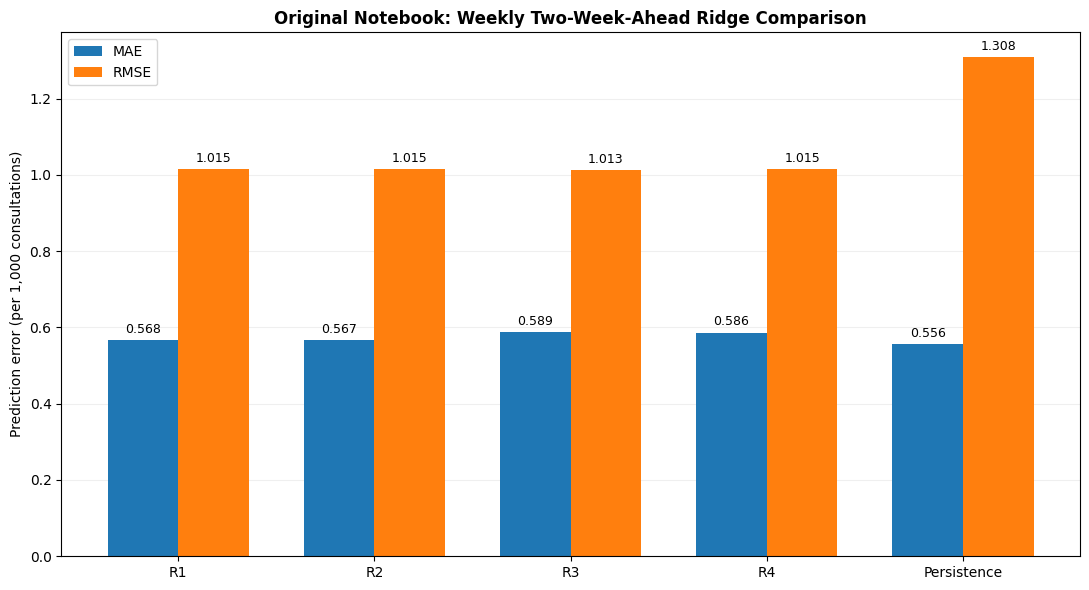

In [217]:

# ============================================================
# SECTION 3.4 — ORIGINAL WEEKLY TWO-WEEK-AHEAD RIDGE COMPARISON
# Original target, train/test split and feature experiments
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. Validate the original notebook variables
# ------------------------------------------------------------

required_objects = ["train_exp", "test_exp", "feature_sets"]

for variable in required_objects:
    assert variable in globals(), (
        f"{variable} is missing. Run the original preparation cells."
    )

train_df = train_exp.copy()
test_df = test_exp.copy()

target = "Target_2Week"

assert target in train_df.columns and target in test_df.columns
assert len(train_df) > 0 and len(test_df) > 0

# Confirm target units and distributions
print("=== ORIGINAL TARGET VALIDATION ===")
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("\nTraining target statistics:")
display(train_df[target].describe().round(4))

print("\nTesting target statistics:")
display(test_df[target].describe().round(4))

# ------------------------------------------------------------
# 2. Define the four Ridge configurations
# ------------------------------------------------------------

ridge_feature_sets = {
    "R1: history + season":
        feature_sets["M1: Seasonality"],

    "R2: R1 + temperature":
        feature_sets["M2: Seasonality + Temperature"],

    "R3: R1 + Google Trends":
        feature_sets["M3: Seasonality + Google Trends"],

    "R4: R1 + both":
        feature_sets["M4: Combined"]
}

# ------------------------------------------------------------
# 3. Fit Ridge Regression and evaluate the test set
# ------------------------------------------------------------

ridge_results = []
ridge_models = {}
ridge_predictions = {}

y_train = train_df[target].to_numpy(dtype=float)
y_test = test_df[target].to_numpy(dtype=float)

assert np.isfinite(y_train).all(), "Invalid training target values."
assert np.isfinite(y_test).all(), "Invalid testing target values."

for name, features in ridge_feature_sets.items():

    missing_train = [
        col for col in features if col not in train_df.columns
    ]
    missing_test = [
        col for col in features if col not in test_df.columns
    ]

    assert not missing_train, f"{name}: missing training features {missing_train}"
    assert not missing_test, f"{name}: missing testing features {missing_test}"

    X_train = train_df[features].to_numpy(dtype=float)
    X_test = test_df[features].to_numpy(dtype=float)

    assert np.isfinite(X_train).all(), f"{name}: invalid training features"
    assert np.isfinite(X_test).all(), f"{name}: invalid testing features"

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10)
    )

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", RuntimeWarning)
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

    # Avoid negative predicted consultation rates
    predictions = np.maximum(predictions, 0)

    assert np.isfinite(predictions).all(), (
        f"{name}: predictions contain NaN or infinity."
    )

    ridge_models[name] = model
    ridge_predictions[name] = predictions

    ridge_results.append({
        "Model": name,
        "MAE (per 1,000)": mean_absolute_error(
            y_test, predictions
        ),
        "RMSE (per 1,000)": np.sqrt(
            mean_squared_error(y_test, predictions)
        )
    })

    if caught:
        print(f"Warning: {name} generated {len(caught)} runtime warnings.")

# ------------------------------------------------------------
# 4. Persistence benchmark
# ------------------------------------------------------------

assert "Tick_Lag_0" in test_df.columns

persistence = test_df["Tick_Lag_0"].to_numpy(dtype=float)

assert np.isfinite(persistence).all()

ridge_results.append({
    "Model": "Persistence benchmark",
    "MAE (per 1,000)": mean_absolute_error(
        y_test, persistence
    ),
    "RMSE (per 1,000)": np.sqrt(
        mean_squared_error(y_test, persistence)
    )
})

ridge_comparison_old = pd.DataFrame(ridge_results)

print("\n=== ORIGINAL RIDGE MODEL COMPARISON ===")
display(ridge_comparison_old.round(4))

print("\n=== BEST RIDGE MODEL BY MAE ===")
display(
    ridge_comparison_old.iloc[:4]
    .sort_values("MAE (per 1,000)")
    .head(1)
    .round(4)
)

print("\n=== BEST RIDGE MODEL BY RMSE ===")
display(
    ridge_comparison_old.iloc[:4]
    .sort_values("RMSE (per 1,000)")
    .head(1)
    .round(4)
)

# ------------------------------------------------------------
# 5. Visualise MAE and RMSE
# ------------------------------------------------------------

plot_df = ridge_comparison_old.copy()

x = np.arange(len(plot_df))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width / 2,
    plot_df["MAE (per 1,000)"],
    width,
    label="MAE"
)

bars2 = ax.bar(
    x + width / 2,
    plot_df["RMSE (per 1,000)"],
    width,
    label="RMSE"
)

ax.set_title(
    "Original Notebook: Weekly Two-Week-Ahead Ridge Comparison",
    fontweight="bold"
)
ax.set_ylabel("Prediction error (per 1,000 consultations)")
ax.set_xticks(x)
ax.set_xticklabels(
    ["R1", "R2", "R3", "R4", "Persistence"]
)
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for bars in [bars1, bars2]:
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

plt.tight_layout()
plt.savefig(
    "original_ridge_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Training rows: 1896
Testing rows: 288
Forecast horizon: 2 weeks
Feature configurations: 4

=== TOTAL EXPERIMENTS ===
Completed: 16
Failed: 0

=== MAE COMPARISON ===


Experiment,M1: Seasonality,M2: Seasonality + Temperature,M3: Seasonality + Google Trends,M4: Combined
Model,,,,
Lasso Regression,0.5695,0.5689,0.5884,0.5864
Linear Regression,0.5676,0.5673,0.5891,0.5870
Ridge Regression,0.5677,0.5674,0.5887,0.5865
XGBoost,0.5923,0.5909,0.5796,0.5810



=== RMSE COMPARISON ===


Experiment,M1: Seasonality,M2: Seasonality + Temperature,M3: Seasonality + Google Trends,M4: Combined
Model,,,,
Lasso Regression,1.0172,1.0176,1.0150,1.0168
Linear Regression,1.0147,1.0150,1.0126,1.0150
Ridge Regression,1.0148,1.0152,1.0127,1.0148
XGBoost,1.2929,1.2614,1.1633,1.1816



=== BEST FIVE COMBINATIONS BY MAE ===


,Model,Experiment,MAE,RMSE
4,Linear Regression,M2: Seasonality + Temperature,0.5673,1.0150
6,Ridge Regression,M2: Seasonality + Temperature,0.5674,1.0152
0,Linear Regression,M1: Seasonality,0.5676,1.0147
2,Ridge Regression,M1: Seasonality,0.5677,1.0148
5,Lasso Regression,M2: Seasonality + Temperature,0.5689,1.0176



=== BEST FIVE COMBINATIONS BY RMSE ===


,Model,Experiment,MAE,RMSE
8,Linear Regression,M3: Seasonality + Google Trends,0.5891,1.0126
10,Ridge Regression,M3: Seasonality + Google Trends,0.5887,1.0127
0,Linear Regression,M1: Seasonality,0.5676,1.0147
2,Ridge Regression,M1: Seasonality,0.5677,1.0148
14,Ridge Regression,M4: Combined,0.5865,1.0148



=== PERSISTENCE BENCHMARK ===
MAE: 0.5556
RMSE: 1.3083

=== BEST EXPERIMENT FOR EACH MODEL ===


,Model,Experiment,MAE,RMSE
0,Linear Regression,M2: Seasonality + Temperature,0.5673,1.0150
1,Ridge Regression,M2: Seasonality + Temperature,0.5674,1.0152
2,Lasso Regression,M2: Seasonality + Temperature,0.5689,1.0176
3,XGBoost,M3: Seasonality + Google Trends,0.5796,1.1633


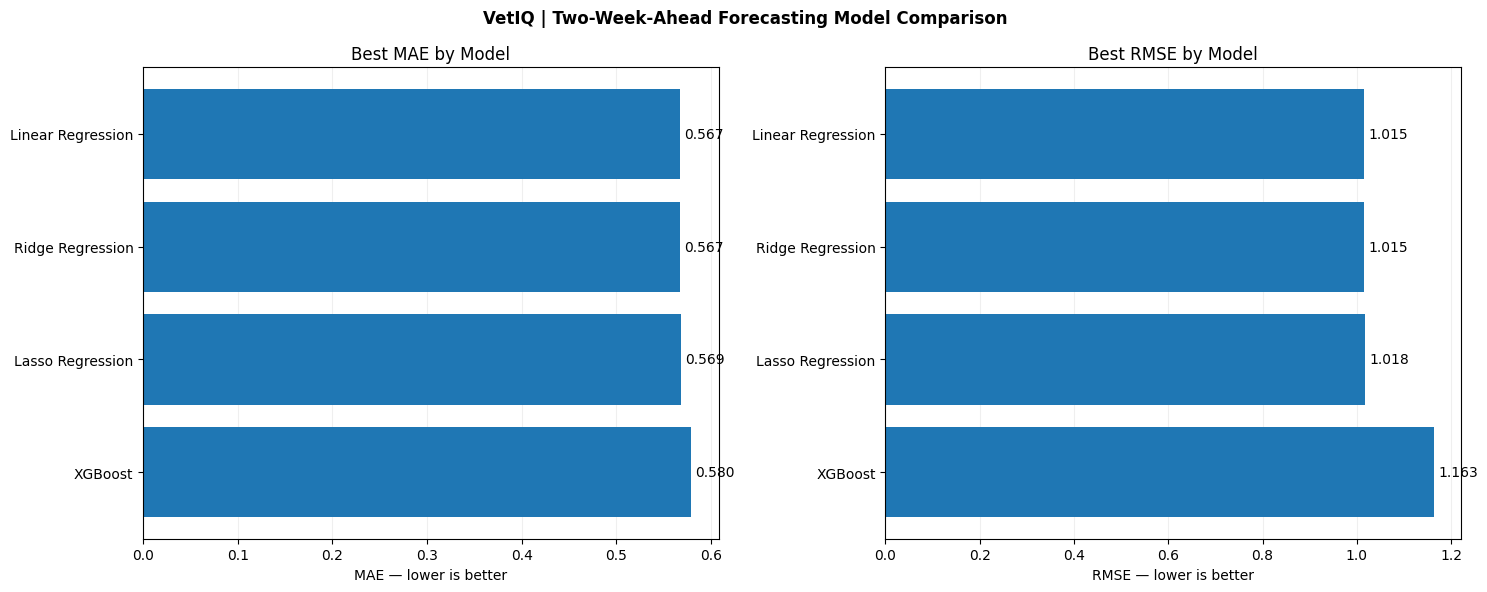


=== NUMERICAL WARNING SUMMARY ===


,Model,Experiment,Warnings
0,Linear Regression,M1: Seasonality,3
1,Lasso Regression,M1: Seasonality,3
2,Ridge Regression,M1: Seasonality,3
3,Linear Regression,M2: Seasonality + Temperature,3
4,Lasso Regression,M2: Seasonality + Temperature,3
5,Ridge Regression,M2: Seasonality + Temperature,3
6,Linear Regression,M3: Seasonality + Google Trends,3
7,Lasso Regression,M3: Seasonality + Google Trends,3
8,Ridge Regression,M3: Seasonality + Google Trends,3
9,Linear Regression,M4: Combined,3


In [218]:

# ============================================================
# STEP 3.5 — ALL MODEL COMPARISONS
# Original notebook | Weekly two-week-ahead forecasting
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

try:
    from xgboost import XGBRegressor
except ImportError:
    raise ImportError(
        "Install XGBoost first using %pip install xgboost"
    )

# ------------------------------------------------------------
# 1. Validate original data and feature sets
# ------------------------------------------------------------

assert "train_exp" in globals(), "Run original data preparation first."
assert "test_exp" in globals(), "Run original data preparation first."
assert "feature_sets" in globals(), "feature_sets is missing."

train_df = train_exp.copy()
test_df = test_exp.copy()
target = "Target_2Week"

y_train = train_df[target].to_numpy(dtype=float)
y_test = test_df[target].to_numpy(dtype=float)

assert np.isfinite(y_train).all()
assert np.isfinite(y_test).all()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Forecast horizon: 2 weeks")
print("Feature configurations:", len(feature_sets))

# ------------------------------------------------------------
# 2. Define models
# ------------------------------------------------------------

def create_models():
    return {
        "Linear Regression": make_pipeline(
            StandardScaler(),
            LinearRegression()
        ),

        "Lasso Regression": make_pipeline(
            StandardScaler(),
            Lasso(alpha=0.01, max_iter=10000)
        ),

        "Ridge Regression": make_pipeline(
            StandardScaler(),
            Ridge(alpha=10)
        ),

       
        "XGBoost": XGBRegressor(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=2,
            verbosity=0
        )
    }

# ------------------------------------------------------------
# 3. Fit and evaluate every model and feature configuration
# ------------------------------------------------------------

results = []
trained_models = {}
predictions_by_model = {}
numerical_warnings = []

for experiment, columns in feature_sets.items():

    missing_train = [
        c for c in columns if c not in train_df.columns
    ]
    missing_test = [
        c for c in columns if c not in test_df.columns
    ]

    assert not missing_train, (
        f"{experiment}: missing training columns {missing_train}"
    )
    assert not missing_test, (
        f"{experiment}: missing testing columns {missing_test}"
    )

    X_train = train_df[columns].to_numpy(dtype=float)
    X_test = test_df[columns].to_numpy(dtype=float)

    assert np.isfinite(X_train).all(), (
        f"{experiment}: invalid training features"
    )
    assert np.isfinite(X_test).all(), (
        f"{experiment}: invalid test features"
    )

    for name, model in create_models().items():

        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always", RuntimeWarning)

                model.fit(X_train, y_train)
                pred = model.predict(X_test)

            pred = np.maximum(pred, 0)

            if not np.isfinite(pred).all():
                raise ValueError(
                    "Predictions contain NaN or infinity."
                )

            mae = mean_absolute_error(y_test, pred)
            rmse = np.sqrt(mean_squared_error(y_test, pred))

            results.append({
                "Model": name,
                "Experiment": experiment,
                "MAE": mae,
                "RMSE": rmse,
                "Status": "OK"
            })

            trained_models[(name, experiment)] = model
            predictions_by_model[(name, experiment)] = pred

            if caught:
                numerical_warnings.append({
                    "Model": name,
                    "Experiment": experiment,
                    "Warnings": len(caught)
                })

        except (ValueError, FloatingPointError) as exc:
            results.append({
                "Model": name,
                "Experiment": experiment,
                "MAE": np.nan,
                "RMSE": np.nan,
                "Status": str(exc)
            })

final_comparison = pd.DataFrame(results)

print("\n=== TOTAL EXPERIMENTS ===")
print("Completed:", (final_comparison["Status"] == "OK").sum())
print("Failed:", (final_comparison["Status"] != "OK").sum())

# ------------------------------------------------------------
# 4. MAE and RMSE comparison tables
# ------------------------------------------------------------

valid_results = final_comparison[
    final_comparison["Status"] == "OK"
].copy()

print("\n=== MAE COMPARISON ===")
display(
    valid_results.pivot(
        index="Model",
        columns="Experiment",
        values="MAE"
    ).round(4)
)

print("\n=== RMSE COMPARISON ===")
display(
    valid_results.pivot(
        index="Model",
        columns="Experiment",
        values="RMSE"
    ).round(4)
)

print("\n=== BEST FIVE COMBINATIONS BY MAE ===")
display(
    valid_results.sort_values("MAE")
    [["Model", "Experiment", "MAE", "RMSE"]]
    .head(5)
    .round(4)
)

print("\n=== BEST FIVE COMBINATIONS BY RMSE ===")
display(
    valid_results.sort_values("RMSE")
    [["Model", "Experiment", "MAE", "RMSE"]]
    .head(5)
    .round(4)
)

# ------------------------------------------------------------
# 5. Persistence benchmark
# ------------------------------------------------------------

if "Tick_Lag_0" in test_df.columns:
    persistence = test_df["Tick_Lag_0"].to_numpy(dtype=float)

    if np.isfinite(persistence).all():
        print("\n=== PERSISTENCE BENCHMARK ===")
        print("MAE:", round(
            mean_absolute_error(y_test, persistence), 4
        ))
        print("RMSE:", round(
            np.sqrt(mean_squared_error(y_test, persistence)), 4
        ))

# ------------------------------------------------------------
# 6. Compare the best experiment for each model
# ------------------------------------------------------------

best_by_model = (
    valid_results.sort_values("MAE")
    .drop_duplicates("Model")
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("\n=== BEST EXPERIMENT FOR EACH MODEL ===")
display(
    best_by_model[
        ["Model", "Experiment", "MAE", "RMSE"]
    ].round(4)
)

# ------------------------------------------------------------
# 7. Visualise best model combinations
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, metric in zip(axes, ["MAE", "RMSE"]):
    ordered = best_by_model.sort_values(metric)

    bars = ax.barh(
        ordered["Model"],
        ordered[metric]
    )

    ax.invert_yaxis()
    ax.set_title(f"Best {metric} by Model")
    ax.set_xlabel(f"{metric} — lower is better")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    ax.bar_label(bars, fmt="%.3f", padding=3)

fig.suptitle(
    "VetIQ | Two-Week-Ahead Forecasting Model Comparison",
    fontweight="bold"
)
plt.tight_layout()
plt.savefig(
    "vetiq_all_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 8. Numerical warning report
# ------------------------------------------------------------

print("\n=== NUMERICAL WARNING SUMMARY ===")

if numerical_warnings:
    display(pd.DataFrame(numerical_warnings))
else:
    print("No RuntimeWarnings recorded.")


In [219]:

print("=== CURRENT TRAIN/TEST SPLIT ===")

for name, data in [
    ("Training", train_exp),
    ("Testing", test_exp)
]:
    print(f"\n{name}")
    print("Rows:", len(data))
    print("Clinics:", data["ClinicID"].nunique())
    print("First origin:", data["Week_End"].min())
    print("Last origin:", data["Week_End"].max())
    print("First target:", data["Target_Date"].min())
    print("Last target:", data["Target_Date"].max())

print("\n=== ROWS PER CLINIC ===")
print("Training:")
display(train_exp.groupby("ClinicID").size().describe())

print("Testing:")
display(test_exp.groupby("ClinicID").size().describe())


=== CURRENT TRAIN/TEST SPLIT ===

Training
Rows: 1896
Clinics: 19
First origin: 2021-10-31 00:00:00
Last origin: 2025-07-13 00:00:00
First target: 2021-11-14 00:00:00
Last target: 2025-07-27 00:00:00

Testing
Rows: 288
Clinics: 6
First origin: 2025-08-03 00:00:00
Last origin: 2026-07-12 00:00:00
First target: 2025-08-17 00:00:00
Last target: 2026-07-26 00:00:00

=== ROWS PER CLINIC ===
Training:


count     19.000000
mean      99.789474
std       34.159071
min        8.000000
25%       99.500000
50%      103.000000
75%      104.000000
max      194.000000
dtype: float64

Testing:


count     6.000000
mean     48.000000
std       4.898979
min      38.000000
25%      50.000000
50%      50.000000
75%      50.000000
max      50.000000
dtype: float64

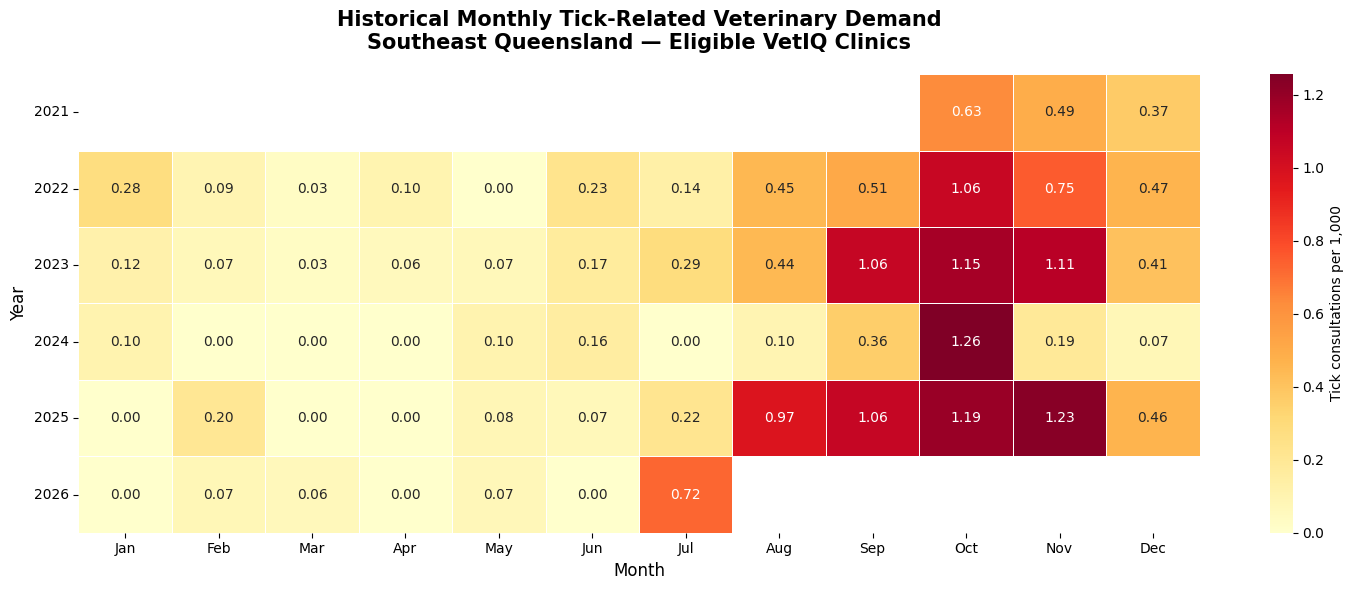

Years included: [2021, 2022, 2023, 2024, 2025, 2026]
Clinics included: 19


In [220]:

# ============================================================
# VETIQ — YEAR-BY-MONTH TICK SEASONALITY HEATMAP
# Uses the old notebook's consultation-based definition
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Same eligible clinics used in the Ridge/SARIMA analysis
heatmap_df = model_final[
    model_final["ClinicID"].astype(int).isin(ridge_ids)
].copy()

heatmap_df["Week_End"] = pd.to_datetime(
    heatmap_df["Week_End"]
)

# Preserve the existing denominator-quality filter
heatmap_df = heatmap_df[
    heatmap_df["Total_Consultations"] >= 20
].copy()

# Extract year and month
heatmap_df["Year"] = heatmap_df["Week_End"].dt.year
heatmap_df["Month"] = heatmap_df["Week_End"].dt.month

# Aggregate counts before calculating rates
monthly_heatmap = (
    heatmap_df
    .groupby(["Year", "Month"])
    .agg(
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
)

monthly_heatmap["Tick_per_1000"] = (
    monthly_heatmap["Tick_Consultations"]
    / monthly_heatmap["Total_Consultations"]
    * 1000
)

# Create heatmap matrix
heatmap_matrix = monthly_heatmap.pivot(
    index="Year",
    columns="Month",
    values="Tick_per_1000"
).reindex(columns=range(1, 13))

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

heatmap_matrix.columns = month_names

# Plot
plt.figure(figsize=(15, 6))

sns.heatmap(
    heatmap_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.6,
    linecolor="white",
    cbar_kws={
        "label": "Tick consultations per 1,000"
    }
)

plt.title(
    "Historical Monthly Tick-Related Veterinary Demand\n"
    "Southeast Queensland — Eligible VetIQ Clinics",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Year", fontsize=12)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("Years included:", heatmap_matrix.index.tolist())
print("Clinics included:", heatmap_df["ClinicID"].nunique())


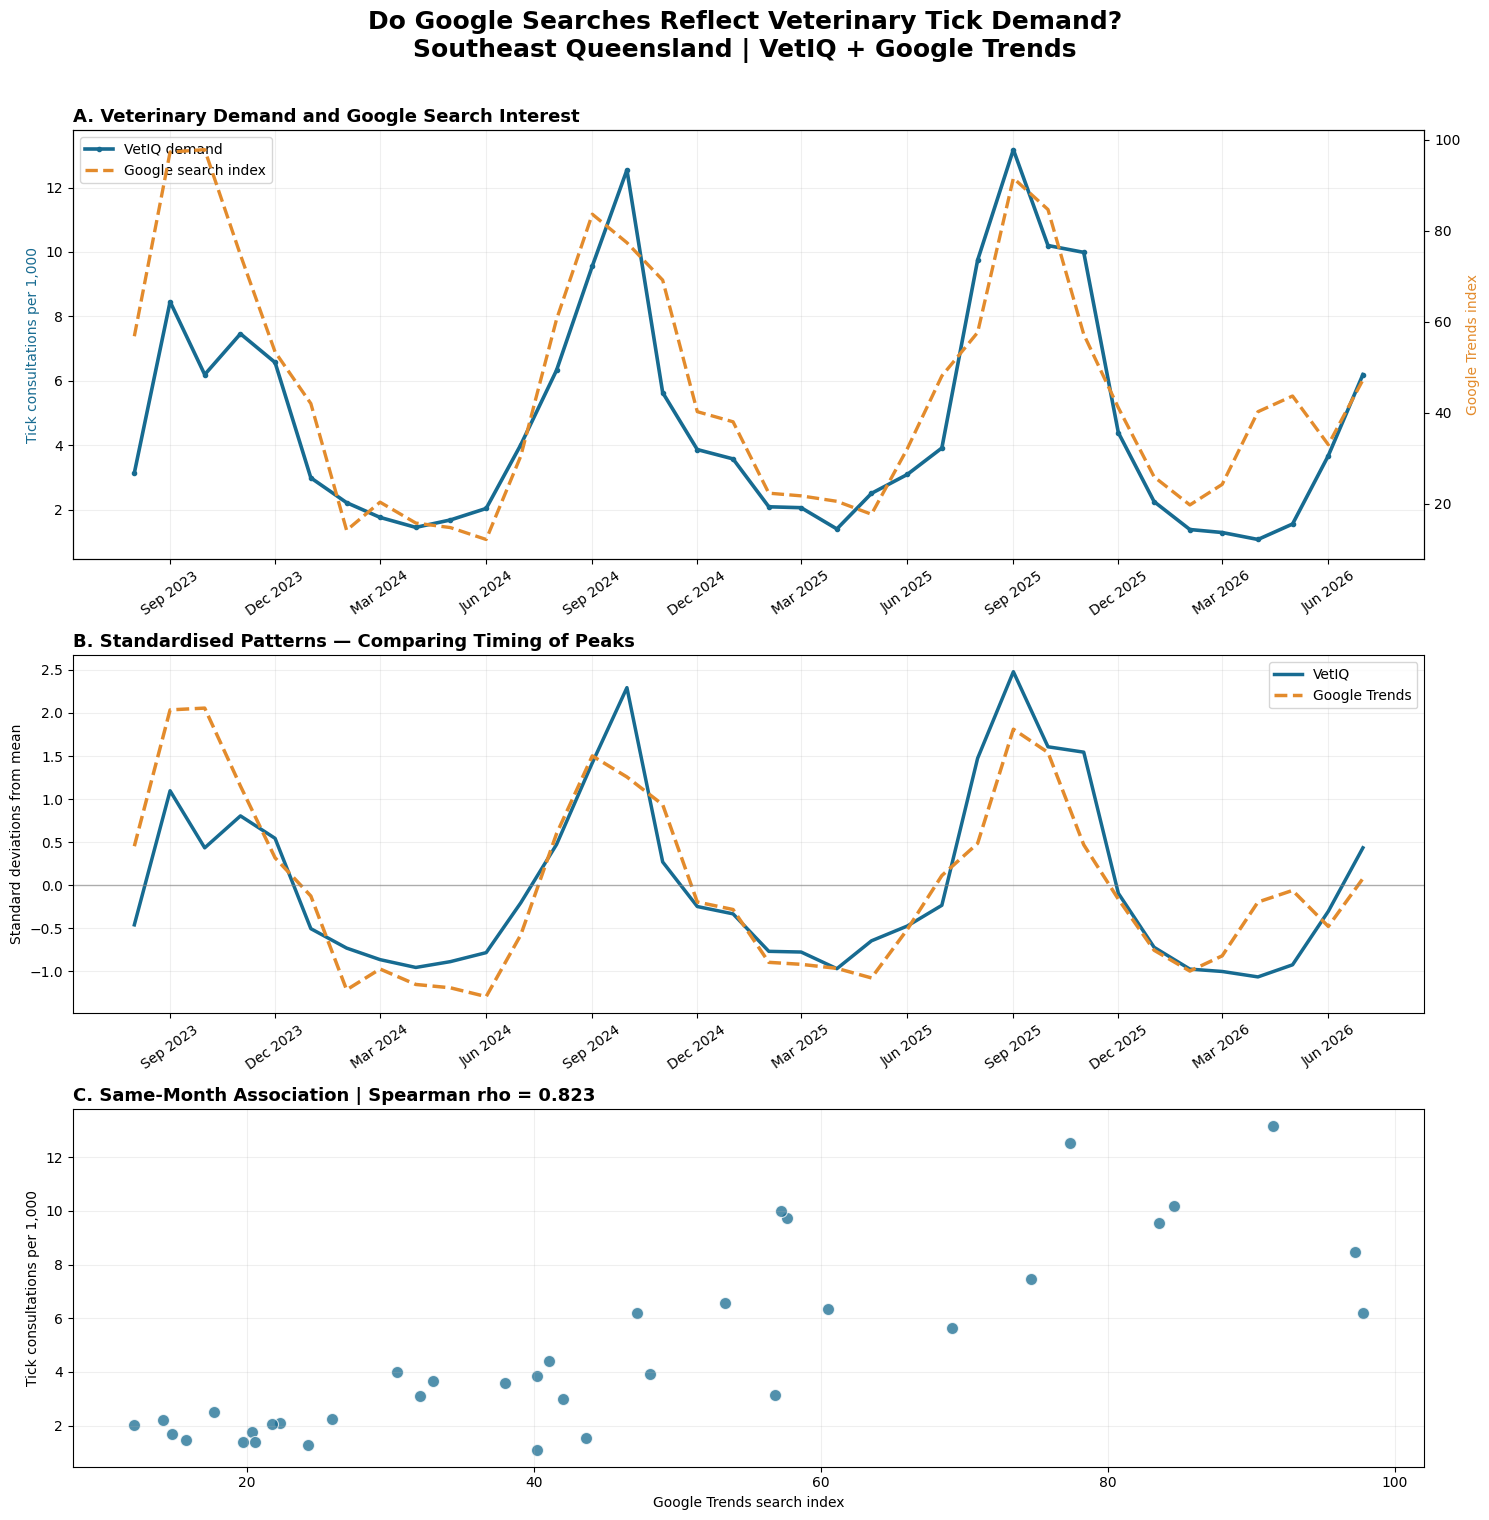

Months compared: 36
Spearman correlation: 0.823
P-value: 0.0
Saved: vetiq_google_trends_dashboard.png


In [221]:

# ============================================================
# VETIQ x GOOGLE TRENDS — VISUAL ANALYSIS DASHBOARD
# Original notebook datasets: monthly_consult and trends
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import spearmanr

# 1. Prepare existing datasets without modifying originals
vet = monthly_consult[
    ["Month", "Total_Consultations", "Tick_Consultations"]
].copy()

google = trends[["Month", "Tick_Search_Index"]].copy()

for df in [vet, google]:
    df["Month"] = (
        pd.to_datetime(df["Month"])
        .dt.to_period("M")
        .dt.to_timestamp()
    )

# Aggregate consultation counts correctly
vet = (
    vet.groupby("Month", as_index=False)
    [["Total_Consultations", "Tick_Consultations"]]
    .sum()
)

vet["Tick_per_1000"] = (
    1000 * vet["Tick_Consultations"]
    / vet["Total_Consultations"].replace(0, np.nan)
)

google["Tick_Search_Index"] = pd.to_numeric(
    google["Tick_Search_Index"], errors="coerce"
)

google = google.drop_duplicates("Month")

comparison = (
    vet.merge(google, on="Month", how="inner")
    .sort_values("Month")
    .dropna(subset=["Tick_per_1000", "Tick_Search_Index"])
    .copy()
)

# Restrict to the original notebook's comparable period
comparison = comparison[
    comparison["Month"].between("2023-08-01", "2026-07-01")
].copy()

assert len(comparison) >= 3, "Not enough overlapping months."

# 2. Standardise each series for shape comparison
for col, new_col in [
    ("Tick_per_1000", "VetIQ_Normalised"),
    ("Tick_Search_Index", "Google_Normalised")
]:
    sd = comparison[col].std()
    comparison[new_col] = (
        (comparison[col] - comparison[col].mean()) / sd
        if sd > 0 else np.nan
    )

rho, p = spearmanr(
    comparison["Tick_Search_Index"],
    comparison["Tick_per_1000"]
)

# 3. Create presentation-ready figure
fig, axes = plt.subplots(
    3, 1, figsize=(15, 15),
    gridspec_kw={"height_ratios": [1.2, 1, 1]}
)

fig.patch.set_facecolor("white")

blue = "#176B91"
orange = "#E38B2C"

# PANEL A — Two original-scale series
ax = axes[0]
ax2 = ax.twinx()

ax.plot(
    comparison["Month"], comparison["Tick_per_1000"],
    color=blue, linewidth=2.6, marker="o",
    markersize=3, label="VetIQ demand"
)

ax2.plot(
    comparison["Month"], comparison["Tick_Search_Index"],
    color=orange, linewidth=2.4,
    linestyle="--", label="Google search index"
)

ax.set_ylabel("Tick consultations per 1,000", color=blue)
ax2.set_ylabel("Google Trends index", color=orange)
ax.set_title(
    "A. Veterinary Demand and Google Search Interest",
    loc="left", fontweight="bold", fontsize=13
)
ax.grid(alpha=0.2)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.tick_params(axis="x", rotation=35)

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

# PANEL B — Normalised series
ax = axes[1]

ax.plot(
    comparison["Month"], comparison["VetIQ_Normalised"],
    color=blue, linewidth=2.5, label="VetIQ"
)
ax.plot(
    comparison["Month"], comparison["Google_Normalised"],
    color=orange, linewidth=2.5,
    linestyle="--", label="Google Trends"
)

ax.axhline(0, color="gray", linewidth=1, alpha=0.6)
ax.set_title(
    "B. Standardised Patterns — Comparing Timing of Peaks",
    loc="left", fontweight="bold", fontsize=13
)
ax.set_ylabel("Standard deviations from mean")
ax.legend()
ax.grid(alpha=0.2)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.tick_params(axis="x", rotation=35)

# PANEL C — Same-month relationship
ax = axes[2]

ax.scatter(
    comparison["Tick_Search_Index"],
    comparison["Tick_per_1000"],
    s=75, color=blue, alpha=0.75,
    edgecolor="white", linewidth=0.8
)

ax.set_xlabel("Google Trends search index")
ax.set_ylabel("Tick consultations per 1,000")
ax.set_title(
    f"C. Same-Month Association | Spearman rho = {rho:.3f}",
    loc="left", fontweight="bold", fontsize=13
)
ax.grid(alpha=0.2)

fig.suptitle(
    "Do Google Searches Reflect Veterinary Tick Demand?\n"
    "Southeast Queensland | VetIQ + Google Trends",
    fontsize=18, fontweight="bold", y=1.01
)

plt.tight_layout()
plt.savefig(
    "vetiq_google_trends_dashboard.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("Months compared:", len(comparison))
print("Spearman correlation:", round(rho, 3))
print("P-value:", round(p, 4))
print("Saved: vetiq_google_trends_dashboard.png")


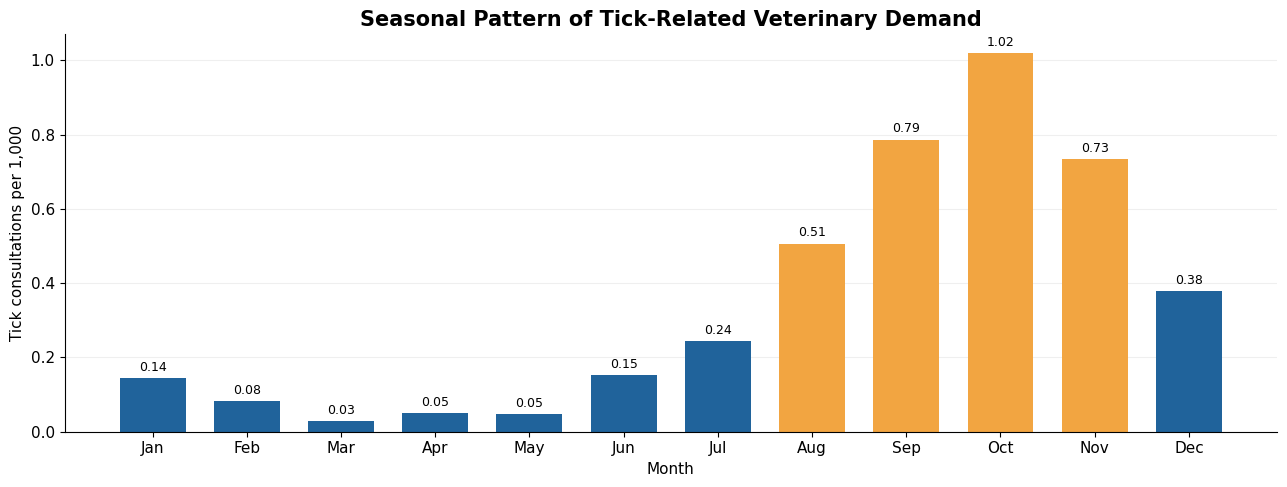

/var/folders/_w/whgh5msd3m51z0f722vzc5140000gn/T/ipykernel_27594/1034312319.py:82: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  clinic_data


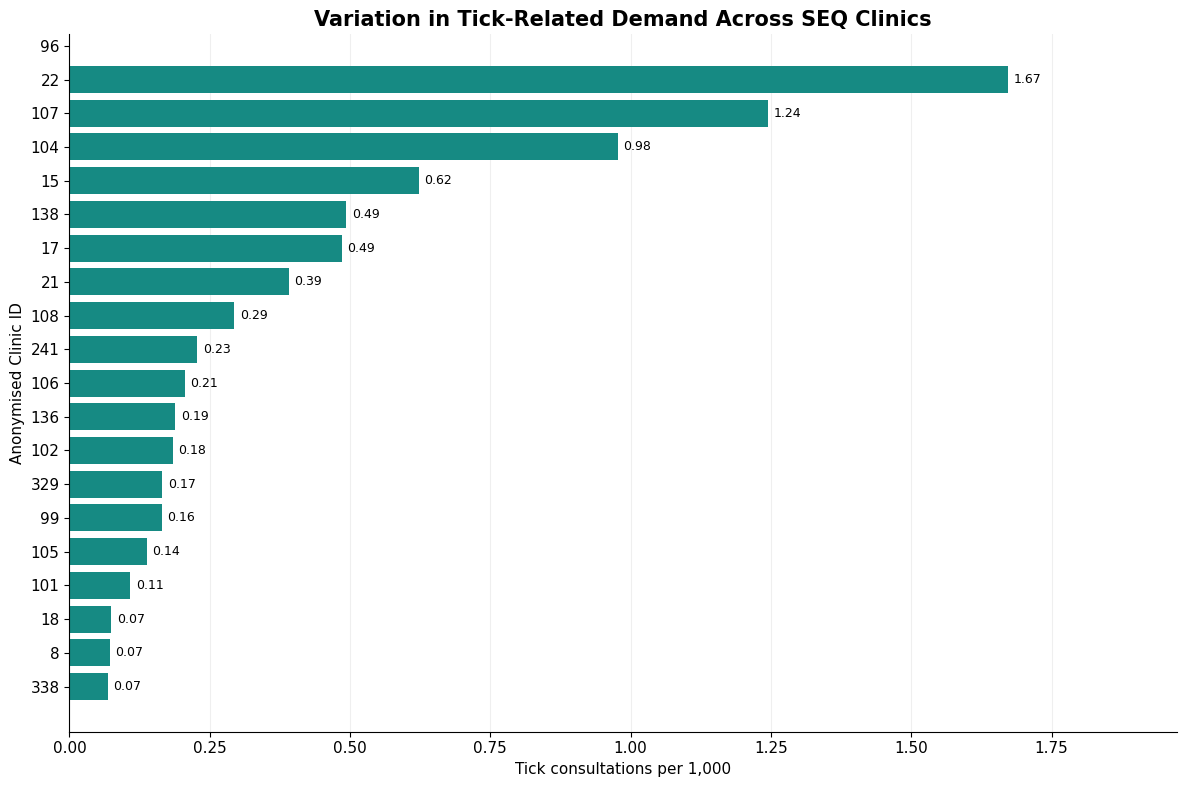

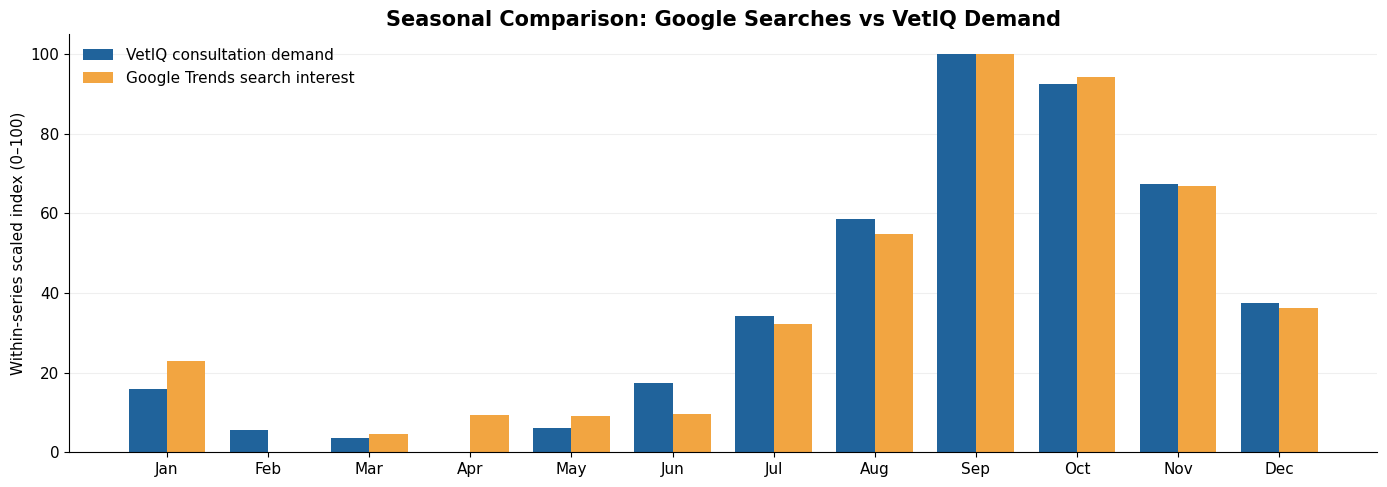

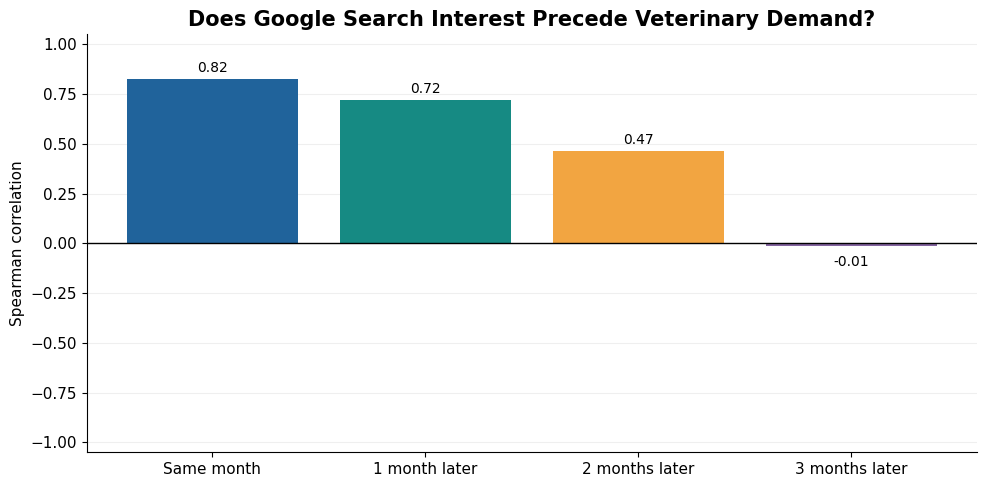

Four figures saved successfully.


In [222]:

# ============================================================
# VETIQ CAPSTONE — FOUR REPORT-READY BAR CHARTS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

BLUE = "#20639B"
TEAL = "#168A83"
ORANGE = "#F2A541"

months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# ------------------------------------------------------------
# CHART 1 — MONTHLY TICK DEMAND
# ------------------------------------------------------------

monthly = (
    monthly_pattern
    .groupby("Month")
    .agg(
        Tick=("Tick_Consultations", "sum"),
        Total=("Total_Consultations", "sum")
    )
    .reindex(range(1, 13))
)

monthly["Rate"] = 1000 * monthly["Tick"] / monthly["Total"]

fig, ax = plt.subplots(figsize=(13, 5))

bars = ax.bar(
    months,
    monthly["Rate"],
    color=[
        ORANGE if m in [8, 9, 10, 11] else BLUE
        for m in range(1, 13)
    ],
    width=0.7
)

ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_title(
    "Seasonal Pattern of Tick-Related Veterinary Demand",
    fontsize=15, fontweight="bold"
)
ax.set_ylabel("Tick consultations per 1,000")
ax.set_xlabel("Month")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("01_monthly_tick_demand.png", dpi=300)
plt.show()


# ------------------------------------------------------------
# CHART 2 — CLINIC-LEVEL TICK DEMAND
# ------------------------------------------------------------

clinic_data = model_final.copy()

clinic_data = clinic_data[
    clinic_data["ClinicID"].astype(int).isin(ridge_ids)
    & (clinic_data["Total_Consultations"] >= 20)
]

clinic_summary = (
    clinic_data
    .groupby("ClinicID")
    .agg(
        Tick=("Tick_Consultations", "sum"),
        Total=("Total_Consultations", "sum")
    )
)

clinic_summary["Rate"] = (
    1000 * clinic_summary["Tick"] / clinic_summary["Total"]
)

clinic_summary = clinic_summary.sort_values("Rate")

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    clinic_summary.index.astype(str),
    clinic_summary["Rate"],
    color=TEAL
)

ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=9)
ax.set_title(
    "Variation in Tick-Related Demand Across SEQ Clinics",
    fontsize=15, fontweight="bold"
)
ax.set_xlabel("Tick consultations per 1,000")
ax.set_ylabel("Anonymised Clinic ID")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

ax.set_xlim(0, max(clinic_summary["Rate"].max() * 1.18, 0.1))

plt.tight_layout()
plt.savefig("02_clinic_comparison.png", dpi=300)
plt.show()


# ------------------------------------------------------------
# CHART 3 — GOOGLE TRENDS VS VETIQ MONTHLY SEASONALITY
# ------------------------------------------------------------

comp = comparison.copy()
comp["Month"] = pd.to_datetime(comp["Month"])
comp["Month_Num"] = comp["Month"].dt.month

# Use a common seasonal comparison period
seasonal_comparison = (
    comp.groupby("Month_Num")
    .agg(
        Tick=("Tick_Consultations", "sum"),
        Total=("Total_Consultations", "sum"),
        Google=("Tick_Search_Index", "mean")
    )
    .reindex(range(1, 13))
)

seasonal_comparison["VetIQ_Rate"] = (
    1000 * seasonal_comparison["Tick"]
    / seasonal_comparison["Total"]
)

# Scale both series 0–100 for visual comparison
def scale_to_100(series):
    low, high = series.min(), series.max()
    if high == low:
        return series * 0
    return 100 * (series - low) / (high - low)

vet_scaled = scale_to_100(
    seasonal_comparison["VetIQ_Rate"]
)
google_scaled = scale_to_100(
    seasonal_comparison["Google"]
)

x = np.arange(12)
width = 0.38

fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(
    x - width/2, vet_scaled,
    width, label="VetIQ consultation demand",
    color=BLUE
)
ax.bar(
    x + width/2, google_scaled,
    width, label="Google Trends search interest",
    color=ORANGE
)

ax.set_xticks(x)
ax.set_xticklabels(months)
ax.set_ylabel("Within-series scaled index (0–100)")
ax.set_title(
    "Seasonal Comparison: Google Searches vs VetIQ Demand",
    fontsize=15, fontweight="bold"
)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("03_google_vs_vetiq_bars.png", dpi=300)
plt.show()


# ------------------------------------------------------------
# CHART 4 — GOOGLE SEARCH LEAD-LAG CORRELATION
# ------------------------------------------------------------

lag_df = comp.sort_values("Month").copy()
lag_df = lag_df.set_index("Month")

# Ensure missing months do not become adjacent observations
lag_df = lag_df.asfreq("MS")

lag_values = []

for lag in range(0, 4):

    # lag=1: searches in month t vs demand in month t+1
    aligned = pd.DataFrame({
        "Search": lag_df["Tick_Search_Index"],
        "Future_Demand": lag_df["Tick_per_1000"].shift(-lag)
    }).dropna()

    if len(aligned) >= 3:
        rho, _ = spearmanr(
            aligned["Search"],
            aligned["Future_Demand"]
        )
    else:
        rho = np.nan

    lag_values.append(rho)

fig, ax = plt.subplots(figsize=(10, 5))

labels = [
    "Same month",
    "1 month later",
    "2 months later",
    "3 months later"
]

bars = ax.bar(
    labels,
    lag_values,
    color=[BLUE, TEAL, ORANGE, "#8464A0"]
)

ax.axhline(0, color="black", linewidth=1)
ax.set_ylim(-1.05, 1.05)
ax.set_ylabel("Spearman correlation")
ax.set_title(
    "Does Google Search Interest Precede Veterinary Demand?",
    fontsize=15, fontweight="bold"
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for bar, value in zip(bars, lag_values):
    if np.isfinite(value):
        ax.annotate(
            f"{value:.2f}",
            (bar.get_x() + bar.get_width()/2, value),
            xytext=(0, 5 if value >= 0 else -15),
            textcoords="offset points",
            ha="center",
            fontsize=10
        )

plt.tight_layout()
plt.savefig("04_google_lead_lag.png", dpi=300)
plt.show()

print("Four figures saved successfully.")


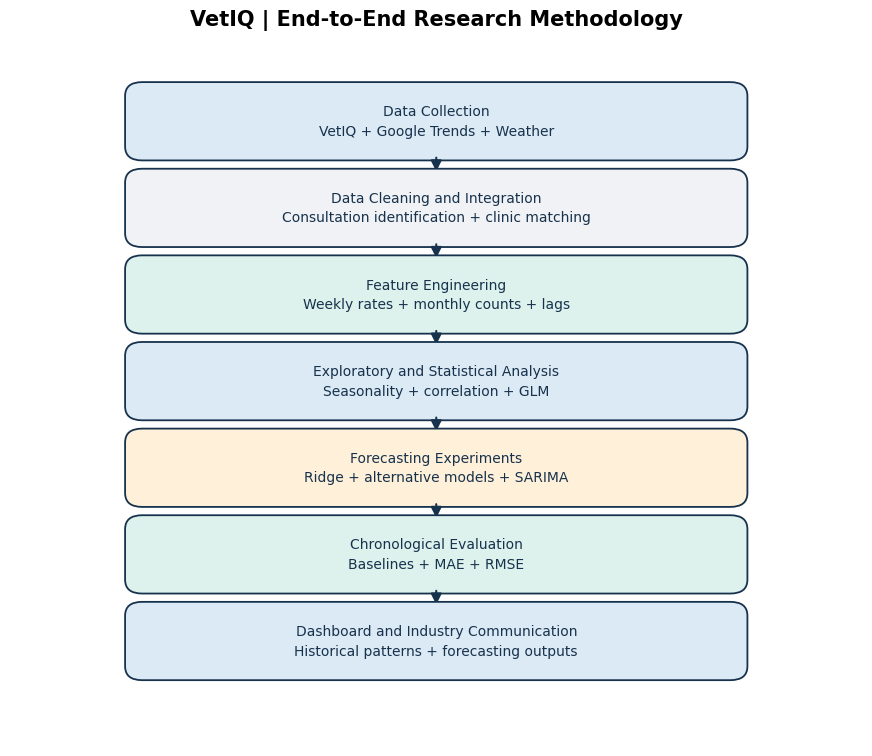

Saved: methodology_figures/Figure_2_1_Research_Workflow.png


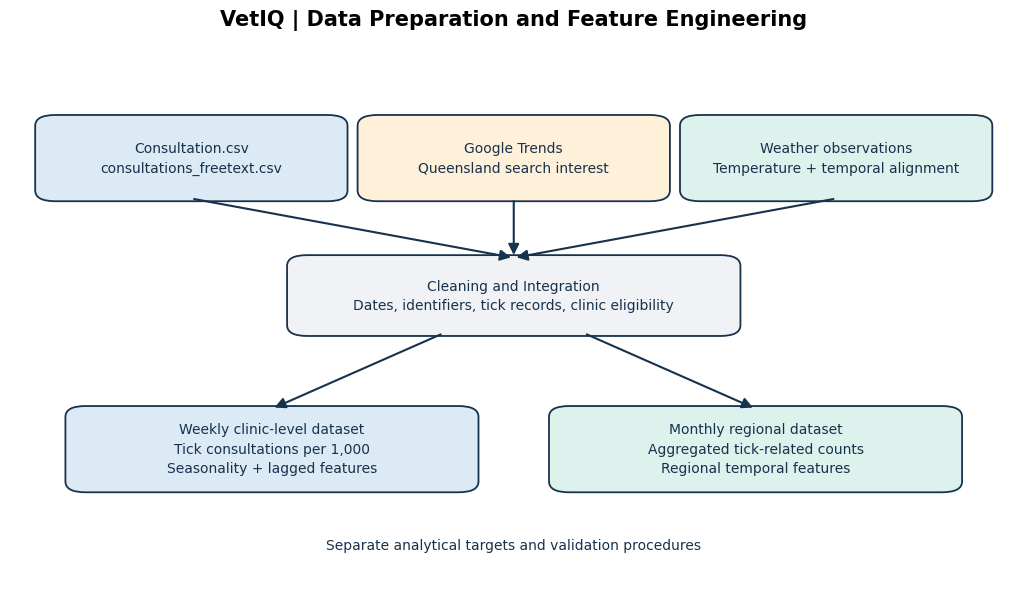

Saved: methodology_figures/Figure_2_2_Data_Pipeline.png


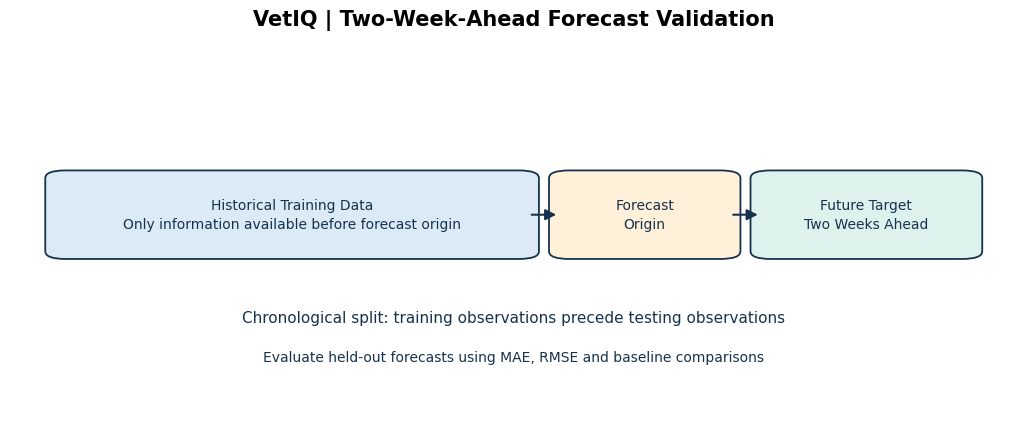

Saved: methodology_figures/Figure_2_3_Forecast_Validation.png


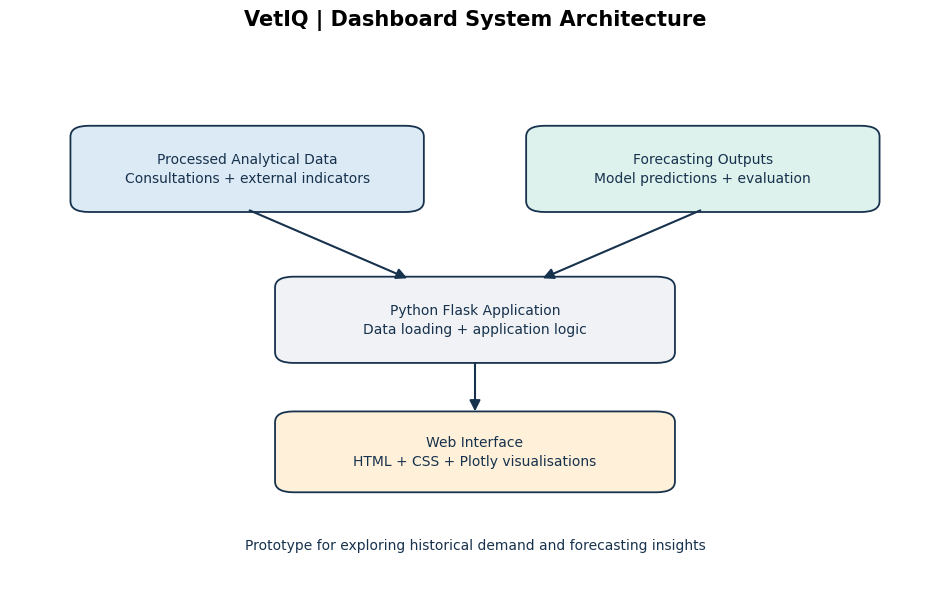

Saved: methodology_figures/Figure_2_4_Dashboard_Architecture.png


In [223]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from pathlib import Path

# Folder for report figures
OUT = Path("methodology_figures")
OUT.mkdir(exist_ok=True)

# Consistent report styling
NAVY = "#17324D"
BLUE = "#DCEAF5"
TEAL = "#DDF2ED"
ORANGE = "#FFF0D9"
GRAY = "#F0F2F5"
WHITE = "#FFFFFF"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "savefig.dpi": 300
})

def box(ax, x, y, w, h, label, color=BLUE, fontsize=10):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.015,rounding_size=0.02",
        linewidth=1.3, edgecolor=NAVY, facecolor=color
    )
    ax.add_patch(patch)
    ax.text(
        x + w/2, y + h/2, label,
        ha="center", va="center",
        fontsize=fontsize, color=NAVY,
        weight="medium", linespacing=1.5
    )

def arrow(ax, start, end):
    ax.add_patch(FancyArrowPatch(
        start, end, arrowstyle="-|>",
        mutation_scale=16, linewidth=1.5,
        color=NAVY
    ))

def setup(title, figsize=(12, 7)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.set_title(title, fontsize=15, weight="bold", pad=20)
    return fig, ax

def save(fig, name):
    path = OUT / name
    fig.savefig(path, dpi=300, bbox_inches="tight",
                facecolor="white")
    plt.show()
    print("Saved:", path)


# -------------------------------------------------------
# FIGURE 2.1 — END-TO-END RESEARCH WORKFLOW
# -------------------------------------------------------
fig, ax = setup("VetIQ | End-to-End Research Methodology",
                (11, 9))

steps = [
    ("Data Collection\nVetIQ + Google Trends + Weather", BLUE),
    ("Data Cleaning and Integration\nConsultation identification + clinic matching", GRAY),
    ("Feature Engineering\nWeekly rates + monthly counts + lags", TEAL),
    ("Exploratory and Statistical Analysis\nSeasonality + correlation + GLM", BLUE),
    ("Forecasting Experiments\nRidge + alternative models + SARIMA", ORANGE),
    ("Chronological Evaluation\nBaselines + MAE + RMSE", TEAL),
    ("Dashboard and Industry Communication\nHistorical patterns + forecasting outputs", BLUE)
]

w, h = 0.70, 0.083
x = 0.15
ys = [0.86 - i*0.125 for i in range(len(steps))]

for i, ((label, color), y) in enumerate(zip(steps, ys)):
    box(ax, x, y, w, h, label, color)
    if i < len(steps)-1:
        arrow(ax, (0.5, y-0.007),
              (0.5, ys[i+1]+h+0.007))

save(fig, "Figure_2_1_Research_Workflow.png")


# -------------------------------------------------------
# FIGURE 2.2 — DATA PREPROCESSING AND FEATURE ENGINEERING
# -------------------------------------------------------
fig, ax = setup("VetIQ | Data Preparation and Feature Engineering",
                (13, 7))

box(ax, 0.04, 0.74, 0.28, 0.13,
    "Consultation.csv\nconsultations_freetext.csv", BLUE)

box(ax, 0.36, 0.74, 0.28, 0.13,
    "Google Trends\nQueensland search interest", ORANGE)

box(ax, 0.68, 0.74, 0.28, 0.13,
    "Weather observations\nTemperature + temporal alignment", TEAL)

box(ax, 0.29, 0.49, 0.42, 0.12,
    "Cleaning and Integration\nDates, identifiers, tick records, clinic eligibility", GRAY)

for cx in [0.18, 0.50, 0.82]:
    arrow(ax, (cx, 0.73), (0.50, 0.62))

box(ax, 0.07, 0.20, 0.38, 0.13,
    "Weekly clinic-level dataset\nTick consultations per 1,000\nSeasonality + lagged features", BLUE)

box(ax, 0.55, 0.20, 0.38, 0.13,
    "Monthly regional dataset\nAggregated tick-related counts\nRegional temporal features", TEAL)

arrow(ax, (0.43, 0.48), (0.26, 0.34))
arrow(ax, (0.57, 0.48), (0.74, 0.34))

ax.text(
    0.5, 0.08,
    "Separate analytical targets and validation procedures",
    ha="center", fontsize=10, color=NAVY
)

save(fig, "Figure_2_2_Data_Pipeline.png")


# -------------------------------------------------------
# FIGURE 2.3 — CHRONOLOGICAL FORECAST VALIDATION
# -------------------------------------------------------
fig, ax = setup("VetIQ | Two-Week-Ahead Forecast Validation",
                (13, 5))

box(ax, 0.05, 0.48, 0.46, 0.20,
    "Historical Training Data\nOnly information available before forecast origin",
    BLUE)

box(ax, 0.55, 0.48, 0.16, 0.20,
    "Forecast\nOrigin", ORANGE)

box(ax, 0.75, 0.48, 0.20, 0.20,
    "Future Target\nTwo Weeks Ahead", TEAL)

arrow(ax, (0.515, 0.58), (0.545, 0.58))
arrow(ax, (0.715, 0.58), (0.745, 0.58))

ax.text(
    0.5, 0.30,
    "Chronological split: training observations precede testing observations",
    ha="center", fontsize=11, color=NAVY
)
ax.text(
    0.5, 0.20,
    "Evaluate held-out forecasts using MAE, RMSE and baseline comparisons",
    ha="center", fontsize=10, color=NAVY
)

save(fig, "Figure_2_3_Forecast_Validation.png")


# -------------------------------------------------------
# FIGURE 2.4 — DASHBOARD SYSTEM ARCHITECTURE
# -------------------------------------------------------
fig, ax = setup("VetIQ | Dashboard System Architecture",
                (12, 7))

box(ax, 0.08, 0.72, 0.35, 0.13,
    "Processed Analytical Data\nConsultations + external indicators", BLUE)

box(ax, 0.57, 0.72, 0.35, 0.13,
    "Forecasting Outputs\nModel predictions + evaluation", TEAL)

box(ax, 0.30, 0.44, 0.40, 0.13,
    "Python Flask Application\nData loading + application logic", GRAY)

arrow(ax, (0.255, 0.71), (0.43, 0.58))
arrow(ax, (0.745, 0.71), (0.57, 0.58))

box(ax, 0.30, 0.20, 0.40, 0.12,
    "Web Interface\nHTML + CSS + Plotly visualisations", ORANGE)

arrow(ax, (0.5, 0.43), (0.5, 0.33))

ax.text(
    0.5, 0.08,
    "Prototype for exploring historical demand and forecasting insights",
    ha="center", fontsize=10, color=NAVY
)

save(fig, "Figure_2_4_Dashboard_Architecture.png")


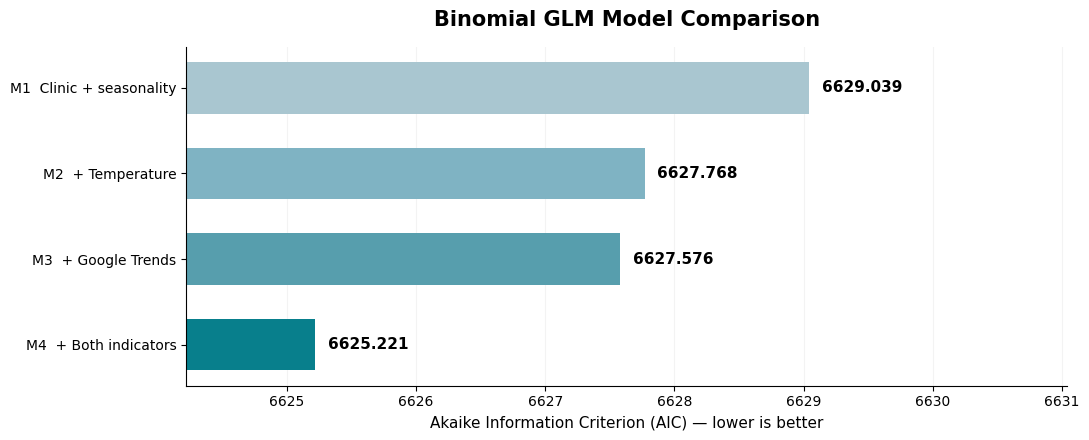


Verified AIC values:
Model_ID         AIC
      M1 6629.039381
      M2 6627.768324
      M3 6627.575789
      M4 6625.221237


In [224]:
# ============================================================
# VETIQ — BINOMIAL GLM AIC MODEL COMPARISON
# Uses verified M1–M4 results from aic_table
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use the verified AIC comparison table
plot_df = aic_table.copy().reset_index()

# Handle model names stored as either index or column
if "Model" not in plot_df.columns:
    plot_df = plot_df.rename(
        columns={plot_df.columns[0]: "Model"}
    )

plot_df["Model_ID"] = plot_df["Model"].str.extract(
    r"(M[1-4])"
)

# Sort from M1 to M4
plot_df = (
    plot_df.set_index("Model_ID")
    .loc[["M1", "M2", "M3", "M4"]]
    .reset_index()
)

labels = [
    "M1  Clinic + seasonality",
    "M2  + Temperature",
    "M3  + Google Trends",
    "M4  + Both indicators"
]

aic_values = plot_df["AIC"].to_numpy()

# Highlight the best model
colors = [
    "#A9C6D0",
    "#7FB3C3",
    "#579EAD",
    "#087F8C"
]

fig, ax = plt.subplots(figsize=(11, 4.5))

bars = ax.barh(
    labels,
    aic_values,
    color=colors,
    height=0.6
)

ax.invert_yaxis()

# Focus on small differences between AIC values
ax.set_xlim(
    aic_values.min() - 1,
    aic_values.max() + 2
)

# Show exact AIC values
for bar, value in zip(bars, aic_values):
    ax.text(
        value + 0.10,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xlabel(
    "Akaike Information Criterion (AIC) — lower is better",
    fontsize=11
)

ax.set_title(
    "Binomial GLM Model Comparison",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "VetIQ_Binomial_GLM_AIC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nVerified AIC values:")
print(plot_df[["Model_ID", "AIC"]].to_string(index=False))


Using baseline: naive_mae = 0.6396016923597246


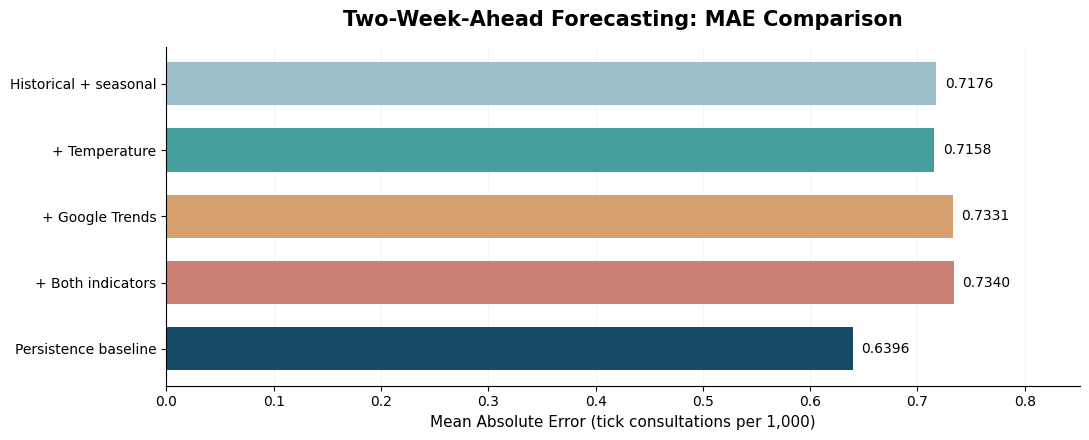


Values used in the graph:
                Model      MAE
Historical + seasonal 0.717625
        + Temperature 0.715791
      + Google Trends 0.733141
    + Both indicators 0.734018
 Persistence baseline 0.639602


In [225]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Retrieve existing Ridge results
if "final_ridge_results" not in globals():
    raise NameError(
        "final_ridge_results not found. "
        "Run your Ridge sensitivity/final evaluation cell first."
    )

results = final_ridge_results.copy()

# Extract R1–R4 model IDs
results["ID"] = results["Model"].astype(str).str.extract(
    r"(R[1-4])",
    expand=False
)

if results["ID"].isna().any():
    raise ValueError("Some Ridge model IDs could not be identified.")

if results["ID"].duplicated().any():
    raise ValueError("Duplicate Ridge model IDs found.")

results = results.set_index("ID").loc[
    ["R1", "R2", "R3", "R4"]
]

# 2. Retrieve persistence baseline MAE
# Set the variable name here to the one used in your notebook.
baseline_candidates = [
    "naive_mae",
    "persistence_mae",
    "baseline_mae",
    "naive_MAE",
    "persistence_MAE"
]

baseline_name = next(
    (
        name for name in baseline_candidates
        if name in globals()
        and np.isscalar(globals()[name])
        and pd.notna(globals()[name])
    ),
    None
)

if baseline_name is None:
    raise NameError(
        "Persistence baseline MAE variable not found. "
        "Check the variable name in your evaluation cell."
    )

baseline_value = float(globals()[baseline_name])

print("Using baseline:", baseline_name, "=", baseline_value)

# 3. Build graph data
labels = [
    "Historical + seasonal",
    "+ Temperature",
    "+ Google Trends",
    "+ Both indicators",
    "Persistence baseline"
]

mae_values = [
    float(results.loc["R1", "MAE"]),
    float(results.loc["R2", "MAE"]),
    float(results.loc["R3", "MAE"]),
    float(results.loc["R4", "MAE"]),
    baseline_value
]

colors = [
    "#9ABFCB",
    "#459F9C",
    "#D5A06D",
    "#CD8074",
    "#174C68"
]

# 4. Create horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 4.5))

bars = ax.barh(
    labels,
    mae_values,
    color=colors,
    height=0.65
)

ax.invert_yaxis()

for bar, value in zip(bars, mae_values):
    ax.text(
        value + 0.008,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center",
        fontsize=10
    )

ax.set_xlim(0, max(mae_values) * 1.16)

ax.set_title(
    "Two-Week-Ahead Forecasting: MAE Comparison",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Mean Absolute Error (tick consultations per 1,000)",
    fontsize=11
)

ax.grid(axis="x", alpha=0.12)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()

plt.savefig(
    "VetIQ_Two_Week_Ahead_MAE.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Verify plotted values
print("\nValues used in the graph:")
print(pd.DataFrame({
    "Model": labels,
    "MAE": mae_values
}).to_string(index=False))


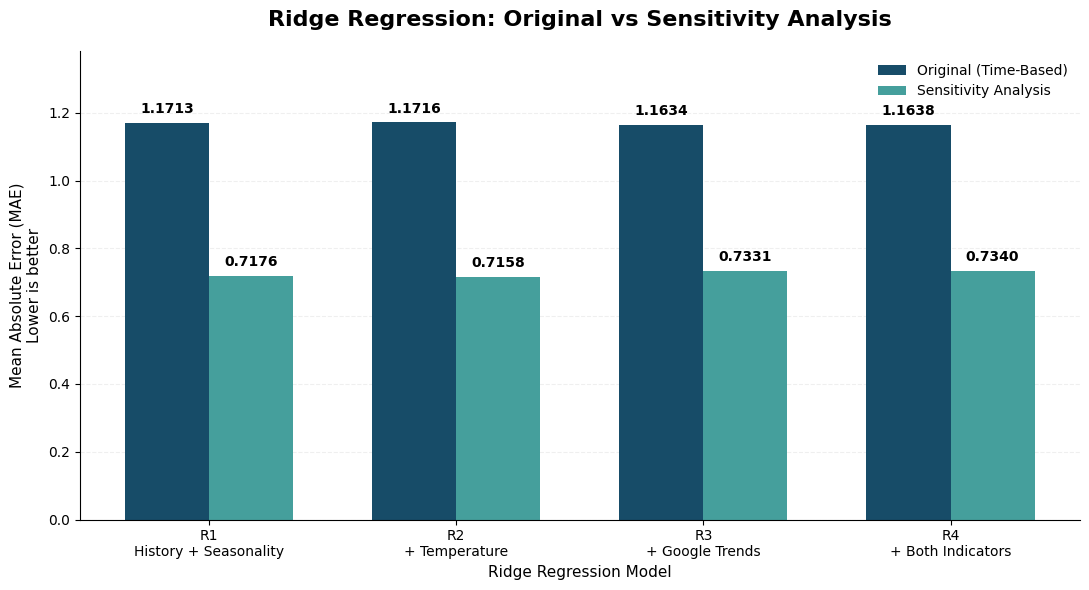

,Original,Sensitivity
ID,,
R1,1.1713,0.7176
R2,1.1716,0.7158
R3,1.1634,0.7331
R4,1.1638,0.7340


In [226]:
# VETIQ — ORIGINAL VS SENSITIVITY ANALYSIS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 13: Original results
original = ridge_comparison.copy()
original["ID"] = original["Model"].str.extract(r"(R[1-4])")

# Step 16: Sensitivity results
sensitivity = final_ridge_results.copy()
sensitivity["ID"] = sensitivity["Model"].str.extract(r"(R[1-4])")

# Combine both experiments
comparison = (
    original[["ID", "MAE"]]
    .rename(columns={"MAE": "Original"})
    .merge(
        sensitivity[["ID", "MAE"]].rename(
            columns={"MAE": "Sensitivity"}
        ),
        on="ID",
        validate="one_to_one"
    )
    .set_index("ID")
    .loc[["R1", "R2", "R3", "R4"]]
)

# Graph settings
models = comparison.index.tolist()
x = np.arange(len(models))
width = 0.34

fig, ax = plt.subplots(figsize=(11, 6))

# Two bars for each model
bars_original = ax.bar(
    x - width / 2,
    comparison["Original"],
    width,
    color="#174C68",
    label="Original (Time-Based)"
)

bars_sensitivity = ax.bar(
    x + width / 2,
    comparison["Sensitivity"],
    width,
    color="#459F9C",
    label="Sensitivity Analysis"
)

# Add exact values above bars
for bars in [bars_original, bars_sensitivity]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.4f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

# Labels
ax.set_title(
    "Ridge Regression: Original vs Sensitivity Analysis",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_ylabel(
    "Mean Absolute Error (MAE)\nLower is better",
    fontsize=11
)

ax.set_xlabel("Ridge Regression Model", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels([
    "R1\nHistory + Seasonality",
    "R2\n+ Temperature",
    "R3\n+ Google Trends",
    "R4\n+ Both Indicators"
], fontsize=10)

ax.set_ylim(
    0,
    comparison[["Original", "Sensitivity"]]
    .max().max() * 1.18
)

ax.legend(frameon=False, fontsize=10)

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()

plt.savefig(
    "VetIQ_Ridge_Original_vs_Sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display values for checking
display(comparison.round(4))


In [227]:
import pandas as pd
import numpy as np

# Define temperature categories
temp_bins = [-np.inf, 15, 18, 21, 24, np.inf]

temp_labels = [
    "15°C or below",
    "15–18°C",
    "18–21°C",
    "21–24°C",
    "Above 24°C"
]

# Create a copy of the modelling dataset
temp_df = model_df.copy()

# Assign temperature categories
temp_df["Temp_Category"] = pd.cut(
    temp_df["AvgTemp_C"],
    bins=temp_bins,
    labels=temp_labels,
    include_lowest=True
)

# Calculate tick-related consultations per 1,000
# using total consultations as the denominator
temp_summary = (
    temp_df.groupby(
        "Temp_Category",
        observed=False
    )[["Tick_Consultations", "Total_Consultations"]]
    .sum()
)

temp_summary = (
    temp_summary["Tick_Consultations"]
    / temp_summary["Total_Consultations"].replace(0, np.nan)
) * 1000

print("Temperature summary:")
print(temp_summary)

Temperature summary:
Temp_Category
15°C or below    0.352015
15–18°C          0.421829
18–21°C          0.559829
21–24°C          0.363870
Above 24°C       0.135378
dtype: float64


In [228]:

import pandas as pd

# Check available data before creating the final graph
for name in [
    "weekly_total",
    "model_df",
    "monthly_consult",
    "comparison"
]:
    if name in globals():
        data = globals()[name]
        print(f"\n{name}: {len(data):,} rows")
        print("Columns:", data.columns.tolist())

        if "ClinicID" in data.columns:
            print("Clinics:", data["ClinicID"].nunique())

        if "Week_End" in data.columns:
            print("Date range:",
                  data["Week_End"].min(),
                  "to",
                  data["Week_End"].max())



weekly_total: 9,966 rows
Columns: ['ClinicID', 'Week_End', 'Available_Consultations']
Clinics: 78
Date range: 2021-10-03 00:00:00 to 2026-08-30 00:00:00

model_df: 2,339 rows
Columns: ['ClinicID', 'Week_End', 'Total_Consultations', 'YearMonth', 'AvgTemp_C', 'Tick_Consultations', 'Tick_Rate', 'Tick_per_1000', 'WeekOfYear', 'Season_Sin', 'Season_Cos', 'Tick_Search_Index']
Clinics: 19
Date range: 2021-10-03 00:00:00 to 2026-07-26 00:00:00

monthly_consult: 38 rows
Columns: ['Month', 'Total_Consultations', 'Tick_Consultations', 'Tick_per_1000']

comparison: 4 rows
Columns: ['Original', 'Sensitivity']


Dataset rows: 2339
Clinics: 19
Date range: 2021-10-03 00:00:00 to 2026-07-26 00:00:00


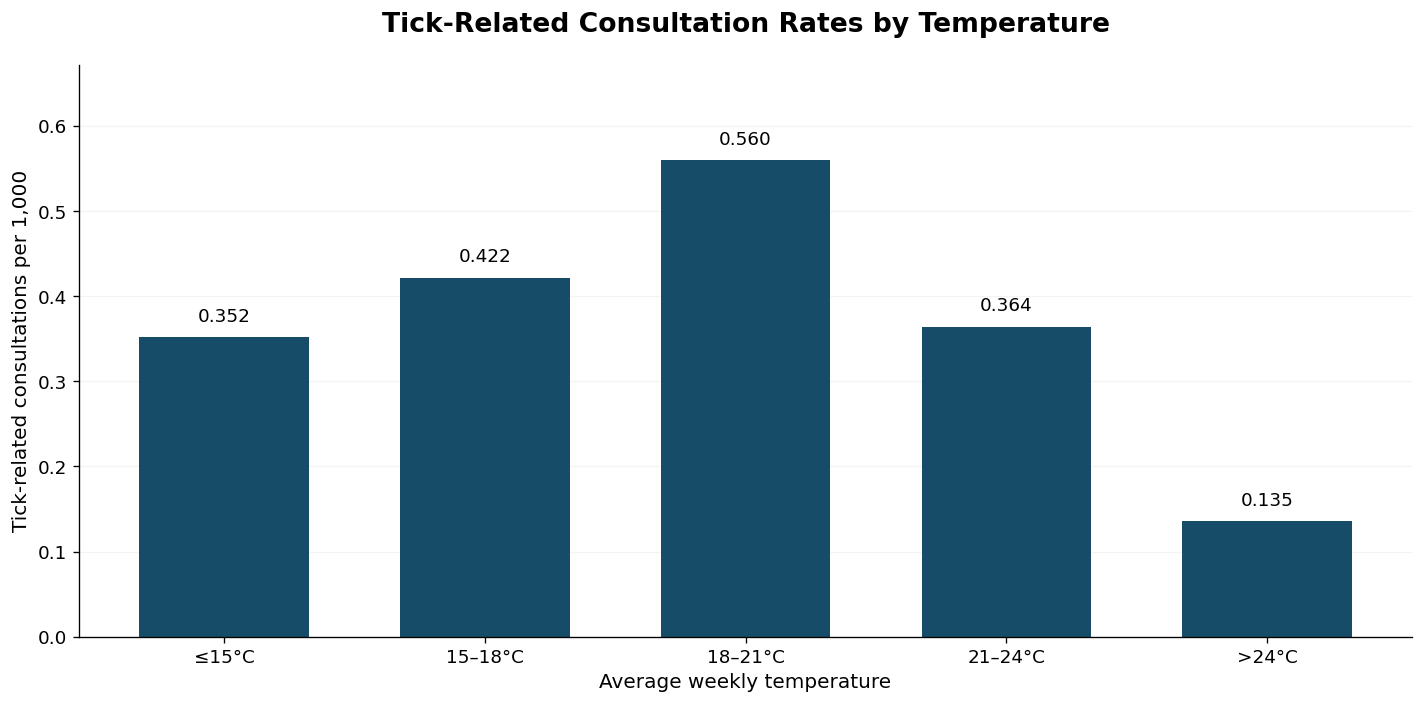

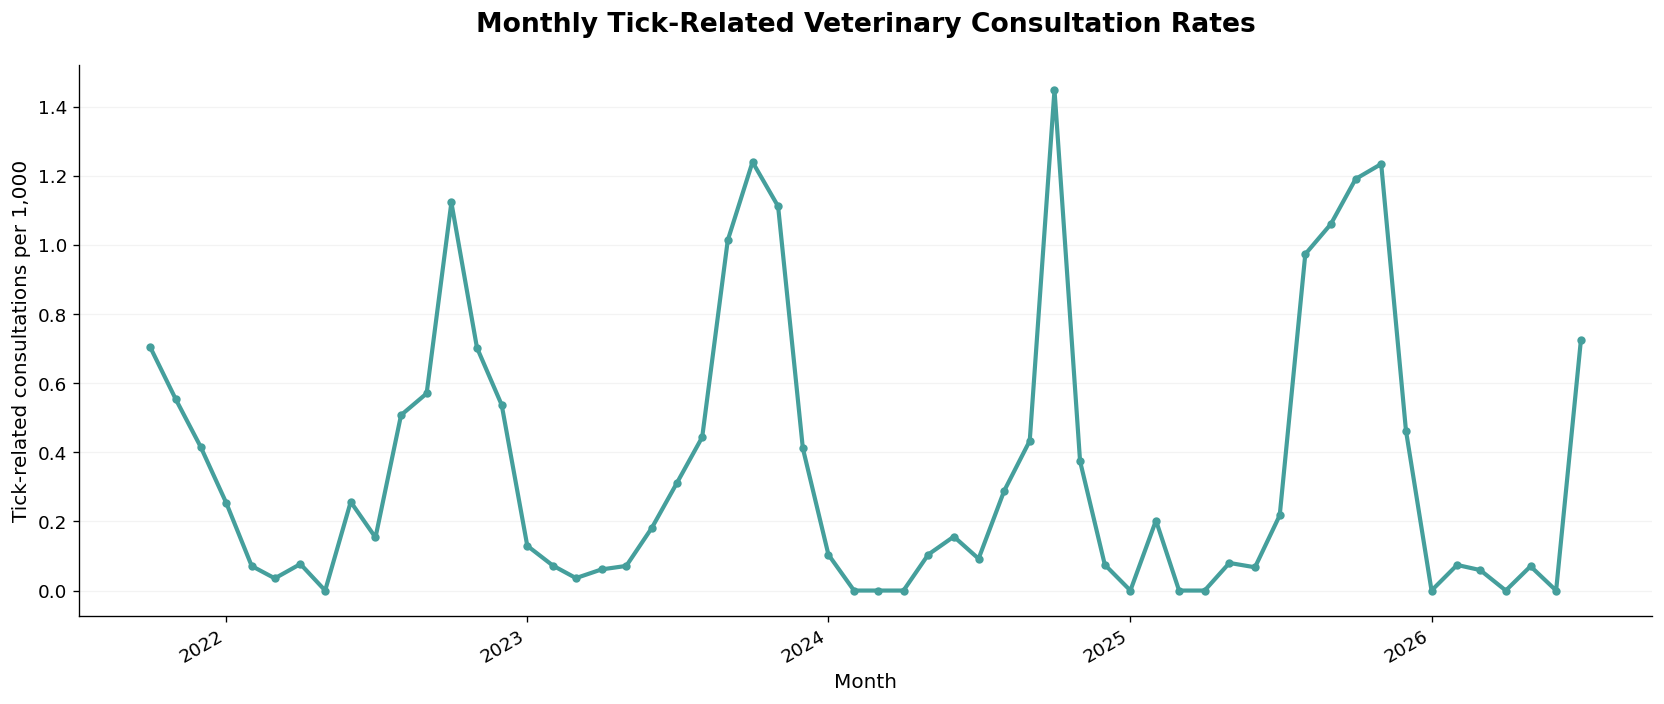

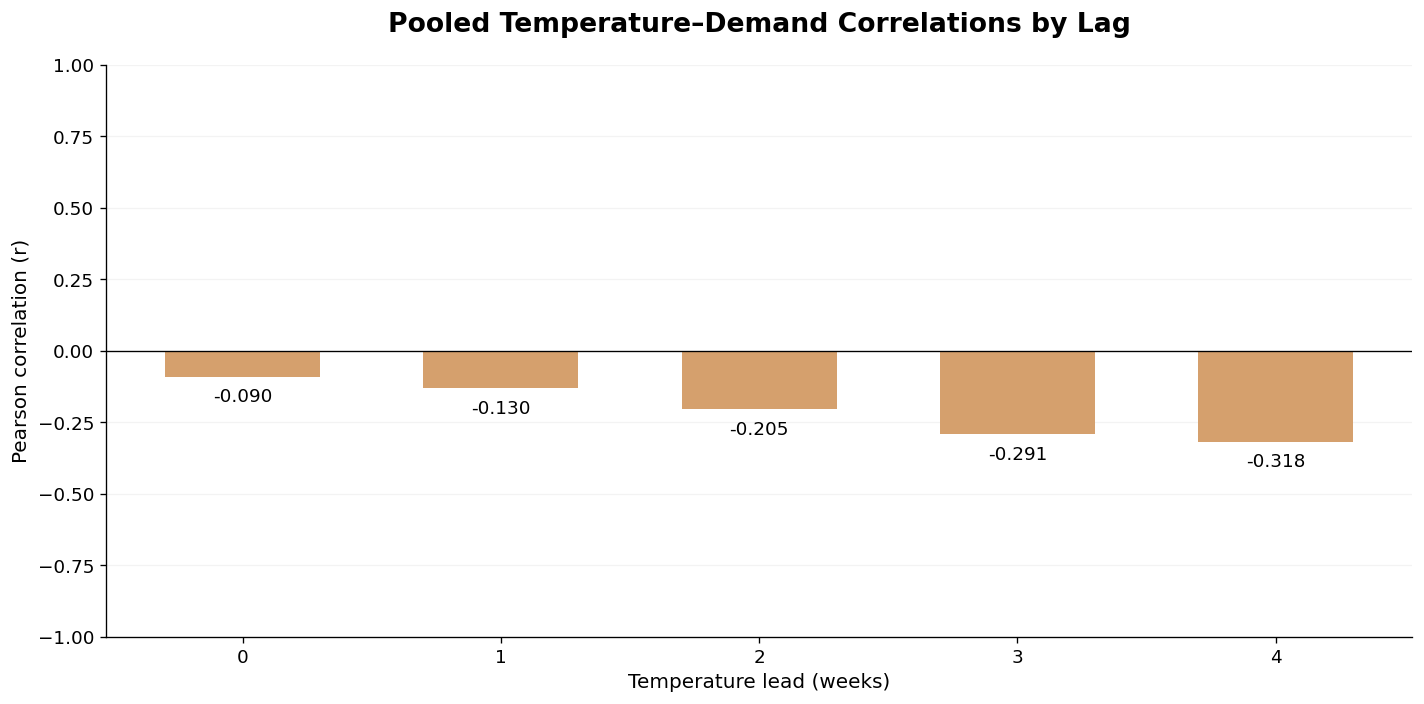


TEMPERATURE SUMMARY
Temp_Category
≤15°C      0.3520
15–18°C    0.4218
18–21°C    0.5598
21–24°C    0.3639
>24°C      0.1354
dtype: float64

MONTHLY SUMMARY
            Tick_Consultations  Total_Consultations  Tick_per_1000
Month                                                             
2025-08-01                17.0                17458         0.9738
2025-09-01                15.0                14139         1.0609
2025-10-01                18.0                15109         1.1913
2025-11-01                22.0                17819         1.2346
2025-12-01                 6.0                12959         0.4630
2026-01-01                 0.0                14312         0.0000
2026-02-01                 1.0                13492         0.0741
2026-03-01                 1.0                16880         0.0592
2026-04-01                 0.0                12856         0.0000
2026-05-01                 1.0                14239         0.0702
2026-06-01                 0.0         

In [229]:

# ============================================================
# VETIQ — THREE SEPARATE FULL-SIZE GRAPHS
# Temperature | Monthly Trend | Temperature Lag Correlations
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

BLUE = "#174C68"
TEAL = "#459F9C"
ORANGE = "#D5A06D"

OUTPUT_DIR = Path("vetiq_graphs")
OUTPUT_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.labelsize": 12,
    "figure.dpi": 120,
    "savefig.dpi": 300
})

def style_graph(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

def save_graph(filename):
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

# ------------------------------------------------------------
# 2. VALIDATE DATA
# ------------------------------------------------------------

if "model_df" not in globals():
    raise NameError(
        "model_df is not defined. Run the notebook cell "
        "that creates model_df first."
    )

df = model_df.copy()

required_columns = [
    "Week_End",
    "AvgTemp_C",
    "Tick_Consultations",
    "Total_Consultations"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing columns in model_df: {missing}"
    )

df["Week_End"] = pd.to_datetime(
    df["Week_End"], errors="coerce"
)

for col in [
    "AvgTemp_C",
    "Tick_Consultations",
    "Total_Consultations"
]:
    df[col] = pd.to_numeric(
        df[col], errors="coerce"
    )

df = df.dropna(
    subset=[
        "Week_End",
        "Tick_Consultations",
        "Total_Consultations"
    ]
)

df = df[df["Total_Consultations"] > 0].copy()

if df.empty:
    raise ValueError(
        "No valid observations remain in model_df."
    )

print("Dataset rows:", len(df))
print("Clinics:", df["ClinicID"].nunique()
      if "ClinicID" in df.columns else "Unknown")
print("Date range:", df["Week_End"].min(),
      "to", df["Week_End"].max())

# ------------------------------------------------------------
# 3. GRAPH 1 — TEMPERATURE CATEGORIES
# ------------------------------------------------------------

temp_df = df.dropna(
    subset=["AvgTemp_C"]
).copy()

temp_bins = [
    -np.inf, 15, 18, 21, 24, np.inf
]

temp_labels = [
    "≤15°C",
    "15–18°C",
    "18–21°C",
    "21–24°C",
    ">24°C"
]

temp_df["Temp_Category"] = pd.cut(
    temp_df["AvgTemp_C"],
    bins=temp_bins,
    labels=temp_labels,
    include_lowest=True
)

temp_grouped = (
    temp_df.groupby(
        "Temp_Category",
        observed=False
    )[["Tick_Consultations",
       "Total_Consultations"]]
    .sum()
)

temp_summary = (
    temp_grouped["Tick_Consultations"]
    / temp_grouped["Total_Consultations"].replace(
        0, np.nan
    )
) * 1000

values = temp_summary.dropna()

if not values.empty:

    fig, ax = plt.subplots(figsize=(12, 6))

    bars = ax.bar(
        values.index.astype(str),
        values.to_numpy(),
        color=BLUE,
        width=0.65
    )

    ax.set_title(
        "Tick-Related Consultation Rates by Temperature",
        fontweight="bold",
        pad=20
    )

    ax.set_xlabel("Average weekly temperature")
    ax.set_ylabel(
        "Tick-related consultations per 1,000"
    )

    ax.set_ylim(
        0,
        max(values.max() * 1.20, 0.1)
    )

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + values.max() * 0.025,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=11
        )

    style_graph(ax)

    save_graph(
        "01_temperature_categories.png"
    )

else:
    print("Temperature graph skipped: no valid data.")

# ------------------------------------------------------------
# 4. GRAPH 2 — MONTHLY CONSULTATION RATES
# ------------------------------------------------------------

# Calculate monthly rates from the same modelling dataset.
# This avoids using an unrelated 'monthly' variable.

monthly_df = df.copy()

monthly_df["Month"] = (
    monthly_df["Week_End"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_summary = (
    monthly_df.groupby("Month")[
        ["Tick_Consultations",
         "Total_Consultations"]
    ]
    .sum()
    .sort_index()
)

monthly_summary["Tick_per_1000"] = (
    monthly_summary["Tick_Consultations"]
    / monthly_summary["Total_Consultations"]
      .replace(0, np.nan)
) * 1000

monthly_summary = monthly_summary.dropna(
    subset=["Tick_per_1000"]
)

if not monthly_summary.empty:

    fig, ax = plt.subplots(figsize=(14, 6))

    ax.plot(
        monthly_summary.index,
        monthly_summary["Tick_per_1000"],
        color=TEAL,
        linewidth=2.5,
        marker="o",
        markersize=4
    )

    ax.set_title(
        "Monthly Tick-Related Veterinary Consultation Rates",
        fontweight="bold",
        pad=20
    )

    ax.set_xlabel("Month")
    ax.set_ylabel(
        "Tick-related consultations per 1,000"
    )

    style_graph(ax)

    fig.autofmt_xdate()

    save_graph(
        "02_monthly_consultation_rates.png"
    )

else:
    print("Monthly graph skipped: no valid data.")

# ------------------------------------------------------------
# 5. GRAPH 3 — TEMPERATURE LAG CORRELATIONS
# ------------------------------------------------------------

# Calculate pooled weekly correlations from model_df.
# These are descriptive pooled correlations, NOT
# the median within-clinic correlations in the report.

lag_df = (
    df.groupby("Week_End", as_index=False)
    .agg(
        Tick_Consultations=("Tick_Consultations", "sum"),
        Total_Consultations=("Total_Consultations", "sum"),
        AvgTemp_C=("AvgTemp_C", "mean")
    )
    .sort_values("Week_End")
)

lag_df["Tick_per_1000"] = (
    lag_df["Tick_Consultations"]
    / lag_df["Total_Consultations"].replace(0, np.nan)
) * 1000

# Align lags by actual weekly dates, not merely row position.
lag_base = lag_df[
    ["Week_End", "AvgTemp_C"]
].copy()

lag_results = []

for lag in range(5):

    shifted = lag_base.copy()

    shifted["Week_End"] = (
        shifted["Week_End"]
        + pd.Timedelta(weeks=lag)
    )

    merged = lag_df[
        ["Week_End", "Tick_per_1000"]
    ].merge(
        shifted,
        on="Week_End",
        how="inner"
    ).dropna()

    if (
        len(merged) >= 3
        and merged["AvgTemp_C"].nunique() > 1
        and merged["Tick_per_1000"].nunique() > 1
    ):
        correlation = merged[
            "AvgTemp_C"
        ].corr(
            merged["Tick_per_1000"]
        )
    else:
        correlation = np.nan

    lag_results.append({
        "Lag_Weeks": lag,
        "Correlation": correlation,
        "N_Weeks": len(merged)
    })

lag_results = pd.DataFrame(lag_results)

lag_values = lag_results.dropna(
    subset=["Correlation"]
)

if not lag_values.empty:

    fig, ax = plt.subplots(figsize=(12, 6))

    colors = [
        TEAL if value >= 0 else ORANGE
        for value in lag_values["Correlation"]
    ]

    bars = ax.bar(
        lag_values["Lag_Weeks"].astype(str),
        lag_values["Correlation"],
        color=colors,
        width=0.6
    )

    ax.axhline(
        0,
        color="black",
        linewidth=0.8
    )

    ax.set_title(
        "Pooled Temperature–Demand Correlations by Lag",
        fontweight="bold",
        pad=20
    )

    ax.set_xlabel("Temperature lead (weeks)")
    ax.set_ylabel("Pearson correlation (r)")

    ax.set_ylim(-1, 1)

    for bar, value in zip(
        bars,
        lag_values["Correlation"]
    ):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + (0.04 if value >= 0 else -0.04),
            f"{value:.3f}",
            ha="center",
            va="bottom" if value >= 0 else "top",
            fontsize=11
        )

    style_graph(ax)

    save_graph(
        "03_temperature_lag_correlations.png"
    )

else:
    print("Lag graph skipped: insufficient data.")

# ------------------------------------------------------------
# 6. DISPLAY SUMMARIES
# ------------------------------------------------------------

print("\nTEMPERATURE SUMMARY")
print(temp_summary.round(4))

print("\nMONTHLY SUMMARY")
print(monthly_summary.tail(12).round(4))

print("\nPOOLED TEMPERATURE LAG CORRELATIONS")
print(lag_results.round(4))

print("\nGraphs saved in:", OUTPUT_DIR.resolve())


In [230]:
print(ridge_comparison[["Model", "MAE", "RMSE"]])
print("Naive MAE:", naive_mae)

                           Model       MAE      RMSE
0                R3: R1 + Google  1.163382  1.948248
1  R4: R1 + Temperature + Google  1.163766  1.948190
2      R1: History + Seasonality  1.171261  1.948333
3           R2: R1 + Temperature  1.171627  1.948293
Naive MAE: 0.6396016923597246
